In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.signal import welch
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## Raw RR interval analysis

STEP 1: Raw RR Intervals — Visual Overview
  P01 S1: 1612 beats loaded
  P01 S2: 1696 beats loaded
  P01 S3: 1731 beats loaded
  P02 S1: 1698 beats loaded
  P02 S2: 1906 beats loaded
  P02 S3: 1897 beats loaded
  P03 S1: 2516 beats loaded
  P03 S2: 1584 beats loaded
  P03 S3: 1621 beats loaded
  P04 S1: 2038 beats loaded
  P04 S2: 1944 beats loaded
  P04 S3: 1432 beats loaded
  P05 S1: 2263 beats loaded
  P05 S2: 1642 beats loaded
  P05 S3: 1257 beats loaded
  P06 S1: 1777 beats loaded
  P06 S2: 1368 beats loaded
  P06 S3: 1601 beats loaded
  P07 S1: 1898 beats loaded
  P07 S2: 1817 beats loaded
  P07 S3: 2796 beats loaded
  P08 S1: 1481 beats loaded
  P08 S2: 1740 beats loaded
  P08 S3: 1748 beats loaded
  P09 S1: 2929 beats loaded
  P09 S2: 2133 beats loaded
  P09 S3: 2049 beats loaded
  P10 S1: 2941 beats loaded
  P10 S2: 1647 beats loaded
  P10 S3: 1415 beats loaded
  P11 S1: 2064 beats loaded
  P11 S2: 1569 beats loaded
  P11 S3: 1348 beats loaded
  P12 S1: 2041 beats loaded
  P12

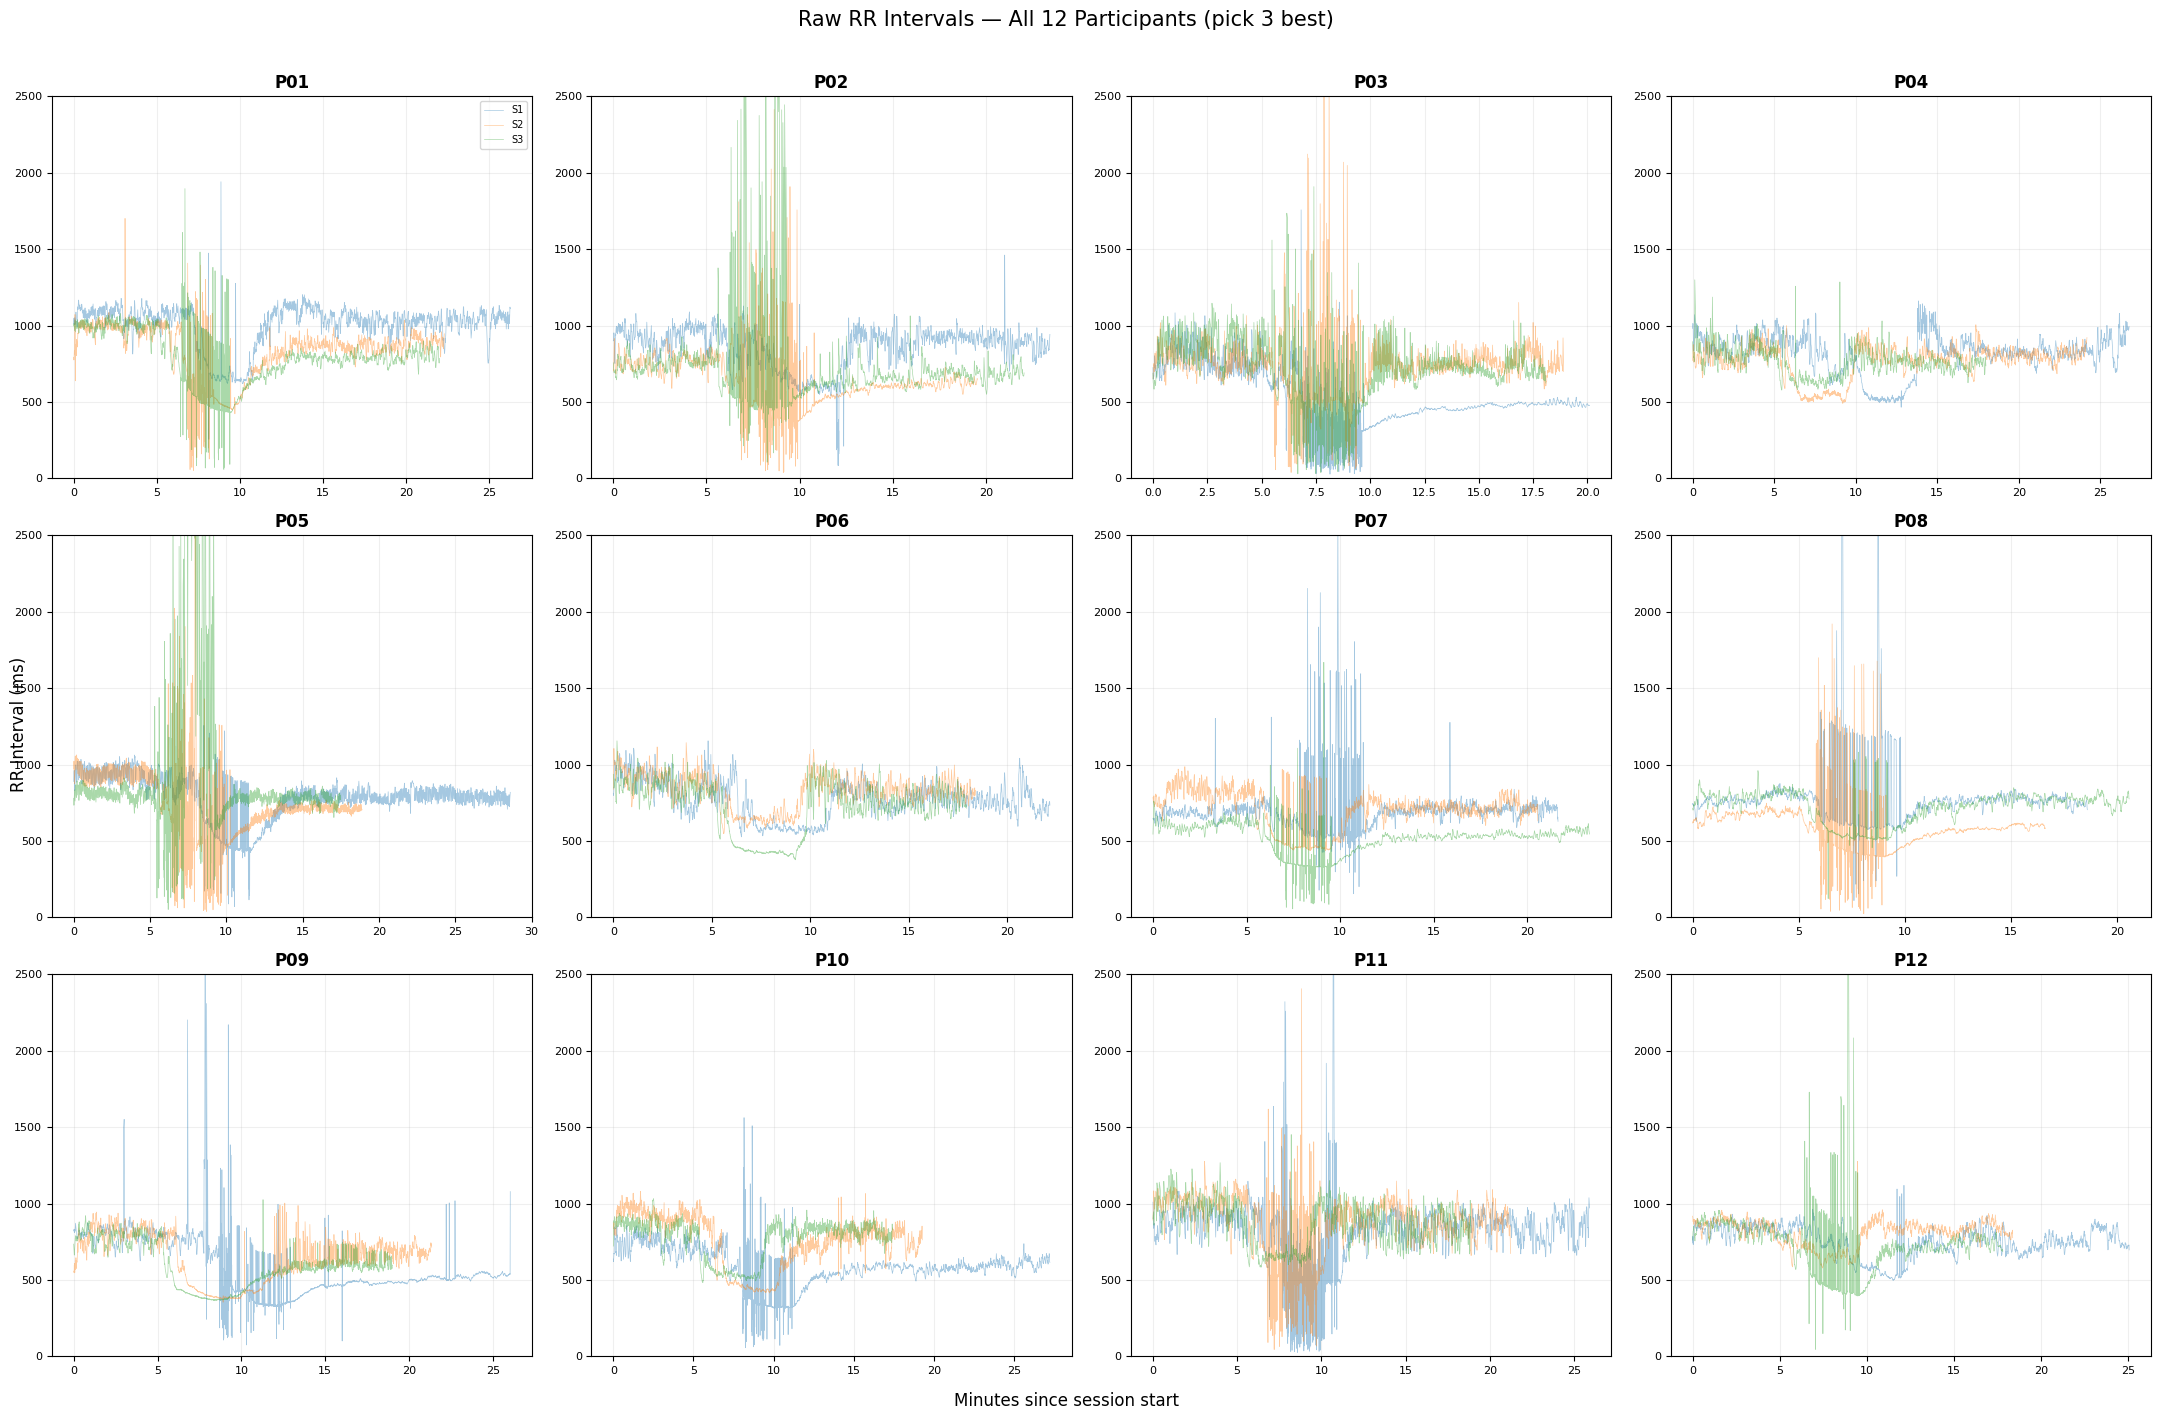

In [ ]:
"""
STEP 1: Raw RR Interval Overview — Pick 3 representative participants

Plot raw RR intervals for all 12 participants in a compact grid.
Look at the data quality, then decide which 3 to use for feature analysis.
"""

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CONFIG
DATA_ROOT = Path("fatigueset") # Update this to your actual data path, I put mine here
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]



# LOAD RAW RR INTERVALS
def load_rr_intervals(pid: int, sid: int) -> pd.DataFrame:
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    rr_file = session_dir / "chest_rr_interval.csv"

    if not rr_file.exists():
        return pd.DataFrame(columns=["timestamp", "rr_ms", "participant", "session"])

    df = pd.read_csv(rr_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df = df.rename(columns={"duration": "rr_ms"})
    df["participant"] = pid
    df["session"] = sid
    df = df.dropna(subset=["rr_ms"])

    return df[["timestamp", "rr_ms", "participant", "session"]].sort_values("timestamp").reset_index(drop=True)


def load_all_rr() -> pd.DataFrame:
    all_dfs = []
    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            df = load_rr_intervals(pid, sid)
            if not df.empty:
                # Add minutes from session start
                df["t_min"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds() / 60.0
                all_dfs.append(df)
                print(f"  P{pid:02d} S{sid}: {len(df)} beats loaded")
            else:
                print(f"  P{pid:02d} S{sid}: [SKIP]")

    return pd.concat(all_dfs, ignore_index=True) if all_dfs else pd.DataFrame()



# plot 4×3 grid of raw RR intervals

def plot_raw_rr_grid(df: pd.DataFrame):
    fig, axes = plt.subplots(3, 4, figsize=(22, 14))
    axes = axes.flatten()

    pids = sorted(df["participant"].unique())

    for i, pid in enumerate(pids):
        if i >= 12:
            break
        ax = axes[i]
        sub = df[df["participant"] == pid]

        for sid, s in sub.groupby("session", sort=True):
            s = s.sort_values("t_min")
            ax.plot(s["t_min"], s["rr_ms"], label=f"S{sid}", alpha=0.4, linewidth=0.5)

        ax.set_title(f"P{pid:02d}", fontsize=12, fontweight="bold")
        ax.set_ylim(0, 2500)  
        ax.grid(True, alpha=0.2)
        ax.tick_params(labelsize=8)

        if i == 0:
            ax.legend(fontsize=7)

    for j in range(len(pids), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle("Raw RR Intervals — All 12 Participants (pick 3 best)", fontsize=15, y=1.01)
    fig.supxlabel("Minutes since session start", fontsize=12)
    fig.supylabel("RR Interval (ms)", fontsize=12)
    plt.tight_layout()
    plt.show()



# basic stats per participant to help with selection
def print_participant_stats(df: pd.DataFrame):
    print("\n" + "=" * 75)
    print("RAW RR INTERVAL STATS PER PARTICIPANT")
    print("=" * 75)
    print(f"{'PID':>4} | {'Total Beats':>11} | {'Mean RR':>8} | {'Artifact%':>9} | {'Sessions':>8} | {'Duration':>10}")
    print("-" * 75)

    for pid in sorted(df["participant"].unique()):
        sub = df[df["participant"] == pid]

        total_beats = len(sub)
        mean_rr = sub["rr_ms"].mean()

        artifact_pct = ((sub["rr_ms"] < 300) | (sub["rr_ms"] > 2000)).mean() * 100

        n_sessions = sub["session"].nunique()

        # Total duration across all sessions
        total_duration = 0
        for sid in sub["session"].unique():
            sess = sub[sub["session"] == sid]
            dur = (sess["timestamp"].max() - sess["timestamp"].min()).total_seconds() / 60.0
            total_duration += dur

        print(f"P{pid:02d}  | {total_beats:>11} | {mean_rr:>7.1f}ms | {artifact_pct:>8.1f}% | {n_sessions:>8} | {total_duration:>8.1f} min")

    print("-" * 75)
    print("\nLook for participants with:")
    print("  - Low artifact % (cleaner data)")
    print("  - 3 sessions (complete data)")
    print("  - Clear exercise dip visible in the grid plot")
    print("  - Reasonable mean RR (600-1100ms = HR 55-100 bpm)")


# run main
if __name__ == "__main__":

    print("=" * 60)
    print("STEP 1: Raw RR Intervals — Visual Overview")
    print("=" * 60)

    df_all_rr = load_all_rr()

    if df_all_rr.empty:
        print("[ERROR] No data loaded.")
    else:
        print(f"\nTotal beats loaded: {len(df_all_rr)}")

        # Stats table
        print_participant_stats(df_all_rr)

        # Overview grid
        print("\nPlotting 4×3 grid...")
        plot_raw_rr_grid(df_all_rr)


## Feature extraction and detailed plots for 3 participants for hrv feature analysis

STEP 2: Feature Extraction for P01, P06, P12
Window: 180s, Step: 60s
Features: 11 time-domain + 11 frequency-domain = 22
  P01 S1: 24 windows
  P01 S2: 20 windows
  P01 S3: 20 windows
  P06 S1: 20 windows
  P06 S2: 16 windows
  P06 S3: 15 windows
  P12 S1: 23 windows
  P12 S2: 16 windows
  P12 S3: 15 windows

Saved to: hrv_features_P01_P06_P12.csv

FEATURE SUMMARY FOR SELECTED PARTICIPANTS

Total features: 22
Total windows: 169

Windows per participant:
participant
1     64
6     51
12    54

NaN counts per feature:
  No NaN values — all features computed successfully!

RR quality (% kept after cleaning):
  P01: mean=96.4%, min=60.3%
  P06: mean=100.0%, min=99.6%
  P12: mean=98.1%, min=75.2%

Feature statistics (across all selected participants):
       mean_rr    sdnn   rmssd   pnn50  mean_hr  min_hr  max_hr    sdhr  range_rr   cv_rr  triangular_index  vlf_power  lf_power  hf_power  total_power  lf_hf_ratio  lf_norm  hf_norm  ln_vlf   ln_lf   ln_hf  ln_total_power
count   169.00  169.

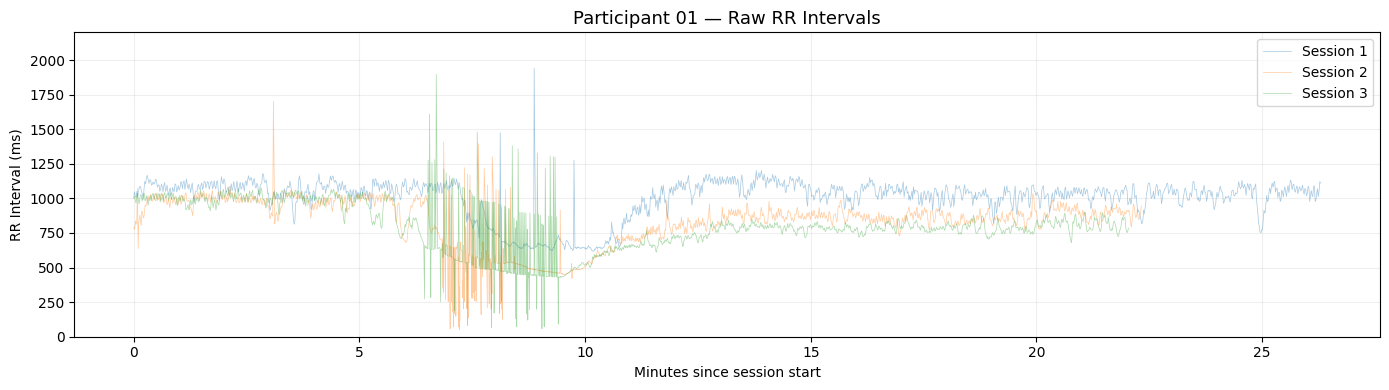

  Plotting time-domain features...


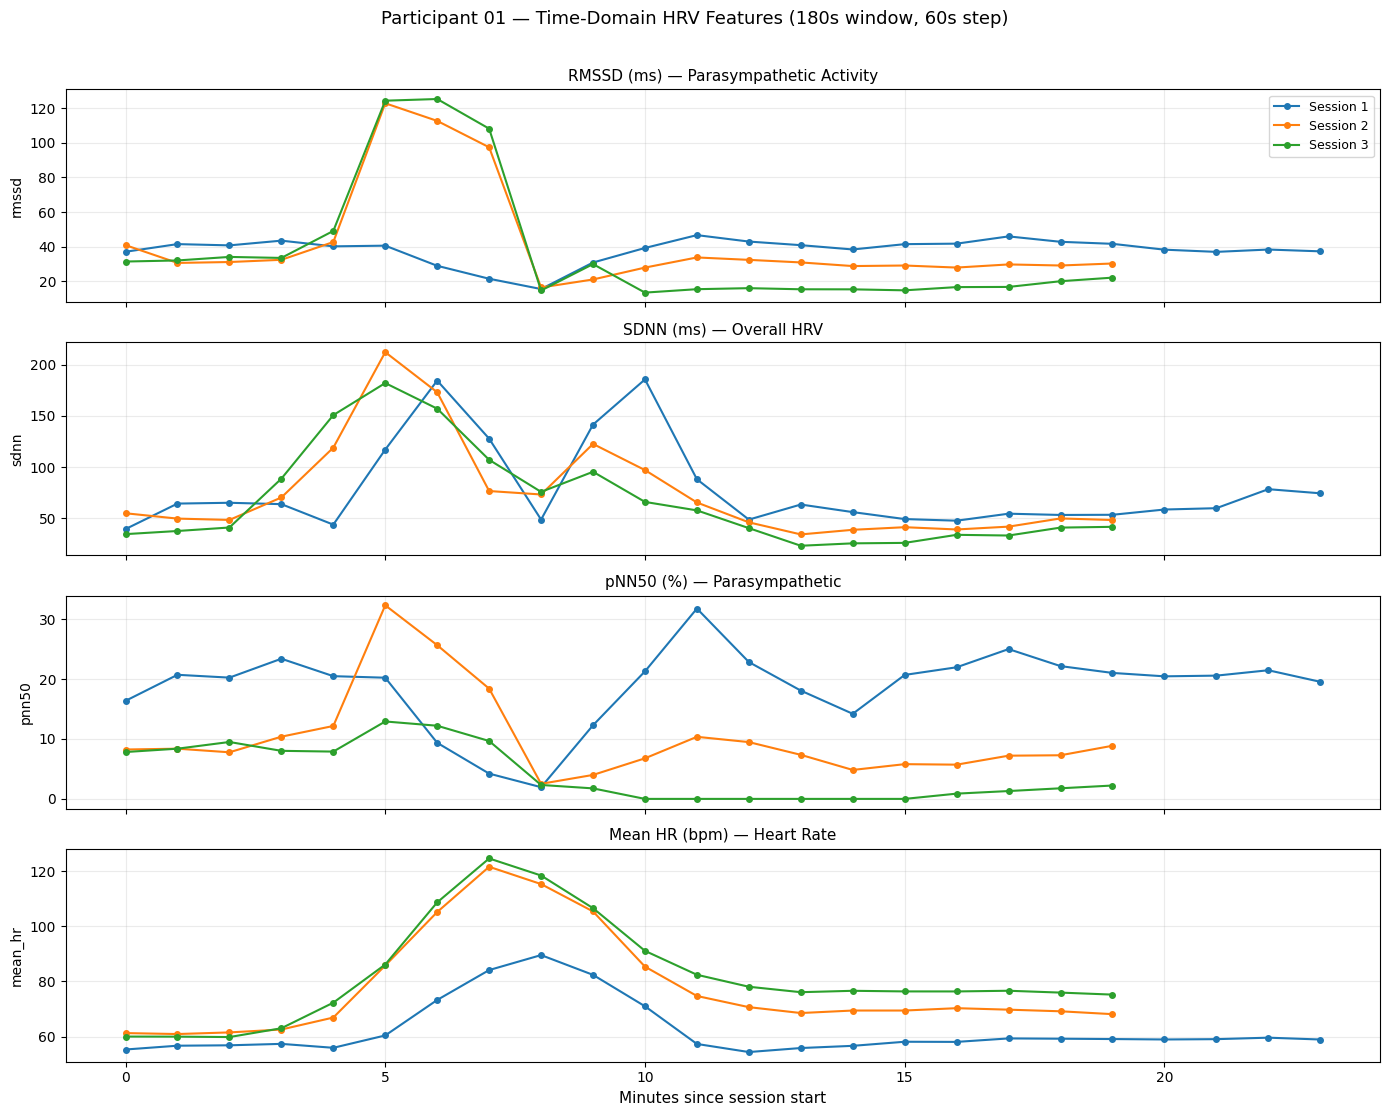

  Plotting frequency-domain features...


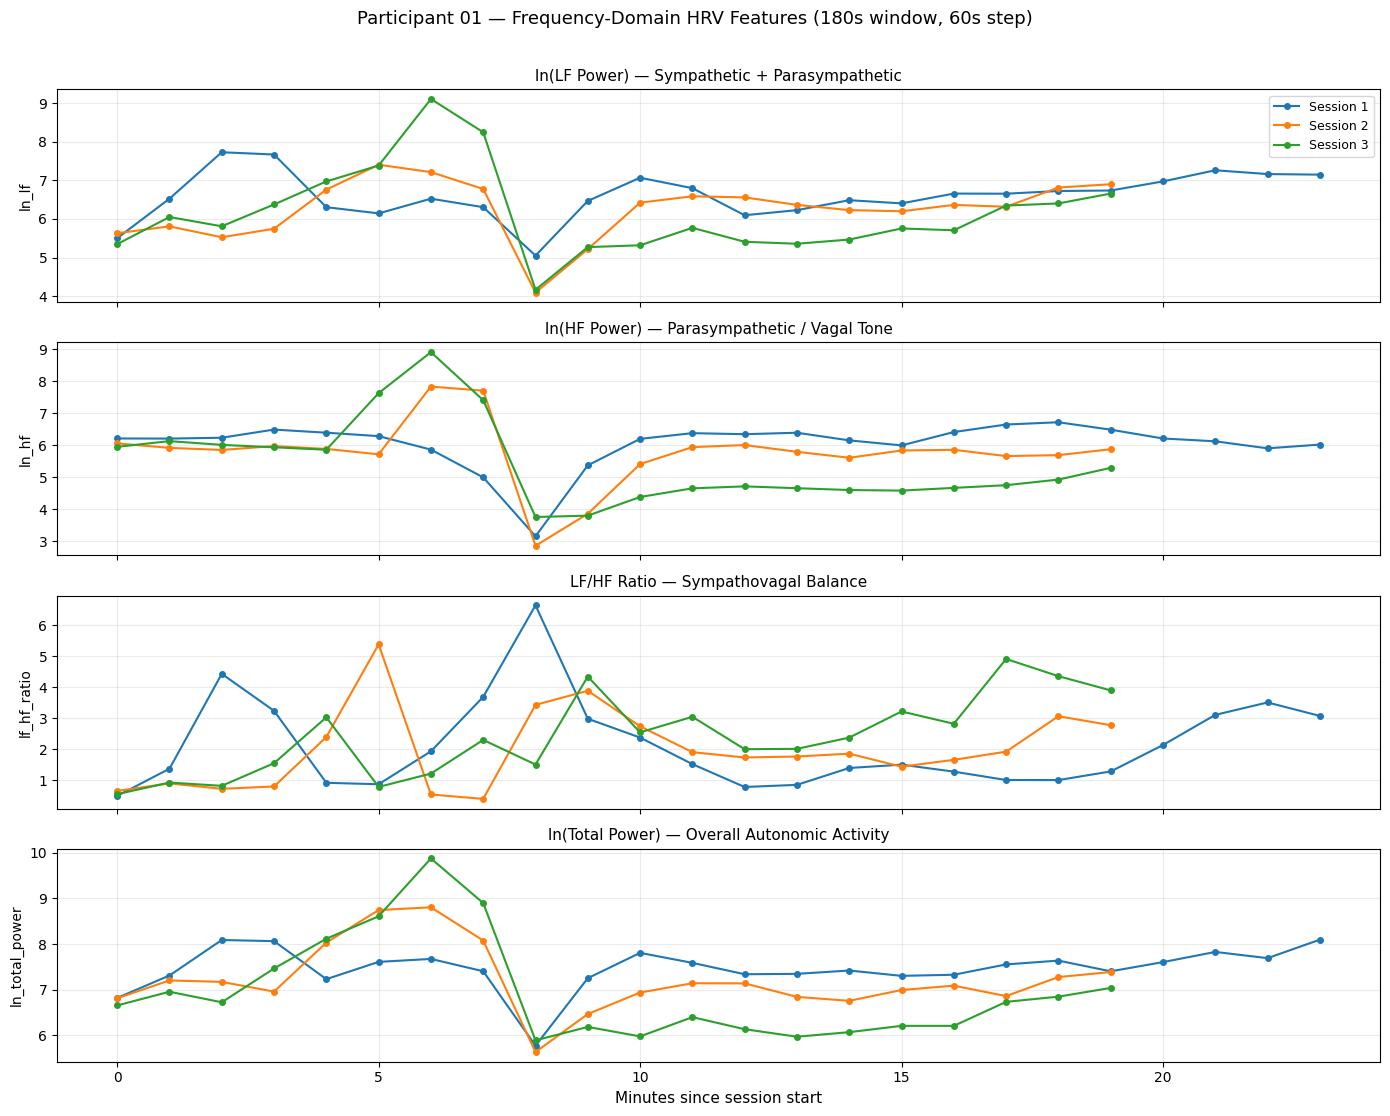


  Participant 06
  Plotting raw RR intervals...


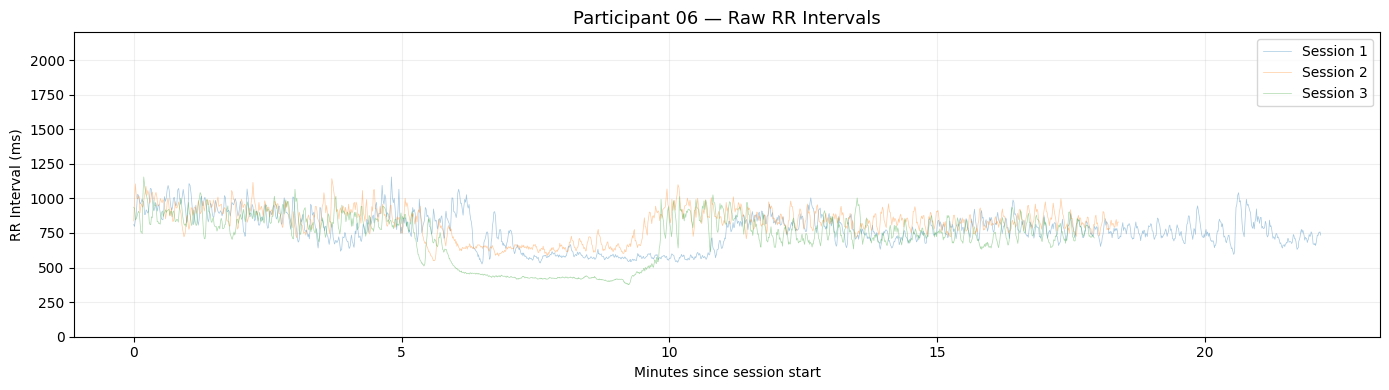

  Plotting time-domain features...


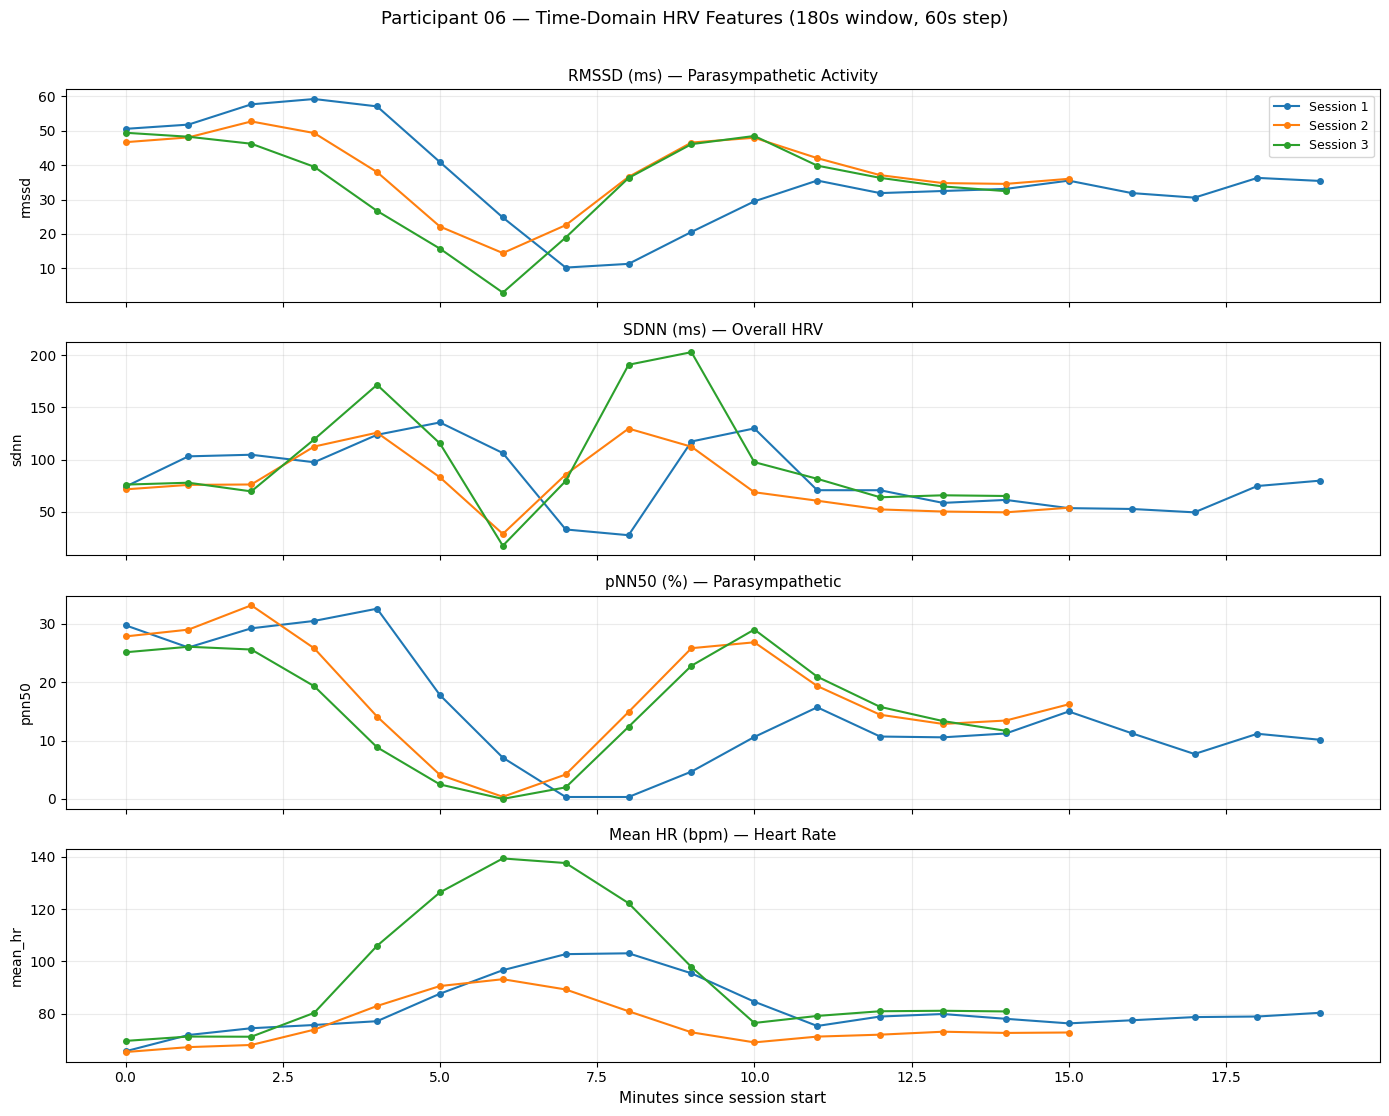

  Plotting frequency-domain features...


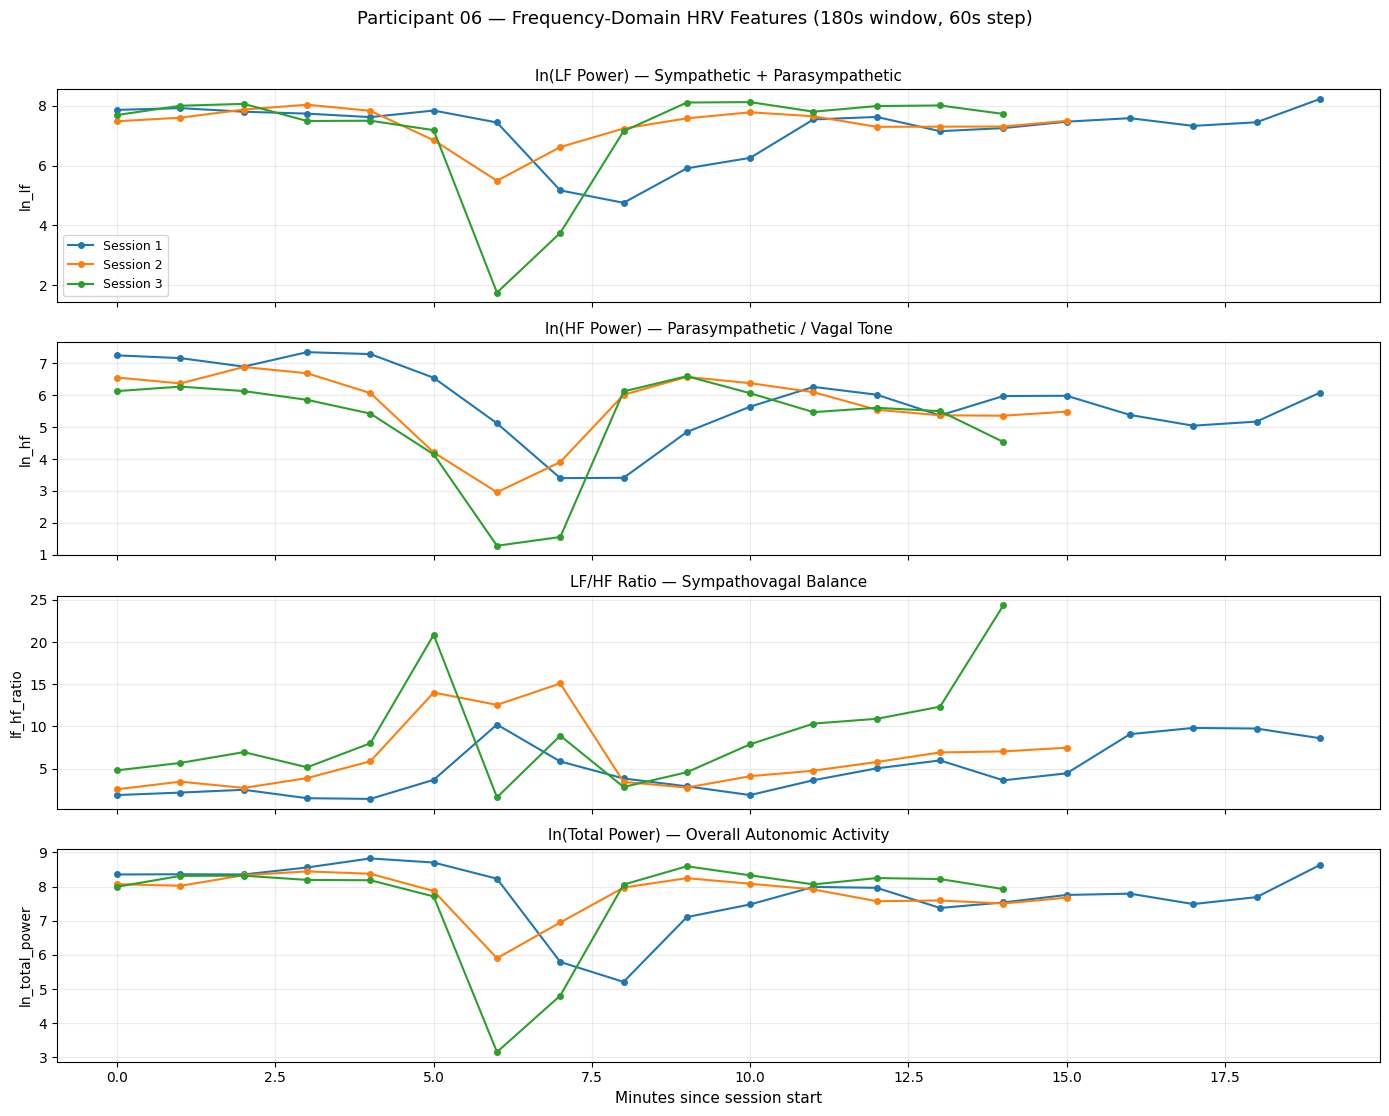


  Participant 12
  Plotting raw RR intervals...


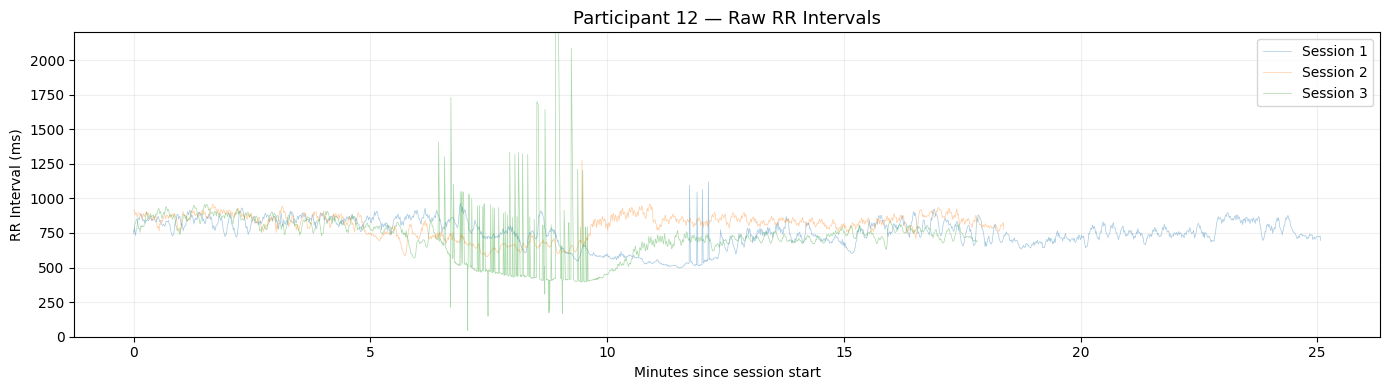

  Plotting time-domain features...


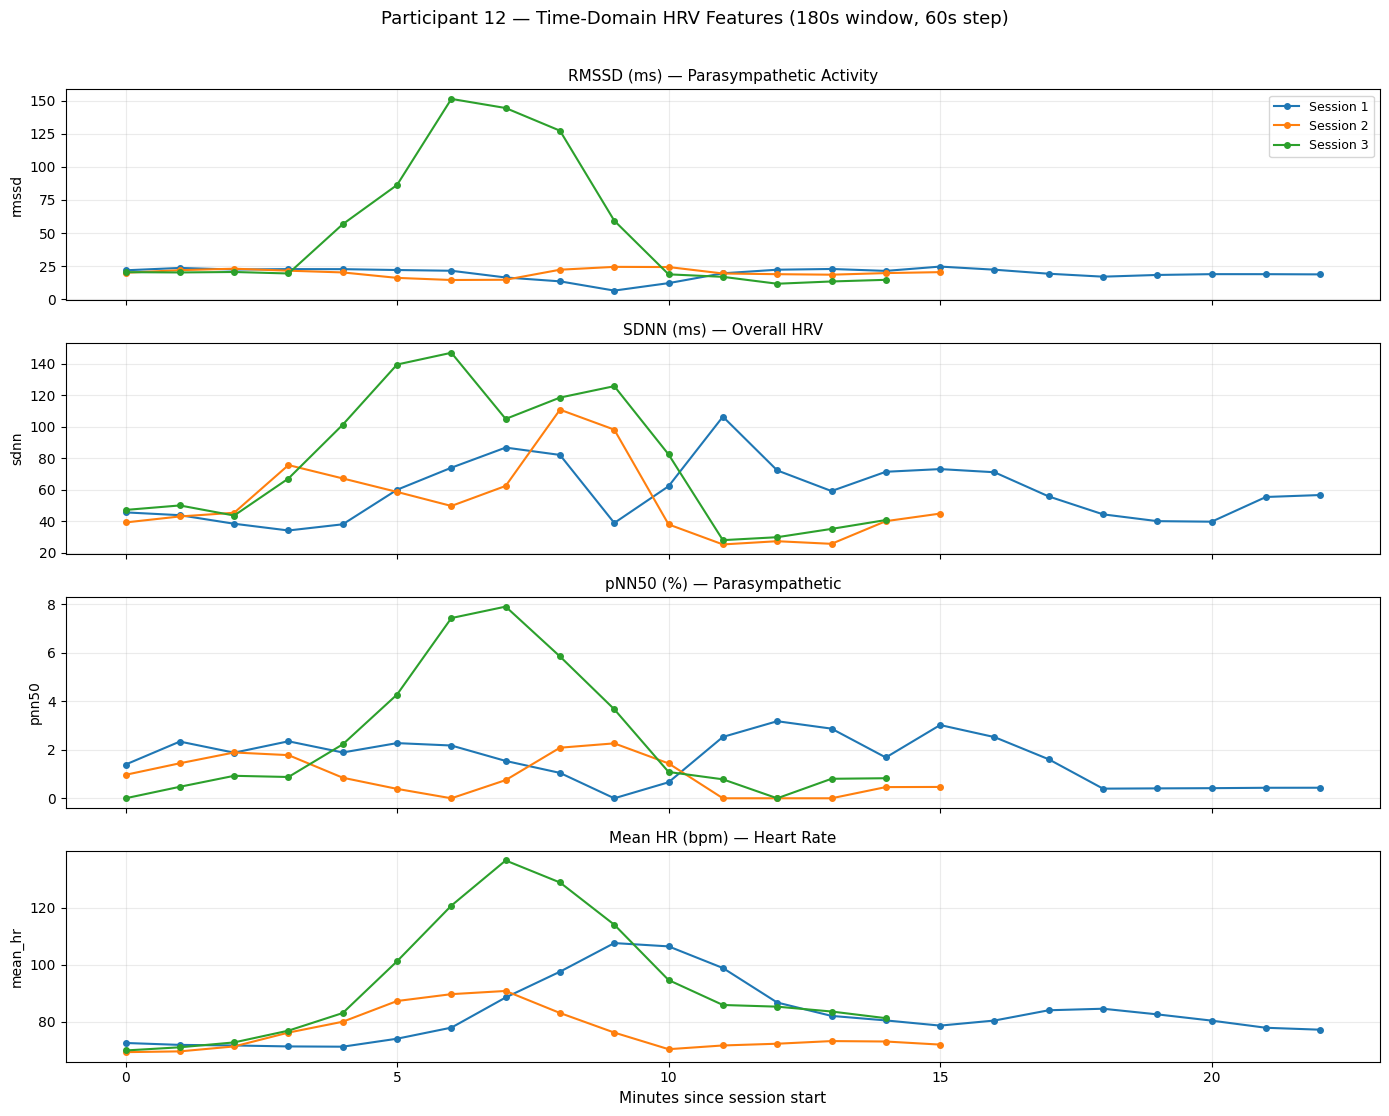

  Plotting frequency-domain features...


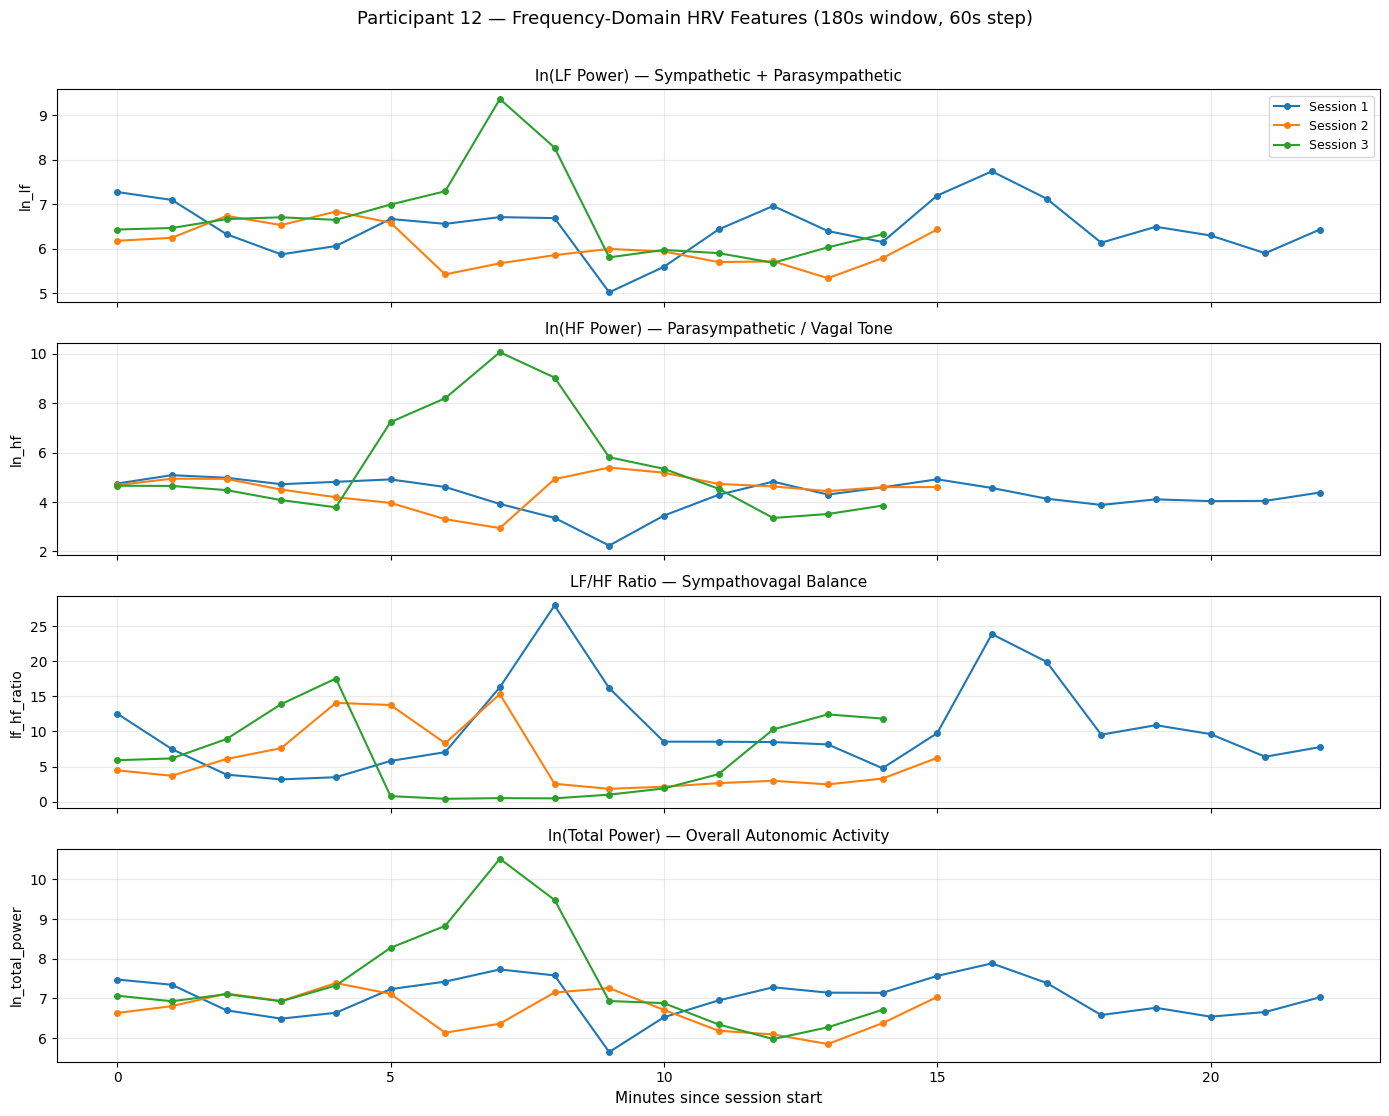

In [1]:
"""
STEP 2: HRV Feature Extraction + Detailed Plots for P01, P06, P12

22 features (11 time-domain + 11 frequency-domain) per window.
Detailed plots: 2 figures per participant (4 subplots each = 8 plots per person).
"""

from pathlib import Path
import pandas as pd
import numpy as np
from scipy.signal import welch
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")


# CONFIG

DATA_ROOT = Path("fatigueset")
SELECTED_PARTICIPANTS = [1, 6, 12]  # P01, P06, P12
SESSIONS = [1, 2, 3]

WINDOW_SEC = 180
STEP_SEC   = 60
MIN_RR_IN_WINDOW = 100

MAX_RR_MS = 2000
MIN_RR_MS = 300
MAX_RR_DIFF_MS = 300



# LOAD & CLEAN

def load_rr_intervals(pid: int, sid: int) -> pd.DataFrame:
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    rr_file = session_dir / "chest_rr_interval.csv"

    if not rr_file.exists():
        return pd.DataFrame(columns=["timestamp", "rr_ms", "participant", "session"])

    df = pd.read_csv(rr_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df = df.rename(columns={"duration": "rr_ms"})
    df["participant"] = pid
    df["session"] = sid
    df = df.dropna(subset=["rr_ms"])

    return df[["timestamp", "rr_ms", "participant", "session"]].sort_values("timestamp").reset_index(drop=True)


def clean_rr_intervals(rr: np.ndarray) -> np.ndarray:
    mask = (rr >= MIN_RR_MS) & (rr <= MAX_RR_MS)
    rr = rr[mask]
    if len(rr) < 3:
        return rr
    diffs = np.abs(np.diff(rr))
    keep = np.ones(len(rr), dtype=bool)
    for i in range(len(diffs)):
        if diffs[i] > MAX_RR_DIFF_MS:
            keep[i + 1] = False
    return rr[keep]



# TIME-DOMAIN FEATURES (11)

def compute_time_domain(rr: np.ndarray) -> dict:
    keys = [
        "mean_rr", "sdnn", "rmssd", "pnn50",
        "mean_hr", "min_hr", "max_hr", "sdhr",
        "range_rr", "cv_rr", "triangular_index"
    ]
    if len(rr) < 2:
        return {k: np.nan for k in keys}

    diffs = np.diff(rr)
    mean_rr  = np.mean(rr)
    sdnn     = np.std(rr, ddof=1)
    rmssd    = np.sqrt(np.mean(diffs ** 2))
    pnn50    = (np.sum(np.abs(diffs) > 50) / len(diffs)) * 100.0

    hr_array = 60000.0 / rr
    mean_hr  = np.mean(hr_array)
    min_hr   = np.min(hr_array)
    max_hr   = np.max(hr_array)
    sdhr     = np.std(hr_array, ddof=1)

    range_rr = np.max(rr) - np.min(rr)
    cv_rr    = sdnn / mean_rr if mean_rr > 0 else np.nan

    bin_width = 1000.0 / 128.0
    if range_rr > 0:
        n_bins = max(int(range_rr / bin_width), 1)
        hist_counts, _ = np.histogram(rr, bins=n_bins)
        max_bin_count = np.max(hist_counts)
        triangular_index = len(rr) / max_bin_count if max_bin_count > 0 else np.nan
    else:
        triangular_index = np.nan

    return {
        "mean_rr": mean_rr, "sdnn": sdnn, "rmssd": rmssd, "pnn50": pnn50,
        "mean_hr": mean_hr, "min_hr": min_hr, "max_hr": max_hr, "sdhr": sdhr,
        "range_rr": range_rr, "cv_rr": cv_rr, "triangular_index": triangular_index,
    }



# FREQUENCY-DOMAIN FEATURES (11)

def compute_frequency_domain(rr: np.ndarray) -> dict:
    keys = [
        "vlf_power", "lf_power", "hf_power",
        "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]
    if len(rr) < 30:
        return {k: np.nan for k in keys}

    t_seconds = np.cumsum(rr) / 1000.0
    t_seconds = t_seconds - t_seconds[0]

    fs_resample = 4.0
    t_uniform = np.arange(t_seconds[0], t_seconds[-1], 1.0 / fs_resample)

    if len(t_uniform) < 64:
        return {k: np.nan for k in keys}

    try:
        interp_fn = interp1d(t_seconds, rr, kind="cubic", fill_value="extrapolate")
        rr_uniform = interp_fn(t_uniform)
    except Exception:
        return {k: np.nan for k in keys}

    rr_uniform = rr_uniform - np.mean(rr_uniform)
    nperseg = min(len(rr_uniform), 256)
    freqs, psd = welch(rr_uniform, fs=fs_resample, nperseg=nperseg, noverlap=nperseg // 2)

    vlf_mask = (freqs >= 0.003) & (freqs < 0.04)
    lf_mask  = (freqs >= 0.04)  & (freqs < 0.15)
    hf_mask  = (freqs >= 0.15)  & (freqs < 0.40)

    vlf = float(np.trapz(psd[vlf_mask], freqs[vlf_mask])) if vlf_mask.any() else np.nan
    lf  = float(np.trapz(psd[lf_mask],  freqs[lf_mask]))  if lf_mask.any() else np.nan
    hf  = float(np.trapz(psd[hf_mask],  freqs[hf_mask]))  if hf_mask.any() else np.nan

    total   = vlf + lf + hf
    lf_hf   = lf / hf if (hf and hf > 0) else np.nan
    lf_norm = (lf / (lf + hf)) * 100 if (lf + hf) > 0 else np.nan
    hf_norm = (hf / (lf + hf)) * 100 if (lf + hf) > 0 else np.nan

    def safe_ln(x):
        return np.log(x) if (x is not None and x > 0) else np.nan

    return {
        "vlf_power": vlf, "lf_power": lf, "hf_power": hf,
        "total_power": total, "lf_hf_ratio": lf_hf, "lf_norm": lf_norm, "hf_norm": hf_norm,
        "ln_vlf": safe_ln(vlf), "ln_lf": safe_ln(lf), "ln_hf": safe_ln(hf),
        "ln_total_power": safe_ln(total),
    }



# EXTRACT ALL FEATURES FOR ONE WINDOW

def extract_features_one_window(rr_raw: np.ndarray) -> dict:
    rr_clean = clean_rr_intervals(rr_raw)
    quality = {
        "n_rr_raw": len(rr_raw),
        "n_rr_clean": len(rr_clean),
        "pct_rr_kept": (len(rr_clean) / len(rr_raw) * 100) if len(rr_raw) > 0 else 0,
    }
    if len(rr_clean) < MIN_RR_IN_WINDOW:
        td = compute_time_domain(np.array([]))
        fd = compute_frequency_domain(np.array([]))
        return {**quality, **td, **fd}

    td = compute_time_domain(rr_clean)
    fd = compute_frequency_domain(rr_clean)
    return {**quality, **td, **fd}



# BUILD DATASET (selected participants only)

def build_hrv_feature_dataset() -> pd.DataFrame:
    all_rows = []
    for pid in SELECTED_PARTICIPANTS:
        for sid in SESSIONS:
            df_rr = load_rr_intervals(pid, sid)
            if df_rr.empty:
                print(f"  [SKIP] P{pid:02d} S{sid}: no RR data")
                continue

            t_start = df_rr["timestamp"].iloc[0]
            t_end   = df_rr["timestamp"].iloc[-1]
            win_id = 0
            w_start = t_start

            while w_start + pd.Timedelta(seconds=WINDOW_SEC) <= t_end:
                w_end = w_start + pd.Timedelta(seconds=WINDOW_SEC)
                mask = (df_rr["timestamp"] >= w_start) & (df_rr["timestamp"] < w_end)
                rr_in_window = df_rr.loc[mask, "rr_ms"].to_numpy(dtype=float)

                feats = extract_features_one_window(rr_in_window)
                feats["participant"] = pid
                feats["session"]     = sid
                feats["window_id"]   = win_id
                feats["window_start"] = w_start
                feats["window_end"]   = w_end

                all_rows.append(feats)
                win_id += 1
                w_start += pd.Timedelta(seconds=STEP_SEC)

            print(f"  P{pid:02d} S{sid}: {win_id} windows")

    df_feat = pd.DataFrame(all_rows)
    if not df_feat.empty:
        df_feat["t_min"] = df_feat.groupby(["participant", "session"])["window_start"].transform(
            lambda s: (s - s.min()).dt.total_seconds() / 60.0
        )
    return df_feat



# PLOT Raw RR + Features side by side

def plot_participant_raw_rr(pid: int):
    plt.figure(figsize=(14, 4))

    for sid in SESSIONS:
        df_rr = load_rr_intervals(pid, sid)
        if df_rr.empty:
            continue
        t_min = (df_rr["timestamp"] - df_rr["timestamp"].iloc[0]).dt.total_seconds() / 60.0
        plt.plot(t_min, df_rr["rr_ms"], label=f"Session {sid}", alpha=0.4, linewidth=0.5)

    plt.title(f"Participant {pid:02d} — Raw RR Intervals", fontsize=13)
    plt.xlabel("Minutes since session start")
    plt.ylabel("RR Interval (ms)")
    plt.ylim(0, 2200)
    plt.legend()
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()


def plot_participant_td_features(pid: int, df: pd.DataFrame):
    sub = df[df["participant"] == pid].copy()

    metrics = [
        ("rmssd",   "RMSSD (ms) — Parasympathetic Activity"),
        ("sdnn",    "SDNN (ms) — Overall HRV"),
        ("pnn50",   "pNN50 (%) — Parasympathetic"),
        ("mean_hr", "Mean HR (bpm) — Heart Rate"),
    ]

    fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

    for ax, (col, title) in zip(axes, metrics):
        for sid, s in sub.groupby("session", sort=True):
            s = s.sort_values("t_min")
            ax.plot(s["t_min"], s[col], marker="o", markersize=4, linewidth=1.5, label=f"Session {sid}")
        ax.set_title(title, fontsize=11)
        ax.set_ylabel(col, fontsize=10)
        ax.grid(True, alpha=0.25)

    axes[0].legend(fontsize=9)
    axes[-1].set_xlabel("Minutes since session start", fontsize=11)
    fig.suptitle(f"Participant {pid:02d} — Time-Domain HRV Features ({WINDOW_SEC}s window, {STEP_SEC}s step)",
                 fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()


def plot_participant_fd_features(pid: int, df: pd.DataFrame):
    sub = df[df["participant"] == pid].copy()

    metrics = [
        ("ln_lf",          "ln(LF Power) — Sympathetic + Parasympathetic"),
        ("ln_hf",          "ln(HF Power) — Parasympathetic / Vagal Tone"),
        ("lf_hf_ratio",    "LF/HF Ratio — Sympathovagal Balance"),
        ("ln_total_power", "ln(Total Power) — Overall Autonomic Activity"),
    ]

    fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

    for ax, (col, title) in zip(axes, metrics):
        for sid, s in sub.groupby("session", sort=True):
            s = s.sort_values("t_min")
            ax.plot(s["t_min"], s[col], marker="o", markersize=4, linewidth=1.5, label=f"Session {sid}")
        ax.set_title(title, fontsize=11)
        ax.set_ylabel(col, fontsize=10)
        ax.grid(True, alpha=0.25)

    axes[0].legend(fontsize=9)
    axes[-1].set_xlabel("Minutes since session start", fontsize=11)
    fig.suptitle(f"Participant {pid:02d} — Frequency-Domain HRV Features ({WINDOW_SEC}s window, {STEP_SEC}s step)",
                 fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()


def plot_all_selected(df: pd.DataFrame):
    for pid in SELECTED_PARTICIPANTS:
        print(f"\n{'='*50}")
        print(f"  Participant {pid:02d}")
        print(f"{'='*50}")

        print(f"  Plotting raw RR intervals...")
        plot_participant_raw_rr(pid)

        print(f"  Plotting time-domain features...")
        plot_participant_td_features(pid, df)

        print(f"  Plotting frequency-domain features...")
        plot_participant_fd_features(pid, df)



# PRINT FEATURE SUMMARY

def print_feature_summary(df: pd.DataFrame):
    print("\n" + "=" * 60)
    print("FEATURE SUMMARY FOR SELECTED PARTICIPANTS")
    print("=" * 60)

    feature_cols = [
        "mean_rr", "sdnn", "rmssd", "pnn50", "mean_hr", "min_hr", "max_hr",
        "sdhr", "range_rr", "cv_rr", "triangular_index",
        "vlf_power", "lf_power", "hf_power", "total_power",
        "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]

    print(f"\nTotal features: {len(feature_cols)}")
    print(f"Total windows: {len(df)}")
    print(f"\nWindows per participant:")
    print(df.groupby("participant").size().to_string())

    print(f"\nNaN counts per feature:")
    nan_counts = df[feature_cols].isna().sum()
    if nan_counts.sum() == 0:
        print("  No NaN values — all features computed successfully!")
    else:
        print(nan_counts[nan_counts > 0].to_string())

    print(f"\nRR quality (% kept after cleaning):")
    for pid in SELECTED_PARTICIPANTS:
        sub = df[df["participant"] == pid]
        print(f"  P{pid:02d}: mean={sub['pct_rr_kept'].mean():.1f}%, min={sub['pct_rr_kept'].min():.1f}%")

    print(f"\nFeature statistics (across all selected participants):")
    print(df[feature_cols].describe().round(2).to_string())


# RUN

if __name__ == "__main__":

    print("=" * 60)
    print("STEP 2: Feature Extraction for P01, P06, P12")
    print(f"Window: {WINDOW_SEC}s, Step: {STEP_SEC}s")
    print(f"Features: 11 time-domain + 11 frequency-domain = 22")
    print("=" * 60)

    # Extract features
    df_features = build_hrv_feature_dataset()

    if df_features.empty:
        print("[ERROR] No data extracted.")
    else:
        # Save
        out_path = Path("hrv_features_P01_P06_P12.csv")
        df_features.to_csv(out_path, index=False)
        print(f"\nSaved to: {out_path}")

        # Summary
        print_feature_summary(df_features)

        # Plot: raw RR + features for each participant
        print("\n--- Plotting ---")
        plot_all_selected(df_features)

In [14]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("fatigueset")

# Check exp_fatigue.csv
print("=== exp_fatigue.csv (YOUR FATIGUE LABELS) ===")
df = pd.read_csv(DATA_ROOT / "01" / "01" / "exp_fatigue.csv")
print(df.to_string())

print("\n=== exp_markers.csv (PHASE TIMESTAMPS) ===")
df = pd.read_csv(DATA_ROOT / "01" / "01" / "exp_markers.csv")
print(df.to_string())

print("\n=== exp_crt.csv (CRT task performance) ===")
df = pd.read_csv(DATA_ROOT / "01" / "01" / "exp_crt.csv")
print(df.head(10).to_string())

print("\n=== exp_nback.csv (N-back performance) ===")
df = pd.read_csv(DATA_ROOT / "01" / "01" / "exp_nback.csv")
print(df.head(10).to_string())

=== exp_fatigue.csv (YOUR FATIGUE LABELS) ===
   measurementNumber  physicalFatigueAnswerTime  mentalFatigueAnswerTime  fatigueSurveySubmissionTime  physicalFatigueScore  mentalFatigueScore
0                  0                 226.380555               234.136118                   238.965037             14.444444           14.166667
1                  1                 686.570569               690.081112                   694.569383             24.027778           11.250000
2                  2                1462.908608              1464.458902                  1467.546922             20.000000           45.833333

=== exp_markers.csv (PHASE TIMESTAMPS) ===
         utcTime       eventMarker
0   1.629370e+12  start_experiment
1   1.629370e+12    start_baseline
2   1.629371e+12      end_baseline
3   1.629371e+12     submit_survey
4   1.629371e+12         start_crt
5   1.629371e+12       start_nback
6   1.629371e+12    start_activity
7   1.629371e+12      end_activity
8   1.629371e+12   

## Statistical tests for HRV features

Loading features from: hrv_22_features_windowed.csv
Loaded 675 windows for 12 participants
STEP 2: CONFIRM MENTAL FATIGUE INCREASES FROM M1 TO M3

Mental Fatigue VAS Scores (0-100):
--------------------------------------------------
                     mean   std  median  min   max
M1 (baseline)        18.4  15.5    16.4  0.0  67.8
M2 (post-exercise)   24.5  17.6    23.4  0.1  62.5
M3 (post-cognitive)  36.4  21.9    33.0  0.0  77.2

Wilcoxon signed-rank test (M1 vs M3):
  M1 mean: 18.4,  M3 mean: 36.4
  p-value: 0.0000
  Significant (p < 0.05): YES

Wilcoxon signed-rank test (M1 vs M2):
  M1 mean: 18.4,  M2 mean: 24.5
  p-value: 0.0019
  Significant (p < 0.05): YES


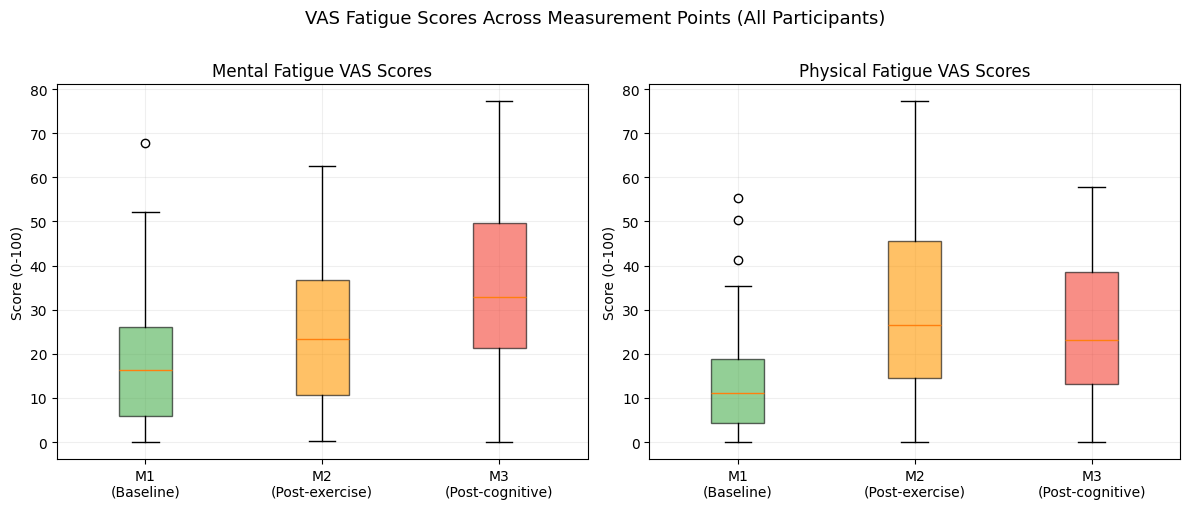


STEP 3: LABELLING WINDOWS USING exp_markers.csv

Window labels:
phase
transition    212
recovery      168
baseline      167
fatigued      127
exercise        1

STEP 4: STATISTICAL TESTS — BASELINE vs FATIGUED WINDOWS

Baseline windows: 167
Fatigued windows: 127

Feature                Baseline   Fatigued Direction          p-value Sig?         Effect
-----------------------------------------------------------------------------------------------
mean_rr                  829.92     754.35 ↓ decreased            0.0 YES ***       0.339
sdnn                       68.0      45.01 ↓ decreased            0.0 YES ***        0.49
rmssd                      41.1       29.4 ↓ decreased            0.0 YES ***       0.323
pnn50                     17.86      10.57 ↓ decreased            0.0 YES ***       0.312
mean_hr                   74.11      82.46 ↑ increased            0.0 YES ***       0.319
min_hr                    60.41      71.17 ↑ increased            0.0 YES ***       0.452
max_hr   

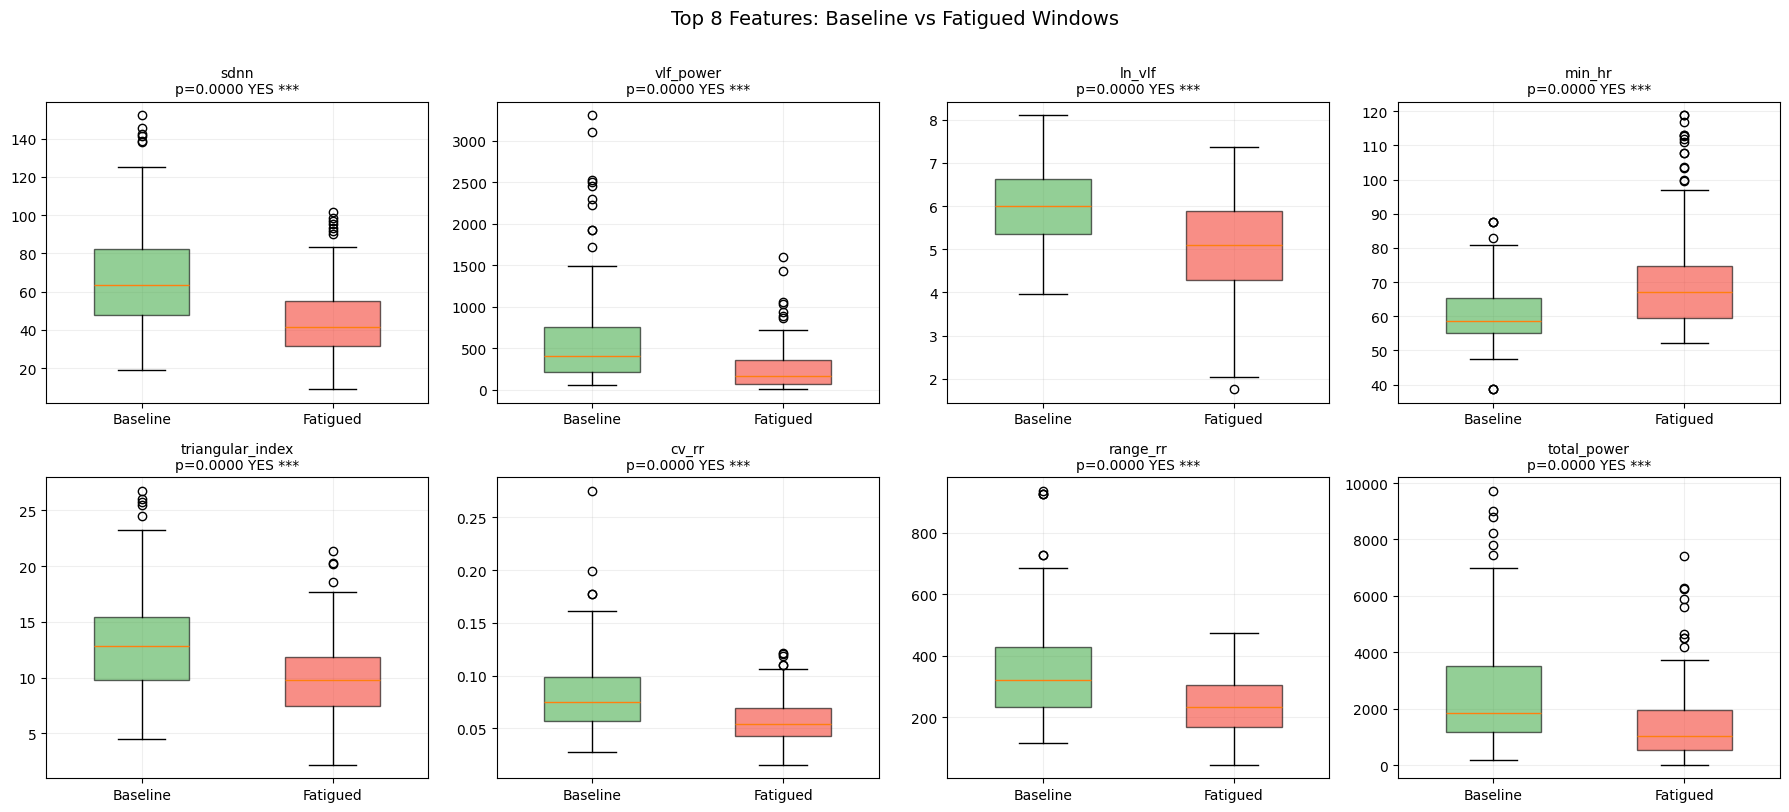

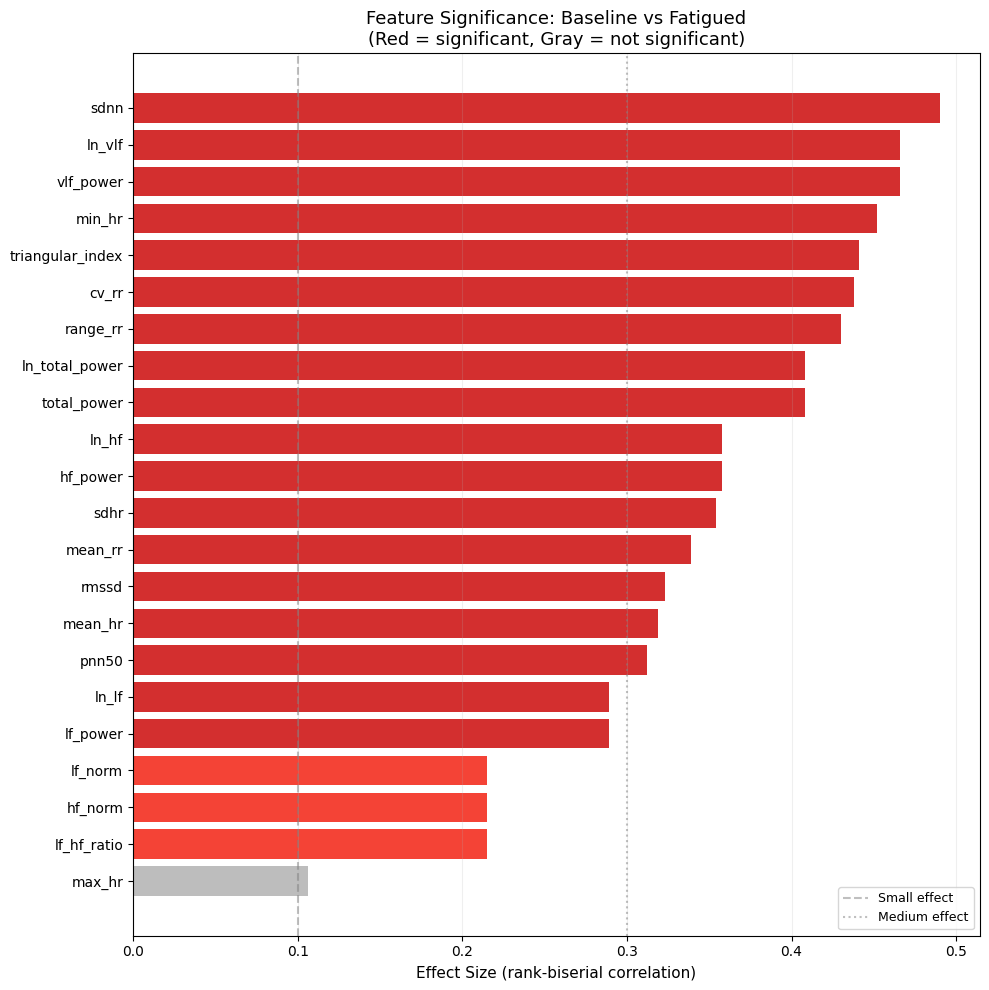


Saved labelled features to: hrv_features_labelled.csv


In [ ]:
"""
STATISTICAL TESTING OF HRV FEATURES

Step 1: Load exp_markers.csv to label each window with its phase
Step 2: Load exp_fatigue.csv to confirm fatigue increased from M1 to M3
Step 3: Run Mann-Whitney U tests comparing baseline vs fatigued windows
Step 4: Report results in a table
"""

from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# CONFIG

DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]

# Feature CSV from previous step (change path if needed), This should be the CSV with ALL 12 participants, not just P01/P06/P12
FEATURE_CSV = Path("hrv_22_features_windowed.csv")



# STEP 1: Load phase timestamps from exp_markers.csv

"""
Load exp_markers.csv and extract key phase timestamps.
Returns dict with phase start/end times as datetime.
"""
def load_markers(pid: int, sid: int) -> dict:
    
    marker_file = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"

    if not marker_file.exists():
        return {}

    df = pd.read_csv(marker_file)

    # Build a lookup from event name to timestamp
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)

    return events

"""
Load exp_fatigue.csv — VAS fatigue scores at M1, M2, M3.
"""
def load_fatigue_scores(pid: int, sid: int) -> pd.DataFrame:
    
    fatigue_file = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_fatigue.csv"

    if not fatigue_file.exists():
        return pd.DataFrame()

    df = pd.read_csv(fatigue_file)
    df["participant"] = pid
    df["session"] = sid
    return df



# STEP 2: Confirm fatigue actually increased from M1 to M3

"""
Load all VAS scores and show that mental fatigue increases from M1 to M3.
"""
def analyse_fatigue_scores():
    
    print("=" * 70)
    print("STEP 2: CONFIRM MENTAL FATIGUE INCREASES FROM M1 TO M3")
    print("=" * 70)

    all_scores = []
    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            df = load_fatigue_scores(pid, sid)
            if df.empty:
                continue
            for _, row in df.iterrows():
                all_scores.append({
                    "participant": pid,
                    "session": sid,
                    "measurement": int(row["measurementNumber"]),
                    "physical_fatigue": row["physicalFatigueScore"],
                    "mental_fatigue": row["mentalFatigueScore"],
                })

    scores_df = pd.DataFrame(all_scores)

    # Map measurement numbers to labels
    measurement_labels = {0: "M1 (baseline)", 1: "M2 (post-exercise)", 2: "M3 (post-cognitive)"}
    scores_df["phase"] = scores_df["measurement"].map(measurement_labels)

    # Summary stats
    print("\nMental Fatigue VAS Scores (0-100):")
    print("-" * 50)
    summary = scores_df.groupby("measurement")["mental_fatigue"].agg(["mean", "std", "median", "min", "max"])
    summary.index = [measurement_labels[i] for i in summary.index]
    print(summary.round(1).to_string())

    # Statistical test: M1 vs M3
    m1_scores = scores_df[scores_df["measurement"] == 0]["mental_fatigue"].values
    m3_scores = scores_df[scores_df["measurement"] == 2]["mental_fatigue"].values

    stat, p_value = stats.wilcoxon(m1_scores, m3_scores)
    print(f"\nWilcoxon signed-rank test (M1 vs M3):")
    print(f"  M1 mean: {m1_scores.mean():.1f},  M3 mean: {m3_scores.mean():.1f}")
    print(f"  p-value: {p_value:.4f}")
    print(f"  Significant (p < 0.05): {'YES' if p_value < 0.05 else 'NO'}")

    # Also test M1 vs M2
    m2_scores = scores_df[scores_df["measurement"] == 1]["mental_fatigue"].values
    stat2, p_value2 = stats.wilcoxon(m1_scores, m2_scores)
    print(f"\nWilcoxon signed-rank test (M1 vs M2):")
    print(f"  M1 mean: {m1_scores.mean():.1f},  M2 mean: {m2_scores.mean():.1f}")
    print(f"  p-value: {p_value2:.4f}")
    print(f"  Significant (p < 0.05): {'YES' if p_value2 < 0.05 else 'NO'}")

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Mental fatigue box plot
    mental_data = [
        scores_df[scores_df["measurement"] == 0]["mental_fatigue"].values,
        scores_df[scores_df["measurement"] == 1]["mental_fatigue"].values,
        scores_df[scores_df["measurement"] == 2]["mental_fatigue"].values,
    ]
    bp1 = axes[0].boxplot(mental_data, labels=["M1\n(Baseline)", "M2\n(Post-exercise)", "M3\n(Post-cognitive)"],
                           patch_artist=True)
    colors = ["#4CAF50", "#FF9800", "#F44336"]
    for patch, color in zip(bp1["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    axes[0].set_title("Mental Fatigue VAS Scores", fontsize=12)
    axes[0].set_ylabel("Score (0-100)")
    axes[0].grid(True, alpha=0.2)

    # Physical fatigue box plot
    physical_data = [
        scores_df[scores_df["measurement"] == 0]["physical_fatigue"].values,
        scores_df[scores_df["measurement"] == 1]["physical_fatigue"].values,
        scores_df[scores_df["measurement"] == 2]["physical_fatigue"].values,
    ]
    bp2 = axes[1].boxplot(physical_data, labels=["M1\n(Baseline)", "M2\n(Post-exercise)", "M3\n(Post-cognitive)"],
                           patch_artist=True)
    for patch, color in zip(bp2["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    axes[1].set_title("Physical Fatigue VAS Scores", fontsize=12)
    axes[1].set_ylabel("Score (0-100)")
    axes[1].grid(True, alpha=0.2)

    fig.suptitle("VAS Fatigue Scores Across Measurement Points (All Participants)", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

    return scores_df



# STEP 3: Label each window as "baseline" or "fatigued"

"""
For each window, determine its phase using exp_markers.csv timestamps.

Labels:
      "baseline"  = window falls entirely within the baseline phase (S1)
      "fatigued"  = window falls entirely within the cognitive task phase (S3)
      "exercise"  = window falls within the exercise phase (S2)
      "transition" = window straddles a phase boundary
      "unknown"   = cannot determine
"""
def label_windows(df_features: pd.DataFrame) -> pd.DataFrame:
    
    print("\n" + "=" * 70)
    print("STEP 3: LABELLING WINDOWS USING exp_markers.csv")
    print("=" * 70)

    labels = []

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            markers = load_markers(pid, sid)
            if not markers:
                print(f"  [SKIP] P{pid:02d} S{sid}: no markers file")
                continue

            # Extract key timestamps
            baseline_start = markers.get("start_baseline")
            baseline_end   = markers.get("end_baseline")
            exercise_start = markers.get("start_activity")
            exercise_end   = markers.get("end_activity")
            cognitive_start = markers.get("start_fatigue")
            cognitive_end   = markers.get("end_fatigue")

            if not all([baseline_start, baseline_end, exercise_start, exercise_end]):
                print(f"  [SKIP] P{pid:02d} S{sid}: missing key markers")
                continue

            # Get windows for this participant-session
            mask = (df_features["participant"] == pid) & (df_features["session"] == sid)
            session_windows = df_features[mask].copy()

            for idx, row in session_windows.iterrows():
                w_start = row["window_start"]
                w_end   = row["window_end"]

                # Ensure timezone-aware comparison
                if w_start.tzinfo is None:
                    w_start = w_start.tz_localize("UTC")
                if w_end.tzinfo is None:
                    w_end = w_end.tz_localize("UTC")

                # Determine label based on where the window falls
                if baseline_start and baseline_end and w_start >= baseline_start and w_end <= baseline_end:
                    label = "baseline"
                elif exercise_start and exercise_end and w_start >= exercise_start and w_end <= exercise_end:
                    label = "exercise"
                elif cognitive_start and cognitive_end and w_start >= cognitive_start and w_end <= cognitive_end:
                    label = "fatigued"
                elif baseline_end and exercise_start and w_start >= baseline_end and w_end <= exercise_start:
                    label = "baseline"  # Still in baseline/measurement phase
                elif exercise_end and cognitive_start and w_start >= exercise_end and w_end <= cognitive_start:
                    label = "recovery"  # Post-exercise, pre-cognitive
                elif (baseline_end and exercise_start and w_start < exercise_start and w_end > exercise_start):
                    label = "transition"
                elif (exercise_end and w_start < exercise_end and w_end > exercise_end):
                    label = "transition"
                else:
                    if cognitive_start and w_start >= cognitive_start:
                        label = "fatigued"
                    elif exercise_start and w_start >= exercise_start:
                        if exercise_end and w_start >= exercise_end:
                            label = "recovery"
                        else:
                            label = "exercise"
                    else:
                        label = "baseline"

                labels.append({"idx": idx, "phase": label})

            n_baseline = sum(1 for l in labels if l["phase"] == "baseline" and df_features.loc[l["idx"], "participant"] == pid and df_features.loc[l["idx"], "session"] == sid)
            n_fatigued = sum(1 for l in labels if l["phase"] == "fatigued" and df_features.loc[l["idx"], "participant"] == pid and df_features.loc[l["idx"], "session"] == sid)

    # Apply labels
    labels_df = pd.DataFrame(labels)
    df_features["phase"] = "unknown"
    for _, row in labels_df.iterrows():
        df_features.loc[row["idx"], "phase"] = row["phase"]

    # Summary
    print(f"\nWindow labels:")
    print(df_features["phase"].value_counts().to_string())

    return df_features



# STEP 4: Statistical tests — baseline vs fatigued

"""
For each feature, compare baseline windows vs fatigued windows
using Mann-Whitney U test (non-parametric, doesn't assume normality).
"""

def run_statistical_tests(df_features: pd.DataFrame):
    print("\n" + "=" * 70)
    print("STEP 4: STATISTICAL TESTS — BASELINE vs FATIGUED WINDOWS")
    print("=" * 70)

    baseline = df_features[df_features["phase"] == "baseline"]
    fatigued = df_features[df_features["phase"] == "fatigued"]

    print(f"\nBaseline windows: {len(baseline)}")
    print(f"Fatigued windows: {len(fatigued)}")

    if len(baseline) < 5 or len(fatigued) < 5:
        print("[ERROR] Not enough windows in one or both groups. Check labelling.")
        return None

    # Features to test
    feature_cols = [
        "mean_rr", "sdnn", "rmssd", "pnn50",
        "mean_hr", "min_hr", "max_hr", "sdhr",
        "range_rr", "cv_rr", "triangular_index",
        "vlf_power", "lf_power", "hf_power",
        "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]

    results = []

    for feat in feature_cols:
        b_vals = baseline[feat].dropna().values
        f_vals = fatigued[feat].dropna().values

        if len(b_vals) < 3 or len(f_vals) < 3:
            results.append({
                "feature": feat,
                "baseline_mean": np.nan,
                "fatigued_mean": np.nan,
                "direction": "N/A",
                "u_statistic": np.nan,
                "p_value": np.nan,
                "significant": "N/A",
                "effect_size": np.nan,
            })
            continue

        # Mann-Whitney U test
        u_stat, p_val = stats.mannwhitneyu(b_vals, f_vals, alternative="two-sided")

        # Effect size (rank-biserial correlation)
        n1, n2 = len(b_vals), len(f_vals)
        effect_size = 1 - (2 * u_stat) / (n1 * n2)

        b_mean = np.mean(b_vals)
        f_mean = np.mean(f_vals)

        # Direction of change
        if f_mean > b_mean:
            direction = "↑ increased"
        elif f_mean < b_mean:
            direction = "↓ decreased"
        else:
            direction = "→ no change"

        results.append({
            "feature": feat,
            "baseline_mean": round(b_mean, 2),
            "fatigued_mean": round(f_mean, 2),
            "direction": direction,
            "u_statistic": round(u_stat, 1),
            "p_value": round(p_val, 4),
            "significant": "YES ***" if p_val < 0.001 else ("YES **" if p_val < 0.01 else ("YES *" if p_val < 0.05 else "NO")),
            "effect_size": round(abs(effect_size), 3),
        })

    results_df = pd.DataFrame(results)

    # Print table
    print(f"\n{'Feature':<20} {'Baseline':>10} {'Fatigued':>10} {'Direction':<15} {'p-value':>10} {'Sig?':<10} {'Effect':>8}")
    print("-" * 95)

    for _, row in results_df.iterrows():
        print(f"{row['feature']:<20} {row['baseline_mean']:>10} {row['fatigued_mean']:>10} {row['direction']:<15} {row['p_value']:>10} {row['significant']:<10} {row['effect_size']:>8}")

    # Count significant features
    n_sig = results_df[results_df["significant"].str.startswith("YES")].shape[0]
    print(f"\n{n_sig} out of {len(feature_cols)} features are statistically significant (p < 0.05)")

    # Sort by effect size
    print("\n--- Features ranked by effect size (strongest signal first) ---")
    ranked = results_df.sort_values("effect_size", ascending=False)
    for i, (_, row) in enumerate(ranked.iterrows()):
        marker = "★" if row["significant"].startswith("YES") else " "
        print(f"  {i+1:>2}. {marker} {row['feature']:<20} effect={row['effect_size']:.3f}  p={row['p_value']:.4f}  {row['direction']}")

    return results_df



# PLOT: Box plots comparing baseline vs fatigued for top features

def plot_feature_comparison(df_features: pd.DataFrame, results_df: pd.DataFrame):
    """
    Box plots for the top 8 most significant features.
    """
    # Get top 8 by effect size
    top8 = results_df.sort_values("effect_size", ascending=False).head(8)

    baseline = df_features[df_features["phase"] == "baseline"]
    fatigued = df_features[df_features["phase"] == "fatigued"]

    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.flatten()

    for i, (_, row) in enumerate(top8.iterrows()):
        feat = row["feature"]
        ax = axes[i]

        b_vals = baseline[feat].dropna().values
        f_vals = fatigued[feat].dropna().values

        bp = ax.boxplot([b_vals, f_vals], labels=["Baseline", "Fatigued"],
                        patch_artist=True, widths=0.5)

        bp["boxes"][0].set_facecolor("#4CAF50")
        bp["boxes"][0].set_alpha(0.6)
        bp["boxes"][1].set_facecolor("#F44336")
        bp["boxes"][1].set_alpha(0.6)

        sig_text = row["significant"]
        ax.set_title(f"{feat}\np={row['p_value']:.4f} {sig_text}", fontsize=10)
        ax.grid(True, alpha=0.2)

    fig.suptitle("Top 8 Features: Baseline vs Fatigued Windows", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()



# PLOT: All features in one summary figure

def plot_all_features_summary(df_features: pd.DataFrame, results_df: pd.DataFrame):
    """
    Horizontal bar chart showing effect size for all features,
    colored by significance.
    """
    ranked = results_df.sort_values("effect_size", ascending=True)

    fig, ax = plt.subplots(figsize=(10, 10))

    colors = []
    for _, row in ranked.iterrows():
        if row["significant"].startswith("YES ***"):
            colors.append("#D32F2F")  # dark red
        elif row["significant"].startswith("YES **"):
            colors.append("#F44336")  # red
        elif row["significant"].startswith("YES *"):
            colors.append("#FF9800")  # orange
        else:
            colors.append("#BDBDBD")  # gray

    ax.barh(range(len(ranked)), ranked["effect_size"].values, color=colors)
    ax.set_yticks(range(len(ranked)))
    ax.set_yticklabels(ranked["feature"].values)
    ax.set_xlabel("Effect Size (rank-biserial correlation)", fontsize=11)
    ax.set_title("Feature Significance: Baseline vs Fatigued\n(Red = significant, Gray = not significant)", fontsize=13)
    ax.axvline(x=0.1, color="gray", linestyle="--", alpha=0.5, label="Small effect")
    ax.axvline(x=0.3, color="gray", linestyle=":", alpha=0.5, label="Medium effect")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.2, axis="x")

    plt.tight_layout()
    plt.show()



# RUN 

if __name__ == "__main__":

    # --- Load features ---
    if FEATURE_CSV.exists():
        print(f"Loading features from: {FEATURE_CSV}")
        df_features = pd.read_csv(FEATURE_CSV)
    else:
        alt_path = Path("hrv_features_P01_P06_P12.csv")
        if alt_path.exists():
            print(f"Loading features from: {alt_path}")
            df_features = pd.read_csv(alt_path)
        else:
            print("[ERROR] No feature CSV found. Run feature extraction first.")
            exit()

    # Convert timestamps
    df_features["window_start"] = pd.to_datetime(df_features["window_start"], utc=True)
    df_features["window_end"] = pd.to_datetime(df_features["window_end"], utc=True)

    print(f"Loaded {len(df_features)} windows for {df_features['participant'].nunique()} participants")

    # Step 2: Confirm fatigue increases
    scores_df = analyse_fatigue_scores()

    # Step 3: Label windows
    df_features = label_windows(df_features)

    # Step 4: Statistical tests 
    results_df = run_statistical_tests(df_features)

    if results_df is not None:
        # Plots
        print("\n--- Generating plots ---")
        plot_feature_comparison(df_features, results_df)
        plot_all_features_summary(df_features, results_df)

        # Save labelled features
        out_path = Path("hrv_features_labelled.csv")
        df_features.to_csv(out_path, index=False)
        print(f"\nSaved labelled features to: {out_path}")

    

In [17]:
df_features["phase"].value_counts()

phase
transition    212
recovery      168
baseline      167
fatigued      127
exercise        1
Name: count, dtype: int64

In [18]:
print(df_features.groupby(["participant", "phase"]).size().unstack(fill_value=0).to_string())

phase        baseline  exercise  fatigued  recovery  transition
participant                                                    
1                  13         0        19        14          18
2                  14         0        10        16          18
3                  13         0        10        10          17
4                  15         0        11        18          17
5                  14         0         8        17          18
6                  13         0        11         9          18
7                  14         0        10        16          18
8                  12         0         5        13          18
9                  17         0        13        13          16
10                 14         1         9        15          18
11                 13         0        13        14          18
12                 15         0         8        13          18


## Statistical testing of HRV features V2, this time remove transition phase data

In [ ]:
df_features["phase"].value_counts()

phase
baseline    275
recovery    168
fatigued    127
exercise    105
Name: count, dtype: int64

In [ ]:
# Simpler labelling — only needs start timestamps, not end timestamps
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("fatigueset")

def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events

# Relabel
df_features["phase"] = "unknown"

for pid in range(1, 13):
    for sid in [1, 2, 3]:
        markers = load_markers(pid, sid)
        if not markers:
            continue
        
        baseline_start = markers.get("start_baseline")
        exercise_start = markers.get("start_activity")
        exercise_end   = markers.get("end_activity")
        cognitive_start = markers.get("start_fatigue")
        
        mask = (df_features["participant"] == pid) & (df_features["session"] == sid)
        
        for idx in df_features[mask].index:
            w_start = pd.to_datetime(df_features.loc[idx, "window_start"], utc=True)
            
            # Simple logic: check from latest phase backwards
            if cognitive_start and w_start >= cognitive_start:
                df_features.loc[idx, "phase"] = "fatigued"
            elif exercise_end and cognitive_start and w_start >= exercise_end:
                df_features.loc[idx, "phase"] = "recovery"
            elif exercise_start and w_start >= exercise_start:
                df_features.loc[idx, "phase"] = "exercise"
            elif baseline_start:
                df_features.loc[idx, "phase"] = "baseline"

print(df_features["phase"].value_counts())
print()
print(df_features.groupby(["participant", "phase"]).size().unstack(fill_value=0).to_string())

phase
baseline    275
recovery    168
fatigued    127
exercise    105
Name: count, dtype: int64

phase        baseline  exercise  fatigued  recovery
participant                                        
1                  22         9        19        14
2                  23         9        10        16
3                  22         8        10        10
4                  24         8        11        18
5                  23         9         8        17
6                  22         9        11         9
7                  23         9        10        16
8                  21         9         5        13
9                  26         7        13        13
10                 23        10         9        15
11                 22         9        13        14
12                 24         9         8        13


In [22]:
# Debug: show actual timestamps for P01 S01
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("fatigueset")

# Load markers
df_m = pd.read_csv(DATA_ROOT / "01" / "01" / "exp_markers.csv")
df_m["utcTime"] = pd.to_datetime(df_m["utcTime"], unit="ms", utc=True)
print("=== P01 S01 MARKERS ===")
for _, row in df_m.iterrows():
    if pd.notna(row["utcTime"]):
        print(f"  {row['eventMarker']:<25} {row['utcTime']}")
    else:
        print(f"  {row['eventMarker']:<25} NaN")

# Show window timestamps vs markers
print("\n=== P01 S01 WINDOW START TIMES ===")
mask = (df_features["participant"] == 1) & (df_features["session"] == 1)
for _, row in df_features[mask].iterrows():
    w_start = pd.to_datetime(row["window_start"], utc=True)
    print(f"  Window {int(row['window_id']):>2}: {w_start}  →  {row['phase']}")

=== P01 S01 MARKERS ===
  start_experiment          2021-08-19 10:53:09.803000+00:00
  start_baseline            2021-08-19 10:53:43+00:00
  end_baseline              2021-08-19 10:56:43+00:00
  submit_survey             2021-08-19 10:57:08+00:00
  start_crt                 2021-08-19 10:58:14+00:00
  start_nback               2021-08-19 11:00:07+00:00
  start_activity            2021-08-19 11:01:04+00:00
  end_activity              2021-08-19 11:04:08+00:00
  submit_survey             2021-08-19 11:04:44+00:00
  start_crt                 2021-08-19 11:04:52+00:00
  start_nback               2021-08-19 11:06:18+00:00
  start_fatigue             2021-08-19 11:09:21+00:00
  end_fatigue               2021-08-19 11:17:28+00:00
  submit_survey             2021-08-19 11:17:37+00:00
  start_crt                 2021-08-19 11:17:46+00:00
  start_nback               NaN
  end_session               2021-08-19 11:20:01+00:00

=== P01 S01 WINDOW START TIMES ===
  Window  0: 2021-08-19 10:53:43.0780

In [24]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("fatigueset")

def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events

# Relabel all windows
df_features["phase"] = "excluded"

for pid in range(1, 13):
    for sid in [1, 2, 3]:
        markers = load_markers(pid, sid)
        if not markers:
            continue

        baseline_start  = markers.get("start_baseline")
        exercise_start  = markers.get("start_activity")
        cognitive_start = markers.get("start_fatigue")
        session_end     = markers.get("end_session")

        mask = (df_features["participant"] == pid) & (df_features["session"] == sid)

        for idx in df_features[mask].index:
            w_start = pd.to_datetime(df_features.loc[idx, "window_start"], utc=True)

            # Fatigued = from cognitive task start to end of session
            if cognitive_start and w_start >= cognitive_start:
                df_features.loc[idx, "phase"] = "fatigued"

            # Baseline = from baseline start to exercise start
            elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                df_features.loc[idx, "phase"] = "baseline"

            # Everything else (exercise + recovery) = excluded
            else:
                df_features.loc[idx, "phase"] = "excluded"

print("=== LABEL COUNTS ===")
print(df_features["phase"].value_counts())
print()
print("=== PER PARTICIPANT ===")
print(df_features.groupby(["participant", "phase"]).size().unstack(fill_value=0).to_string())


=== LABEL COUNTS ===
phase
baseline    275
excluded    273
fatigued    127
Name: count, dtype: int64

=== PER PARTICIPANT ===
phase        baseline  excluded  fatigued
participant                              
1                  22        23        19
2                  23        25        10
3                  22        18        10
4                  24        26        11
5                  23        26         8
6                  22        18        11
7                  23        25        10
8                  21        22         5
9                  26        20        13
10                 23        25         9
11                 22        23        13
12                 24        22         8


## 3 class statistical testing

Loaded 675 windows
STEP 1: 3-CLASS LABELLING

Label counts:
phase
baseline        275
mild_fatigue    168
fatigued        127
excluded        105

Per participant:
phase        baseline  excluded  fatigued  mild_fatigue
participant                                            
1                  22         9        19            14
2                  23         9        10            16
3                  22         8        10            10
4                  24         8        11            18
5                  23         9         8            17
6                  22         9        11             9
7                  23         9        10            16
8                  21         9         5            13
9                  26         7        13            13
10                 23        10         9            15
11                 22         9        13            14
12                 24         9         8            13

--- VAS Score Justification ---
  Baseline windows:

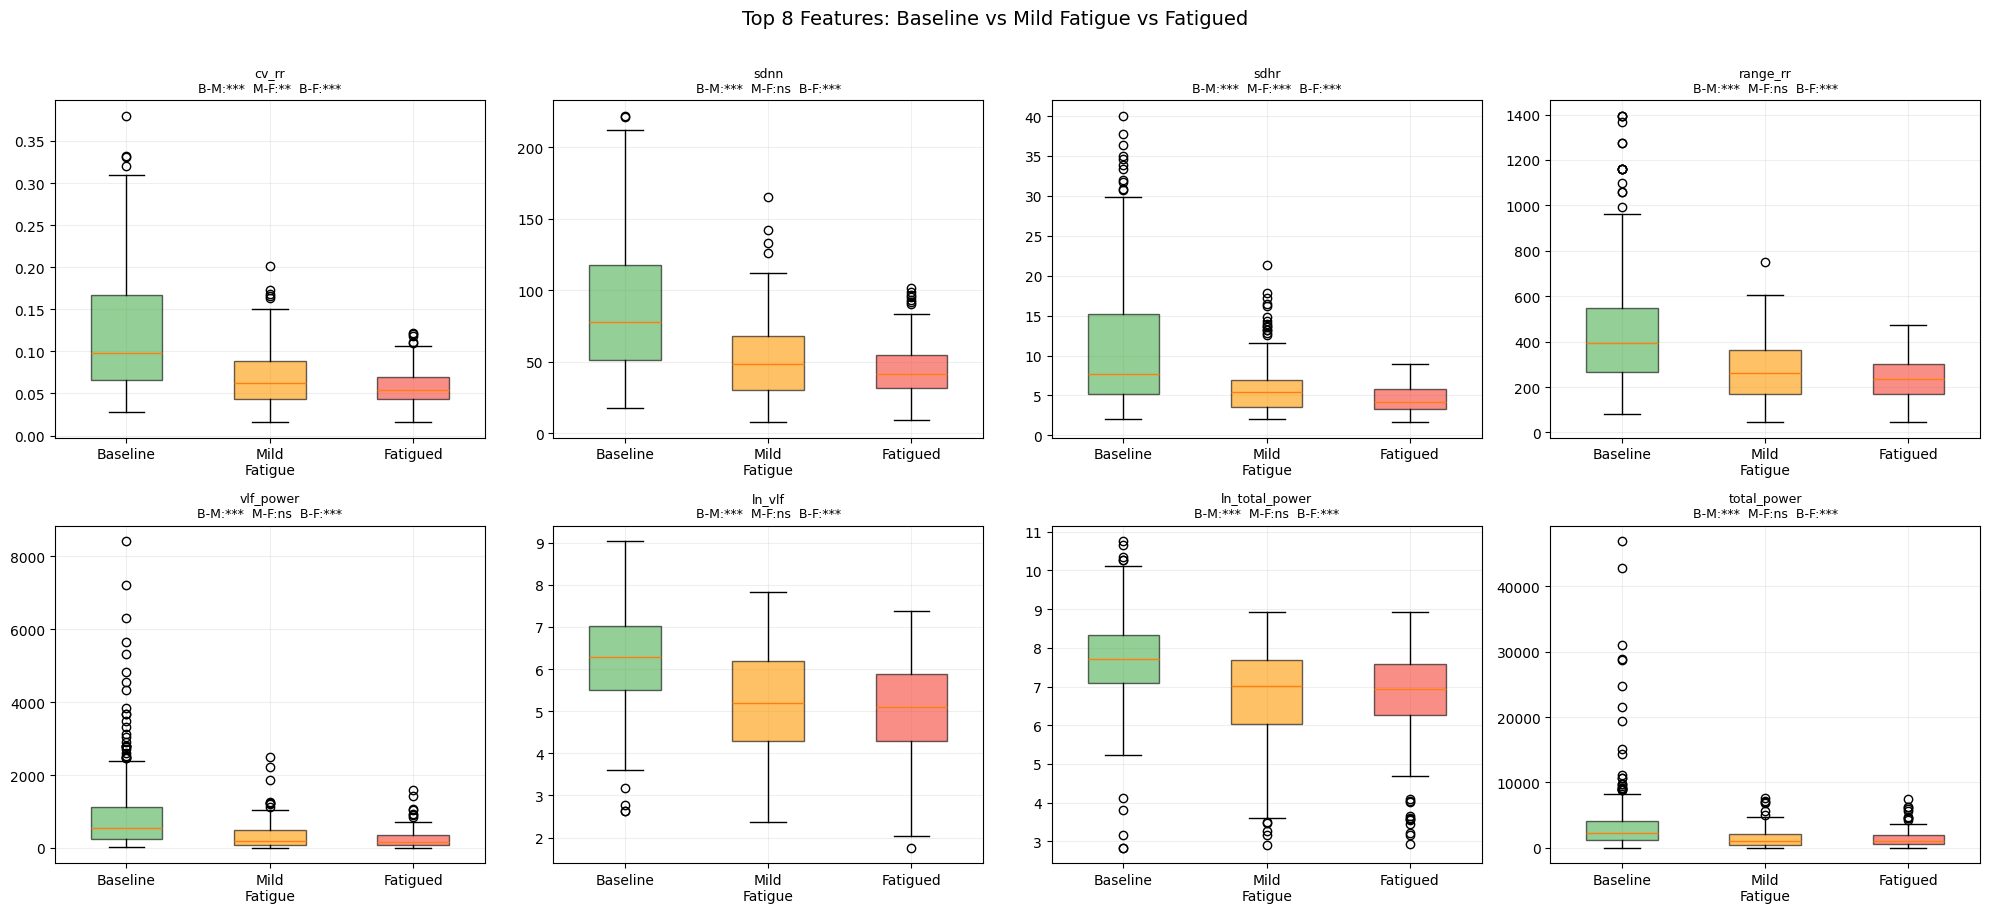

--- Generating effect size chart ---


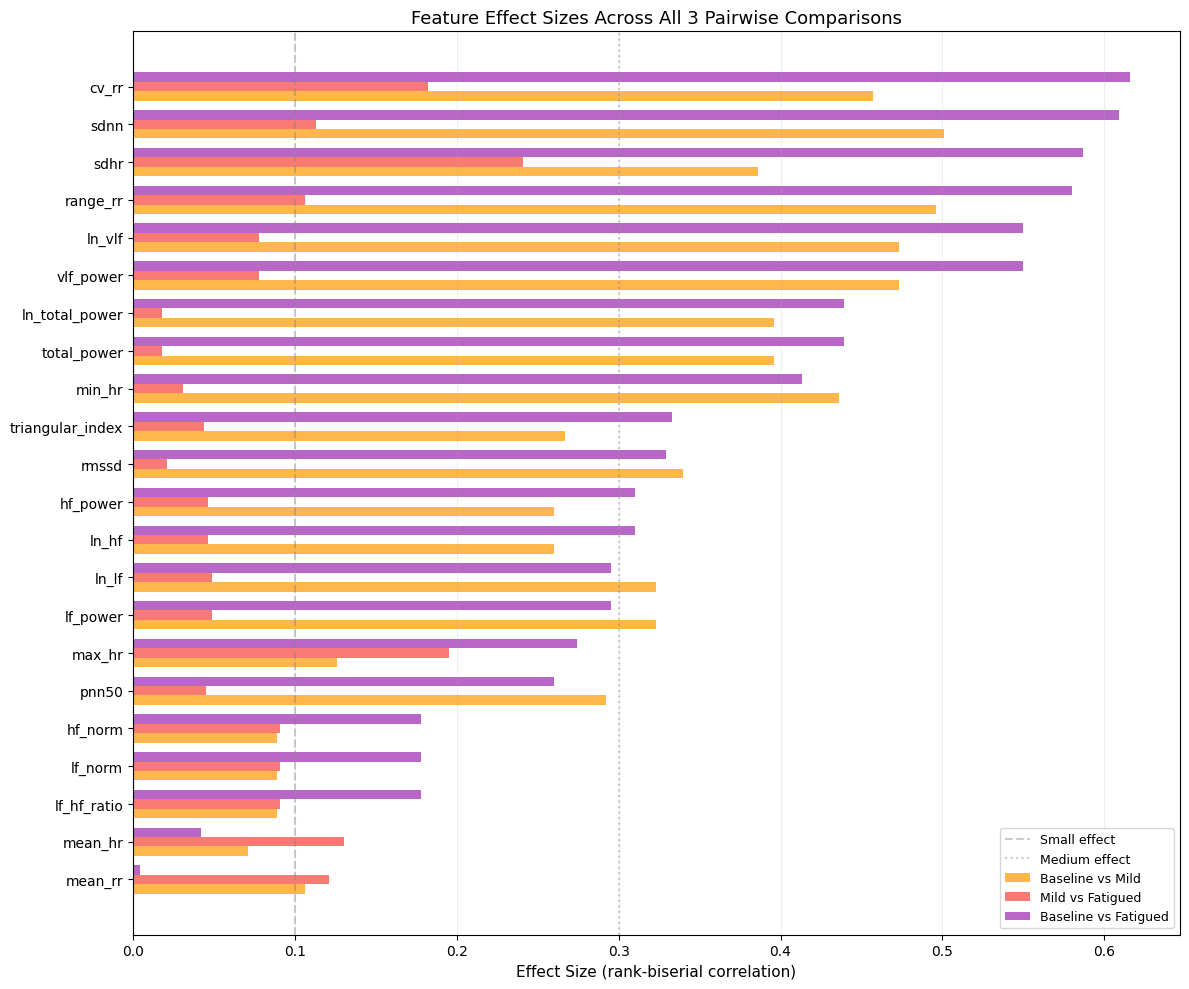


SUMMARY: WHICH FEATURES CAN DISTINGUISH WHICH CLASSES?

--- Features that distinguish ALL 3 pairs ---
  ★ max_hr               B=117.6  M=103.5  F=95.6
  ★ sdhr                 B=11.1  M=6.1  F=4.6
  ★ cv_rr                B=0.1  M=0.1  F=0.1

--- Features that distinguish Baseline vs Fatigued only ---
  mean_rr              B-M:ns  M-F:ns  B-F:ns
  sdnn                 B-M:***  M-F:ns  B-F:***
  rmssd                B-M:***  M-F:ns  B-F:***
  pnn50                B-M:***  M-F:ns  B-F:***
  mean_hr              B-M:ns  M-F:ns  B-F:ns
  min_hr               B-M:***  M-F:ns  B-F:***
  range_rr             B-M:***  M-F:ns  B-F:***
  triangular_index     B-M:***  M-F:ns  B-F:***
  vlf_power            B-M:***  M-F:ns  B-F:***
  lf_power             B-M:***  M-F:ns  B-F:***
  hf_power             B-M:***  M-F:ns  B-F:***
  total_power          B-M:***  M-F:ns  B-F:***
  lf_hf_ratio          B-M:ns  M-F:ns  B-F:**
  lf_norm              B-M:ns  M-F:ns  B-F:**
  hf_norm              B-M:ns  

In [ ]:
"""
3-CLASS STATISTICAL TESTING

Baseline (fresh)       = start_baseline to start_activity
Mild fatigue           = end_activity to start_fatigue (recovery + M2 tasks)
Fatigued (mental)      = start_fatigue to end_session

Statistical tests comparing all 3 pairs:
  - Baseline vs Mild
  - Mild vs Fatigued
  - Baseline vs Fatigued
"""

from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")


DATA_ROOT = Path("fatigueset")
FEATURE_CSV = Path("hrv_22_features_windowed.csv")



# LOAD MARKERS
def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events



# STEP 1: 3-CLASS LABELLING

"""
Baseline:      start_baseline to start_activity (fresh, VAS ~18)
Mild fatigue:  end_activity to start_fatigue (post-exercise, VAS ~24)
Fatigued:      start_fatigue to end_session (post-cognitive, VAS ~46)
Exercise:      start_activity to end_activity (excluded — ambiguous)
"""
def label_3_classes(df_features):
    
    print("=" * 70)
    print("STEP 1: 3-CLASS LABELLING")
    print("=" * 70)

    df_features["phase"] = "excluded"

    for pid in range(1, 13):
        for sid in [1, 2, 3]:
            markers = load_markers(pid, sid)
            if not markers:
                continue

            baseline_start  = markers.get("start_baseline")
            exercise_start  = markers.get("start_activity")
            exercise_end    = markers.get("end_activity")
            cognitive_start = markers.get("start_fatigue")
            session_end     = markers.get("end_session")

            mask = (df_features["participant"] == pid) & (df_features["session"] == sid)

            for idx in df_features[mask].index:
                w_start = pd.to_datetime(df_features.loc[idx, "window_start"], utc=True)

                # Fatigued = cognitive task to end of session
                if cognitive_start and w_start >= cognitive_start:
                    df_features.loc[idx, "phase"] = "fatigued"

                # Mild fatigue = after exercise ends to cognitive task start
                elif exercise_end and cognitive_start and w_start >= exercise_end and w_start < cognitive_start:
                    df_features.loc[idx, "phase"] = "mild_fatigue"

                # Baseline = start to exercise
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    df_features.loc[idx, "phase"] = "baseline"

                # Exercise = excluded
                elif exercise_start and exercise_end and w_start >= exercise_start and w_start < exercise_end:
                    df_features.loc[idx, "phase"] = "excluded"

                else:
                    df_features.loc[idx, "phase"] = "excluded"

    print("\nLabel counts:")
    print(df_features["phase"].value_counts().to_string())

    print("\nPer participant:")
    print(df_features.groupby(["participant", "phase"]).size().unstack(fill_value=0).to_string())

    # Show VAS scores for justification
    print("\n--- VAS Score Justification ---")
    print("  Baseline windows:     M1 mental fatigue VAS ≈ 18 (low)")
    print("  Mild fatigue windows: M2 mental fatigue VAS ≈ 24 (slightly elevated)")
    print("  Fatigued windows:     M3 mental fatigue VAS ≈ 36 (high)")

    return df_features



# STEP 2: KRUSKAL-WALLIS TEST (3-group comparison)

"""
For each feature:
    1. Kruskal-Wallis test: are ANY of the 3 groups different? (omnibus test)
    2. Mann-Whitney U pairwise tests: which pairs differ?
       - Baseline vs Mild
       - Mild vs Fatigued
       - Baseline vs Fatigued
"""
def run_3class_statistical_tests(df_features):
    print("\n" + "=" * 70)
    print("STEP 2: STATISTICAL TESTS — 3 CLASS COMPARISON")
    print("=" * 70)

    baseline = df_features[df_features["phase"] == "baseline"]
    mild     = df_features[df_features["phase"] == "mild_fatigue"]
    fatigued = df_features[df_features["phase"] == "fatigued"]

    print(f"\n  Baseline windows:     {len(baseline)}")
    print(f"  Mild fatigue windows: {len(mild)}")
    print(f"  Fatigued windows:     {len(fatigued)}")

    feature_cols = [
        "mean_rr", "sdnn", "rmssd", "pnn50",
        "mean_hr", "min_hr", "max_hr", "sdhr",
        "range_rr", "cv_rr", "triangular_index",
        "vlf_power", "lf_power", "hf_power",
        "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]

    results = []

    for feat in feature_cols:
        b_vals = baseline[feat].dropna().values
        m_vals = mild[feat].dropna().values
        f_vals = fatigued[feat].dropna().values

        if len(b_vals) < 3 or len(m_vals) < 3 or len(f_vals) < 3:
            continue

        # Kruskal-Wallis (omnibus: are any groups different?)
        kw_stat, kw_p = stats.kruskal(b_vals, m_vals, f_vals)

        # Pairwise Mann-Whitney U tests
        # Baseline vs Mild
        u_bm, p_bm = stats.mannwhitneyu(b_vals, m_vals, alternative="two-sided")
        n_bm = len(b_vals) * len(m_vals)
        eff_bm = abs(1 - (2 * u_bm) / n_bm)

        # Mild vs Fatigued
        u_mf, p_mf = stats.mannwhitneyu(m_vals, f_vals, alternative="two-sided")
        n_mf = len(m_vals) * len(f_vals)
        eff_mf = abs(1 - (2 * u_mf) / n_mf)

        # Baseline vs Fatigued
        u_bf, p_bf = stats.mannwhitneyu(b_vals, f_vals, alternative="two-sided")
        n_bf = len(b_vals) * len(f_vals)
        eff_bf = abs(1 - (2 * u_bf) / n_bf)

        results.append({
            "feature": feat,
            "baseline_mean": round(np.mean(b_vals), 2),
            "mild_mean": round(np.mean(m_vals), 2),
            "fatigued_mean": round(np.mean(f_vals), 2),
            # Omnibus
            "kw_p": round(kw_p, 4),
            "kw_sig": "YES" if kw_p < 0.05 else "NO",
            # Pairwise
            "p_base_mild": round(p_bm, 4),
            "eff_base_mild": round(eff_bm, 3),
            "sig_base_mild": "***" if p_bm < 0.001 else ("**" if p_bm < 0.01 else ("*" if p_bm < 0.05 else "ns")),
            "p_mild_fat": round(p_mf, 4),
            "eff_mild_fat": round(eff_mf, 3),
            "sig_mild_fat": "***" if p_mf < 0.001 else ("**" if p_mf < 0.01 else ("*" if p_mf < 0.05 else "ns")),
            "p_base_fat": round(p_bf, 4),
            "eff_base_fat": round(eff_bf, 3),
            "sig_base_fat": "***" if p_bf < 0.001 else ("**" if p_bf < 0.01 else ("*" if p_bf < 0.05 else "ns")),
        })

    results_df = pd.DataFrame(results)

    # Print omnibus results
    print(f"\n{'='*90}")
    print(f"KRUSKAL-WALLIS TEST (are any of the 3 groups different?)")
    print(f"{'='*90}")
    print(f"\n{'Feature':<20} {'Baseline':>10} {'Mild':>10} {'Fatigued':>10} {'KW p-value':>12} {'Sig?':>6}")
    print("-" * 75)
    for _, row in results_df.iterrows():
        print(f"{row['feature']:<20} {row['baseline_mean']:>10} {row['mild_mean']:>10} {row['fatigued_mean']:>10} {row['kw_p']:>12} {row['kw_sig']:>6}")

    n_sig = results_df[results_df["kw_sig"] == "YES"].shape[0]
    print(f"\n{n_sig} out of {len(results_df)} features show significant differences across 3 groups")

    # Print pairwise results
    print(f"\n{'='*90}")
    print(f"PAIRWISE COMPARISONS (Mann-Whitney U)")
    print(f"{'='*90}")
    print(f"\n{'Feature':<20} {'Base vs Mild':>15} {'Mild vs Fat':>15} {'Base vs Fat':>15}")
    print(f"{'':>20} {'p    eff sig':>15} {'p    eff sig':>15} {'p    eff sig':>15}")
    print("-" * 75)
    for _, row in results_df.iterrows():
        bm = f"{row['p_base_mild']:.3f} {row['eff_base_mild']:.2f} {row['sig_base_mild']}"
        mf = f"{row['p_mild_fat']:.3f} {row['eff_mild_fat']:.2f} {row['sig_mild_fat']}"
        bf = f"{row['p_base_fat']:.3f} {row['eff_base_fat']:.2f} {row['sig_base_fat']}"
        print(f"{row['feature']:<20} {bm:>15} {mf:>15} {bf:>15}")

    # Count which comparisons are significant
    n_bm_sig = results_df[results_df["sig_base_mild"].isin(["*", "**", "***"])].shape[0]
    n_mf_sig = results_df[results_df["sig_mild_fat"].isin(["*", "**", "***"])].shape[0]
    n_bf_sig = results_df[results_df["sig_base_fat"].isin(["*", "**", "***"])].shape[0]

    print(f"\nSignificant pairwise comparisons:")
    print(f"  Baseline vs Mild:     {n_bm_sig} / {len(results_df)} features")
    print(f"  Mild vs Fatigued:     {n_mf_sig} / {len(results_df)} features")
    print(f"  Baseline vs Fatigued: {n_bf_sig} / {len(results_df)} features")

    return results_df



# STEP 3: BOX PLOTS — 3 classes for top features

def plot_3class_boxplots(df_features, results_df):
    """Box plots showing all 3 classes for the top 8 features."""

    # Rank by Kruskal-Wallis effect (use baseline vs fatigued effect size)
    top8 = results_df.sort_values("eff_base_fat", ascending=False).head(8)

    baseline = df_features[df_features["phase"] == "baseline"]
    mild     = df_features[df_features["phase"] == "mild_fatigue"]
    fatigued = df_features[df_features["phase"] == "fatigued"]

    fig, axes = plt.subplots(2, 4, figsize=(20, 9))
    axes = axes.flatten()

    colors = ["#4CAF50", "#FF9800", "#F44336"]

    for i, (_, row) in enumerate(top8.iterrows()):
        feat = row["feature"]
        ax = axes[i]

        b_vals = baseline[feat].dropna().values
        m_vals = mild[feat].dropna().values
        f_vals = fatigued[feat].dropna().values

        bp = ax.boxplot([b_vals, m_vals, f_vals],
                        labels=["Baseline", "Mild\nFatigue", "Fatigued"],
                        patch_artist=True, widths=0.5)

        for patch, color in zip(bp["boxes"], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)

        # Add significance markers
        sig_text = f"B-M:{row['sig_base_mild']}  M-F:{row['sig_mild_fat']}  B-F:{row['sig_base_fat']}"
        ax.set_title(f"{feat}\n{sig_text}", fontsize=9)
        ax.grid(True, alpha=0.2)

    fig.suptitle("Top 8 Features: Baseline vs Mild Fatigue vs Fatigued", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()



# STEP 4: ALL FEATURES — effect size comparison chart

def plot_3class_effect_sizes(results_df):
    """Grouped bar chart showing effect sizes for all 3 pairwise comparisons."""

    # Sort by baseline vs fatigued effect
    ranked = results_df.sort_values("eff_base_fat", ascending=True)

    fig, ax = plt.subplots(figsize=(12, 10))

    y_pos = np.arange(len(ranked))
    bar_height = 0.25

    # 3 bars per feature
    bars1 = ax.barh(y_pos - bar_height, ranked["eff_base_mild"].values,
                     bar_height, color="#FF9800", alpha=0.7, label="Baseline vs Mild")
    bars2 = ax.barh(y_pos, ranked["eff_mild_fat"].values,
                     bar_height, color="#F44336", alpha=0.7, label="Mild vs Fatigued")
    bars3 = ax.barh(y_pos + bar_height, ranked["eff_base_fat"].values,
                     bar_height, color="#9C27B0", alpha=0.7, label="Baseline vs Fatigued")

    ax.set_yticks(y_pos)
    ax.set_yticklabels(ranked["feature"].values)
    ax.set_xlabel("Effect Size (rank-biserial correlation)", fontsize=11)
    ax.set_title("Feature Effect Sizes Across All 3 Pairwise Comparisons", fontsize=13)
    ax.axvline(x=0.1, color="gray", linestyle="--", alpha=0.4, label="Small effect")
    ax.axvline(x=0.3, color="gray", linestyle=":", alpha=0.4, label="Medium effect")
    ax.legend(fontsize=9, loc="lower right")
    ax.grid(True, alpha=0.2, axis="x")

    plt.tight_layout()
    plt.show()



# STEP 5: Summary — which features distinguish which pairs?

def print_summary(results_df):
    print("\n" + "=" * 70)
    print("SUMMARY: WHICH FEATURES CAN DISTINGUISH WHICH CLASSES?")
    print("=" * 70)

    print("\n--- Features that distinguish ALL 3 pairs ---")
    all_three = results_df[
        (results_df["sig_base_mild"].isin(["*", "**", "***"])) &
        (results_df["sig_mild_fat"].isin(["*", "**", "***"])) &
        (results_df["sig_base_fat"].isin(["*", "**", "***"]))
    ]
    if len(all_three) > 0:
        for _, row in all_three.iterrows():
            print(f"  ★ {row['feature']:<20} B={row['baseline_mean']:.1f}  M={row['mild_mean']:.1f}  F={row['fatigued_mean']:.1f}")
    else:
        print("  None — no feature distinguishes all 3 pairs")

    print("\n--- Features that distinguish Baseline vs Fatigued only ---")
    bf_only = results_df[
        (results_df["sig_base_fat"].isin(["*", "**", "***"])) &
        (~results_df["sig_base_mild"].isin(["*", "**", "***"])) |
        (~results_df["sig_mild_fat"].isin(["*", "**", "***"]))
    ]
    for _, row in bf_only.iterrows():
        bm = row["sig_base_mild"]
        mf = row["sig_mild_fat"]
        bf = row["sig_base_fat"]
        print(f"  {row['feature']:<20} B-M:{bm}  M-F:{mf}  B-F:{bf}")

    print("\n--- RECOMMENDATION ---")
    if len(all_three) >= 5:
        print("  Multiple features distinguish all 3 classes.")
        print("  → 3-class model is viable!")
    elif len(all_three) >= 2:
        print("  Some features distinguish all 3 classes, but most only separate extremes.")
        print("  → 3-class model possible but may struggle with mild vs fatigued.")
    else:
        print("  Very few features distinguish all 3 classes.")
        print("  → Binary model (baseline vs fatigued) is recommended.")
        print("  → Include 3-class as secondary experiment in dissertation.")


# RUN

if __name__ == "__main__":

    # Load features
    if FEATURE_CSV.exists():
        df_features = pd.read_csv(FEATURE_CSV)
    else:
        print(f"[ERROR] {FEATURE_CSV} not found. Run feature extraction first.")
        exit()

    df_features["window_start"] = pd.to_datetime(df_features["window_start"], utc=True)
    df_features["window_end"] = pd.to_datetime(df_features["window_end"], utc=True)

    print(f"Loaded {len(df_features)} windows")

    # Step 1: Label
    df_features = label_3_classes(df_features)

    # Step 2: Statistical tests
    results_df = run_3class_statistical_tests(df_features)

    # Step 3: Box plots
    print("\n--- Generating box plots ---")
    plot_3class_boxplots(df_features, results_df)

    # Step 4: Effect size chart
    print("--- Generating effect size chart ---")
    plot_3class_effect_sizes(results_df)

    # Step 5: Summary
    print_summary(results_df)

    # Save
    out_path = Path("hrv_features_3class_labelled.csv")
    df_features.to_csv(out_path, index=False)
    print(f"\nSaved to: {out_path}")

## Temperature extraction

SKIN TEMPERATURE: Feature Extraction + Statistical Testing

--- Raw temperature plots (P01, P06, P12) ---


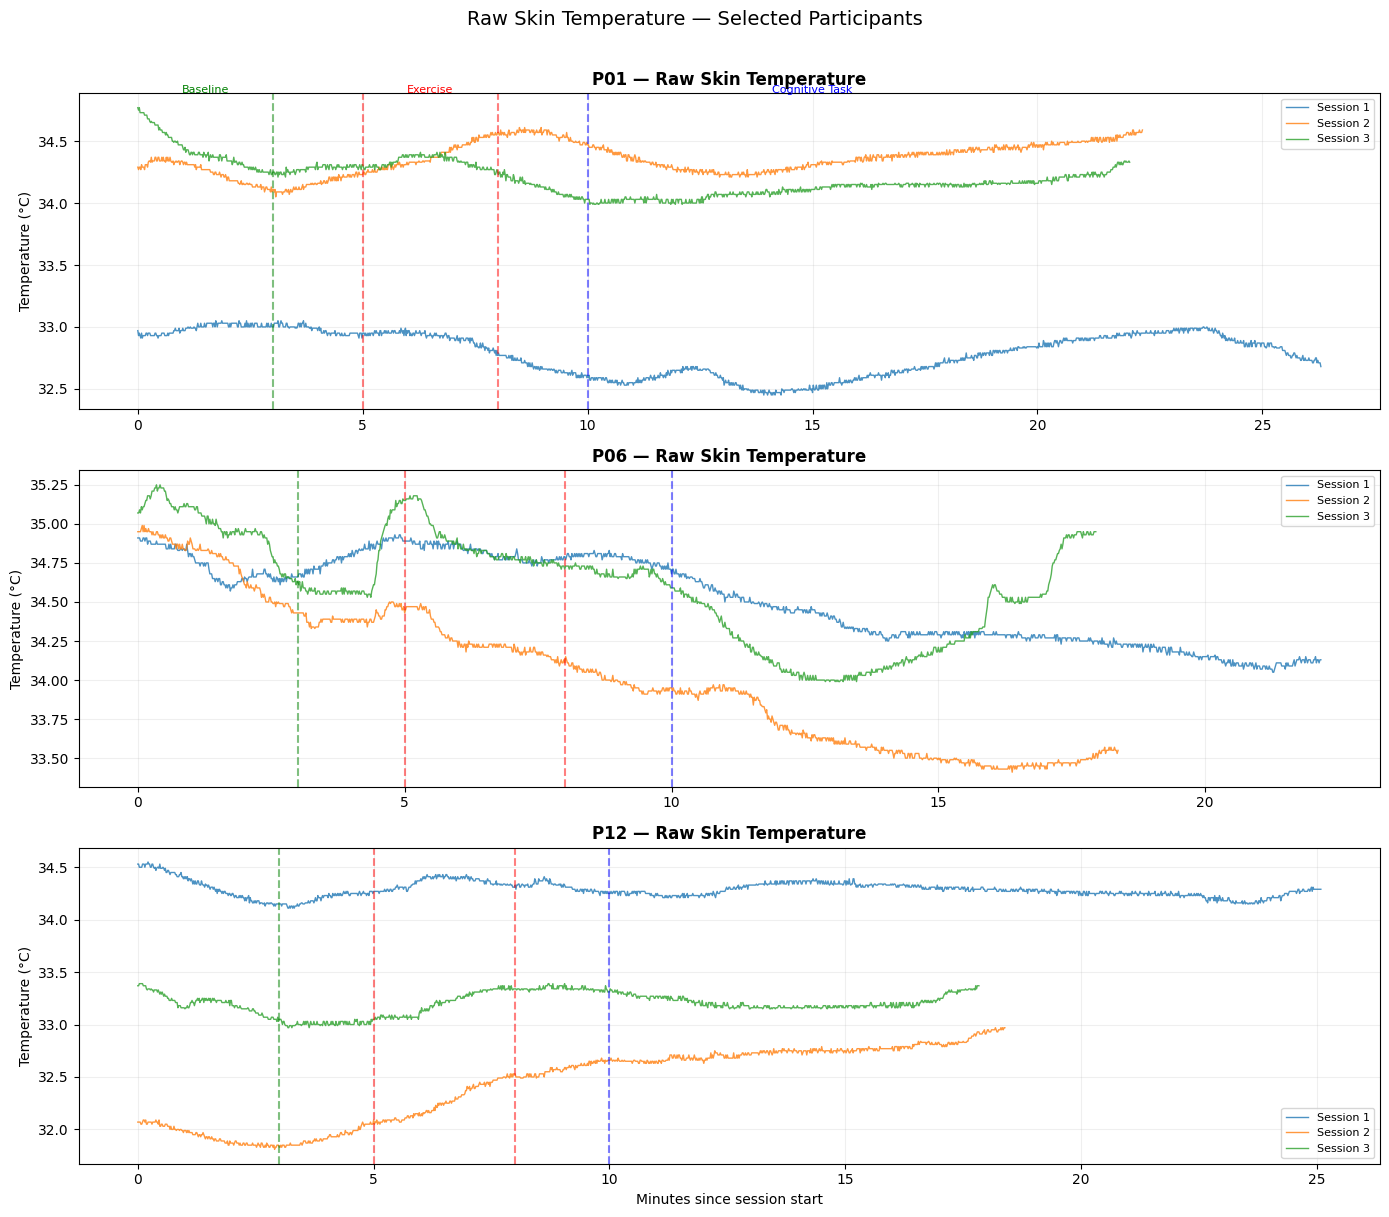


--- Extracting temperature features (all 12 participants) ---
  P01 S1: 24 windows
  P01 S2: 20 windows
  P01 S3: 20 windows
  P02 S1: 13 windows
  P02 S2: 17 windows
  P02 S3: 20 windows
  P03 S1: 18 windows
  P03 S2: 16 windows
  P03 S3: 16 windows
  P04 S1: 24 windows
  P04 S2: 22 windows
  P04 S3: 16 windows
  P05 S1: 26 windows
  P05 S2: 16 windows
  P05 S3: 15 windows
  P06 S1: 20 windows
  P06 S2: 16 windows
  P06 S3: 15 windows
  P07 S1: 19 windows
  P07 S2: 18 windows
  P07 S3: 21 windows
  P08 S1: 16 windows
  P08 S2: 9 windows
  P08 S3: 18 windows
  P09 S1: 24 windows
  P09 S2: 18 windows
  P09 S3: 17 windows
  P10 S1: 13 windows
  P10 S2: 17 windows
  P10 S3: 15 windows
  P11 S1: 23 windows
  P11 S2: 19 windows
  P11 S3: 14 windows
  P12 S1: 23 windows
  P12 S2: 16 windows
  P12 S3: 15 windows

Total windows: 649

Label counts:
phase
excluded    275
baseline    252
fatigued    122
Name: count, dtype: int64

--- Temperature feature plots (P01, P06, P12) ---


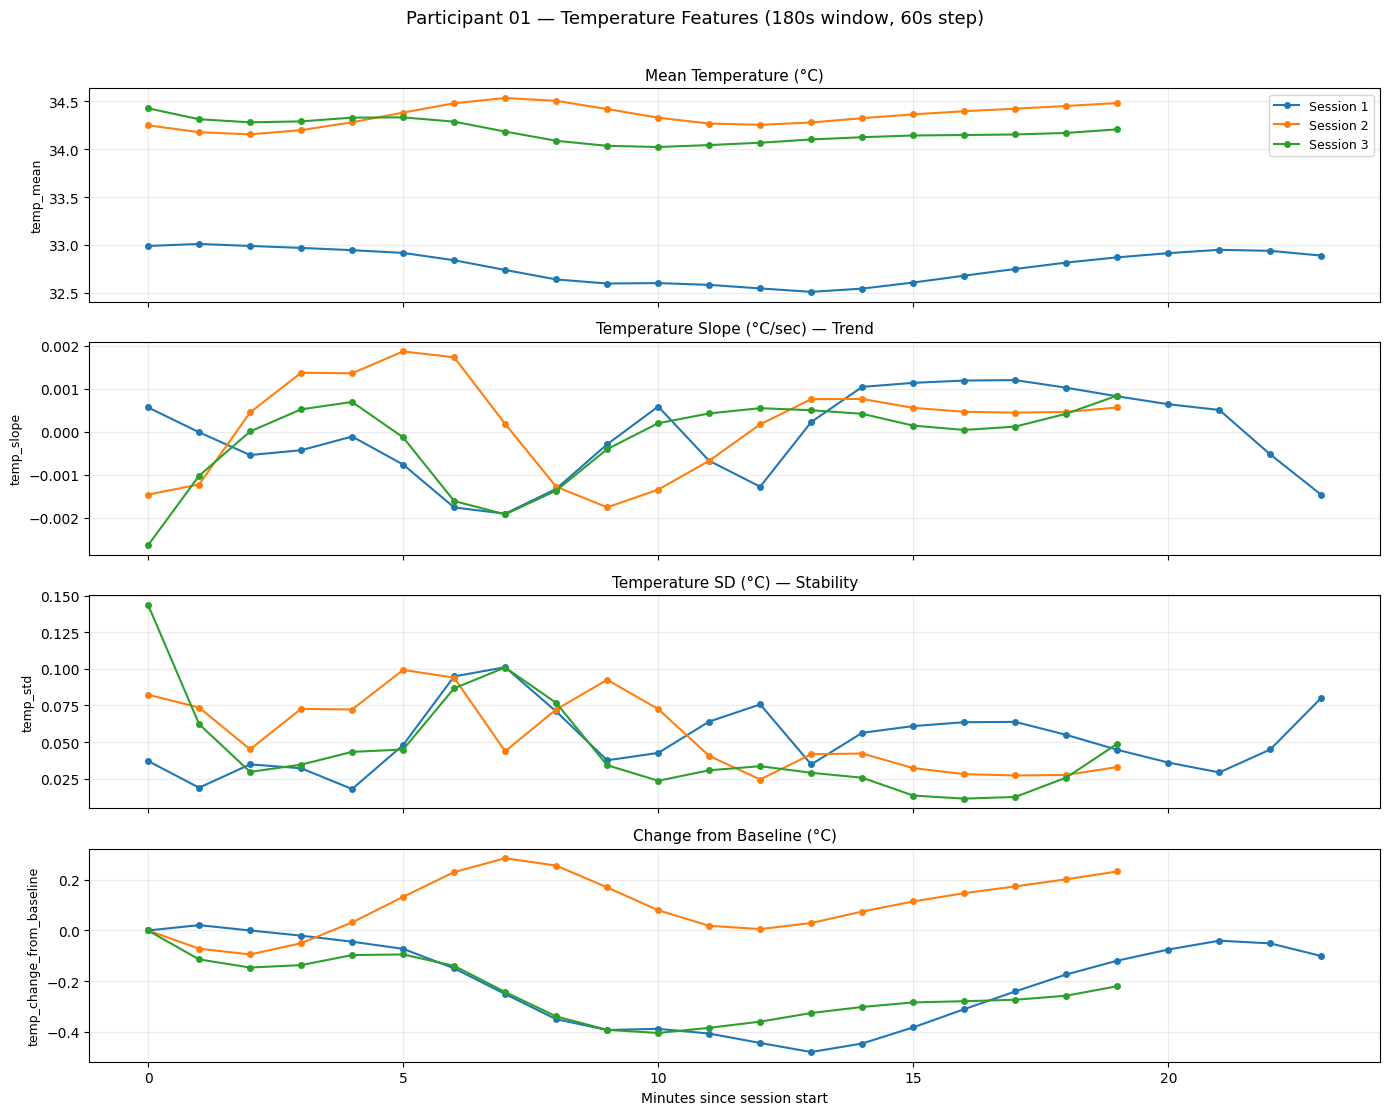

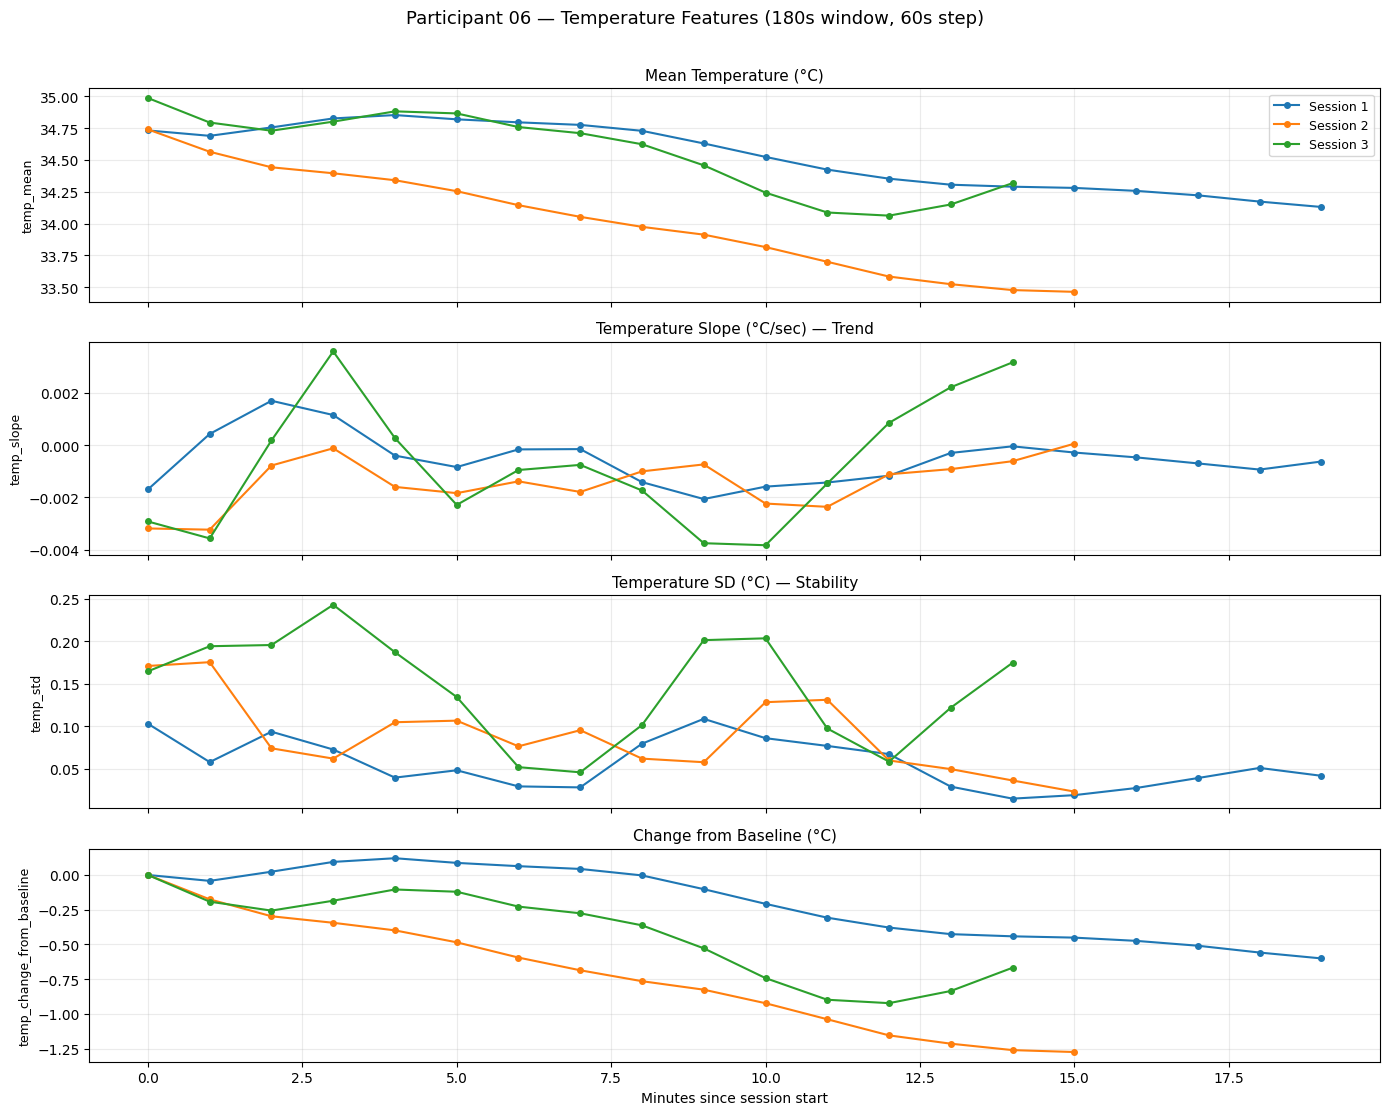

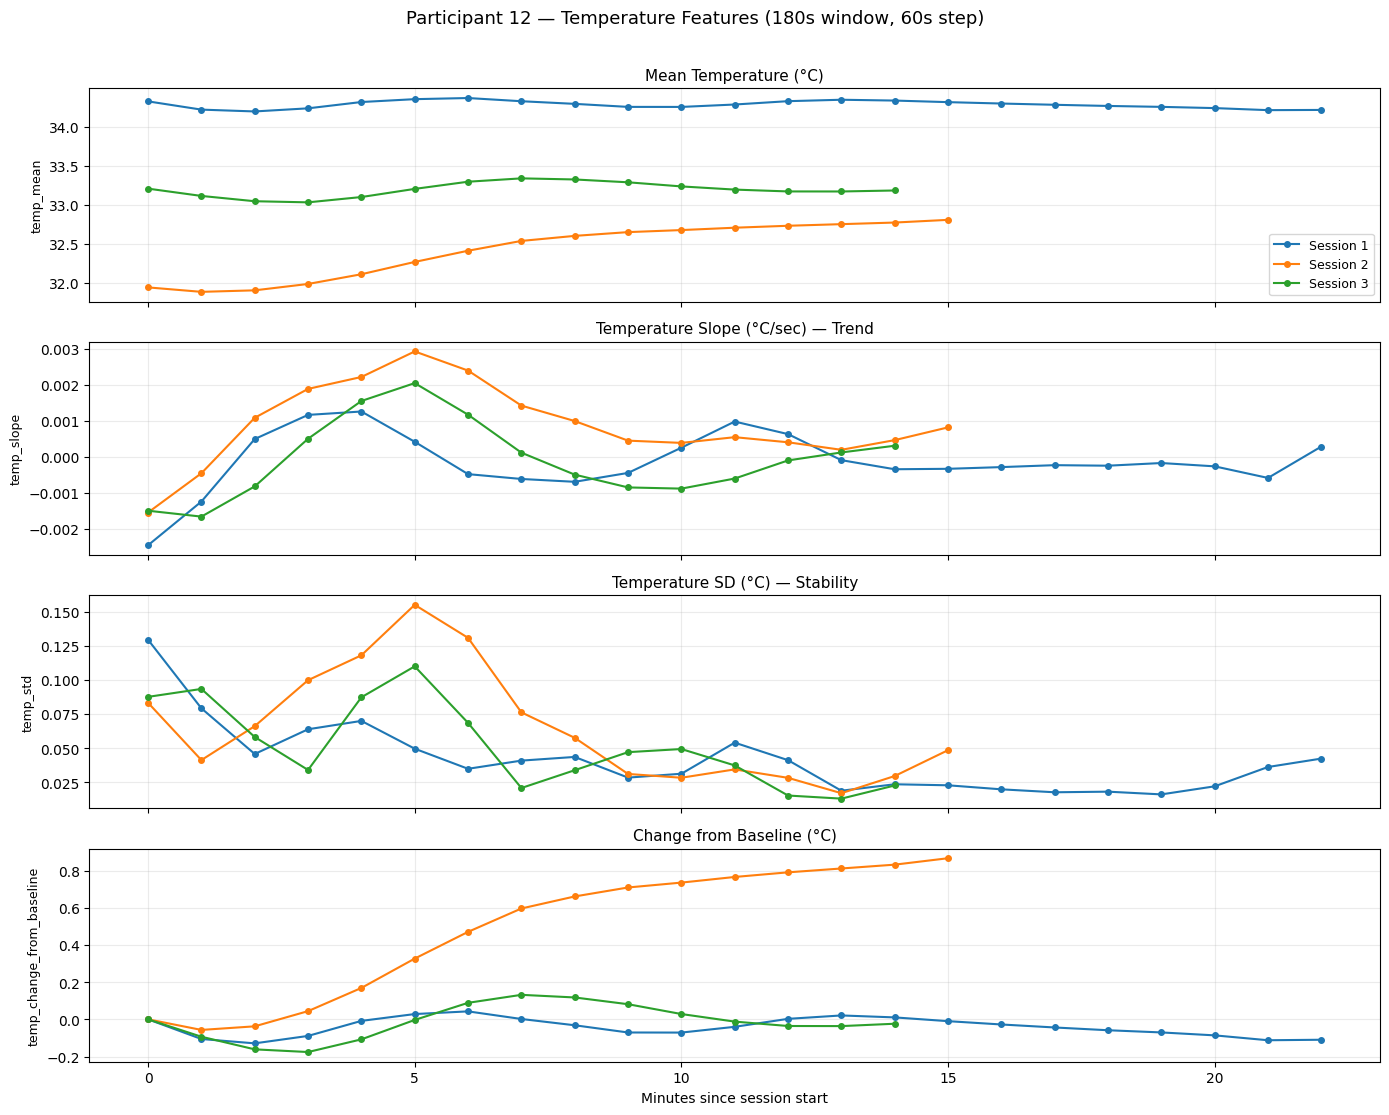


STATISTICAL TESTS — TEMPERATURE FEATURES: BASELINE vs FATIGUED

Baseline windows: 252
Fatigued windows: 122

Feature                          Baseline   Fatigued Direction          p-value Sig?         Effect
---------------------------------------------------------------------------------------------------------
temp_mean                         33.7414    33.3747 ↓ decreased         0.0025 YES **        0.193
temp_slope                        -0.0004     0.0001 ↑ increased            0.0 YES ***       0.262
temp_std                           0.1252     0.0555 ↓ decreased            0.0 YES ***       0.468
temp_range                         0.4427     0.2125 ↓ decreased            0.0 YES ***       0.477
temp_min                          33.5171    33.2649 ↓ decreased         0.0137 YES *         0.157
temp_change_from_baseline         -0.0327    -0.2111 ↓ decreased         0.0001 YES ***       0.258

6 out of 6 temperature features are statistically significant

--- Box plots ---


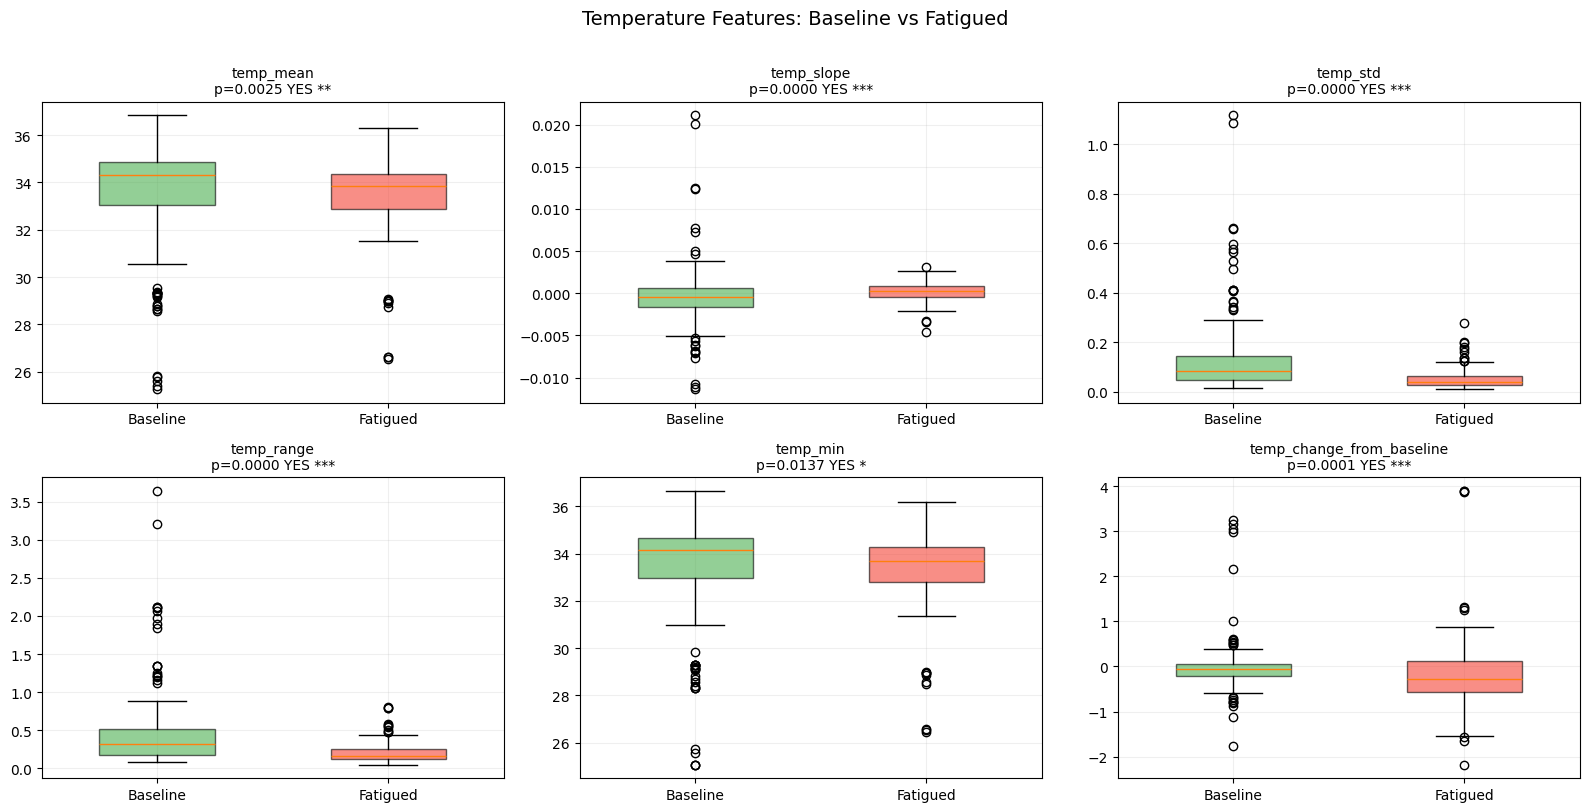


Saved to: temp_features_labelled.csv


In [2]:
"""
SKIN TEMPERATURE: Raw Plots + Feature Extraction + Statistical Testing

5 features per window: temp_mean, temp_slope, temp_std, temp_range, temp_change_from_baseline
Same labelling as HRV: baseline vs fatigued (binary)
"""

from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")


DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]
SELECTED_PARTICIPANTS = [1, 6, 12]

WINDOW_SEC = 180
STEP_SEC   = 60


def load_skin_temp(pid: int, sid: int) -> pd.DataFrame:
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    temp_file = session_dir / "wrist_skin_temperature.csv"

    if pid == 2 and sid == 1:
        temp_file = session_dir / "wrist_skin_temperature2.csv"

    if not temp_file.exists():
        return pd.DataFrame()

    df = pd.read_csv(temp_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

    if "temperature" in df.columns:
        df = df.rename(columns={"temperature": "skin_temp"})
    elif "temp" in df.columns:
        df = df.rename(columns={"temp": "skin_temp"})

    # Resample to 1 Hz
    df = (df.set_index("timestamp")
            .sort_index()
            .resample("1s")
            .mean(numeric_only=True)
            .dropna(subset=["skin_temp"])
            .reset_index())

    df["participant"] = pid
    df["session"] = sid
    return df


def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events



# PLOT RAW TEMPERATURE (selected participants)

"""Raw temperature for P01, P06, P12 with phase markers."""
def plot_raw_temp_selected():
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 12))

    for i, pid in enumerate(SELECTED_PARTICIPANTS):
        ax = axes[i]

        for sid in SESSIONS:
            df = load_skin_temp(pid, sid)
            if df.empty:
                continue
            t_min = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds() / 60.0
            ax.plot(t_min, df["skin_temp"], label=f"Session {sid}", alpha=0.8, linewidth=1)

        # Phase markers
        ax.axvline(x=3, color="green", linestyle="--", alpha=0.5)
        ax.axvline(x=5, color="red", linestyle="--", alpha=0.5)
        ax.axvline(x=8, color="red", linestyle="--", alpha=0.5)
        ax.axvline(x=10, color="blue", linestyle="--", alpha=0.5)

        ax.set_title(f"P{pid:02d} — Raw Skin Temperature", fontsize=12, fontweight="bold")
        ax.set_ylabel("Temperature (°C)")
        ax.grid(True, alpha=0.2)
        ax.legend(fontsize=8)

        # Phase labels on first plot
        if i == 0:
            ylim = ax.get_ylim()
            ax.text(1.5, ylim[1], "Baseline", ha="center", fontsize=8, color="green")
            ax.text(6.5, ylim[1], "Exercise", ha="center", fontsize=8, color="red")
            ax.text(15, ylim[1], "Cognitive Task", ha="center", fontsize=8, color="blue")

    axes[-1].set_xlabel("Minutes since session start")
    fig.suptitle("Raw Skin Temperature — Selected Participants", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()



# TEMPERATURE FEATURE EXTRACTION

"""
Compute 5 temperature features from a window of temperature readings.

Parameters
    
temp_values : np.ndarray
    Temperature readings (1 Hz) within a 180s window.

Returns
    
dict with:
    temp_mean   : average temperature in window
    temp_slope  : linear trend (°C per second), positive = warming
    temp_std    : standard deviation (stability)
    temp_range  : max - min
    temp_min    : minimum temperature
"""
def compute_temp_features(temp_values: np.ndarray) -> dict:
    
    temp = temp_values[np.isfinite(temp_values)]

    if len(temp) < 10:
        return {
            "temp_mean": np.nan, "temp_slope": np.nan,
            "temp_std": np.nan, "temp_range": np.nan,
            "temp_min": np.nan,
        }

    temp_mean = np.mean(temp)

    # Slope: fit linear regression (temperature vs time in seconds)
    x = np.arange(len(temp))
    try:
        coeffs = np.polyfit(x, temp, 1)
        temp_slope = coeffs[0]  # °C per second
    except:
        temp_slope = np.nan

    temp_std = np.std(temp, ddof=1)
    temp_range = np.max(temp) - np.min(temp)
    temp_min = np.min(temp)

    return {
        "temp_mean": temp_mean,
        "temp_slope": temp_slope,
        "temp_std": temp_std,
        "temp_range": temp_range,
        "temp_min": temp_min,
    }


"""
Extract temperature features for ALL 12 participants using sliding windows.
Also compute temp_change_from_baseline after all windows are extracted.
"""
def build_temp_feature_dataset() -> pd.DataFrame:
    
    all_rows = []

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            df_temp = load_skin_temp(pid, sid)
            if df_temp.empty:
                print(f"  [SKIP] P{pid:02d} S{sid}: no temp data")
                continue

            t_start = df_temp["timestamp"].iloc[0]
            t_end = df_temp["timestamp"].iloc[-1]

            win_id = 0
            w_start = t_start

            while w_start + pd.Timedelta(seconds=WINDOW_SEC) <= t_end:
                w_end = w_start + pd.Timedelta(seconds=WINDOW_SEC)

                mask = (df_temp["timestamp"] >= w_start) & (df_temp["timestamp"] < w_end)
                temp_in_window = df_temp.loc[mask, "skin_temp"].to_numpy(dtype=float)

                feats = compute_temp_features(temp_in_window)
                feats["participant"] = pid
                feats["session"] = sid
                feats["window_id"] = win_id
                feats["window_start"] = w_start
                feats["window_end"] = w_end

                all_rows.append(feats)
                win_id += 1
                w_start += pd.Timedelta(seconds=STEP_SEC)

            print(f"  P{pid:02d} S{sid}: {win_id} windows")

    df_feat = pd.DataFrame(all_rows)

    if not df_feat.empty:
        # Compute t_min
        df_feat["t_min"] = df_feat.groupby(["participant", "session"])["window_start"].transform(
            lambda s: (s - s.min()).dt.total_seconds() / 60.0
        )

        # Compute temp_change_from_baseline
        # = current window mean - first window mean for this participant-session
        df_feat["temp_change_from_baseline"] = df_feat.groupby(["participant", "session"])["temp_mean"].transform(
            lambda s: s - s.iloc[0]
        )

    return df_feat



# LABEL WINDOWS (same as HRV: baseline vs fatigued)
def label_temp_windows(df: pd.DataFrame) -> pd.DataFrame:
    df["phase"] = "excluded"

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            markers = load_markers(pid, sid)
            if not markers:
                continue

            baseline_start = markers.get("start_baseline")
            exercise_start = markers.get("start_activity")
            cognitive_start = markers.get("start_fatigue")

            mask = (df["participant"] == pid) & (df["session"] == sid)

            for idx in df[mask].index:
                w_start = pd.to_datetime(df.loc[idx, "window_start"], utc=True)

                if cognitive_start and w_start >= cognitive_start:
                    df.loc[idx, "phase"] = "fatigued"
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    df.loc[idx, "phase"] = "baseline"
                else:
                    df.loc[idx, "phase"] = "excluded"

    return df


# PLOT FEATURES (selected participants)
def plot_temp_features_selected(df: pd.DataFrame):
    """Plot temperature features for P01, P06, P12."""
    metrics = [
        ("temp_mean",                 "Mean Temperature (°C)"),
        ("temp_slope",                "Temperature Slope (°C/sec) — Trend"),
        ("temp_std",                  "Temperature SD (°C) — Stability"),
        ("temp_change_from_baseline", "Change from Baseline (°C)"),
    ]

    for pid in SELECTED_PARTICIPANTS:
        sub = df[df["participant"] == pid].copy()

        fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

        for ax, (col, title) in zip(axes, metrics):
            for sid, s in sub.groupby("session", sort=True):
                s = s.sort_values("t_min")
                ax.plot(s["t_min"], s[col], marker="o", markersize=4, linewidth=1.5, label=f"Session {sid}")
            ax.set_title(title, fontsize=11)
            ax.set_ylabel(col, fontsize=9)
            ax.grid(True, alpha=0.25)

        axes[0].legend(fontsize=9)
        axes[-1].set_xlabel("Minutes since session start")
        fig.suptitle(f"Participant {pid:02d} — Temperature Features ({WINDOW_SEC}s window, {STEP_SEC}s step)",
                     fontsize=13, y=1.01)
        plt.tight_layout()
        plt.show()



# STATISTICAL TESTS (baseline vs fatigued)
def run_temp_statistical_tests(df: pd.DataFrame):
    print("\n" + "=" * 70)
    print("STATISTICAL TESTS — TEMPERATURE FEATURES: BASELINE vs FATIGUED")
    print("=" * 70)

    baseline = df[df["phase"] == "baseline"]
    fatigued = df[df["phase"] == "fatigued"]

    print(f"\nBaseline windows: {len(baseline)}")
    print(f"Fatigued windows: {len(fatigued)}")

    feature_cols = ["temp_mean", "temp_slope", "temp_std", "temp_range",
                    "temp_min", "temp_change_from_baseline"]

    results = []

    for feat in feature_cols:
        b_vals = baseline[feat].dropna().values
        f_vals = fatigued[feat].dropna().values

        if len(b_vals) < 3 or len(f_vals) < 3:
            results.append({
                "feature": feat, "baseline_mean": np.nan, "fatigued_mean": np.nan,
                "direction": "N/A", "p_value": np.nan, "significant": "N/A", "effect_size": np.nan,
            })
            continue

        u_stat, p_val = stats.mannwhitneyu(b_vals, f_vals, alternative="two-sided")
        n1, n2 = len(b_vals), len(f_vals)
        effect_size = abs(1 - (2 * u_stat) / (n1 * n2))

        b_mean = np.mean(b_vals)
        f_mean = np.mean(f_vals)

        direction = "↑ increased" if f_mean > b_mean else ("↓ decreased" if f_mean < b_mean else "→ no change")
        sig = "YES ***" if p_val < 0.001 else ("YES **" if p_val < 0.01 else ("YES *" if p_val < 0.05 else "NO"))

        results.append({
            "feature": feat, "baseline_mean": round(b_mean, 4),
            "fatigued_mean": round(f_mean, 4), "direction": direction,
            "p_value": round(p_val, 4), "significant": sig,
            "effect_size": round(effect_size, 3),
        })

    results_df = pd.DataFrame(results)

    print(f"\n{'Feature':<30} {'Baseline':>10} {'Fatigued':>10} {'Direction':<15} {'p-value':>10} {'Sig?':<10} {'Effect':>8}")
    print("-" * 105)

    for _, row in results_df.iterrows():
        print(f"{row['feature']:<30} {row['baseline_mean']:>10} {row['fatigued_mean']:>10} {row['direction']:<15} {row['p_value']:>10} {row['significant']:<10} {row['effect_size']:>8}")

    n_sig = results_df[results_df["significant"].str.startswith("YES")].shape[0]
    print(f"\n{n_sig} out of {len(feature_cols)} temperature features are statistically significant")

    return results_df



# BOX PLOTS
def plot_temp_boxplots(df: pd.DataFrame, results_df: pd.DataFrame):
    baseline = df[df["phase"] == "baseline"]
    fatigued = df[df["phase"] == "fatigued"]

    feature_cols = ["temp_mean", "temp_slope", "temp_std", "temp_range",
                    "temp_min", "temp_change_from_baseline"]

    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    axes = axes.flatten()

    for i, feat in enumerate(feature_cols):
        ax = axes[i]

        b_vals = baseline[feat].dropna().values
        f_vals = fatigued[feat].dropna().values

        bp = ax.boxplot([b_vals, f_vals], labels=["Baseline", "Fatigued"],
                        patch_artist=True, widths=0.5)
        bp["boxes"][0].set_facecolor("#4CAF50")
        bp["boxes"][0].set_alpha(0.6)
        bp["boxes"][1].set_facecolor("#F44336")
        bp["boxes"][1].set_alpha(0.6)

        # Get p-value from results
        row = results_df[results_df["feature"] == feat].iloc[0]
        ax.set_title(f"{feat}\np={row['p_value']:.4f} {row['significant']}", fontsize=10)
        ax.grid(True, alpha=0.2)

    fig.suptitle("Temperature Features: Baseline vs Fatigued", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()



# RUN 
if __name__ == "__main__":

    print("=" * 60)
    print("SKIN TEMPERATURE: Feature Extraction + Statistical Testing")
    print("=" * 60)

    # Raw plots for selected participants
    print("\n--- Raw temperature plots (P01, P06, P12) ---")
    plot_raw_temp_selected()

    # Extract features for ALL participants
    print("\n--- Extracting temperature features (all 12 participants) ---")
    df_temp_features = build_temp_feature_dataset()

    if df_temp_features.empty:
        print("[ERROR] No data extracted.")
    else:
        print(f"\nTotal windows: {len(df_temp_features)}")

        # Label windows
        df_temp_features = label_temp_windows(df_temp_features)
        print(f"\nLabel counts:")
        print(df_temp_features["phase"].value_counts())

        # Plot features for selected participants
        print("\n--- Temperature feature plots (P01, P06, P12) ---")
        plot_temp_features_selected(df_temp_features)

        # Statistical tests
        results_df = run_temp_statistical_tests(df_temp_features)

        # Box plots
        print("\n--- Box plots ---")
        plot_temp_boxplots(df_temp_features, results_df)

        # Save
        out_path = Path("temp_features_labelled.csv")
        df_temp_features.to_csv(out_path, index=False)
        print(f"\nSaved to: {out_path}")


## Combine hrv and temp to make final training dataset

In [3]:
"""
COMBINE HRV + TEMPERATURE FEATURES INTO ONE TRAINING DATASET

Merges:
  - hrv_22_features_windowed.csv (22 HRV features per window)
  - temp_features_labelled.csv (6 temperature features per window)

Matches windows by participant, session, and closest timestamp.
Labels: baseline (0) vs fatigued (1)
Output: combined_features_labelled.csv (28 features + label)
"""

from pathlib import Path
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")


DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]

HRV_CSV = Path("hrv_22_features_windowed.csv")
TEMP_CSV = Path("temp_features_labelled.csv")



def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events


# LOAD AND PREPARE BOTH DATASETS
def load_hrv_features() -> pd.DataFrame:
    if not HRV_CSV.exists():
        print(f"[ERROR] {HRV_CSV} not found. Run HRV feature extraction first.")
        return pd.DataFrame()

    df = pd.read_csv(HRV_CSV)
    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
    df["window_end"] = pd.to_datetime(df["window_end"], utc=True)

    print(f"HRV features loaded: {len(df)} windows, {df['participant'].nunique()} participants")
    return df


def load_temp_features() -> pd.DataFrame:
    if not TEMP_CSV.exists():
        print(f"[ERROR] {TEMP_CSV} not found. Run temperature feature extraction first.")
        return pd.DataFrame()

    df = pd.read_csv(TEMP_CSV)
    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
    df["window_end"] = pd.to_datetime(df["window_end"], utc=True)

    print(f"Temperature features loaded: {len(df)} windows, {df['participant'].nunique()} participants")
    return df



# MERGE HRV + TEMPERATURE

"""
Merge HRV and temperature features by matching on participant, session, and window_id.

If window_id doesn't align perfectly (because HRV and temp might have slightly different window counts), fall back to matching by closest window_start timestamp.
"""
def merge_features(df_hrv: pd.DataFrame, df_temp: pd.DataFrame) -> pd.DataFrame:
    
    print("\n--- Merging HRV + Temperature features ---")

    # Temperature feature columns to merge
    temp_feature_cols = ["temp_mean", "temp_slope", "temp_std",
                         "temp_range", "temp_min", "temp_change_from_baseline"]

    # Try merging on participant + session + window_id first
    # Keep only the temp feature columns + merge keys
    temp_merge = df_temp[["participant", "session", "window_id"] + temp_feature_cols].copy()

    merged = df_hrv.merge(
        temp_merge,
        on=["participant", "session", "window_id"],
        how="left"
    )

    # Check how many rows got temperature features
    n_with_temp = merged["temp_mean"].notna().sum()
    n_without_temp = merged["temp_mean"].isna().sum()

    print(f"  Matched by window_id: {n_with_temp} windows have both HRV + temp")
    print(f"  Missing temperature:  {n_without_temp} windows")

    if n_without_temp > 0 and n_with_temp == 0:
        # window_id merge failed, try timestamp-based matching
        print("  Window ID merge failed. Trying timestamp-based matching...")

        merged = df_hrv.copy()
        for col in temp_feature_cols:
            merged[col] = np.nan

        for pid in range(1, N_PARTICIPANTS + 1):
            for sid in SESSIONS:
                hrv_mask = (merged["participant"] == pid) & (merged["session"] == sid)
                temp_mask = (df_temp["participant"] == pid) & (df_temp["session"] == sid)

                hrv_windows = merged[hrv_mask]
                temp_windows = df_temp[temp_mask]

                if temp_windows.empty:
                    continue

                for idx in hrv_windows.index:
                    hrv_start = merged.loc[idx, "window_start"]

                    # Find closest temperature window
                    time_diffs = abs((temp_windows["window_start"] - hrv_start).dt.total_seconds())
                    closest_idx = time_diffs.idxmin()

                    # Only match if within 30 seconds
                    if time_diffs[closest_idx] <= 30:
                        for col in temp_feature_cols:
                            merged.loc[idx, col] = df_temp.loc[closest_idx, col]

        n_with_temp = merged["temp_mean"].notna().sum()
        print(f"  After timestamp matching: {n_with_temp} windows have both HRV + temp")

    return merged



# LABEL WINDOWS (baseline vs fatigued)

"""
Label windows using exp_markers.csv:
      baseline = start_baseline to start_activity
      fatigued = start_fatigue to end_session
      excluded = everything else (exercise + recovery)
"""
def label_windows(df: pd.DataFrame) -> pd.DataFrame:
    print("\n--- Labelling windows ---")

    df["phase"] = "excluded"

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            markers = load_markers(pid, sid)
            if not markers:
                continue

            baseline_start = markers.get("start_baseline")
            exercise_start = markers.get("start_activity")
            cognitive_start = markers.get("start_fatigue")

            mask = (df["participant"] == pid) & (df["session"] == sid)

            for idx in df[mask].index:
                w_start = df.loc[idx, "window_start"]

                if cognitive_start and w_start >= cognitive_start:
                    df.loc[idx, "phase"] = "fatigued"
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    df.loc[idx, "phase"] = "baseline"
                else:
                    df.loc[idx, "phase"] = "excluded"

    # Add binary label column
    df["label"] = -1  # default
    df.loc[df["phase"] == "baseline", "label"] = 0
    df.loc[df["phase"] == "fatigued", "label"] = 1

    print(f"\nLabel counts:")
    print(df["phase"].value_counts().to_string())

    return df



# FINAL DATASET SUMMARY

def summarise_dataset(df: pd.DataFrame):
    # Only keep labelled windows (baseline + fatigued)
    df_train = df[df["label"] >= 0].copy()

    hrv_features = [
        "mean_rr", "sdnn", "rmssd", "pnn50",
        "mean_hr", "min_hr", "max_hr", "sdhr",
        "range_rr", "cv_rr", "triangular_index",
        "vlf_power", "lf_power", "hf_power",
        "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]

    temp_features = [
        "temp_mean", "temp_slope", "temp_std",
        "temp_range", "temp_min", "temp_change_from_baseline"
    ]

    all_features = hrv_features + temp_features

    print("\n" + "=" * 60)
    print("FINAL TRAINING DATASET SUMMARY")
    print("=" * 60)

    print(f"\nTotal labelled windows: {len(df_train)}")
    print(f"  Baseline (label=0): {(df_train['label'] == 0).sum()}")
    print(f"  Fatigued (label=1): {(df_train['label'] == 1).sum()}")

    print(f"\nTotal features: {len(all_features)}")
    print(f"  HRV features:         {len(hrv_features)}")
    print(f"  Temperature features:  {len(temp_features)}")

    # Check for NaN in features
    nan_counts = df_train[all_features].isna().sum()
    total_nans = nan_counts.sum()
    if total_nans == 0:
        print(f"\nNaN values: NONE — all features complete!")
    else:
        print(f"\nNaN values found:")
        print(nan_counts[nan_counts > 0].to_string())

        # How many rows have at least one NaN?
        rows_with_nan = df_train[all_features].isna().any(axis=1).sum()
        print(f"\nRows with at least one NaN: {rows_with_nan} / {len(df_train)}")

    # Per-participant breakdown
    print(f"\nPer-participant breakdown:")
    print(f"{'PID':>4} | {'Baseline':>8} | {'Fatigued':>8} | {'Total':>6} | {'Has Temp':>8}")
    print("-" * 50)
    for pid in sorted(df_train["participant"].unique()):
        sub = df_train[df_train["participant"] == pid]
        n_base = (sub["label"] == 0).sum()
        n_fat = (sub["label"] == 1).sum()
        has_temp = sub["temp_mean"].notna().sum()
        print(f"P{pid:02d}  | {n_base:>8} | {n_fat:>8} | {len(sub):>6} | {has_temp:>8}")

    print(f"\nFeature list:")
    print(f"  HRV: {hrv_features}")
    print(f"  Temp: {temp_features}")

    return df_train, all_features


# ============================================================
# RUN
# ============================================================
if __name__ == "__main__":

    print("=" * 60)
    print("COMBINING HRV + TEMPERATURE INTO TRAINING DATASET")
    print("=" * 60)

    # Load both feature sets
    df_hrv = load_hrv_features()
    df_temp = load_temp_features()

    if df_hrv.empty:
        print("[ERROR] Cannot proceed without HRV features.")
        exit()

    if df_temp.empty:
        print("[WARNING] No temperature features. Proceeding with HRV only.")
        df_combined = df_hrv.copy()
    else:
        # Merge
        df_combined = merge_features(df_hrv, df_temp)

    # Label windows
    df_combined = label_windows(df_combined)

    # Summary
    df_train, all_features = summarise_dataset(df_combined)

    # Save full dataset (all windows including excluded)
    full_out = Path("combined_all_windows.csv")
    df_combined.to_csv(full_out, index=False)
    print(f"\nSaved full dataset (all windows): {full_out}")

    # Save training dataset only (baseline + fatigued)
    train_out = Path("training_dataset.csv")
    df_train.to_csv(train_out, index=False)
    print(f"Saved training dataset (labelled only): {train_out}")


COMBINING HRV + TEMPERATURE INTO TRAINING DATASET
HRV features loaded: 675 windows, 12 participants
Temperature features loaded: 649 windows, 12 participants

--- Merging HRV + Temperature features ---
  Matched by window_id: 647 windows have both HRV + temp
  Missing temperature:  28 windows

--- Labelling windows ---

Label counts:
phase
baseline    275
excluded    273
fatigued    127

FINAL TRAINING DATASET SUMMARY

Total labelled windows: 402
  Baseline (label=0): 275
  Fatigued (label=1): 127

Total features: 28
  HRV features:         22
  Temperature features:  6

NaN values found:
mean_rr                       1
sdnn                          1
rmssd                         1
pnn50                         1
mean_hr                       1
min_hr                        1
max_hr                        1
sdhr                          1
range_rr                      1
cv_rr                         1
triangular_index              1
vlf_power                     1
lf_power            

## ML Model training

MENTAL FATIGUE PREDICTION — MODEL TRAINING PIPELINE

--- Loading training data ---
  Dropped 14 rows with NaN features
  Training data: 388 windows
  Baseline (0): 274
  Fatigued (1): 114
  Participants: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
  Features: 28

PART 1: TRAINING ALL MODELS (LOSO Cross-Validation)

--- Random Forest ---
  Accuracy:  0.7990
  F1 Score:  0.6100
  Precision: 0.7093
  Recall:    0.5351
  Confusion Matrix:
    [[249  25]
 [ 53  61]]

--- SVM ---
  Accuracy:  0.8067
  F1 Score:  0.6988
  Precision: 0.6444
  Recall:    0.7632
  Confusion Matrix:
    [[226  48]
 [ 27  87]]

--- Logistic Regression ---
  Accuracy:  0.7655
  F1 Score:  0.6486
  Precision: 0.5793
  Recall:    0.7368
  Confusion Matrix:
    [[213  61]
 [ 30  84]]

--- XGBoost ---
  Accuracy:  0.8428
  F1 Score:  0.6995
  Precision: 0.7978
  Recall:    0.6228
  Confusion Matrix:
    [

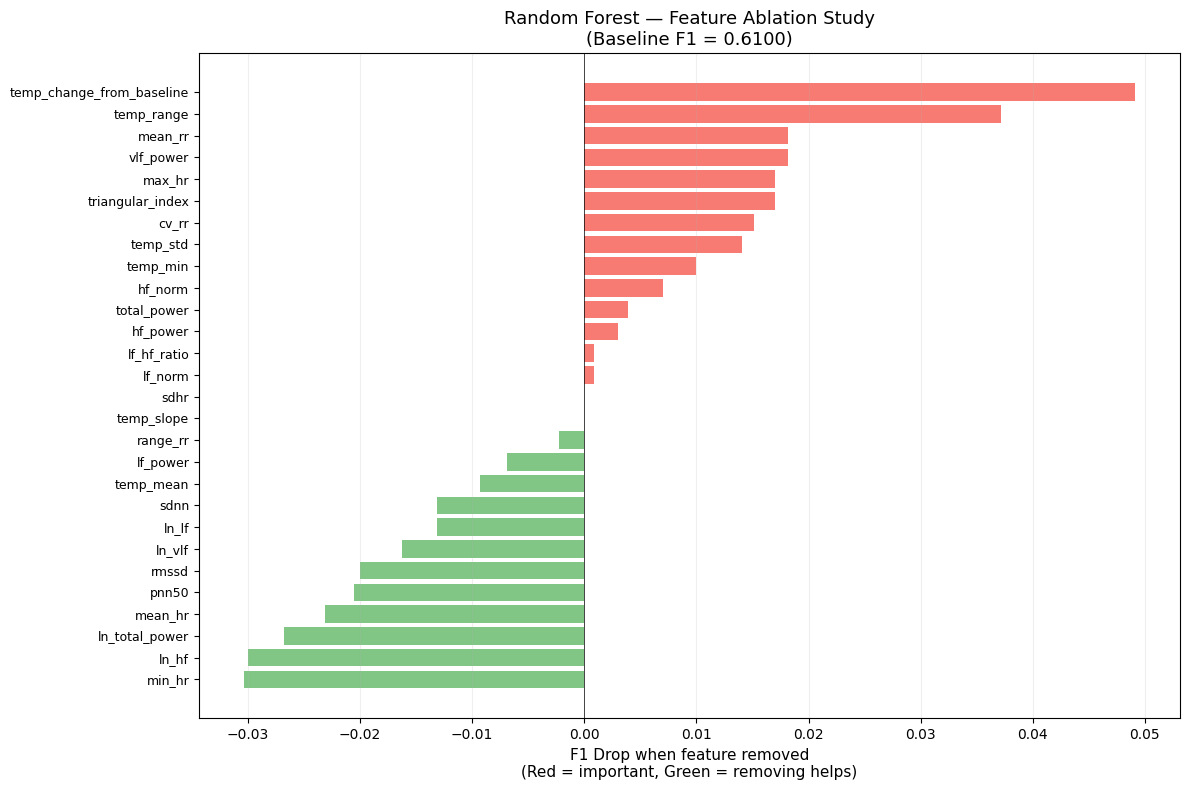

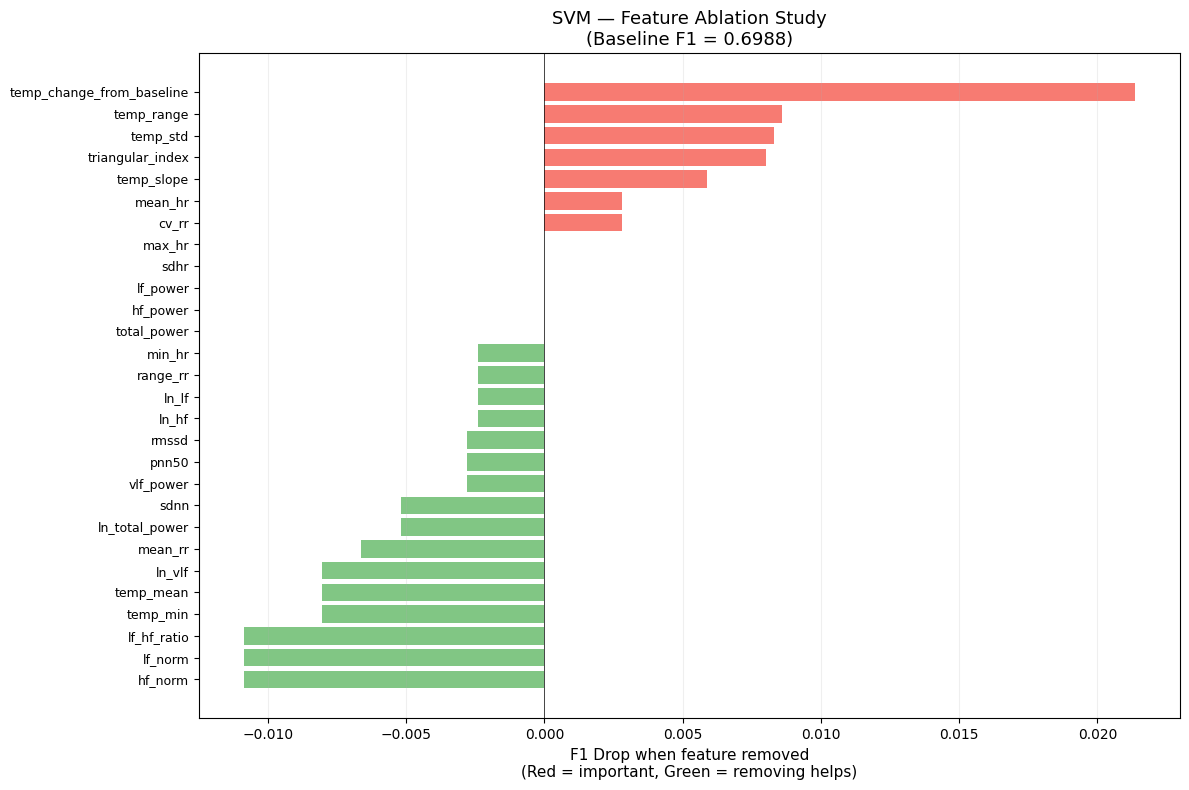

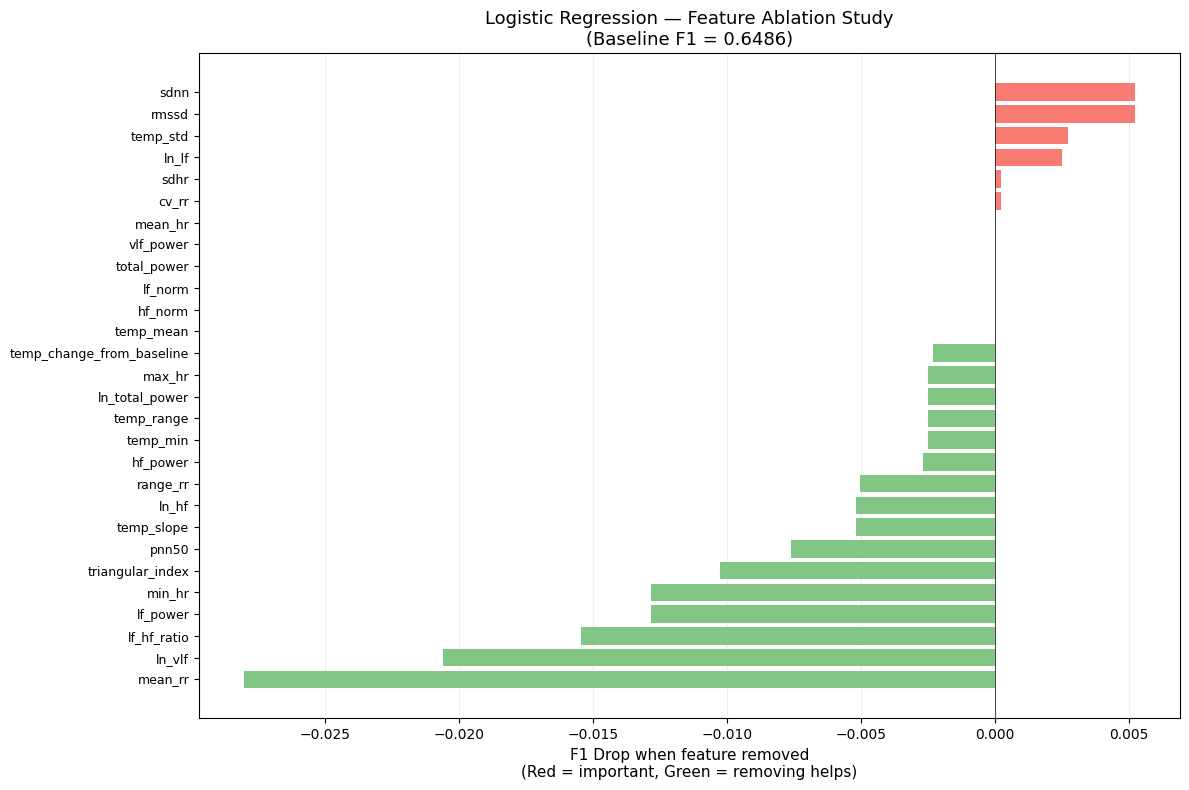

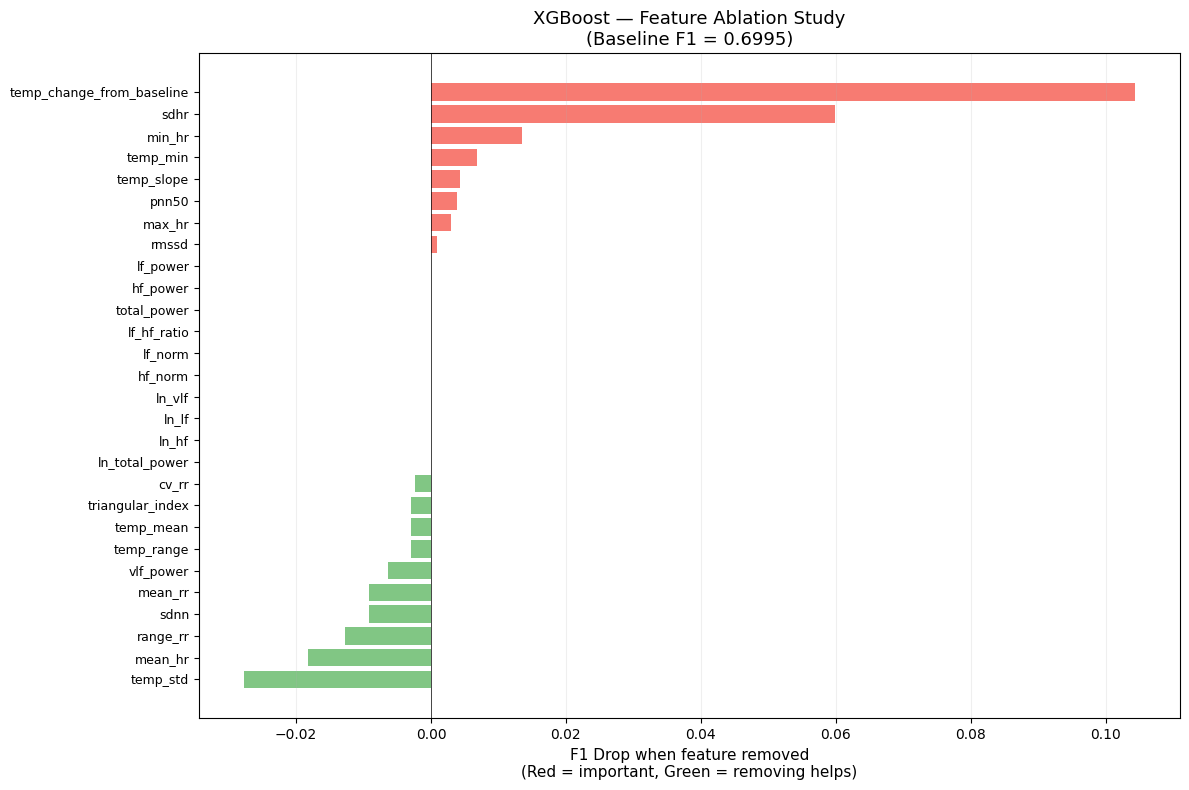

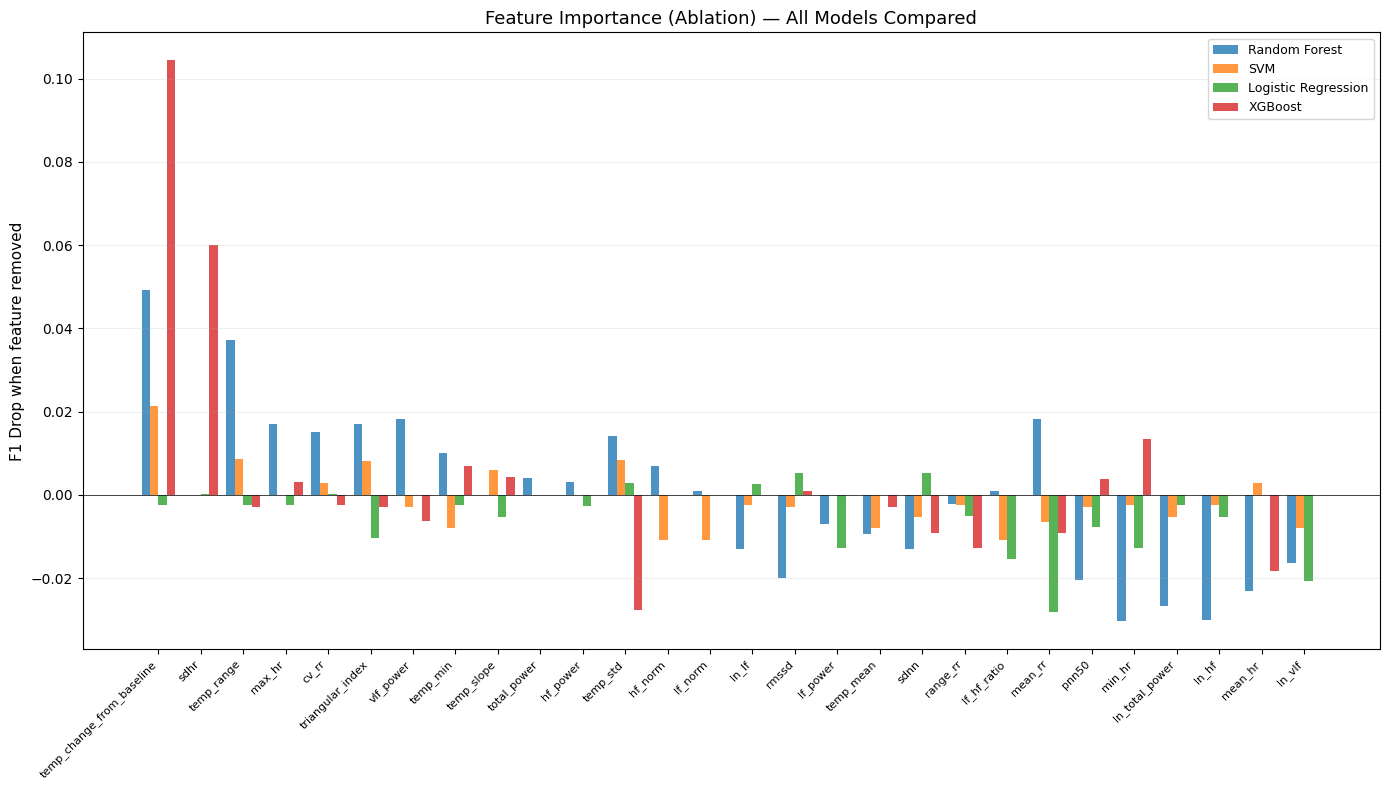


PART 3: MODEL COMPARISON

Model                    Accuracy         F1  Precision     Recall
-----------------------------------------------------------------
Random Forest              0.7990     0.6100     0.7093     0.5351
SVM                        0.8067     0.6988     0.6444     0.7632
Logistic Regression        0.7655     0.6486     0.5793     0.7368
XGBoost                    0.8428     0.6995     0.7978     0.6228


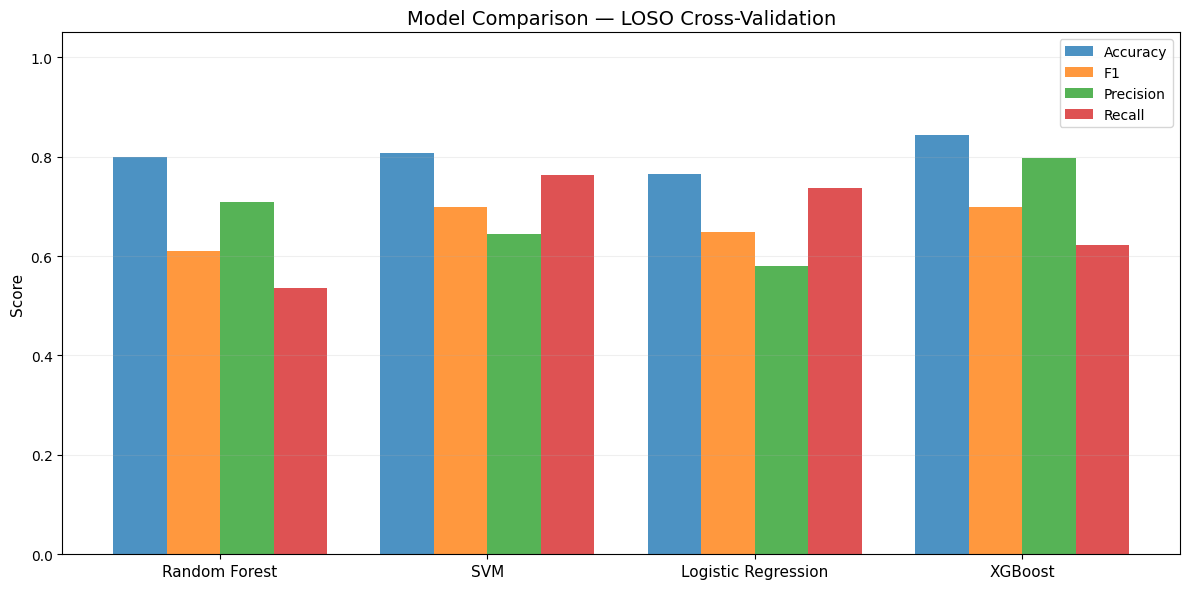


Best model by F1: XGBoost

Per-participant results (XGBoost):
 PID | Accuracy |       F1 | Samples
-----------------------------------
P01  |    0.683 |    0.480 |      41
P02  |    1.000 |    1.000 |      29
P03  |    0.969 |    0.947 |      32
P04  |    0.800 |    0.632 |      35
P05  |    0.967 |    0.941 |      30
P06  |    0.909 |    0.880 |      33
P07  |    0.788 |    0.462 |      33
P08  |    0.917 |    0.750 |      24
P09  |    0.737 |    0.500 |      38
P10  |    0.929 |    0.800 |      28
P11  |    0.848 |    0.706 |      33
P12  |    0.688 |    0.444 |      32


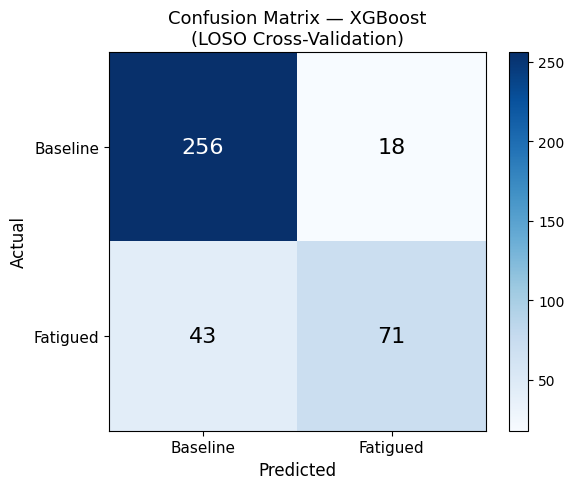


PART 4: UNSUPERVISED EXPLORATION

--- PCA Visualisation ---


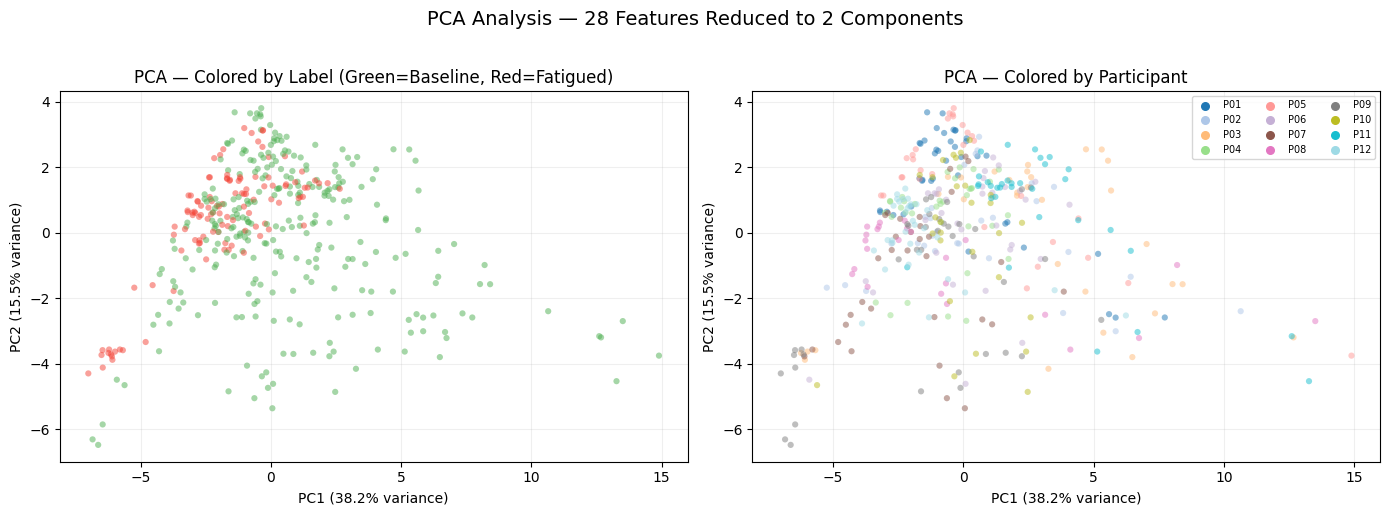

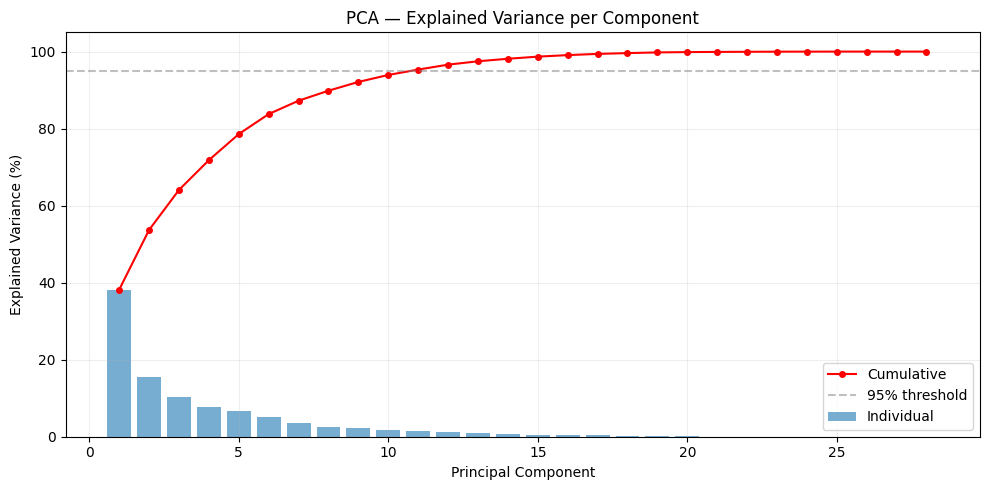

  Components needed for 95% variance: 11
  PC1 explains: 38.2%
  PC2 explains: 15.5%

--- K-Means Clustering (k=2) ---
  Cluster alignment with labels: 0.5284
  Confusion matrix (clusters vs labels):
    [[ 95 179]
 [  4 110]]


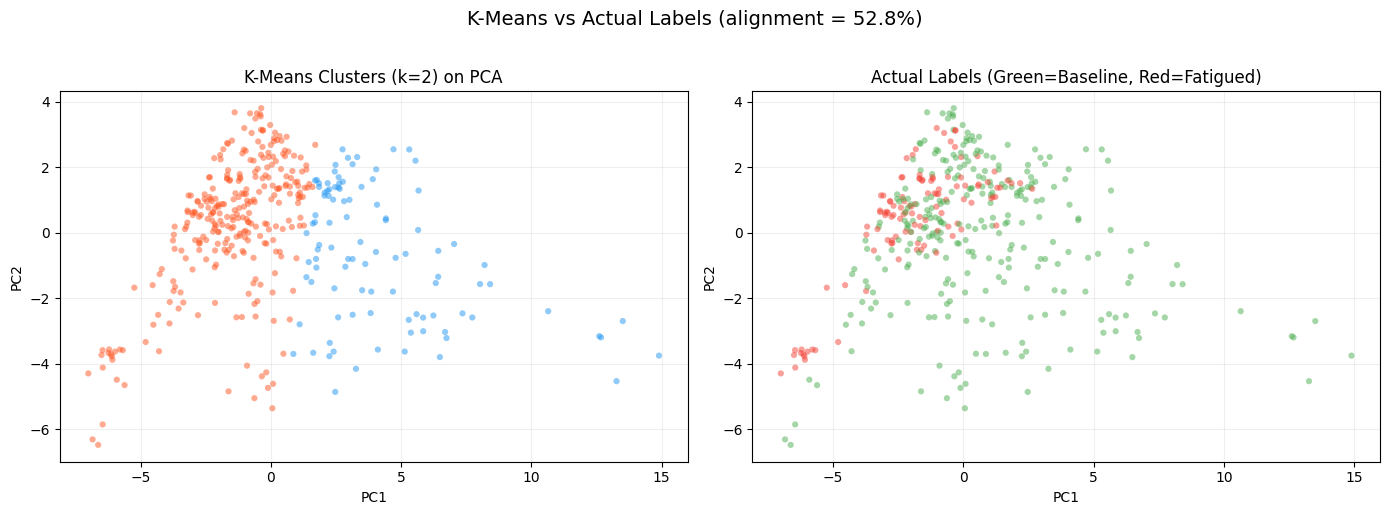


--- t-SNE Visualisation ---


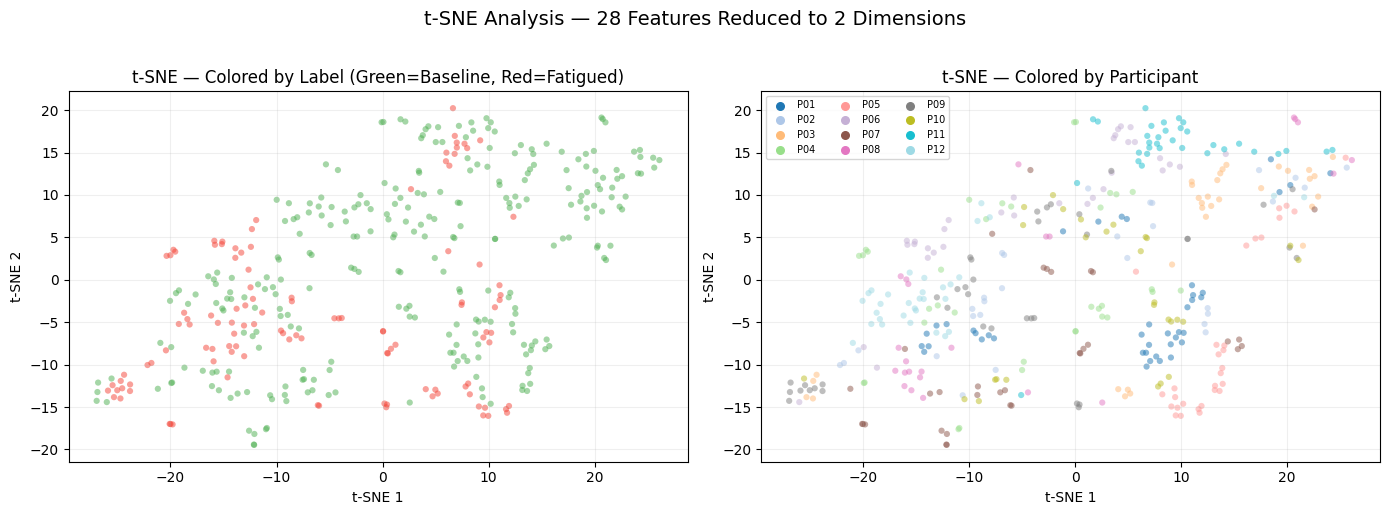


PART 5: RANDOM FOREST FEATURE IMPORTANCE


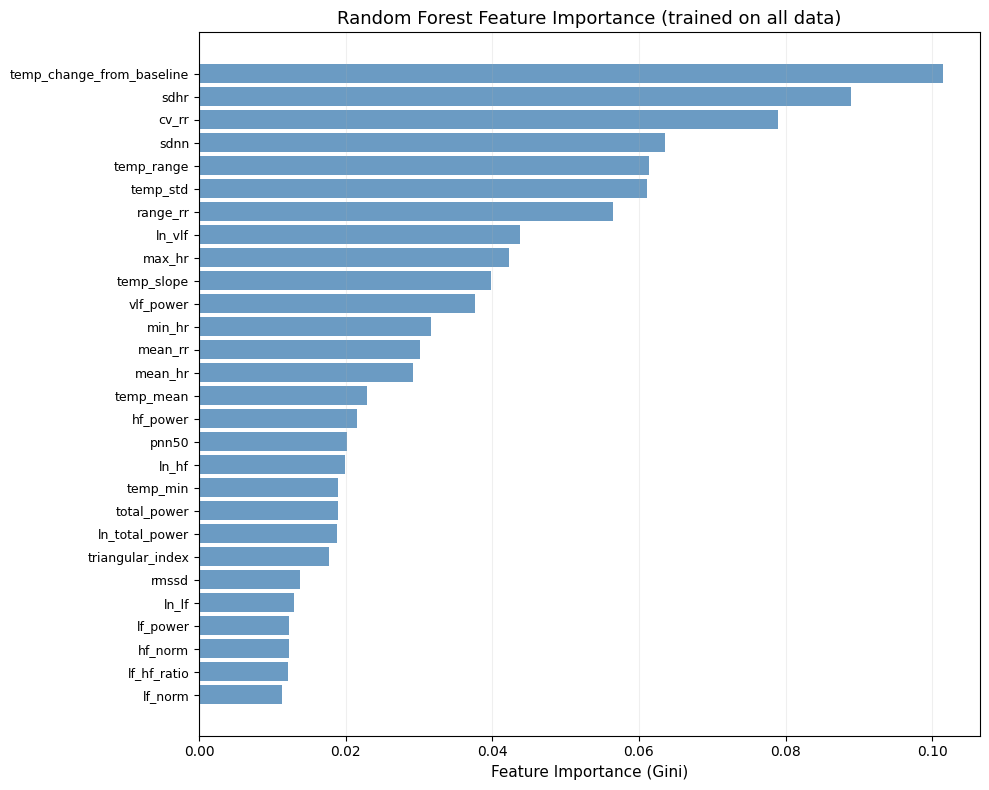


Feature importance ranking:
   1. [TEMP] temp_change_from_baseline      0.1014
   2. [HRV] sdhr                           0.0890
   3. [HRV] cv_rr                          0.0790
   4. [HRV] sdnn                           0.0635
   5. [TEMP] temp_range                     0.0614
   6. [TEMP] temp_std                       0.0611
   7. [HRV] range_rr                       0.0565
   8. [HRV] ln_vlf                         0.0438
   9. [HRV] max_hr                         0.0422
  10. [TEMP] temp_slope                     0.0398
  11. [HRV] vlf_power                      0.0377
  12. [HRV] min_hr                         0.0316
  13. [HRV] mean_rr                        0.0301
  14. [HRV] mean_hr                        0.0292
  15. [TEMP] temp_mean                      0.0229
  16. [HRV] hf_power                       0.0216
  17. [HRV] pnn50                          0.0201
  18. [HRV] ln_hf                          0.0199
  19. [TEMP] temp_min                       0.0190
  20. [HRV] tot

In [4]:
"""
MODEL TRAINING PIPELINE — Mental Fatigue Prediction

Supervised Models:
  1. Random Forest
  2. SVM
  3. XGBoost
  4. Logistic Regression

Unsupervised Exploration:
  5. PCA visualisation
  6. K-Means clustering
  7. t-SNE visualisation

Evaluation: Leave-One-Subject-Out (LOSO) Cross-Validation
Feature Ablation: Remove one feature at a time, measure impact
"""

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Try importing xgboost
try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    print("[WARNING] XGBoost not installed. Run: pip install xgboost")
    print("          Skipping XGBoost model.")
    HAS_XGBOOST = False


TRAINING_CSV = Path("training_dataset.csv")

HRV_FEATURES = [
    "mean_rr", "sdnn", "rmssd", "pnn50",
    "mean_hr", "min_hr", "max_hr", "sdhr",
    "range_rr", "cv_rr", "triangular_index",
    "vlf_power", "lf_power", "hf_power",
    "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
    "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
]

TEMP_FEATURES = [
    "temp_mean", "temp_slope", "temp_std",
    "temp_range", "temp_min", "temp_change_from_baseline"
]

ALL_FEATURES = HRV_FEATURES + TEMP_FEATURES


def load_training_data():
    if not TRAINING_CSV.exists():
        print(f"[ERROR] {TRAINING_CSV} not found. Run combine_features.py first.")
        return None, None, None

    df = pd.read_csv(TRAINING_CSV)
    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
    df["window_end"] = pd.to_datetime(df["window_end"], utc=True)

    # Drop rows with NaN in features
    before = len(df)
    df = df.dropna(subset=ALL_FEATURES)
    after = len(df)
    if before != after:
        print(f"  Dropped {before - after} rows with NaN features")

    print(f"  Training data: {len(df)} windows")
    print(f"  Baseline (0): {(df['label'] == 0).sum()}")
    print(f"  Fatigued (1): {(df['label'] == 1).sum()}")
    print(f"  Participants: {sorted(df['participant'].unique())}")
    print(f"  Features: {len(ALL_FEATURES)}")

    X = df[ALL_FEATURES].values
    y = df["label"].values
    participants = df["participant"].values

    return X, y, participants


# LOSO CROSS-VALIDATION FUNCTION

"""
Train on 11 participants, test on 1. Rotate through all 12.

Parameters
    
    model_class : class
        Sklearn-compatible model class
    model_params : dict
        Parameters to pass to the model
    X : np.ndarray
        Feature matrix (n_samples, n_features)
    y : np.ndarray
        Labels (0 or 1)
    participants : np.ndarray
        Participant IDs for each row
    feature_cols : list
        Which feature columns to use (for feature ablation)
    scale : bool
        Whether to standardise features (needed for SVM, LR)

Returns
    
    dict with overall metrics and per-participant results
"""
def loso_cv(model_class, model_params, X, y, participants, feature_cols, scale=False):
    
    unique_pids = sorted(set(participants))
    all_preds = []
    all_true = []
    per_participant = {}

    for test_pid in unique_pids:
        # Split
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask][:, feature_cols], y[train_mask]
        X_test, y_test = X[test_mask][:, feature_cols], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        # Scale if needed
        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        # Train
        model = model_class(**model_params)
        model.fit(X_train, y_train)

        # Predict
        y_pred = model.predict(X_test)

        all_preds.extend(y_pred)
        all_true.extend(y_test)

        # Per-participant metrics
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1, "n_samples": len(y_test)}

    all_preds = np.array(all_preds)
    all_true = np.array(all_true)

    # Overall metrics
    results = {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "confusion_matrix": confusion_matrix(all_true, all_preds),
        "per_participant": per_participant,
        "y_true": all_true,
        "y_pred": all_preds,
    }

    return results



# DEFINE MODELS
def get_models():
    models = {
        "Random Forest": {
            "class": RandomForestClassifier,
            "params": {"n_estimators": 100, "random_state": 42, "class_weight": "balanced"},
            "scale": False,
        },
        "SVM": {
            "class": SVC,
            "params": {"kernel": "rbf", "C": 1.0, "gamma": "scale", "class_weight": "balanced", "random_state": 42},
            "scale": True,
        },
        "Logistic Regression": {
            "class": LogisticRegression,
            "params": {"max_iter": 1000, "class_weight": "balanced", "random_state": 42},
            "scale": True,
        },
    }

    if HAS_XGBOOST:
        # Calculate scale_pos_weight for imbalanced classes
        models["XGBoost"] = {
            "class": XGBClassifier,
            "params": {
                "n_estimators": 100,
                "max_depth": 5,
                "learning_rate": 0.1,
                "random_state": 42,
                "eval_metric": "logloss",
                "use_label_encoder": False,
            },
            "scale": False,
        }

    return models



# PART 1: TRAIN ALL MODELS WITH ALL FEATURES
def train_all_models(X, y, participants):
    print("\n" + "=" * 70)
    print("PART 1: TRAINING ALL MODELS (LOSO Cross-Validation)")
    print("=" * 70)

    models = get_models()
    all_feature_indices = list(range(len(ALL_FEATURES)))
    results = {}

    for name, config in models.items():
        print(f"\n--- {name} ---")
        res = loso_cv(
            config["class"], config["params"],
            X, y, participants,
            feature_cols=all_feature_indices,
            scale=config["scale"]
        )
        results[name] = res

        print(f"  Accuracy:  {res['accuracy']:.4f}")
        print(f"  F1 Score:  {res['f1']:.4f}")
        print(f"  Precision: {res['precision']:.4f}")
        print(f"  Recall:    {res['recall']:.4f}")
        print(f"  Confusion Matrix:")
        print(f"    {res['confusion_matrix']}")

    return results



# PART 2: FEATURE ABLATION — Remove one feature at a time
def feature_ablation(X, y, participants):
    print("\n" + "=" * 70)
    print("PART 2: FEATURE ABLATION STUDY")
    print("Remove one feature at a time, measure impact on each model")
    print("=" * 70)

    models = get_models()
    all_feature_indices = list(range(len(ALL_FEATURES)))

    # First get baseline performance (all features)
    baseline_results = {}
    for name, config in models.items():
        res = loso_cv(
            config["class"], config["params"],
            X, y, participants,
            feature_cols=all_feature_indices,
            scale=config["scale"]
        )
        baseline_results[name] = res["f1"]

    print(f"\nBaseline F1 scores (all {len(ALL_FEATURES)} features):")
    for name, f1 in baseline_results.items():
        print(f"  {name}: {f1:.4f}")

    # Now remove each feature one at a time
    ablation_results = {name: {} for name in models}

    for i, feat_name in enumerate(ALL_FEATURES):
        # Create feature list WITHOUT feature i
        reduced_features = [j for j in all_feature_indices if j != i]

        for name, config in models.items():
            res = loso_cv(
                config["class"], config["params"],
                X, y, participants,
                feature_cols=reduced_features,
                scale=config["scale"]
            )
            # Store the DROP in F1 (positive = removing this feature hurt performance)
            f1_drop = baseline_results[name] - res["f1"]
            ablation_results[name][feat_name] = {
                "f1_without": res["f1"],
                "f1_drop": f1_drop,
                "accuracy_without": res["accuracy"],
            }

        print(f"  Ablated: {feat_name:<30} done")

    return ablation_results, baseline_results

"""Plot feature ablation results for each model."""
def plot_ablation_results(ablation_results, baseline_results):
    models = list(ablation_results.keys())

    for model_name in models:
        abl = ablation_results[model_name]
        baseline_f1 = baseline_results[model_name]

        # Sort features by F1 drop (most important first)
        sorted_feats = sorted(abl.keys(), key=lambda f: abl[f]["f1_drop"], reverse=True)
        f1_drops = [abl[f]["f1_drop"] for f in sorted_feats]

        # Color: red if removing hurts (positive drop), green if removing helps (negative drop)
        colors = ["#F44336" if d > 0 else "#4CAF50" for d in f1_drops]

        fig, ax = plt.subplots(figsize=(12, 8))
        bars = ax.barh(range(len(sorted_feats)), f1_drops, color=colors, alpha=0.7)
        ax.set_yticks(range(len(sorted_feats)))
        ax.set_yticklabels(sorted_feats, fontsize=9)
        ax.set_xlabel("F1 Drop when feature removed\n(Red = important, Green = removing helps)", fontsize=11)
        ax.set_title(f"{model_name} — Feature Ablation Study\n(Baseline F1 = {baseline_f1:.4f})", fontsize=13)
        ax.axvline(x=0, color="black", linewidth=0.5)
        ax.grid(True, alpha=0.2, axis="x")
        ax.invert_yaxis()
        plt.tight_layout()
        plt.show()

    # Combined comparison: top 10 most important features across all models
    fig, ax = plt.subplots(figsize=(14, 8))

    # Average F1 drop across all models for each feature
    avg_drops = {}
    for feat in ALL_FEATURES:
        drops = [ablation_results[m][feat]["f1_drop"] for m in models]
        avg_drops[feat] = np.mean(drops)

    sorted_feats = sorted(avg_drops.keys(), key=lambda f: avg_drops[f], reverse=True)

    x = np.arange(len(sorted_feats))
    width = 0.8 / len(models)

    for i, model_name in enumerate(models):
        drops = [ablation_results[model_name][f]["f1_drop"] for f in sorted_feats]
        ax.bar(x + i * width, drops, width, label=model_name, alpha=0.8)

    ax.set_xticks(x + width * (len(models) - 1) / 2)
    ax.set_xticklabels(sorted_feats, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("F1 Drop when feature removed", fontsize=11)
    ax.set_title("Feature Importance (Ablation) — All Models Compared", fontsize=13)
    ax.legend(fontsize=9)
    ax.axhline(y=0, color="black", linewidth=0.5)
    ax.grid(True, alpha=0.2, axis="y")
    plt.tight_layout()
    plt.show()



# PART 3: MODEL COMPARISON
def compare_models(results):
    print("\n" + "=" * 70)
    print("PART 3: MODEL COMPARISON")
    print("=" * 70)

    # Summary table
    print(f"\n{'Model':<22} {'Accuracy':>10} {'F1':>10} {'Precision':>10} {'Recall':>10}")
    print("-" * 65)

    comparison_data = []
    for name, res in results.items():
        print(f"{name:<22} {res['accuracy']:>10.4f} {res['f1']:>10.4f} {res['precision']:>10.4f} {res['recall']:>10.4f}")
        comparison_data.append({
            "model": name,
            "accuracy": res["accuracy"],
            "f1": res["f1"],
            "precision": res["precision"],
            "recall": res["recall"],
        })

    # Bar chart comparison
    comp_df = pd.DataFrame(comparison_data)
    metrics = ["accuracy", "f1", "precision", "recall"]

    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(comp_df))
    width = 0.2

    for i, metric in enumerate(metrics):
        ax.bar(x + i * width, comp_df[metric], width, label=metric.capitalize(), alpha=0.8)

    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(comp_df["model"], fontsize=11)
    ax.set_ylabel("Score", fontsize=11)
    ax.set_title("Model Comparison — LOSO Cross-Validation", fontsize=14)
    ax.legend(fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.2, axis="y")
    plt.tight_layout()
    plt.show()

    # Per-participant accuracy for best model
    best_model = max(results, key=lambda m: results[m]["f1"])
    print(f"\nBest model by F1: {best_model}")

    print(f"\nPer-participant results ({best_model}):")
    print(f"{'PID':>4} | {'Accuracy':>8} | {'F1':>8} | {'Samples':>7}")
    print("-" * 35)

    per_p = results[best_model]["per_participant"]
    for pid in sorted(per_p.keys()):
        p = per_p[pid]
        print(f"P{pid:02d}  | {p['accuracy']:>8.3f} | {p['f1']:>8.3f} | {p['n_samples']:>7}")

    # Confusion matrix for best model
    cm = results[best_model]["confusion_matrix"]
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues", aspect="auto")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Baseline", "Fatigued"], fontsize=11)
    ax.set_yticklabels(["Baseline", "Fatigued"], fontsize=11)
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("Actual", fontsize=12)
    ax.set_title(f"Confusion Matrix — {best_model}\n(LOSO Cross-Validation)", fontsize=13)

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")

    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

    return best_model



# PART 4: UNSUPERVISED EXPLORATION
def unsupervised_analysis(X, y, participants):
    print("\n" + "=" * 70)
    print("PART 4: UNSUPERVISED EXPLORATION")
    print("=" * 70)

    # Scale features for all unsupervised methods
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # --- PCA ---
    print("\n--- PCA Visualisation ---")
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Color by label
    colors_label = ["#4CAF50" if label == 0 else "#F44336" for label in y]
    axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=colors_label, alpha=0.5, s=20, edgecolors="none")
    axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
    axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
    axes[0].set_title("PCA — Colored by Label (Green=Baseline, Red=Fatigued)")
    axes[0].grid(True, alpha=0.2)

    # Color by participant
    unique_pids = sorted(set(participants))
    pid_colors = plt.cm.tab20(np.linspace(0, 1, len(unique_pids)))
    color_map = {pid: pid_colors[i] for i, pid in enumerate(unique_pids)}
    colors_pid = [color_map[p] for p in participants]
    axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=colors_pid, alpha=0.5, s=20, edgecolors="none")
    axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
    axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
    axes[1].set_title("PCA — Colored by Participant")
    axes[1].grid(True, alpha=0.2)

    # Add legend for participants
    for pid in unique_pids:
        axes[1].scatter([], [], c=[color_map[pid]], label=f"P{pid:02d}", s=30)
    axes[1].legend(fontsize=7, ncol=3, loc="best")

    fig.suptitle("PCA Analysis — 28 Features Reduced to 2 Components", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    # PCA explained variance
    pca_full = PCA(n_components=min(len(ALL_FEATURES), X_scaled.shape[0]))
    pca_full.fit(X_scaled)
    cumvar = np.cumsum(pca_full.explained_variance_ratio_) * 100

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(range(1, len(cumvar) + 1), pca_full.explained_variance_ratio_ * 100, alpha=0.6, label="Individual")
    ax.plot(range(1, len(cumvar) + 1), cumvar, "r-o", markersize=4, label="Cumulative")
    ax.axhline(y=95, color="gray", linestyle="--", alpha=0.5, label="95% threshold")
    ax.set_xlabel("Principal Component")
    ax.set_ylabel("Explained Variance (%)")
    ax.set_title("PCA — Explained Variance per Component")
    ax.legend()
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

    n_95 = np.argmax(cumvar >= 95) + 1
    print(f"  Components needed for 95% variance: {n_95}")
    print(f"  PC1 explains: {pca_full.explained_variance_ratio_[0]*100:.1f}%")
    print(f"  PC2 explains: {pca_full.explained_variance_ratio_[1]*100:.1f}%")

    # --- K-Means ---
    print("\n--- K-Means Clustering (k=2) ---")
    kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(X_scaled)

    # Check alignment with actual labels
    # K-Means might assign cluster 0 to fatigued and 1 to baseline or vice versa
    # Check both alignments
    alignment1 = accuracy_score(y, clusters)
    alignment2 = accuracy_score(y, 1 - clusters)
    best_alignment = max(alignment1, alignment2)

    if alignment2 > alignment1:
        clusters = 1 - clusters

    print(f"  Cluster alignment with labels: {best_alignment:.4f}")
    print(f"  Confusion matrix (clusters vs labels):")
    cm_km = confusion_matrix(y, clusters)
    print(f"    {cm_km}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # K-Means clusters on PCA
    colors_cluster = ["#2196F3" if c == 0 else "#FF5722" for c in clusters]
    axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=colors_cluster, alpha=0.5, s=20, edgecolors="none")
    axes[0].set_xlabel(f"PC1")
    axes[0].set_ylabel(f"PC2")
    axes[0].set_title("K-Means Clusters (k=2) on PCA")
    axes[0].grid(True, alpha=0.2)

    # Actual labels on PCA for comparison
    axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=colors_label, alpha=0.5, s=20, edgecolors="none")
    axes[1].set_xlabel(f"PC1")
    axes[1].set_ylabel(f"PC2")
    axes[1].set_title("Actual Labels (Green=Baseline, Red=Fatigued)")
    axes[1].grid(True, alpha=0.2)

    fig.suptitle(f"K-Means vs Actual Labels (alignment = {best_alignment:.1%})", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    # --- t-SNE ---
    print("\n--- t-SNE Visualisation ---")
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
    X_tsne = tsne.fit_transform(X_scaled)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Color by label
    axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=colors_label, alpha=0.5, s=20, edgecolors="none")
    axes[0].set_xlabel("t-SNE 1")
    axes[0].set_ylabel("t-SNE 2")
    axes[0].set_title("t-SNE — Colored by Label (Green=Baseline, Red=Fatigued)")
    axes[0].grid(True, alpha=0.2)

    # Color by participant
    axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=colors_pid, alpha=0.5, s=20, edgecolors="none")
    axes[1].set_xlabel("t-SNE 1")
    axes[1].set_ylabel("t-SNE 2")
    axes[1].set_title("t-SNE — Colored by Participant")
    axes[1].grid(True, alpha=0.2)

    for pid in unique_pids:
        axes[1].scatter([], [], c=[color_map[pid]], label=f"P{pid:02d}", s=30)
    axes[1].legend(fontsize=7, ncol=3, loc="best")

    fig.suptitle("t-SNE Analysis — 28 Features Reduced to 2 Dimensions", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()



# PART 5: RANDOM FOREST FEATURE IMPORTANCE

"""Train RF on full data and extract feature importance."""
def rf_feature_importance(X, y, participants):
    print("\n" + "=" * 70)
    print("PART 5: RANDOM FOREST FEATURE IMPORTANCE")
    print("=" * 70)

    # Train on all data to get feature importance
    rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
    rf.fit(X, y)

    importances = rf.feature_importances_
    sorted_idx = np.argsort(importances)

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.barh(range(len(sorted_idx)), importances[sorted_idx], color="steelblue", alpha=0.8)
    ax.set_yticks(range(len(sorted_idx)))
    ax.set_yticklabels([ALL_FEATURES[i] for i in sorted_idx], fontsize=9)
    ax.set_xlabel("Feature Importance (Gini)", fontsize=11)
    ax.set_title("Random Forest Feature Importance (trained on all data)", fontsize=13)
    ax.grid(True, alpha=0.2, axis="x")
    plt.tight_layout()
    plt.show()

    print("\nFeature importance ranking:")
    for rank, idx in enumerate(reversed(sorted_idx)):
        feat_type = "HRV" if ALL_FEATURES[idx] in HRV_FEATURES else "TEMP"
        print(f"  {rank+1:>2}. [{feat_type}] {ALL_FEATURES[idx]:<30} {importances[idx]:.4f}")


# RUN
if __name__ == "__main__":

    print("=" * 70)
    print("MENTAL FATIGUE PREDICTION — MODEL TRAINING PIPELINE")
    print("=" * 70)

    # Load data
    print("\n--- Loading training data ---")
    X, y, participants = load_training_data()

    if X is None:
        print("[ERROR] Cannot proceed.")
        exit()

    # Part 1: Train all models
    results = train_all_models(X, y, participants)

    # Part 2: Feature ablation
    print("\n[NOTE] Feature ablation will take a few minutes...")
    print(f"  {len(ALL_FEATURES)} features × {len(get_models())} models × 12 LOSO folds")
    ablation_results, baseline_f1s = feature_ablation(X, y, participants)
    plot_ablation_results(ablation_results, baseline_f1s)

    # Part 3: Compare models
    best_model = compare_models(results)

    # Part 4: Unsupervised
    unsupervised_analysis(X, y, participants)

    # Part 5: RF feature importance
    rf_feature_importance(X, y, participants)

    # Final summary
    print("\n" + "=" * 70)
    print("PIPELINE COMPLETE")
    print("=" * 70)
    print(f"\nBest supervised model: {best_model}")
    print(f"  F1 Score: {results[best_model]['f1']:.4f}")
    print(f"  Accuracy: {results[best_model]['accuracy']:.4f}")
    print(f"\nFiles used:")
    print(f"  Training data: {TRAINING_CSV}")
    print(f"  Features: {len(ALL_FEATURES)} ({len(HRV_FEATURES)} HRV + {len(TEMP_FEATURES)} temp)")
    print(f"  Evaluation: Leave-One-Subject-Out (12-fold)")

## Machine learning model improvement

MODEL IMPROVEMENT PIPELINE
Data: 388 windows, 274 baseline, 114 fatigued

--- Running baseline models ---
  RF Baseline: F1=0.6100, Acc=0.7990
  SVM Baseline: F1=0.6988, Acc=0.8067
  LR Baseline: F1=0.6486, Acc=0.7655
  XGB Baseline: F1=0.6995, Acc=0.8428

EXPERIMENT 1: FEATURE SUBSET COMPARISON

  All 28 features:
    Accuracy: 0.8428  F1: 0.6995  Precision: 0.7978  Recall: 0.6228

  Reduced 13 features:
    Accuracy: 0.8608  F1: 0.7379  Precision: 0.8261  Recall: 0.6667

  HRV only (22):
    Accuracy: 0.6753  F1: 0.3762  Precision: 0.4318  Recall: 0.3333

  Temp only (6):
    Accuracy: 0.7706  F1: 0.5700  Precision: 0.6344  Recall: 0.5175


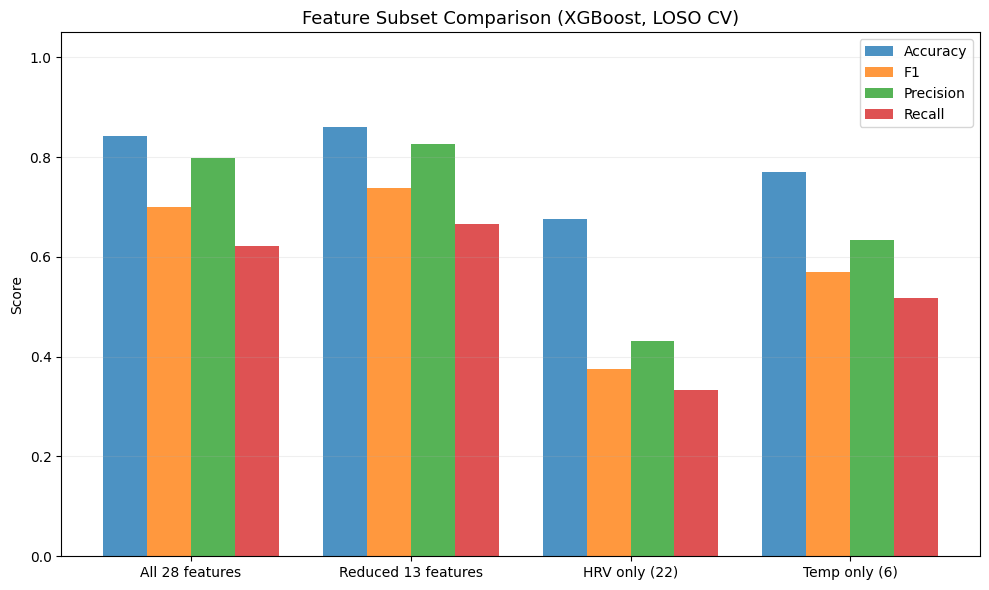


  Using reduced features for tuning...

EXPERIMENT 2: HYPERPARAMETER TUNING

  --- Random Forest ---
    n=50, depth=5, leaf=2 → F1=0.6780, Acc=0.8041
    n=100, depth=10, leaf=2 → F1=0.7005, Acc=0.8325
    n=200, depth=None, leaf=1 → F1=0.6633, Acc=0.8273
    n=200, depth=8, leaf=3 → F1=0.6727, Acc=0.8144
    n=300, depth=10, leaf=2 → F1=0.6890, Acc=0.8325
    n=100, depth=5, leaf=5 → F1=0.6723, Acc=0.7990
  Best RF: F1=0.7005, params={'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 2, 'class_weight': 'balanced', 'random_state': 42}

  --- SVM ---
    kernel=rbf, C=0.1, gamma=scale → F1=0.6540, Acc=0.7655
    kernel=rbf, C=1.0, gamma=scale → F1=0.7410, Acc=0.8325
    kernel=rbf, C=10.0, gamma=scale → F1=0.7725, Acc=0.8634
    kernel=rbf, C=1.0, gamma=auto → F1=0.7410, Acc=0.8325
    kernel=rbf, C=5.0, gamma=scale → F1=0.7782, Acc=0.8634
    kernel=linear, C=1.0, gamma=N/A → F1=0.6084, Acc=0.7345
    kernel=linear, C=0.1, gamma=N/A → F1=0.6197, Acc=0.7216
  Best SVM: F1=0.77

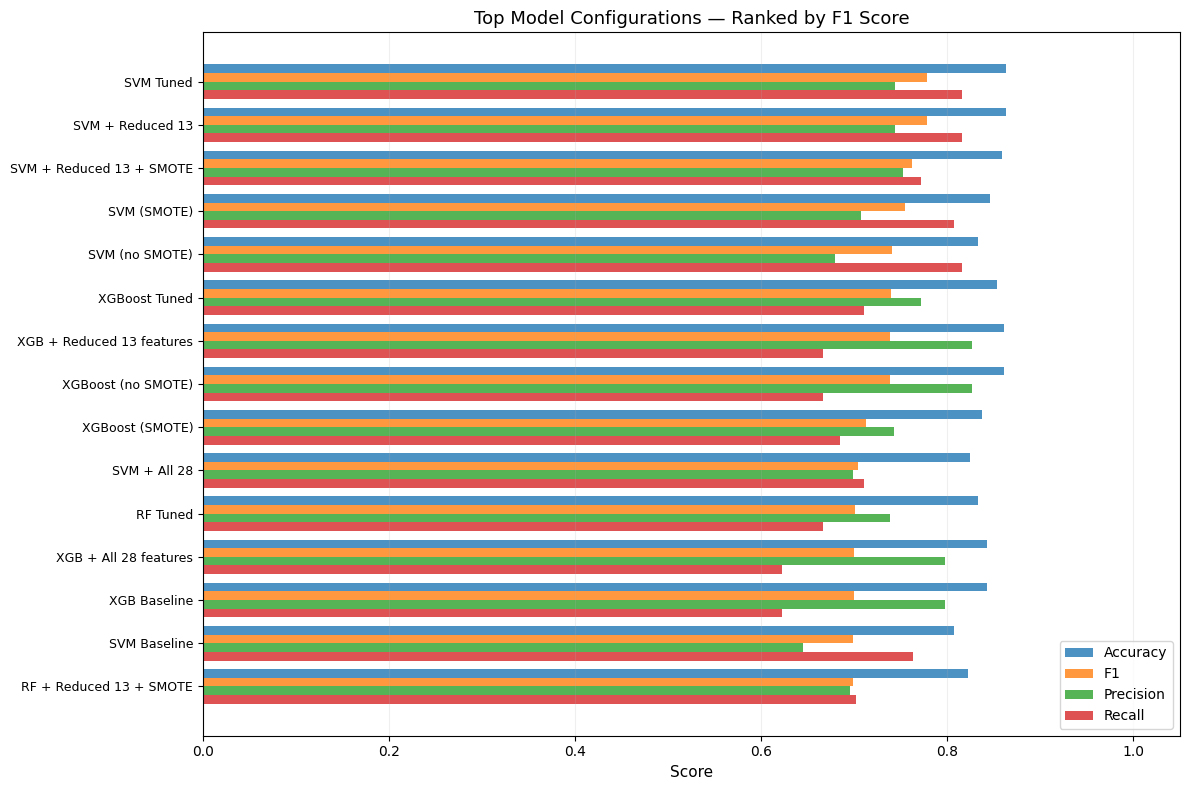


BEST CONFIGURATION: SVM Tuned
  Accuracy:  0.8634
  F1 Score:  0.7782
  Precision: 0.7440
  Recall:    0.8158


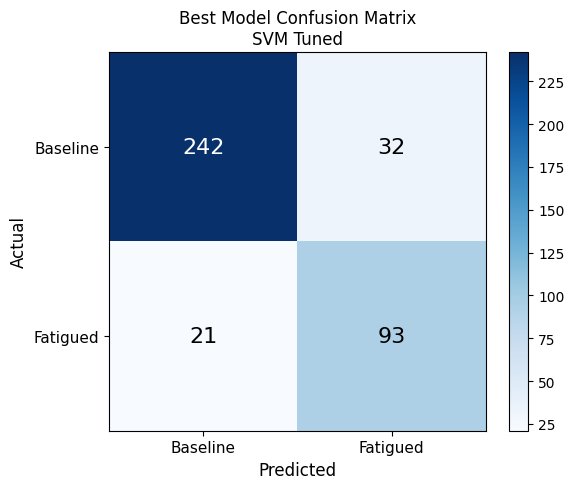


Per-participant results (SVM Tuned):
 PID | Accuracy |       F1 | Samples
-----------------------------------
P01  |    0.805 |    0.733 |      41
P02  |    0.897 |    0.800 |      29
P03  |    1.000 |    1.000 |      32
P04  |    0.943 |    0.917 |      35
P05  |    0.900 |    0.842 |      30
P06  |    0.939 |    0.917 |      33
P07  |    0.788 |    0.462 |      33
P08  |    0.917 |    0.500 |      24
P09  |    0.737 |    0.688 |      38
P10  |    0.929 |    0.833 |      28
P11  |    0.909 |    0.842 |      33
P12  |    0.656 |    0.593 |      32

BASELINE vs IMPROVED


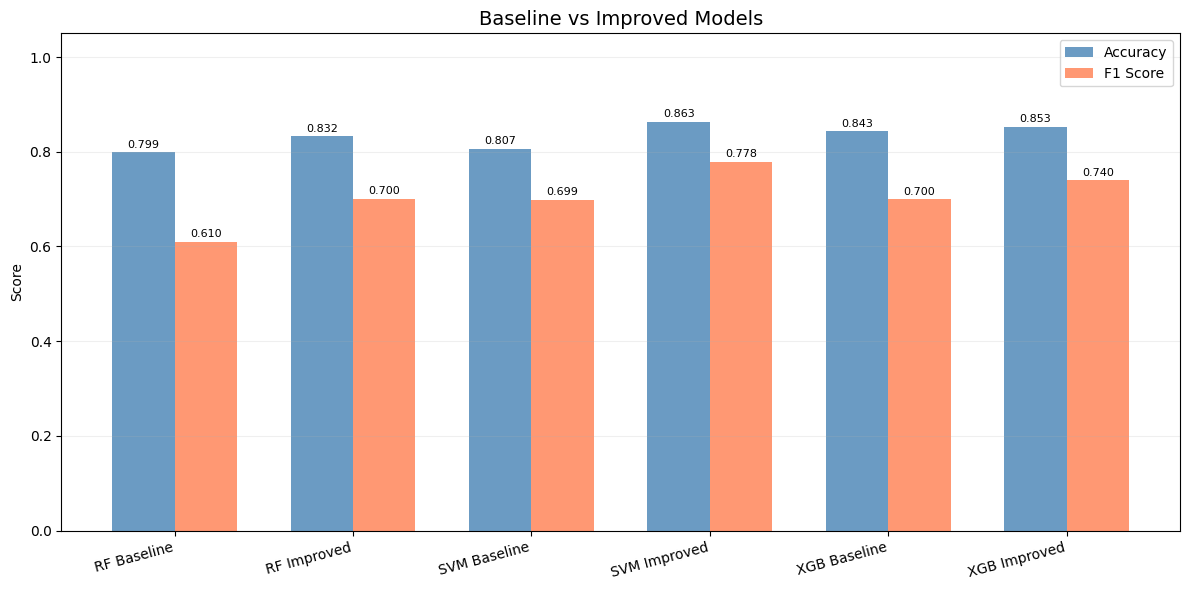


Saved comparison table to: model_comparison_results.csv


In [5]:
"""
MODEL IMPROVEMENT PIPELINE

Based on ablation results, we:
1. Remove harmful/redundant features
2. Try different feature subsets (HRV only, Temp only, Reduced, All)
3. Hyperparameter tuning via GridSearch within LOSO
4. Handle class imbalance with SMOTE
5. Try ensemble stacking
6. Compare all improvements

"""

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    print("[WARNING] imbalanced-learn not installed. Run: pip install imbalanced-learn")
    print("          Skipping SMOTE experiments.")
    HAS_SMOTE = False


TRAINING_CSV = Path("training_dataset.csv")

ALL_FEATURES = [
    "mean_rr", "sdnn", "rmssd", "pnn50",
    "mean_hr", "min_hr", "max_hr", "sdhr",
    "range_rr", "cv_rr", "triangular_index",
    "vlf_power", "lf_power", "hf_power",
    "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
    "ln_vlf", "ln_lf", "ln_hf", "ln_total_power",
    "temp_mean", "temp_slope", "temp_std",
    "temp_range", "temp_min", "temp_change_from_baseline"
]

# Based on ablation: features that were consistently important (red bars)
# across multiple models
REDUCED_FEATURES = [
    # Temperature (top performers across all models)
    "temp_change_from_baseline",
    "temp_range",
    "temp_std",
    "temp_slope",
    "temp_min",
    # HRV (consistently important across models)
    "sdhr",
    "cv_rr",
    "triangular_index",
    "max_hr",
    "vlf_power",
    "mean_rr",
    "min_hr",
    "pnn50",
]

HRV_ONLY_FEATURES = [
    "mean_rr", "sdnn", "rmssd", "pnn50",
    "mean_hr", "min_hr", "max_hr", "sdhr",
    "range_rr", "cv_rr", "triangular_index",
    "vlf_power", "lf_power", "hf_power",
    "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
    "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
]

TEMP_ONLY_FEATURES = [
    "temp_mean", "temp_slope", "temp_std",
    "temp_range", "temp_min", "temp_change_from_baseline"
]


def load_data():
    df = pd.read_csv(TRAINING_CSV)
    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
    df = df.dropna(subset=ALL_FEATURES)

    X_all = df[ALL_FEATURES].values
    y = df["label"].values
    participants = df["participant"].values

    print(f"Data: {len(df)} windows, {(y==0).sum()} baseline, {(y==1).sum()} fatigued")
    return df, X_all, y, participants



# LOSO CV (improved version with AUC)
def loso_cv(model_class, model_params, X, y, participants,
            scale=False, use_smote=False):
    unique_pids = sorted(set(participants))
    all_preds = []
    all_true = []
    all_proba = []
    per_participant = {}

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        # Scale
        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        # SMOTE oversampling on training data only
        if use_smote and HAS_SMOTE:
            try:
                sm = SMOTE(random_state=42)
                X_train, y_train = sm.fit_resample(X_train, y_train)
            except:
                pass  # Skip if SMOTE fails (too few samples)

        # Train
        model = model_class(**model_params)
        model.fit(X_train, y_train)

        # Predict
        y_pred = model.predict(X_test)
        all_preds.extend(y_pred)
        all_true.extend(y_test)

        # Probability for AUC (if available)
        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test)[:, 1]
            all_proba.extend(y_prob)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1, "n_samples": len(y_test)}

    all_preds = np.array(all_preds)
    all_true = np.array(all_true)

    results = {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "confusion_matrix": confusion_matrix(all_true, all_preds),
        "per_participant": per_participant,
        "y_true": all_true,
        "y_pred": all_preds,
    }

    if all_proba:
        results["auc"] = roc_auc_score(all_true, np.array(all_proba))
    else:
        results["auc"] = np.nan

    return results


# EXPERIMENT 1: Feature subset comparison
def experiment_feature_subsets(df, y, participants):
    print("\n" + "=" * 70)
    print("EXPERIMENT 1: FEATURE SUBSET COMPARISON")
    print("=" * 70)

    subsets = {
        "All 28 features": ALL_FEATURES,
        "Reduced 13 features": REDUCED_FEATURES,
        "HRV only (22)": HRV_ONLY_FEATURES,
        "Temp only (6)": TEMP_ONLY_FEATURES,
    }

    # Use XGBoost (best model) for comparison
    if HAS_XGBOOST:
        model_class = XGBClassifier
        model_params = {"n_estimators": 100, "max_depth": 5, "learning_rate": 0.1,
                        "random_state": 42, "eval_metric": "logloss", "use_label_encoder": False}
        model_name = "XGBoost"
        scale = False
    else:
        model_class = RandomForestClassifier
        model_params = {"n_estimators": 100, "random_state": 42, "class_weight": "balanced"}
        model_name = "Random Forest"
        scale = False

    results = {}
    for name, feat_list in subsets.items():
        X = df[feat_list].values
        res = loso_cv(model_class, model_params, X, y, participants, scale=scale)
        results[name] = res
        print(f"\n  {name}:")
        print(f"    Accuracy: {res['accuracy']:.4f}  F1: {res['f1']:.4f}  "
              f"Precision: {res['precision']:.4f}  Recall: {res['recall']:.4f}")

    # Plot comparison
    fig, ax = plt.subplots(figsize=(10, 6))
    subset_names = list(results.keys())
    metrics = ["accuracy", "f1", "precision", "recall"]
    x = np.arange(len(subset_names))
    width = 0.2

    for i, metric in enumerate(metrics):
        values = [results[s][metric] for s in subset_names]
        ax.bar(x + i * width, values, width, label=metric.capitalize(), alpha=0.8)

    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(subset_names, fontsize=10)
    ax.set_ylabel("Score")
    ax.set_title(f"Feature Subset Comparison ({model_name}, LOSO CV)", fontsize=13)
    ax.legend()
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.2, axis="y")
    plt.tight_layout()
    plt.show()

    return results


# EXPERIMENT 2: Hyperparameter tuning

def experiment_hyperparameter_tuning(X, y, participants):
    print("\n" + "=" * 70)
    print("EXPERIMENT 2: HYPERPARAMETER TUNING")
    print("=" * 70)

    results = {}

    # Random Forest tuning 
    print("\n  --- Random Forest ---")
    best_rf_f1 = 0
    best_rf_params = {}
    rf_configs = [
        {"n_estimators": 50, "max_depth": 5, "min_samples_leaf": 2, "class_weight": "balanced", "random_state": 42},
        {"n_estimators": 100, "max_depth": 10, "min_samples_leaf": 2, "class_weight": "balanced", "random_state": 42},
        {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1, "class_weight": "balanced", "random_state": 42},
        {"n_estimators": 200, "max_depth": 8, "min_samples_leaf": 3, "class_weight": "balanced", "random_state": 42},
        {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 2, "class_weight": "balanced", "random_state": 42},
        {"n_estimators": 100, "max_depth": 5, "min_samples_leaf": 5, "class_weight": "balanced", "random_state": 42},
    ]

    for params in rf_configs:
        res = loso_cv(RandomForestClassifier, params, X, y, participants)
        if res["f1"] > best_rf_f1:
            best_rf_f1 = res["f1"]
            best_rf_params = params
            best_rf_res = res
        print(f"    n={params['n_estimators']}, depth={params['max_depth']}, "
              f"leaf={params['min_samples_leaf']} → F1={res['f1']:.4f}, Acc={res['accuracy']:.4f}")

    print(f"  Best RF: F1={best_rf_f1:.4f}, params={best_rf_params}")
    results["RF Tuned"] = best_rf_res

    # SVM tuning
    print("\n  --- SVM ---")
    best_svm_f1 = 0
    best_svm_params = {}
    svm_configs = [
        {"kernel": "rbf", "C": 0.1, "gamma": "scale", "class_weight": "balanced", "random_state": 42},
        {"kernel": "rbf", "C": 1.0, "gamma": "scale", "class_weight": "balanced", "random_state": 42},
        {"kernel": "rbf", "C": 10.0, "gamma": "scale", "class_weight": "balanced", "random_state": 42},
        {"kernel": "rbf", "C": 1.0, "gamma": "auto", "class_weight": "balanced", "random_state": 42},
        {"kernel": "rbf", "C": 5.0, "gamma": "scale", "class_weight": "balanced", "random_state": 42},
        {"kernel": "linear", "C": 1.0, "class_weight": "balanced", "random_state": 42},
        {"kernel": "linear", "C": 0.1, "class_weight": "balanced", "random_state": 42},
    ]

    for params in svm_configs:
        res = loso_cv(SVC, params, X, y, participants, scale=True)
        if res["f1"] > best_svm_f1:
            best_svm_f1 = res["f1"]
            best_svm_params = params
            best_svm_res = res
        print(f"    kernel={params['kernel']}, C={params.get('C')}, "
              f"gamma={params.get('gamma', 'N/A')} → F1={res['f1']:.4f}, Acc={res['accuracy']:.4f}")

    print(f"  Best SVM: F1={best_svm_f1:.4f}, params={best_svm_params}")
    results["SVM Tuned"] = best_svm_res

    # XGBoost tuning
    if HAS_XGBOOST:
        print("\n  --- XGBoost ---")
        best_xgb_f1 = 0
        best_xgb_params = {}
        xgb_configs = [
            {"n_estimators": 50, "max_depth": 3, "learning_rate": 0.1, "random_state": 42,
             "eval_metric": "logloss", "use_label_encoder": False, "scale_pos_weight": 2.0},
            {"n_estimators": 100, "max_depth": 5, "learning_rate": 0.1, "random_state": 42,
             "eval_metric": "logloss", "use_label_encoder": False, "scale_pos_weight": 2.0},
            {"n_estimators": 200, "max_depth": 3, "learning_rate": 0.05, "random_state": 42,
             "eval_metric": "logloss", "use_label_encoder": False, "scale_pos_weight": 2.0},
            {"n_estimators": 100, "max_depth": 4, "learning_rate": 0.1, "random_state": 42,
             "eval_metric": "logloss", "use_label_encoder": False, "scale_pos_weight": 2.5},
            {"n_estimators": 150, "max_depth": 5, "learning_rate": 0.05, "random_state": 42,
             "eval_metric": "logloss", "use_label_encoder": False, "scale_pos_weight": 2.0},
            {"n_estimators": 100, "max_depth": 3, "learning_rate": 0.1, "random_state": 42,
             "eval_metric": "logloss", "use_label_encoder": False,
             "reg_alpha": 0.1, "reg_lambda": 1.0, "scale_pos_weight": 2.0},
            {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05, "random_state": 42,
             "eval_metric": "logloss", "use_label_encoder": False,
             "subsample": 0.8, "colsample_bytree": 0.8, "scale_pos_weight": 2.0},
        ]

        for params in xgb_configs:
            res = loso_cv(XGBClassifier, params, X, y, participants)
            if res["f1"] > best_xgb_f1:
                best_xgb_f1 = res["f1"]
                best_xgb_params = params
                best_xgb_res = res
            print(f"    n={params['n_estimators']}, depth={params['max_depth']}, "
                  f"lr={params['learning_rate']}, spw={params.get('scale_pos_weight', 1.0)} "
                  f"→ F1={res['f1']:.4f}, Acc={res['accuracy']:.4f}")

        print(f"  Best XGBoost: F1={best_xgb_f1:.4f}")
        results["XGBoost Tuned"] = best_xgb_res

    # Logistic Regression tuning
    print("\n  --- Logistic Regression ---")
    best_lr_f1 = 0
    lr_configs = [
        {"C": 0.01, "max_iter": 1000, "class_weight": "balanced", "random_state": 42},
        {"C": 0.1, "max_iter": 1000, "class_weight": "balanced", "random_state": 42},
        {"C": 1.0, "max_iter": 1000, "class_weight": "balanced", "random_state": 42},
        {"C": 10.0, "max_iter": 1000, "class_weight": "balanced", "random_state": 42},
        {"C": 0.1, "max_iter": 1000, "class_weight": "balanced", "random_state": 42, "penalty": "l1", "solver": "liblinear"},
    ]

    for params in lr_configs:
        res = loso_cv(LogisticRegression, params, X, y, participants, scale=True)
        if res["f1"] > best_lr_f1:
            best_lr_f1 = res["f1"]
            best_lr_params = params
            best_lr_res = res
        print(f"    C={params['C']}, penalty={params.get('penalty', 'l2')} "
              f"→ F1={res['f1']:.4f}, Acc={res['accuracy']:.4f}")

    print(f"  Best LR: F1={best_lr_f1:.4f}")
    results["LR Tuned"] = best_lr_res

    return results


# EXPERIMENT 3: SMOTE oversampling

def experiment_smote(X, y, participants):
    print("\n" + "=" * 70)
    print("EXPERIMENT 3: SMOTE OVERSAMPLING")
    print("=" * 70)

    if not HAS_SMOTE:
        print("  [SKIP] imbalanced-learn not installed")
        return {}

    models = {
        "RF": (RandomForestClassifier, {"n_estimators": 100, "random_state": 42, "class_weight": "balanced"}, False),
        "SVM": (SVC, {"kernel": "rbf", "C": 1.0, "gamma": "scale", "class_weight": "balanced", "random_state": 42}, True),
    }

    if HAS_XGBOOST:
        models["XGBoost"] = (XGBClassifier, {"n_estimators": 100, "max_depth": 5, "learning_rate": 0.1,
                              "random_state": 42, "eval_metric": "logloss", "use_label_encoder": False}, False)

    results = {}
    for name, (cls, params, scale) in models.items():
        # Without SMOTE
        res_no = loso_cv(cls, params, X, y, participants, scale=scale, use_smote=False)
        # With SMOTE
        res_yes = loso_cv(cls, params, X, y, participants, scale=scale, use_smote=True)

        results[f"{name} (no SMOTE)"] = res_no
        results[f"{name} (SMOTE)"] = res_yes

        print(f"\n  {name}:")
        print(f"    Without SMOTE: F1={res_no['f1']:.4f}, Acc={res_no['accuracy']:.4f}, "
              f"Prec={res_no['precision']:.4f}, Rec={res_no['recall']:.4f}")
        print(f"    With SMOTE:    F1={res_yes['f1']:.4f}, Acc={res_yes['accuracy']:.4f}, "
              f"Prec={res_yes['precision']:.4f}, Rec={res_yes['recall']:.4f}")

        f1_change = res_yes["f1"] - res_no["f1"]
        print(f"    F1 change: {f1_change:+.4f} {'← improved' if f1_change > 0 else '← worse'}")

    return results


# EXPERIMENT 4: Tuned models on reduced features

def experiment_best_combination(df, y, participants, tuning_results):
    print("\n" + "=" * 70)
    print("EXPERIMENT 4: BEST MODELS × BEST FEATURES")
    print("=" * 70)

    feature_sets = {
        "All 28": ALL_FEATURES,
        "Reduced 13": REDUCED_FEATURES,
    }

    models = {
        "RF": (RandomForestClassifier,
               {"n_estimators": 200, "max_depth": 8, "min_samples_leaf": 3,
                "class_weight": "balanced", "random_state": 42}, False),
        "SVM": (SVC,
                {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                 "class_weight": "balanced", "random_state": 42}, True),
    }

    if HAS_XGBOOST:
        models["XGBoost"] = (XGBClassifier,
                              {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
                               "random_state": 42, "eval_metric": "logloss",
                               "use_label_encoder": False, "scale_pos_weight": 2.0,
                               "subsample": 0.8, "colsample_bytree": 0.8}, False)

    results = {}
    for feat_name, feat_list in feature_sets.items():
        X = df[feat_list].values
        for model_name, (cls, params, scale) in models.items():
            label = f"{model_name} + {feat_name}"

            # Without SMOTE
            res = loso_cv(cls, params, X, y, participants, scale=scale, use_smote=False)
            results[label] = res

            # With SMOTE if available
            if HAS_SMOTE:
                res_smote = loso_cv(cls, params, X, y, participants, scale=scale, use_smote=True)
                results[f"{label} + SMOTE"] = res_smote

            print(f"  {label}: F1={res['f1']:.4f}, Acc={res['accuracy']:.4f}")
            if HAS_SMOTE:
                print(f"  {label} + SMOTE: F1={res_smote['f1']:.4f}, Acc={res_smote['accuracy']:.4f}")

    return results



# FINAL COMPARISON: All experiments together
def final_comparison(all_results):
    print("\n" + "=" * 70)
    print("FINAL COMPARISON — ALL CONFIGURATIONS")
    print("=" * 70)

    # Collect all results
    rows = []
    for name, res in all_results.items():
        rows.append({
            "Configuration": name,
            "Accuracy": res["accuracy"],
            "F1": res["f1"],
            "Precision": res["precision"],
            "Recall": res["recall"],
        })

    comp_df = pd.DataFrame(rows).sort_values("F1", ascending=False)

    print(f"\n{'Configuration':<45} {'Accuracy':>10} {'F1':>10} {'Precision':>10} {'Recall':>10}")
    print("-" * 90)
    for _, row in comp_df.iterrows():
        print(f"{row['Configuration']:<45} {row['Accuracy']:>10.4f} {row['F1']:>10.4f} "
              f"{row['Precision']:>10.4f} {row['Recall']:>10.4f}")

    # Plot top configurations
    top_n = min(15, len(comp_df))
    top = comp_df.head(top_n)

    fig, ax = plt.subplots(figsize=(12, 8))
    x = np.arange(len(top))
    width = 0.2

    for i, metric in enumerate(["Accuracy", "F1", "Precision", "Recall"]):
        ax.barh(x + i * width, top[metric].values, width, label=metric, alpha=0.8)

    ax.set_yticks(x + width * 1.5)
    ax.set_yticklabels(top["Configuration"].values, fontsize=9)
    ax.set_xlabel("Score", fontsize=11)
    ax.set_title("Top Model Configurations — Ranked by F1 Score", fontsize=13)
    ax.legend(loc="lower right")
    ax.set_xlim(0, 1.05)
    ax.grid(True, alpha=0.2, axis="x")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

    # Best model details
    best_name = comp_df.iloc[0]["Configuration"]
    best_res = all_results[best_name]
    print(f"\n{'='*50}")
    print(f"BEST CONFIGURATION: {best_name}")
    print(f"{'='*50}")
    print(f"  Accuracy:  {best_res['accuracy']:.4f}")
    print(f"  F1 Score:  {best_res['f1']:.4f}")
    print(f"  Precision: {best_res['precision']:.4f}")
    print(f"  Recall:    {best_res['recall']:.4f}")

    # Confusion matrix for best
    cm = best_res["confusion_matrix"]
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues", aspect="auto")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Baseline", "Fatigued"], fontsize=11)
    ax.set_yticklabels(["Baseline", "Fatigued"], fontsize=11)
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("Actual", fontsize=12)
    ax.set_title(f"Best Model Confusion Matrix\n{best_name}", fontsize=12)

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")

    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

    # Per-participant for best
    if "per_participant" in best_res:
        print(f"\nPer-participant results ({best_name}):")
        print(f"{'PID':>4} | {'Accuracy':>8} | {'F1':>8} | {'Samples':>7}")
        print("-" * 35)
        per_p = best_res["per_participant"]
        for pid in sorted(per_p.keys()):
            p = per_p[pid]
            print(f"P{pid:02d}  | {p['accuracy']:>8.3f} | {p['f1']:>8.3f} | {p['n_samples']:>7}")

    return comp_df



# BASELINE vs IMPROVED COMPARISON

def plot_baseline_vs_improved(baseline_results, improved_results):
    """Compare original baseline models vs best improved versions."""
    print("\n" + "=" * 70)
    print("BASELINE vs IMPROVED")
    print("=" * 70)

    configs = {
        "RF Baseline": baseline_results.get("RF Baseline"),
        "RF Improved": improved_results.get("RF Tuned"),
        "SVM Baseline": baseline_results.get("SVM Baseline"),
        "SVM Improved": improved_results.get("SVM Tuned"),
    }

    if "XGB Baseline" in baseline_results:
        configs["XGB Baseline"] = baseline_results["XGB Baseline"]
    if "XGBoost Tuned" in improved_results:
        configs["XGB Improved"] = improved_results["XGBoost Tuned"]

    valid_configs = {k: v for k, v in configs.items() if v is not None}

    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(valid_configs))
    width = 0.35

    f1_scores = [v["f1"] for v in valid_configs.values()]
    acc_scores = [v["accuracy"] for v in valid_configs.values()]

    ax.bar(x - width/2, acc_scores, width, label="Accuracy", alpha=0.8, color="steelblue")
    ax.bar(x + width/2, f1_scores, width, label="F1 Score", alpha=0.8, color="coral")

    ax.set_xticks(x)
    ax.set_xticklabels(valid_configs.keys(), rotation=15, ha="right", fontsize=10)
    ax.set_ylabel("Score")
    ax.set_title("Baseline vs Improved Models", fontsize=14)
    ax.legend()
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.2, axis="y")

    # Add value labels
    for i, (acc, f1) in enumerate(zip(acc_scores, f1_scores)):
        ax.text(i - width/2, acc + 0.01, f"{acc:.3f}", ha="center", fontsize=8)
        ax.text(i + width/2, f1 + 0.01, f"{f1:.3f}", ha="center", fontsize=8)

    plt.tight_layout()
    plt.show()


# ============================================================
# RUN
# ============================================================
if __name__ == "__main__":

    print("=" * 70)
    print("MODEL IMPROVEMENT PIPELINE")
    print("=" * 70)

    # Load data
    df, X_all, y, participants = load_data()

    # Store all results for final comparison
    all_results = {}

    # --- Baseline models (original settings) ---
    print("\n--- Running baseline models ---")
    baseline_configs = {
        "RF Baseline": (RandomForestClassifier,
                        {"n_estimators": 100, "random_state": 42, "class_weight": "balanced"}, False),
        "SVM Baseline": (SVC,
                         {"kernel": "rbf", "C": 1.0, "gamma": "scale", "class_weight": "balanced", "random_state": 42}, True),
        "LR Baseline": (LogisticRegression,
                        {"max_iter": 1000, "class_weight": "balanced", "random_state": 42}, True),
    }
    if HAS_XGBOOST:
        baseline_configs["XGB Baseline"] = (XGBClassifier,
                                             {"n_estimators": 100, "max_depth": 5, "learning_rate": 0.1,
                                              "random_state": 42, "eval_metric": "logloss",
                                              "use_label_encoder": False}, False)

    baseline_results = {}
    for name, (cls, params, scale) in baseline_configs.items():
        res = loso_cv(cls, params, X_all, y, participants, scale=scale)
        baseline_results[name] = res
        all_results[name] = res
        print(f"  {name}: F1={res['f1']:.4f}, Acc={res['accuracy']:.4f}")

    # --- Experiment 1: Feature subsets ---
    subset_results = experiment_feature_subsets(df, y, participants)
    for name, res in subset_results.items():
        all_results[f"XGB + {name}"] = res

    # --- Experiment 2: Hyperparameter tuning ---
    X_reduced = df[REDUCED_FEATURES].values
    print("\n  Using reduced features for tuning...")
    tuning_results = experiment_hyperparameter_tuning(X_reduced, y, participants)
    for name, res in tuning_results.items():
        all_results[name] = res

    # --- Experiment 3: SMOTE ---
    smote_results = experiment_smote(X_reduced, y, participants)
    for name, res in smote_results.items():
        all_results[name] = res

    # --- Experiment 4: Best combinations ---
    combo_results = experiment_best_combination(df, y, participants, tuning_results)
    for name, res in combo_results.items():
        all_results[name] = res

    # --- Final comparison ---
    comp_df = final_comparison(all_results)

    # --- Baseline vs Improved ---
    plot_baseline_vs_improved(baseline_results, tuning_results)

    # Save comparison table
    comp_df.to_csv("model_comparison_results.csv", index=False)
    print(f"\nSaved comparison table to: model_comparison_results.csv")

MODEL IMPROVEMENTS — Part 2

IMPROVEMENT 1: PER-PARTICIPANT NORMALISATION

  --- Without normalisation ---
  SVM (original):     F1=0.7782, Acc=0.8634

  --- With normalisation ---
  SVM (normalised):   F1=0.6602, Acc=0.8196

  --- Normalise ALL 28 features ---
  SVM (norm all 28):  F1=0.6791, Acc=0.8222

  --- All models with normalised reduced features ---
  SVM          Original: F1=0.7782  Normalised: F1=0.6602  Change: -0.1180 ← worse
  RF           Original: F1=0.7005  Normalised: F1=0.6701  Change: -0.0304 ← worse
  XGBoost      Original: F1=0.6923  Normalised: F1=0.7273  Change: +0.0350 ← improved


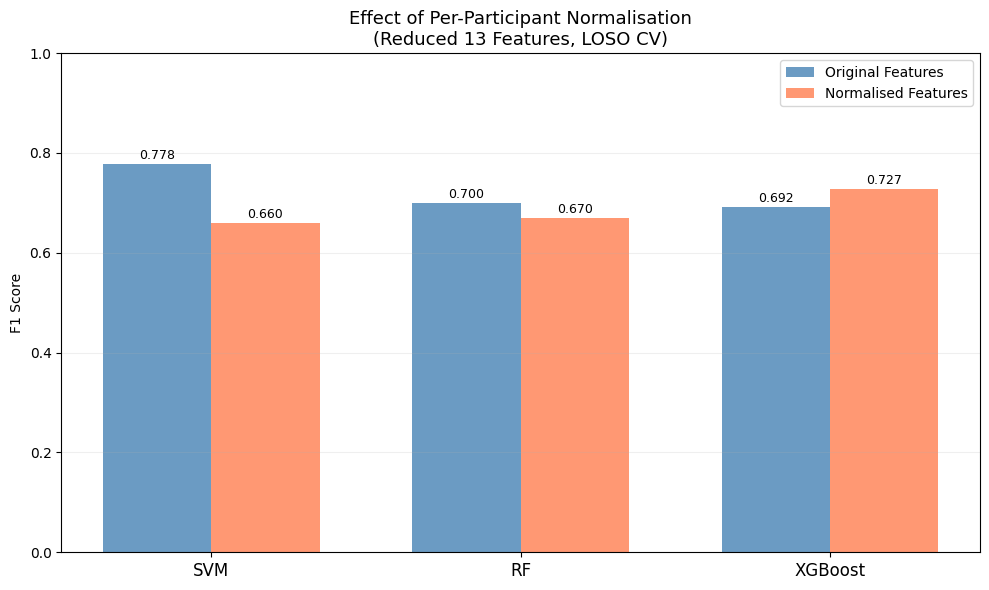


  Per-participant comparison (SVM):
   PID |  F1 Orig |  F1 Norm |   Change
  ----------------------------------------
  P01  |    0.733 |    0.774 |  +0.041 ↑
  P02  |    0.800 |    0.857 |  +0.057 ↑
  P03  |    1.000 |    0.632 |  -0.368 ↓
  P04  |    0.917 |    0.533 |  -0.383 ↓
  P05  |    0.842 |    0.667 |  -0.175 ↓
  P06  |    0.917 |    0.762 |  -0.155 ↓
  P07  |    0.462 |    0.000 |  -0.462 ↓
  P08  |    0.500 |    0.375 |  -0.125 ↓
  P09  |    0.688 |    0.667 |  -0.021 ↓
  P10  |    0.833 |    0.667 |  -0.167 ↓
  P11  |    0.842 |    0.880 |  +0.038 ↑
  P12  |    0.593 |    0.667 |  +0.074 ↑

[NOTE] Window size experiment will take several minutes...
  (Re-extracting features from raw data for each window size)

IMPROVEMENT 2: WINDOW SIZE COMPARISON

  --- Window size: 120s ---
  Extracting features...
  Windows: 413 (baseline=263, fatigued=150)
  SVM:     F1=0.6869, Acc=0.7748
  XGBoost: F1=0.7143, Acc=0.8063
  RF:      F1=0.6953, Acc=0.7942

  --- Window size: 180s ---
 

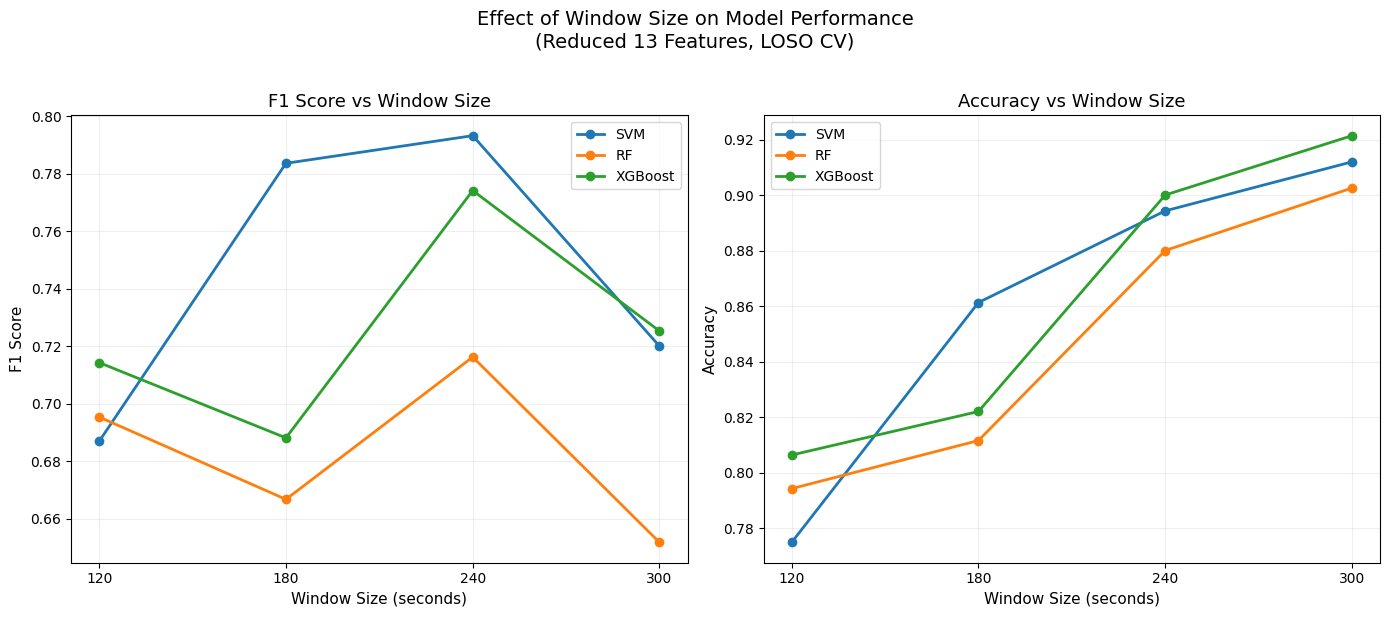

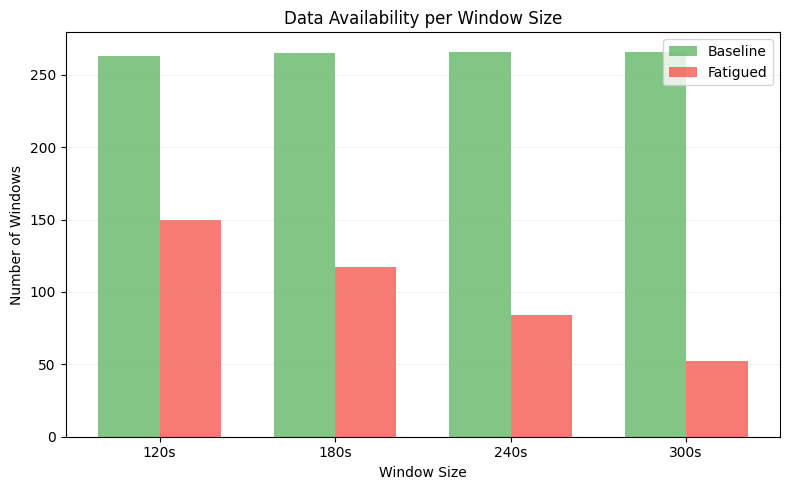


    Window | Model      |       F1 |      Acc |     Prec |      Rec |  Windows
  ---------------------------------------------------------------------------
     120s | SVM        |   0.6869 |   0.7748 |   0.6939 |   0.6800 |      413
     120s | RF         |   0.6953 |   0.7942 |   0.7519 |   0.6467 |      413
     120s | XGBoost    |   0.7143 |   0.8063 |   0.7692 |   0.6667 |      413
     180s | SVM        |   0.7837 |   0.8613 |   0.7500 |   0.8205 |      382
     180s | RF         |   0.6667 |   0.8115 |   0.7273 |   0.6154 |      382
     180s | XGBoost    |   0.6881 |   0.8220 |   0.7426 |   0.6410 |      382
     240s | SVM        |   0.7933 |   0.8943 |   0.7474 |   0.8452 |      350
     240s | RF         |   0.7162 |   0.8800 |   0.8281 |   0.6310 |      350
     240s | XGBoost    |   0.7742 |   0.9000 |   0.8451 |   0.7143 |      350
     300s | SVM        |   0.7200 |   0.9119 |   0.7500 |   0.6923 |      318
     300s | RF         |   0.6517 |   0.9025 |   0.7838 |   0.

In [6]:
"""
MODEL IMPROVEMENTS — Part 2
Improvement 1: Per-participant normalisation
  - Subtract each participant's baseline mean from all their features
  - Like temp_change_from_baseline but for ALL features

Improvement 2: Different window sizes (120s, 180s, 240s, 300s)
  - Re-extract features from raw RR intervals for each window size
  - Compare performance across window sizes
"""

from pathlib import Path
import pandas as pd
import numpy as np
from scipy.signal import welch
from scipy.interpolate import interp1d
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False


DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]

TRAINING_CSV = Path("training_dataset.csv")

REDUCED_FEATURES = [
    "temp_change_from_baseline", "temp_range", "temp_std",
    "temp_slope", "temp_min",
    "sdhr", "cv_rr", "triangular_index", "max_hr",
    "vlf_power", "mean_rr", "min_hr", "pnn50",
]

ALL_FEATURES = [
    "mean_rr", "sdnn", "rmssd", "pnn50",
    "mean_hr", "min_hr", "max_hr", "sdhr",
    "range_rr", "cv_rr", "triangular_index",
    "vlf_power", "lf_power", "hf_power",
    "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
    "ln_vlf", "ln_lf", "ln_hf", "ln_total_power",
    "temp_mean", "temp_slope", "temp_std",
    "temp_range", "temp_min", "temp_change_from_baseline"
]

MAX_RR_MS = 2000
MIN_RR_MS = 300
MAX_RR_DIFF_MS = 300
MIN_RR_IN_WINDOW = 100


def loso_cv(model_class, model_params, X, y, participants, scale=False):
    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []
    per_participant = {}

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        model = model_class(**model_params)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        all_preds.extend(y_pred)
        all_true.extend(y_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1, "n_samples": len(y_test)}

    all_preds = np.array(all_preds)
    all_true = np.array(all_true)

    return {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "confusion_matrix": confusion_matrix(all_true, all_preds),
        "per_participant": per_participant,
    }



# IMPROVEMENT 1: PER-PARTICIPANT NORMALISATION
"""
For each participant, subtract their baseline mean from ALL windows.
This removes individual differences and focuses on change from baseline.

Example:
    P01 baseline RMSSD mean = 42ms
    P01 window during fatigue: RMSSD = 28ms
    Normalised: 28 - 42 = -14  (dropped 14ms from baseline)

    P06 baseline RMSSD mean = 50ms
    P06 window during fatigue: RMSSD = 36ms
    Normalised: 36 - 50 = -14  (also dropped 14ms from baseline)

Now both participants show the same signal (-14) even though
their absolute values were very different.
"""
def apply_normalisation(df, feature_cols):
    df_norm = df.copy()
    norm_feature_cols = []

    for feat in feature_cols:
        norm_col = f"{feat}_norm"
        norm_feature_cols.append(norm_col)

        # For each participant, compute baseline mean
        for pid in df_norm["participant"].unique():
            pid_mask = df_norm["participant"] == pid
            baseline_mask = pid_mask & (df_norm["phase"] == "baseline")

            baseline_mean = df_norm.loc[baseline_mask, feat].mean()

            # Subtract baseline mean from ALL windows for this participant
            df_norm.loc[pid_mask, norm_col] = df_norm.loc[pid_mask, feat] - baseline_mean

    return df_norm, norm_feature_cols


def experiment_normalisation():
    print("\n" + "=" * 70)
    print("IMPROVEMENT 1: PER-PARTICIPANT NORMALISATION")
    print("=" * 70)

    # Load data
    df = pd.read_csv(TRAINING_CSV)
    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
    df = df.dropna(subset=ALL_FEATURES)

    y = df["label"].values
    participants = df["participant"].values

    print("\n  --- Without normalisation ---")
    X_orig = df[REDUCED_FEATURES].values

    svm_orig = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                              "class_weight": "balanced", "random_state": 42},
                       X_orig, y, participants, scale=True)
    print(f"  SVM (original):     F1={svm_orig['f1']:.4f}, Acc={svm_orig['accuracy']:.4f}")

    print("\n  --- With normalisation ---")

    # Normalise the reduced features (except temp_change_from_baseline which is already normalised)
    features_to_normalise = [f for f in REDUCED_FEATURES if f != "temp_change_from_baseline"]
    df_norm, norm_cols = apply_normalisation(df, features_to_normalise)

    # Use normalised features + temp_change_from_baseline (already normalised)
    norm_reduced = norm_cols + ["temp_change_from_baseline"]
    X_norm = df_norm[norm_reduced].values

    svm_norm = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                              "class_weight": "balanced", "random_state": 42},
                       X_norm, y, participants, scale=True)
    print(f"  SVM (normalised):   F1={svm_norm['f1']:.4f}, Acc={svm_norm['accuracy']:.4f}")

    print("\n  --- Normalise ALL 28 features ---")
    features_to_norm_all = [f for f in ALL_FEATURES if f != "temp_change_from_baseline"]
    df_norm_all, norm_cols_all = apply_normalisation(df, features_to_norm_all)

    norm_all = norm_cols_all + ["temp_change_from_baseline"]
    X_norm_all = df_norm_all[norm_all].values

    svm_norm_all = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                                  "class_weight": "balanced", "random_state": 42},
                           X_norm_all, y, participants, scale=True)
    print(f"  SVM (norm all 28):  F1={svm_norm_all['f1']:.4f}, Acc={svm_norm_all['accuracy']:.4f}")

    print("\n  --- All models with normalised reduced features ---")

    models = {
        "SVM": (SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                       "class_weight": "balanced", "random_state": 42}, True),
        "RF": (RandomForestClassifier, {"n_estimators": 100, "max_depth": 10,
                "min_samples_leaf": 2, "class_weight": "balanced", "random_state": 42}, False),
    }

    if HAS_XGBOOST:
        models["XGBoost"] = (XGBClassifier, {"n_estimators": 200, "max_depth": 4,
                              "learning_rate": 0.05, "random_state": 42,
                              "eval_metric": "logloss", "use_label_encoder": False,
                              "scale_pos_weight": 2.0, "subsample": 0.8,
                              "colsample_bytree": 0.8}, False)

    norm_results = {}
    orig_results = {}

    for name, (cls, params, scale) in models.items():
        # Original
        res_orig = loso_cv(cls, params, X_orig, y, participants, scale=scale)
        orig_results[name] = res_orig

        # Normalised reduced
        res_norm = loso_cv(cls, params, X_norm, y, participants, scale=scale)
        norm_results[name] = res_norm

        f1_change = res_norm["f1"] - res_orig["f1"]
        print(f"  {name:<12} Original: F1={res_orig['f1']:.4f}  Normalised: F1={res_norm['f1']:.4f}  "
              f"Change: {f1_change:+.4f} {'← improved' if f1_change > 0 else '← worse' if f1_change < 0 else ''}")

    # --- Plot comparison ---
    fig, ax = plt.subplots(figsize=(10, 6))
    model_names = list(models.keys())
    x = np.arange(len(model_names))
    width = 0.35

    orig_f1 = [orig_results[m]["f1"] for m in model_names]
    norm_f1 = [norm_results[m]["f1"] for m in model_names]

    bars1 = ax.bar(x - width/2, orig_f1, width, label="Original Features", alpha=0.8, color="steelblue")
    bars2 = ax.bar(x + width/2, norm_f1, width, label="Normalised Features", alpha=0.8, color="coral")

    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=12)
    ax.set_ylabel("F1 Score")
    ax.set_title("Effect of Per-Participant Normalisation\n(Reduced 13 Features, LOSO CV)", fontsize=13)
    ax.legend()
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.2, axis="y")

    for bar in bars1:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{bar.get_height():.3f}", ha="center", fontsize=9)
    for bar in bars2:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{bar.get_height():.3f}", ha="center", fontsize=9)

    plt.tight_layout()
    plt.show()

    # Per-participant comparison for best model
    best_orig = svm_orig
    best_norm = svm_norm

    print(f"\n  Per-participant comparison (SVM):")
    print(f"  {'PID':>4} | {'F1 Orig':>8} | {'F1 Norm':>8} | {'Change':>8}")
    print(f"  {'-'*40}")

    for pid in sorted(best_orig["per_participant"].keys()):
        f1_o = best_orig["per_participant"][pid]["f1"]
        f1_n = best_norm["per_participant"].get(pid, {}).get("f1", np.nan)
        change = f1_n - f1_o if not np.isnan(f1_n) else np.nan
        symbol = "↑" if change > 0.01 else ("↓" if change < -0.01 else "→")
        print(f"  P{pid:02d}  | {f1_o:>8.3f} | {f1_n:>8.3f} | {change:>+7.3f} {symbol}")

    return norm_results, df_norm, norm_reduced


# IMPROVEMENT 2: DIFFERENT WINDOW SIZES

def load_rr_intervals(pid, sid):
    rr_file = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "chest_rr_interval.csv"
    if not rr_file.exists():
        return pd.DataFrame(columns=["timestamp", "rr_ms", "participant", "session"])
    df = pd.read_csv(rr_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df = df.rename(columns={"duration": "rr_ms"})
    df["participant"] = pid
    df["session"] = sid
    df = df.dropna(subset=["rr_ms"])
    return df[["timestamp", "rr_ms", "participant", "session"]].sort_values("timestamp").reset_index(drop=True)


def load_skin_temp(pid, sid):
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    temp_file = session_dir / "wrist_skin_temperature.csv"
    if pid == 2 and sid == 1:
        temp_file = session_dir / "wrist_skin_temperature2.csv"
    if not temp_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(temp_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    if "temperature" in df.columns:
        df = df.rename(columns={"temperature": "skin_temp"})
    elif "temp" in df.columns:
        df = df.rename(columns={"temp": "skin_temp"})
    df = (df.set_index("timestamp").sort_index().resample("1s")
            .mean(numeric_only=True).dropna(subset=["skin_temp"]).reset_index())
    df["participant"] = pid
    df["session"] = sid
    return df


def clean_rr_intervals(rr):
    mask = (rr >= MIN_RR_MS) & (rr <= MAX_RR_MS)
    rr = rr[mask]
    if len(rr) < 3:
        return rr
    diffs = np.abs(np.diff(rr))
    keep = np.ones(len(rr), dtype=bool)
    for i in range(len(diffs)):
        if diffs[i] > MAX_RR_DIFF_MS:
            keep[i + 1] = False
    return rr[keep]


def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events


def compute_hrv_features(rr_raw):
    rr = clean_rr_intervals(rr_raw)
    if len(rr) < MIN_RR_IN_WINDOW:
        return {f: np.nan for f in [
            "mean_rr", "sdnn", "rmssd", "pnn50", "mean_hr", "min_hr", "max_hr",
            "sdhr", "range_rr", "cv_rr", "triangular_index",
            "vlf_power", "lf_power", "hf_power", "total_power",
            "lf_hf_ratio", "lf_norm", "hf_norm",
            "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
        ]}

    diffs = np.diff(rr)
    mean_rr = np.mean(rr)
    sdnn = np.std(rr, ddof=1)
    rmssd = np.sqrt(np.mean(diffs ** 2))
    pnn50 = (np.sum(np.abs(diffs) > 50) / len(diffs)) * 100.0
    hr = 60000.0 / rr
    mean_hr, min_hr, max_hr, sdhr = np.mean(hr), np.min(hr), np.max(hr), np.std(hr, ddof=1)
    range_rr = np.max(rr) - np.min(rr)
    cv_rr = sdnn / mean_rr if mean_rr > 0 else np.nan

    bin_width = 1000.0 / 128.0
    if range_rr > 0:
        n_bins = max(int(range_rr / bin_width), 1)
        hc, _ = np.histogram(rr, bins=n_bins)
        triangular_index = len(rr) / np.max(hc) if np.max(hc) > 0 else np.nan
    else:
        triangular_index = np.nan

    # Frequency domain
    def safe_ln(x):
        return np.log(x) if (x is not None and x > 0) else np.nan

    vlf, lf, hf = np.nan, np.nan, np.nan
    if len(rr) >= 30:
        t_s = np.cumsum(rr) / 1000.0
        t_s = t_s - t_s[0]
        fs = 4.0
        t_u = np.arange(t_s[0], t_s[-1], 1.0 / fs)
        if len(t_u) >= 64:
            try:
                fn = interp1d(t_s, rr, kind="cubic", fill_value="extrapolate")
                rr_u = fn(t_u) - np.mean(fn(t_u))
                nperseg = min(len(rr_u), 256)
                freqs, psd = welch(rr_u, fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
                vlf = float(np.trapz(psd[(freqs >= 0.003) & (freqs < 0.04)],
                                     freqs[(freqs >= 0.003) & (freqs < 0.04)])) if ((freqs >= 0.003) & (freqs < 0.04)).any() else np.nan
                lf = float(np.trapz(psd[(freqs >= 0.04) & (freqs < 0.15)],
                                    freqs[(freqs >= 0.04) & (freqs < 0.15)])) if ((freqs >= 0.04) & (freqs < 0.15)).any() else np.nan
                hf = float(np.trapz(psd[(freqs >= 0.15) & (freqs < 0.40)],
                                    freqs[(freqs >= 0.15) & (freqs < 0.40)])) if ((freqs >= 0.15) & (freqs < 0.40)).any() else np.nan
            except:
                pass

    total = (vlf or 0) + (lf or 0) + (hf or 0) if not (np.isnan(vlf) and np.isnan(lf) and np.isnan(hf)) else np.nan
    lf_hf = lf / hf if (hf and hf > 0) else np.nan
    lf_norm = (lf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan
    hf_norm = (hf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan

    return {
        "mean_rr": mean_rr, "sdnn": sdnn, "rmssd": rmssd, "pnn50": pnn50,
        "mean_hr": mean_hr, "min_hr": min_hr, "max_hr": max_hr, "sdhr": sdhr,
        "range_rr": range_rr, "cv_rr": cv_rr, "triangular_index": triangular_index,
        "vlf_power": vlf, "lf_power": lf, "hf_power": hf, "total_power": total,
        "lf_hf_ratio": lf_hf, "lf_norm": lf_norm, "hf_norm": hf_norm,
        "ln_vlf": safe_ln(vlf), "ln_lf": safe_ln(lf), "ln_hf": safe_ln(hf),
        "ln_total_power": safe_ln(total),
    }


def compute_temp_features(temp_vals):
    temp = temp_vals[np.isfinite(temp_vals)]
    if len(temp) < 10:
        return {"temp_mean": np.nan, "temp_slope": np.nan, "temp_std": np.nan,
                "temp_range": np.nan, "temp_min": np.nan}
    x = np.arange(len(temp))
    try:
        coeffs = np.polyfit(x, temp, 1)
        slope = coeffs[0]
    except:
        slope = np.nan
    return {
        "temp_mean": np.mean(temp), "temp_slope": slope,
        "temp_std": np.std(temp, ddof=1), "temp_range": np.max(temp) - np.min(temp),
        "temp_min": np.min(temp),
    }


"""Full pipeline: extract HRV+temp features, label, for a given window size."""
def build_dataset_for_window_size(window_sec, step_sec=60):
    
    all_rows = []

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            df_rr = load_rr_intervals(pid, sid)
            df_temp = load_skin_temp(pid, sid)
            markers = load_markers(pid, sid)

            if df_rr.empty or not markers:
                continue

            baseline_start = markers.get("start_baseline")
            exercise_start = markers.get("start_activity")
            cognitive_start = markers.get("start_fatigue")

            t_start = df_rr["timestamp"].iloc[0]
            t_end = df_rr["timestamp"].iloc[-1]
            win_id = 0
            w_start = t_start

            while w_start + pd.Timedelta(seconds=window_sec) <= t_end:
                w_end = w_start + pd.Timedelta(seconds=window_sec)

                # HRV features
                rr_mask = (df_rr["timestamp"] >= w_start) & (df_rr["timestamp"] < w_end)
                rr_vals = df_rr.loc[rr_mask, "rr_ms"].to_numpy(dtype=float)
                hrv_feats = compute_hrv_features(rr_vals)

                # Temp features
                if not df_temp.empty:
                    temp_mask = (df_temp["timestamp"] >= w_start) & (df_temp["timestamp"] < w_end)
                    temp_vals = df_temp.loc[temp_mask, "skin_temp"].to_numpy(dtype=float)
                    temp_feats = compute_temp_features(temp_vals)
                else:
                    temp_feats = {"temp_mean": np.nan, "temp_slope": np.nan,
                                  "temp_std": np.nan, "temp_range": np.nan, "temp_min": np.nan}

                # Label
                if cognitive_start and w_start >= cognitive_start:
                    phase = "fatigued"
                    label = 1
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    phase = "baseline"
                    label = 0
                else:
                    phase = "excluded"
                    label = -1

                row = {**hrv_feats, **temp_feats,
                       "participant": pid, "session": sid, "window_id": win_id,
                       "window_start": w_start, "window_end": w_end,
                       "phase": phase, "label": label}
                all_rows.append(row)
                win_id += 1
                w_start += pd.Timedelta(seconds=step_sec)

    df = pd.DataFrame(all_rows)

    # Add temp_change_from_baseline
    if not df.empty:
        df["temp_change_from_baseline"] = df.groupby(["participant", "session"])["temp_mean"].transform(
            lambda s: s - s.iloc[0]
        )

    return df


def experiment_window_sizes():
    print("\n" + "=" * 70)
    print("IMPROVEMENT 2: WINDOW SIZE COMPARISON")
    print("=" * 70)

    window_sizes = [120, 180, 240, 300]
    step_sec = 60  # Keep step constant

    all_results = {}

    for ws in window_sizes:
        print(f"\n  --- Window size: {ws}s ---")

        # Build dataset
        print(f"  Extracting features...")
        df = build_dataset_for_window_size(ws, step_sec)

        # Filter to labelled only
        df_train = df[df["label"] >= 0].copy()
        df_train = df_train.dropna(subset=REDUCED_FEATURES)

        n_baseline = (df_train["label"] == 0).sum()
        n_fatigued = (df_train["label"] == 1).sum()
        print(f"  Windows: {len(df_train)} (baseline={n_baseline}, fatigued={n_fatigued})")

        if n_fatigued < 10 or n_baseline < 10:
            print(f"  [SKIP] Too few windows")
            continue

        X = df_train[REDUCED_FEATURES].values
        y = df_train["label"].values
        participants = df_train["participant"].values

        # Run best model (SVM)
        res_svm = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                                 "class_weight": "balanced", "random_state": 42},
                          X, y, participants, scale=True)

        # Also run XGBoost
        if HAS_XGBOOST:
            res_xgb = loso_cv(XGBClassifier, {"n_estimators": 200, "max_depth": 4,
                               "learning_rate": 0.05, "random_state": 42,
                               "eval_metric": "logloss", "use_label_encoder": False,
                               "scale_pos_weight": 2.0}, X, y, participants)
        else:
            res_xgb = {"f1": 0, "accuracy": 0, "precision": 0, "recall": 0}

        # Also RF
        res_rf = loso_cv(RandomForestClassifier, {"n_estimators": 100, "max_depth": 10,
                          "min_samples_leaf": 2, "class_weight": "balanced", "random_state": 42},
                         X, y, participants)

        all_results[ws] = {
            "SVM": res_svm,
            "XGBoost": res_xgb if HAS_XGBOOST else None,
            "RF": res_rf,
            "n_windows": len(df_train),
            "n_baseline": n_baseline,
            "n_fatigued": n_fatigued,
        }

        print(f"  SVM:     F1={res_svm['f1']:.4f}, Acc={res_svm['accuracy']:.4f}")
        if HAS_XGBOOST:
            print(f"  XGBoost: F1={res_xgb['f1']:.4f}, Acc={res_xgb['accuracy']:.4f}")
        print(f"  RF:      F1={res_rf['f1']:.4f}, Acc={res_rf['accuracy']:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    valid_ws = sorted(all_results.keys())

    # Plot F1 scores
    ax = axes[0]
    for model_name in ["SVM", "RF"] + (["XGBoost"] if HAS_XGBOOST else []):
        f1_scores = []
        for ws in valid_ws:
            res = all_results[ws].get(model_name)
            f1_scores.append(res["f1"] if res else 0)
        ax.plot(valid_ws, f1_scores, marker="o", linewidth=2, label=model_name)

    ax.set_xlabel("Window Size (seconds)", fontsize=11)
    ax.set_ylabel("F1 Score", fontsize=11)
    ax.set_title("F1 Score vs Window Size", fontsize=13)
    ax.legend()
    ax.grid(True, alpha=0.2)
    ax.set_xticks(valid_ws)

    # Plot accuracy
    ax = axes[1]
    for model_name in ["SVM", "RF"] + (["XGBoost"] if HAS_XGBOOST else []):
        acc_scores = []
        for ws in valid_ws:
            res = all_results[ws].get(model_name)
            acc_scores.append(res["accuracy"] if res else 0)
        ax.plot(valid_ws, acc_scores, marker="o", linewidth=2, label=model_name)

    ax.set_xlabel("Window Size (seconds)", fontsize=11)
    ax.set_ylabel("Accuracy", fontsize=11)
    ax.set_title("Accuracy vs Window Size", fontsize=13)
    ax.legend()
    ax.grid(True, alpha=0.2)
    ax.set_xticks(valid_ws)

    fig.suptitle("Effect of Window Size on Model Performance\n(Reduced 13 Features, LOSO CV)", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    # Data availability per window size
    fig, ax = plt.subplots(figsize=(8, 5))
    n_windows = [all_results[ws]["n_windows"] for ws in valid_ws]
    n_baseline = [all_results[ws]["n_baseline"] for ws in valid_ws]
    n_fatigued = [all_results[ws]["n_fatigued"] for ws in valid_ws]

    x = np.arange(len(valid_ws))
    width = 0.35
    ax.bar(x - width/2, n_baseline, width, label="Baseline", color="#4CAF50", alpha=0.7)
    ax.bar(x + width/2, n_fatigued, width, label="Fatigued", color="#F44336", alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{ws}s" for ws in valid_ws])
    ax.set_xlabel("Window Size")
    ax.set_ylabel("Number of Windows")
    ax.set_title("Data Availability per Window Size")
    ax.legend()
    ax.grid(True, alpha=0.2, axis="y")
    plt.tight_layout()
    plt.show()

    # Summary table
    print(f"\n  {'Window':>8} | {'Model':<10} | {'F1':>8} | {'Acc':>8} | {'Prec':>8} | {'Rec':>8} | {'Windows':>8}")
    print(f"  {'-'*75}")
    for ws in valid_ws:
        for model_name in ["SVM", "RF"] + (["XGBoost"] if HAS_XGBOOST else []):
            res = all_results[ws].get(model_name)
            if res:
                print(f"  {ws:>6}s | {model_name:<10} | {res['f1']:>8.4f} | {res['accuracy']:>8.4f} | "
                      f"{res['precision']:>8.4f} | {res['recall']:>8.4f} | {all_results[ws]['n_windows']:>8}")

    return all_results


# RUN EVERYTHING
if __name__ == "__main__":

    print("=" * 70)
    print("MODEL IMPROVEMENTS — Part 2")
    print("=" * 70)

    # Improvement 1: Per-participant normalisation
    norm_results, df_norm, norm_features = experiment_normalisation()

    # Improvement 2: Window size comparison
    print("\n[NOTE] Window size experiment will take several minutes...")
    print("  (Re-extracting features from raw data for each window size)")
    ws_results = experiment_window_sizes()

EXPERIMENT: EXPANDED LABELLING
Loaded: combined_all_windows.csv (675 windows)

STRATEGY A: Baseline vs Fatigued (current)
  Not fatigued: 274 (baseline only)
  Fatigued:     114
  Total:        388
  Ratio:        2.4 : 1

STRATEGY B: Baseline+Exercise+Recovery vs Fatigued
  Not fatigued: 531 (baseline + exercise + recovery)
  Fatigued:     114
  Total:        645
  Ratio:        4.7 : 1

  Per-participant (Strategy B):
   PID |  Not Fat | Fatigued |  Total
  ----------------------------------------
  P01  |       45 |       19 |     64
  P02  |       44 |        6 |     50
  P03  |       40 |       10 |     50
  P04  |       50 |       11 |     61
  P05  |       47 |        8 |     55
  P06  |       40 |       11 |     51
  P07  |       48 |       10 |     58
  P08  |       40 |        3 |     43
  P09  |       46 |       12 |     58
  P10  |       40 |        5 |     45
  P11  |       45 |       11 |     56
  P12  |       46 |        8 |     54

RESULTS

  Model        |     --- Stra

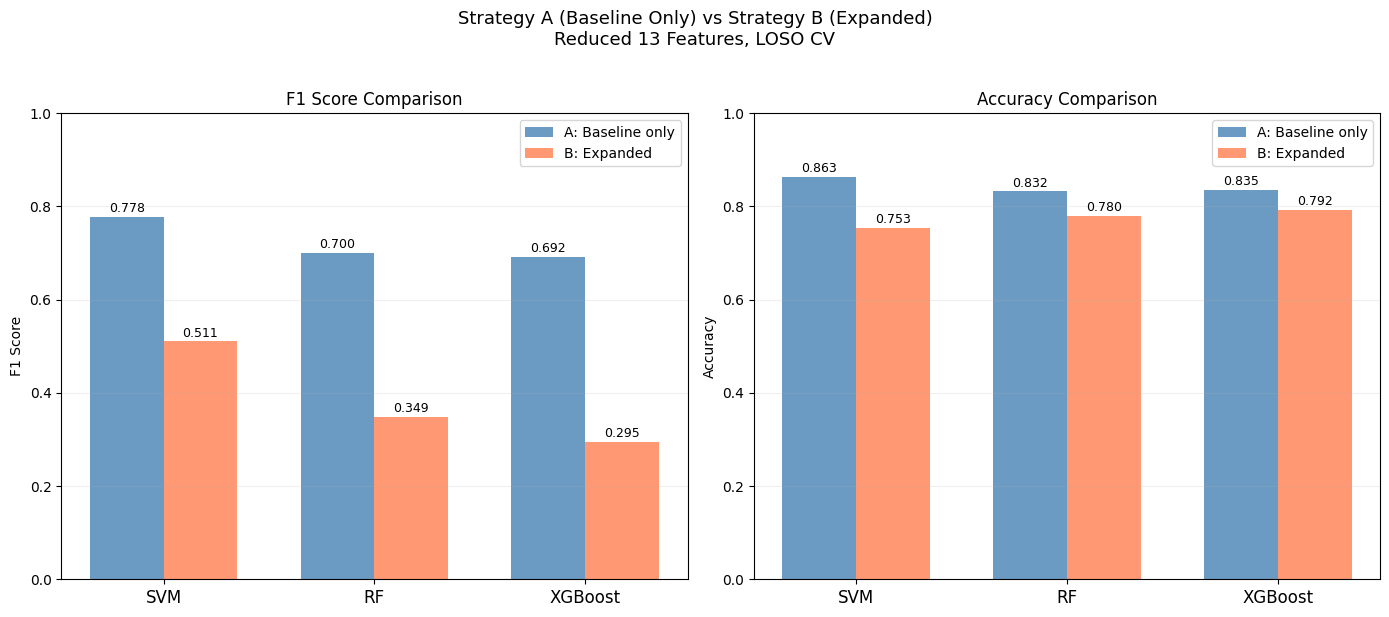

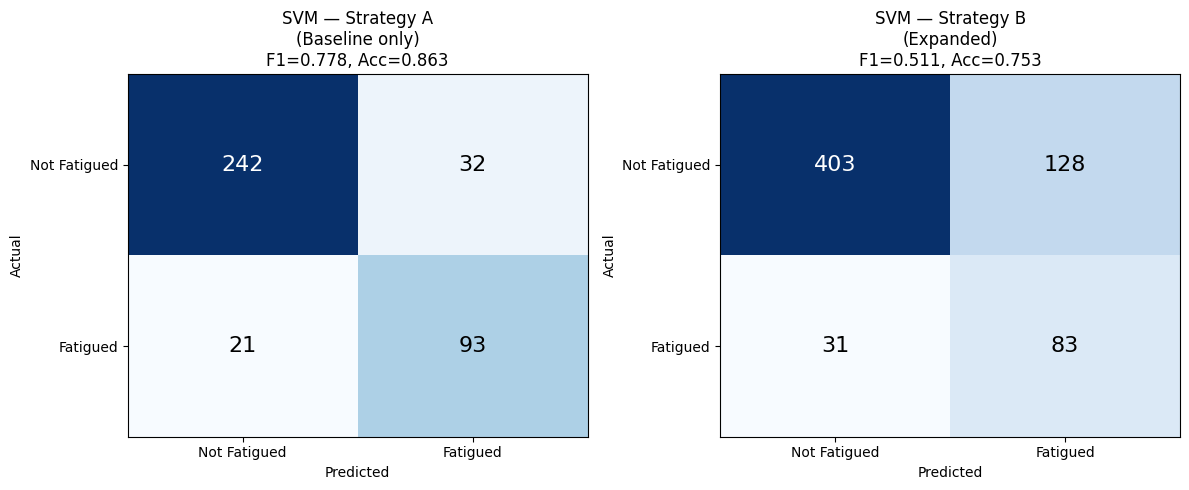


SUMMARY

  Best Strategy A: SVM, F1=0.7782, Acc=0.8634
  Best Strategy B: SVM, F1=0.5108, Acc=0.7535

  → Strategy A (baseline only) is BETTER by +0.2675 F1
    Including exercise/recovery HURTS — exercise windows confuse the model


In [7]:
"""
EXPERIMENT: Include Exercise + Recovery as Not-Fatigued

Strategy A (current):  baseline (275) vs fatigued (127) = 402
Strategy B (expanded): baseline+exercise+recovery (548) vs fatigued (127) = 675

Tests both on 180s and 240s windows with SVM, RF, XGBoost.
"""

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix)
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False


DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]

ALL_WINDOWS_CSV = Path("combined_all_windows.csv")
TRAINING_CSV = Path("training_dataset.csv")

REDUCED_FEATURES = [
    "temp_change_from_baseline", "temp_range", "temp_std",
    "temp_slope", "temp_min",
    "sdhr", "cv_rr", "triangular_index", "max_hr",
    "vlf_power", "mean_rr", "min_hr", "pnn50",
]


def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events


def loso_cv(model_class, model_params, X, y, participants, scale=False):
    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []
    per_participant = {}

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        model = model_class(**model_params)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        all_preds.extend(y_pred)
        all_true.extend(y_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1, "n_samples": len(y_test)}

    all_preds = np.array(all_preds)
    all_true = np.array(all_true)

    return {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "confusion_matrix": confusion_matrix(all_true, all_preds),
        "per_participant": per_participant,
    }



# CREATE EXPANDED LABELS
def create_expanded_labels(df):
    """
    Relabel:
      baseline + exercise + recovery → not fatigued (0)
      cognitive task → fatigued (1)
    """
    df_exp = df.copy()
    df_exp["label_expanded"] = -1

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            markers = load_markers(pid, sid)
            if not markers:
                continue

            baseline_start = markers.get("start_baseline")
            cognitive_start = markers.get("start_fatigue")

            mask = (df_exp["participant"] == pid) & (df_exp["session"] == sid)

            for idx in df_exp[mask].index:
                w_start = pd.to_datetime(df_exp.loc[idx, "window_start"], utc=True)

                if cognitive_start and w_start >= cognitive_start:
                    df_exp.loc[idx, "label_expanded"] = 1
                elif baseline_start:
                    # Everything before cognitive task = not fatigued
                    df_exp.loc[idx, "label_expanded"] = 0

    return df_exp



# MAIN EXPERIMENT
def run_experiment():
    print("=" * 70)
    print("EXPERIMENT: EXPANDED LABELLING")
    print("=" * 70)

    # Load data — try all windows file first
    if ALL_WINDOWS_CSV.exists():
        df = pd.read_csv(ALL_WINDOWS_CSV)
        print(f"Loaded: {ALL_WINDOWS_CSV} ({len(df)} windows)")
    elif TRAINING_CSV.exists():
        df = pd.read_csv(TRAINING_CSV)
        print(f"[WARNING] Only {TRAINING_CSV} available — missing exercise/recovery windows")
        print(f"  You need combined_all_windows.csv for this experiment")
        return
    else:
        print("[ERROR] No data files found")
        return

    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)

    # STRATEGY A: Baseline only
    print("\n" + "=" * 50)
    print("STRATEGY A: Baseline vs Fatigued (current)")
    print("=" * 50)

    df_a = df[df["label"].isin([0, 1])].copy()
    df_a = df_a.dropna(subset=REDUCED_FEATURES)

    n_base_a = (df_a["label"] == 0).sum()
    n_fat_a = (df_a["label"] == 1).sum()
    print(f"  Not fatigued: {n_base_a} (baseline only)")
    print(f"  Fatigued:     {n_fat_a}")
    print(f"  Total:        {len(df_a)}")
    print(f"  Ratio:        {n_base_a / n_fat_a:.1f} : 1")

    X_a = df_a[REDUCED_FEATURES].values
    y_a = df_a["label"].values
    p_a = df_a["participant"].values

    # STRATEGY B: Expanded
    print("\n" + "=" * 50)
    print("STRATEGY B: Baseline+Exercise+Recovery vs Fatigued")
    print("=" * 50)

    df_exp = create_expanded_labels(df)
    df_b = df_exp[df_exp["label_expanded"].isin([0, 1])].copy()
    df_b = df_b.dropna(subset=REDUCED_FEATURES)

    n_base_b = (df_b["label_expanded"] == 0).sum()
    n_fat_b = (df_b["label_expanded"] == 1).sum()
    print(f"  Not fatigued: {n_base_b} (baseline + exercise + recovery)")
    print(f"  Fatigued:     {n_fat_b}")
    print(f"  Total:        {len(df_b)}")
    print(f"  Ratio:        {n_base_b / n_fat_b:.1f} : 1")

    X_b = df_b[REDUCED_FEATURES].values
    y_b = df_b["label_expanded"].values
    p_b = df_b["participant"].values


    print(f"\n  Per-participant (Strategy B):")
    print(f"  {'PID':>4} | {'Not Fat':>8} | {'Fatigued':>8} | {'Total':>6}")
    print(f"  {'-'*40}")
    for pid in sorted(df_b["participant"].unique()):
        sub = df_b[df_b["participant"] == pid]
        nf = (sub["label_expanded"] == 0).sum()
        f = (sub["label_expanded"] == 1).sum()
        print(f"  P{pid:02d}  | {nf:>8} | {f:>8} | {len(sub):>6}")


    print("\n" + "=" * 50)
    print("RESULTS")
    print("=" * 50)

    models = {
        "SVM": (SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                       "class_weight": "balanced", "random_state": 42}, True),
        "RF": (RandomForestClassifier, {"n_estimators": 100, "max_depth": 10,
                "min_samples_leaf": 2, "class_weight": "balanced", "random_state": 42}, False),
    }
    if HAS_XGBOOST:
        models["XGBoost"] = (XGBClassifier, {"n_estimators": 200, "max_depth": 4,
                              "learning_rate": 0.05, "random_state": 42,
                              "eval_metric": "logloss", "use_label_encoder": False,
                              "scale_pos_weight": 2.0, "subsample": 0.8,
                              "colsample_bytree": 0.8}, False)

    results_a = {}
    results_b = {}

    print(f"\n  {'Model':<12} | {'--- Strategy A (baseline only) ---':>38} | {'--- Strategy B (expanded) ---':>38}")
    print(f"  {'':>12} | {'F1':>8} {'Acc':>8} {'Prec':>8} {'Recall':>8} | {'F1':>8} {'Acc':>8} {'Prec':>8} {'Recall':>8}")
    print(f"  {'-'*95}")

    for name, (cls, params, scale) in models.items():
        res_a = loso_cv(cls, params, X_a, y_a, p_a, scale=scale)
        res_b = loso_cv(cls, params, X_b, y_b, p_b, scale=scale)

        results_a[name] = res_a
        results_b[name] = res_b

        f1_change = res_b["f1"] - res_a["f1"]
        direction = "↑" if f1_change > 0.005 else ("↓" if f1_change < -0.005 else "→")

        print(f"  {name:<12} | {res_a['f1']:>8.4f} {res_a['accuracy']:>8.4f} "
              f"{res_a['precision']:>8.4f} {res_a['recall']:>8.4f} | "
              f"{res_b['f1']:>8.4f} {res_b['accuracy']:>8.4f} "
              f"{res_b['precision']:>8.4f} {res_b['recall']:>8.4f}  {direction} F1 {f1_change:+.4f}")


    print("\n" + "=" * 50)
    print("CONFUSION MATRICES")
    print("=" * 50)

    for name in models:
        cm_a = results_a[name]["confusion_matrix"]
        cm_b = results_b[name]["confusion_matrix"]

        print(f"\n  {name}:")
        print(f"    Strategy A:  TN={cm_a[0][0]:>4}  FP={cm_a[0][1]:>4}  FN={cm_a[1][0]:>4}  TP={cm_a[1][1]:>4}")
        print(f"    Strategy B:  TN={cm_b[0][0]:>4}  FP={cm_b[0][1]:>4}  FN={cm_b[1][0]:>4}  TP={cm_b[1][1]:>4}")

        # Key metrics from confusion matrix
        recall_a = cm_a[1][1] / (cm_a[1][0] + cm_a[1][1]) if (cm_a[1][0] + cm_a[1][1]) > 0 else 0
        recall_b = cm_b[1][1] / (cm_b[1][0] + cm_b[1][1]) if (cm_b[1][0] + cm_b[1][1]) > 0 else 0
        fpr_a = cm_a[0][1] / (cm_a[0][0] + cm_a[0][1]) if (cm_a[0][0] + cm_a[0][1]) > 0 else 0
        fpr_b = cm_b[0][1] / (cm_b[0][0] + cm_b[0][1]) if (cm_b[0][0] + cm_b[0][1]) > 0 else 0

        print(f"    Recall (catching fatigue): A={recall_a:.3f}  B={recall_b:.3f}")
        print(f"    False positive rate:       A={fpr_a:.3f}  B={fpr_b:.3f}")

    # Per-participant comparison for best model 
    best_model = max(results_a, key=lambda m: results_a[m]["f1"])
    print(f"\n" + "=" * 50)
    print(f"PER-PARTICIPANT COMPARISON ({best_model})")
    print("=" * 50)

    print(f"\n  {'PID':>4} | {'F1 (A)':>8} | {'F1 (B)':>8} | {'Change':>8}")
    print(f"  {'-'*40}")

    for pid in sorted(results_a[best_model]["per_participant"].keys()):
        f1_a = results_a[best_model]["per_participant"][pid]["f1"]
        f1_b = results_b[best_model]["per_participant"].get(pid, {}).get("f1", np.nan)
        change = f1_b - f1_a if not np.isnan(f1_b) else np.nan
        symbol = "↑" if change > 0.01 else ("↓" if change < -0.01 else "→")
        print(f"  P{pid:02d}  | {f1_a:>8.3f} | {f1_b:>8.3f} | {change:>+7.3f} {symbol}")

    # === Plots ===

    # Plot 1: F1 comparison
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    model_names = list(models.keys())
    x = np.arange(len(model_names))
    width = 0.35

    ax = axes[0]
    f1_a_vals = [results_a[m]["f1"] for m in model_names]
    f1_b_vals = [results_b[m]["f1"] for m in model_names]

    bars1 = ax.bar(x - width/2, f1_a_vals, width, label="A: Baseline only",
                    alpha=0.8, color="steelblue")
    bars2 = ax.bar(x + width/2, f1_b_vals, width, label="B: Expanded",
                    alpha=0.8, color="coral")

    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=12)
    ax.set_ylabel("F1 Score")
    ax.set_title("F1 Score Comparison")
    ax.legend()
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.2, axis="y")

    for bar in bars1:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{bar.get_height():.3f}", ha="center", fontsize=9)
    for bar in bars2:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{bar.get_height():.3f}", ha="center", fontsize=9)

    # Plot 2: Accuracy comparison
    ax = axes[1]
    acc_a_vals = [results_a[m]["accuracy"] for m in model_names]
    acc_b_vals = [results_b[m]["accuracy"] for m in model_names]

    bars1 = ax.bar(x - width/2, acc_a_vals, width, label="A: Baseline only",
                    alpha=0.8, color="steelblue")
    bars2 = ax.bar(x + width/2, acc_b_vals, width, label="B: Expanded",
                    alpha=0.8, color="coral")

    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=12)
    ax.set_ylabel("Accuracy")
    ax.set_title("Accuracy Comparison")
    ax.legend()
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.2, axis="y")

    for bar in bars1:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{bar.get_height():.3f}", ha="center", fontsize=9)
    for bar in bars2:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f"{bar.get_height():.3f}", ha="center", fontsize=9)

    fig.suptitle("Strategy A (Baseline Only) vs Strategy B (Expanded)\nReduced 13 Features, LOSO CV",
                 fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

    # Plot 3: Confusion matrices side by side for best model
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for i, (label, res) in enumerate([("Strategy A\n(Baseline only)", results_a[best_model]),
                                        ("Strategy B\n(Expanded)", results_b[best_model])]):
        ax = axes[i]
        cm = res["confusion_matrix"]
        im = ax.imshow(cm, cmap="Blues", aspect="auto")

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["Not Fatigued", "Fatigued"], fontsize=10)
        ax.set_yticklabels(["Not Fatigued", "Fatigued"], fontsize=10)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(f"{best_model} — {label}\nF1={res['f1']:.3f}, Acc={res['accuracy']:.3f}")

        for r in range(2):
            for c in range(2):
                ax.text(c, r, str(cm[r, c]), ha="center", va="center",
                        fontsize=16, color="white" if cm[r, c] > cm.max() / 2 else "black")

    plt.tight_layout()
    plt.show()

    # === Summary ===
    print("\n" + "=" * 50)
    print("SUMMARY")
    print("=" * 50)

    best_a = max(results_a.items(), key=lambda x: x[1]["f1"])
    best_b = max(results_b.items(), key=lambda x: x[1]["f1"])

    print(f"\n  Best Strategy A: {best_a[0]}, F1={best_a[1]['f1']:.4f}, Acc={best_a[1]['accuracy']:.4f}")
    print(f"  Best Strategy B: {best_b[0]}, F1={best_b[1]['f1']:.4f}, Acc={best_b[1]['accuracy']:.4f}")

    if best_b[1]["f1"] > best_a[1]["f1"]:
        print(f"\n  → Strategy B (expanded) is BETTER by {best_b[1]['f1'] - best_a[1]['f1']:+.4f} F1")
        print(f"    Including exercise/recovery as not-fatigued HELPS")
    else:
        print(f"\n  → Strategy A (baseline only) is BETTER by {best_a[1]['f1'] - best_b[1]['f1']:+.4f} F1")
        print(f"    Including exercise/recovery HURTS — exercise windows confuse the model")
        
# RUN
if __name__ == "__main__":
    run_experiment()

DEEP LEARNING EXPERIMENTS
Feature data: 388 windows, baseline=274, fatigued=114

Loading raw RR intervals for CNN/LSTM...
  Raw RR dataset: 401 windows, 250 beats each
  Baseline: 274, Fatigued: 127

--------------------------------------------------
1. BASELINE: SVM + Reduced 13 Features
--------------------------------------------------
  F1=0.7782, Acc=0.8634

--------------------------------------------------
2. MLP on Reduced 13 Features
--------------------------------------------------
  F1=0.7347, Acc=0.8325

--------------------------------------------------
3. MLP on All 28 Features
--------------------------------------------------
  F1=0.7360, Acc=0.8299

--------------------------------------------------
4. 1D CNN on Raw RR Intervals
--------------------------------------------------
  F1=0.4321, Acc=0.5411

--------------------------------------------------
5. LSTM on Raw RR Intervals
--------------------------------------------------
  F1=0.4260, Acc=0.5162

------------

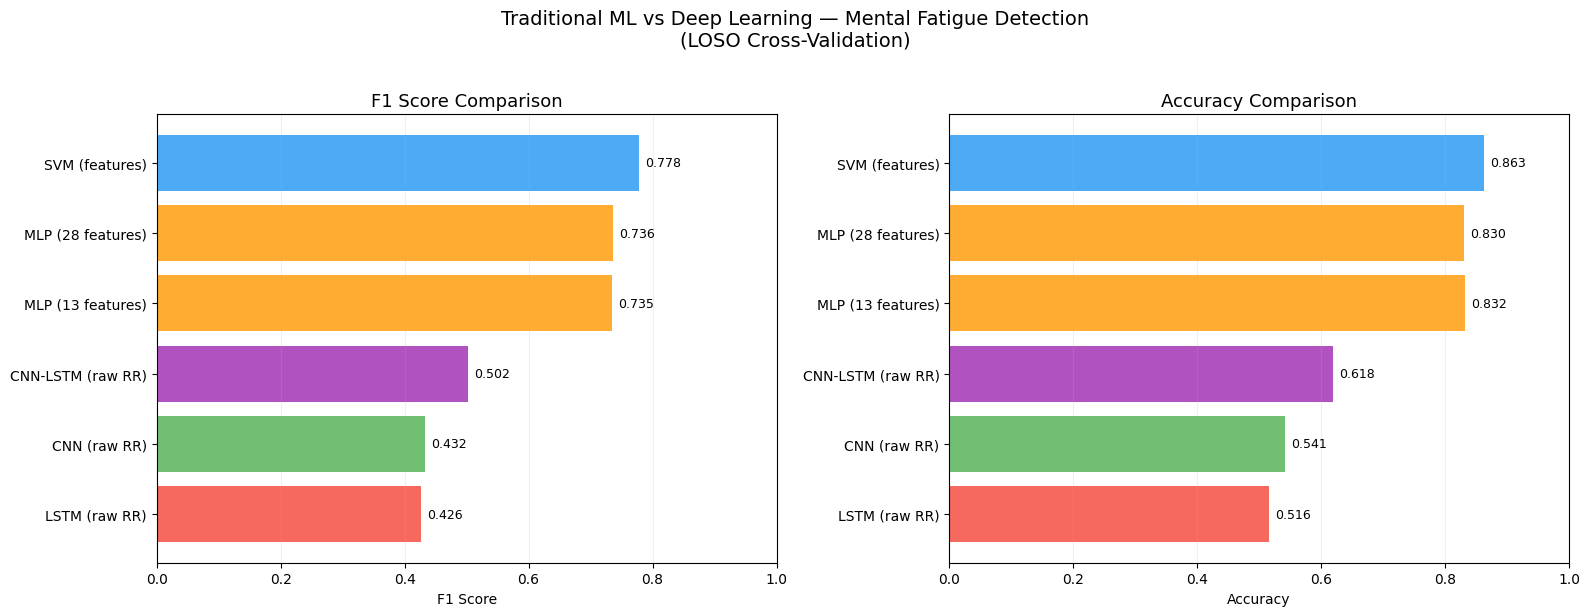

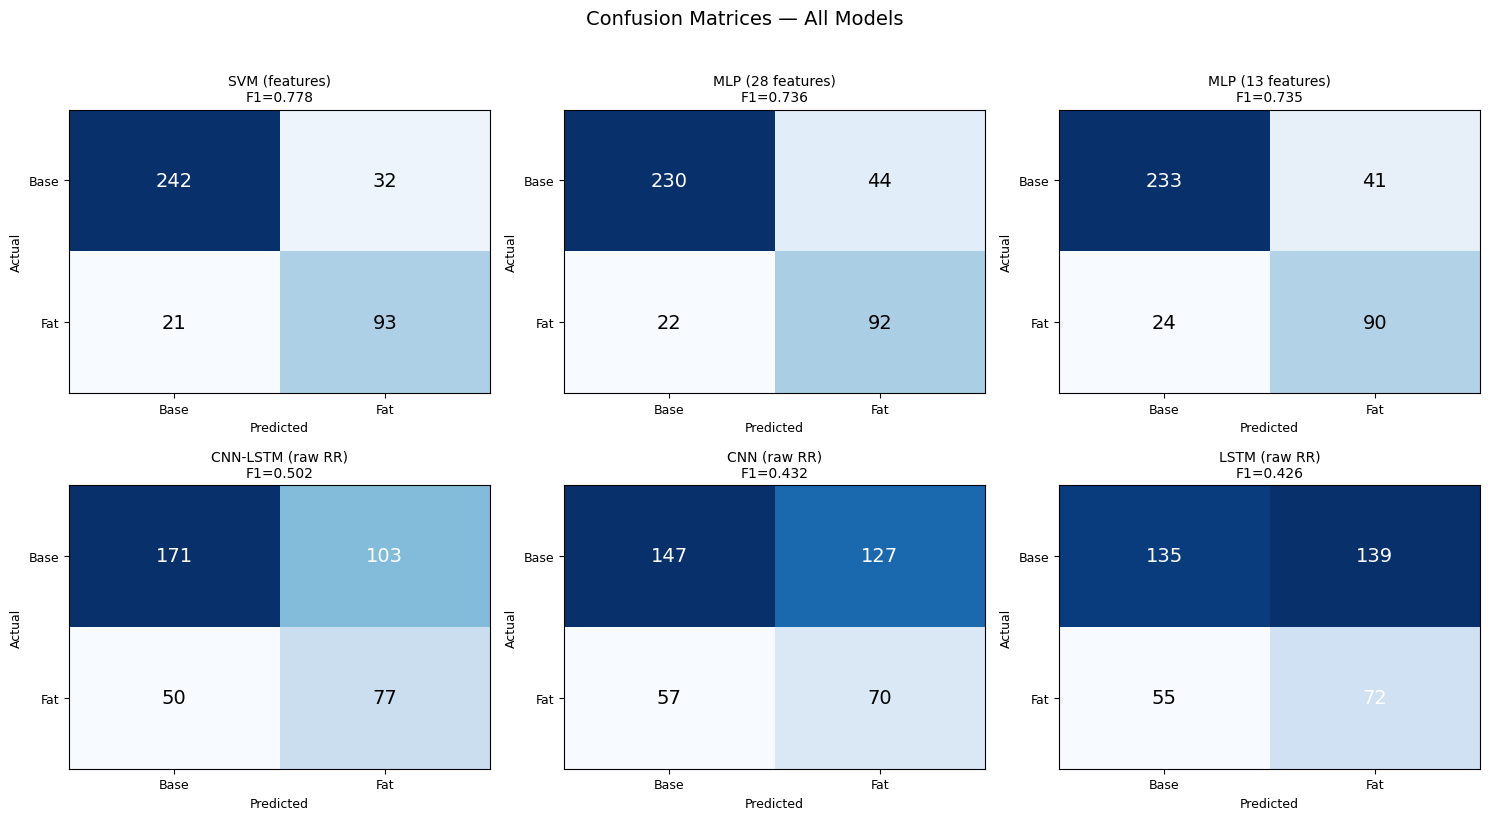


PER-PARTICIPANT F1 SCORES
   PID |  SVM (features) | MLP (28 feature | MLP (13 feature | CNN-LSTM (raw R
  ----------------------------------------------------------------------------
  P01  |           0.733 |           0.643 |           0.733 |           0.593
  P02  |           0.800 |           0.857 |           0.800 |           0.000
  P03  |           1.000 |           1.000 |           1.000 |           0.400
  P04  |           0.917 |           0.870 |           0.880 |           0.647
  P05  |           0.842 |           0.941 |           0.667 |           0.762
  P06  |           0.917 |           0.667 |           0.833 |           0.714
  P07  |           0.462 |           0.667 |           0.429 |           0.606
  P08  |           0.500 |           0.545 |           0.600 |           0.455
  P09  |           0.688 |           0.727 |           0.750 |           0.333
  P10  |           0.833 |           0.571 |           1.000 |           0.583
  P11  |           0.842 

In [ ]:
"""
DEEP LEARNING EXPERIMENTS
1. MLP (Multi-Layer Perceptron) — on extracted features (28 or 13)
2. CNN (1D Convolutional Neural Network) — on raw RR intervals
3. LSTM (Long Short-Term Memory) — on raw RR intervals

All evaluated with LOSO Cross-Validation.
"""

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix)
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # Suppress TF warnings

try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import (Dense, Dropout, Conv1D, MaxPooling1D,
                                          LSTM, Flatten, BatchNormalization,
                                          Bidirectional, GlobalAveragePooling1D)
    from tensorflow.keras.callbacks import EarlyStopping
    from tensorflow.keras.utils import to_categorical
    HAS_TF = True
    tf.get_logger().setLevel('ERROR')
except ImportError:
    print("[ERROR] TensorFlow not installed. Run: pip install tensorflow")
    print("        Cannot run deep learning experiments.")
    HAS_TF = False

DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]

TRAINING_CSV = Path("training_dataset.csv")

REDUCED_FEATURES = [
    "temp_change_from_baseline", "temp_range", "temp_std",
    "temp_slope", "temp_min",
    "sdhr", "cv_rr", "triangular_index", "max_hr",
    "vlf_power", "mean_rr", "min_hr", "pnn50",
]

ALL_FEATURES = [
    "mean_rr", "sdnn", "rmssd", "pnn50",
    "mean_hr", "min_hr", "max_hr", "sdhr",
    "range_rr", "cv_rr", "triangular_index",
    "vlf_power", "lf_power", "hf_power",
    "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
    "ln_vlf", "ln_lf", "ln_hf", "ln_total_power",
    "temp_mean", "temp_slope", "temp_std",
    "temp_range", "temp_min", "temp_change_from_baseline"
]

# RR interval config
MAX_RR_MS = 2000
MIN_RR_MS = 300
MAX_RR_DIFF_MS = 300
WINDOW_SEC = 180
FIXED_RR_LENGTH = 250  # Pad/truncate raw RR to this length per window


def load_feature_data():
    df = pd.read_csv(TRAINING_CSV)
    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
    df = df.dropna(subset=ALL_FEATURES)

    print(f"Feature data: {len(df)} windows, baseline={( df['label']==0).sum()}, fatigued={(df['label']==1).sum()}")
    return df



def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events


def clean_rr(rr):
    mask = (rr >= MIN_RR_MS) & (rr <= MAX_RR_MS)
    rr = rr[mask]
    if len(rr) < 3:
        return rr
    diffs = np.abs(np.diff(rr))
    keep = np.ones(len(rr), dtype=bool)
    for i in range(len(diffs)):
        if diffs[i] > MAX_RR_DIFF_MS:
            keep[i + 1] = False
    return rr[keep]


"""
Load raw RR intervals per window, pad/truncate to fixed length.
Returns X (n_windows, FIXED_RR_LENGTH), y, participants arrays.
"""
def load_raw_rr_dataset():
    print("\nLoading raw RR intervals for CNN/LSTM...")

    all_rr_windows = []
    all_labels = []
    all_pids = []

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            rr_file = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "chest_rr_interval.csv"
            if not rr_file.exists():
                continue

            df_rr = pd.read_csv(rr_file)
            df_rr["timestamp"] = pd.to_datetime(df_rr["timestamp"], unit="ms", utc=True)
            df_rr = df_rr.rename(columns={"duration": "rr_ms"})
            df_rr = df_rr.dropna(subset=["rr_ms"])
            df_rr = df_rr.sort_values("timestamp")

            markers = load_markers(pid, sid)
            if not markers:
                continue

            baseline_start = markers.get("start_baseline")
            exercise_start = markers.get("start_activity")
            cognitive_start = markers.get("start_fatigue")

            t_start = df_rr["timestamp"].iloc[0]
            t_end = df_rr["timestamp"].iloc[-1]

            w_start = t_start
            while w_start + pd.Timedelta(seconds=WINDOW_SEC) <= t_end:
                w_end = w_start + pd.Timedelta(seconds=WINDOW_SEC)

                # Label
                if cognitive_start and w_start >= cognitive_start:
                    label = 1
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    label = 0
                else:
                    label = -1  # excluded

                if label >= 0:
                    # Get RR intervals in window
                    mask = (df_rr["timestamp"] >= w_start) & (df_rr["timestamp"] < w_end)
                    rr_vals = df_rr.loc[mask, "rr_ms"].to_numpy(dtype=float)
                    rr_clean = clean_rr(rr_vals)

                    if len(rr_clean) >= 50:  # minimum beats needed
                        # Pad or truncate to fixed length
                        if len(rr_clean) >= FIXED_RR_LENGTH:
                            rr_fixed = rr_clean[:FIXED_RR_LENGTH]
                        else:
                            # Pad with the mean RR value (neutral padding)
                            pad_val = np.mean(rr_clean)
                            rr_fixed = np.pad(rr_clean,
                                              (0, FIXED_RR_LENGTH - len(rr_clean)),
                                              mode='constant', constant_values=pad_val)

                        all_rr_windows.append(rr_fixed)
                        all_labels.append(label)
                        all_pids.append(pid)

                w_start += pd.Timedelta(seconds=60)  # 60s step

    X = np.array(all_rr_windows)
    y = np.array(all_labels)
    participants = np.array(all_pids)

    print(f"  Raw RR dataset: {len(X)} windows, {FIXED_RR_LENGTH} beats each")
    print(f"  Baseline: {(y==0).sum()}, Fatigued: {(y==1).sum()}")

    return X, y, participants



# LOSO CV FOR SKLEARN MODELS (baseline comparison)
def loso_cv_sklearn(model_class, model_params, X, y, participants, scale=False):
    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []
    per_participant = {}

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        model = model_class(**model_params)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        all_preds.extend(y_pred)
        all_true.extend(y_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1}

    return {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "confusion_matrix": confusion_matrix(all_true, all_preds),
        "per_participant": per_participant,
    }


# LOSO CV FOR KERAS MODELS
"""
LOSO cross-validation for Keras models.

Parameters
    
build_model_fn : callable
        Function that returns a compiled Keras model.
        Signature: build_model_fn(input_shape) -> model
X : np.ndarray
        Feature matrix or raw signal matrix
y : np.ndarray
        Labels (0 or 1)
participants : np.ndarray
        Participant IDs
 """
def loso_cv_keras(build_model_fn, X, y, participants, epochs=50, batch_size=16):
    
    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []
    per_participant = {}

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        # Scale
        if X_train.ndim == 2:
            # Feature-based (MLP)
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)
        else:
            # Raw RR (CNN/LSTM) — normalise per-sample
            train_mean = X_train.mean()
            train_std = X_train.std()
            X_train = (X_train - train_mean) / (train_std + 1e-8)
            X_test = (X_test - train_mean) / (train_std + 1e-8)

        # Class weights for imbalance
        n_neg = (y_train == 0).sum()
        n_pos = (y_train == 1).sum()
        class_weight = {0: 1.0, 1: n_neg / n_pos if n_pos > 0 else 1.0}

        # Build model
        input_shape = X_train.shape[1:]
        model = build_model_fn(input_shape)

        # Early stopping to prevent overfitting
        early_stop = EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)

        # Train
        model.fit(X_train, y_train,
                  epochs=epochs,
                  batch_size=batch_size,
                  class_weight=class_weight,
                  callbacks=[early_stop],
                  verbose=0)

        # Predict
        y_prob = model.predict(X_test, verbose=0).flatten()
        y_pred = (y_prob >= 0.5).astype(int)

        all_preds.extend(y_pred)
        all_true.extend(y_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1}

        # Clear session to prevent memory leak
        tf.keras.backend.clear_session()

    all_preds = np.array(all_preds)
    all_true = np.array(all_true)

    return {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "confusion_matrix": confusion_matrix(all_true, all_preds),
        "per_participant": per_participant,
    }


# MODEL DEFINITIONS

"""
Simple Multi-Layer Perceptron for feature-based classification.
Input: (n_features,)
"""
def build_mlp(input_shape):
    
    model = Sequential([
        Dense(64, activation='relu', input_shape=input_shape),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(16, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


"""
1D CNN for raw RR interval classification.
Input: (FIXED_RR_LENGTH, 1)
"""
def build_cnn(input_shape):
    model = Sequential([
        Conv1D(32, kernel_size=7, activation='relu', input_shape=input_shape, padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        Conv1D(64, kernel_size=5, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        GlobalAveragePooling1D(),

        Dense(32, activation='relu'),
        Dropout(0.4),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


"""
LSTM for raw RR interval classification.
Input: (FIXED_RR_LENGTH, 1)
"""
def build_lstm(input_shape):

    model = Sequential([
        LSTM(32, return_sequences=True, input_shape=input_shape),
        Dropout(0.3),
        LSTM(16, return_sequences=False),
        Dropout(0.3),
        Dense(16, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


"""
Hybrid CNN-LSTM: CNN extracts local patterns, LSTM captures temporal dependencies.
Input: (FIXED_RR_LENGTH, 1)
"""
def build_cnn_lstm(input_shape):
    
    model = Sequential([
        Conv1D(32, kernel_size=7, activation='relu', input_shape=input_shape, padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        Conv1D(64, kernel_size=5, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        LSTM(32, return_sequences=False),
        Dropout(0.3),

        Dense(16, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model



# RUN ALL EXPERIMENTS
def run_all():
    print("=" * 70)
    print("DEEP LEARNING EXPERIMENTS")
    print("=" * 70)

    
    df = load_feature_data()
    y_feat = df["label"].values
    p_feat = df["participant"].values
    X_reduced = df[REDUCED_FEATURES].values
    X_all = df[ALL_FEATURES].values

    X_rr, y_rr, p_rr = load_raw_rr_dataset()
    # Reshape for CNN/LSTM: (samples, timesteps, 1)
    X_rr_3d = X_rr.reshape(X_rr.shape[0], X_rr.shape[1], 1)

    all_results = {}

    print("\n" + "-" * 50)
    print("1. BASELINE: SVM + Reduced 13 Features")
    print("-" * 50)

    res_svm = loso_cv_sklearn(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                                     "class_weight": "balanced", "random_state": 42},
                              X_reduced, y_feat, p_feat, scale=True)
    all_results["SVM (features)"] = res_svm
    print(f"  F1={res_svm['f1']:.4f}, Acc={res_svm['accuracy']:.4f}")


    print("\n" + "-" * 50)
    print("2. MLP on Reduced 13 Features")
    print("-" * 50)

    res_mlp_r = loso_cv_keras(build_mlp, X_reduced, y_feat, p_feat,
                               epochs=100, batch_size=16)
    all_results["MLP (13 features)"] = res_mlp_r
    print(f"  F1={res_mlp_r['f1']:.4f}, Acc={res_mlp_r['accuracy']:.4f}")

    print("\n" + "-" * 50)
    print("3. MLP on All 28 Features")
    print("-" * 50)

    res_mlp_a = loso_cv_keras(build_mlp, X_all, y_feat, p_feat,
                               epochs=100, batch_size=16)
    all_results["MLP (28 features)"] = res_mlp_a
    print(f"  F1={res_mlp_a['f1']:.4f}, Acc={res_mlp_a['accuracy']:.4f}")


    print("\n" + "-" * 50)
    print("4. 1D CNN on Raw RR Intervals")
    print("-" * 50)

    res_cnn = loso_cv_keras(build_cnn, X_rr_3d, y_rr, p_rr,
                             epochs=50, batch_size=16)
    all_results["CNN (raw RR)"] = res_cnn
    print(f"  F1={res_cnn['f1']:.4f}, Acc={res_cnn['accuracy']:.4f}")

 
    print("\n" + "-" * 50)
    print("5. LSTM on Raw RR Intervals")
    print("-" * 50)

    res_lstm = loso_cv_keras(build_lstm, X_rr_3d, y_rr, p_rr,
                              epochs=50, batch_size=16)
    all_results["LSTM (raw RR)"] = res_lstm
    print(f"  F1={res_lstm['f1']:.4f}, Acc={res_lstm['accuracy']:.4f}")


    print("\n" + "-" * 50)
    print("6. CNN-LSTM Hybrid on Raw RR Intervals")
    print("-" * 50)

    res_cnn_lstm = loso_cv_keras(build_cnn_lstm, X_rr_3d, y_rr, p_rr,
                                  epochs=50, batch_size=16)
    all_results["CNN-LSTM (raw RR)"] = res_cnn_lstm
    print(f"  F1={res_cnn_lstm['f1']:.4f}, Acc={res_cnn_lstm['accuracy']:.4f}")

    # COMPARISON TABLE

    print("\n" + "=" * 70)
    print("FULL MODEL COMPARISON")
    print("=" * 70)

    print(f"\n  {'Model':<25} {'Input':<18} {'F1':>8} {'Acc':>8} {'Prec':>8} {'Recall':>8}")
    print(f"  {'-'*80}")

    # Sort by F1
    sorted_results = sorted(all_results.items(), key=lambda x: x[1]['f1'], reverse=True)

    for name, res in sorted_results:
        input_type = "features" if "feature" in name.lower() or "mlp" in name.lower() or "svm" in name.lower() else "raw RR"
        print(f"  {name:<25} {input_type:<18} {res['f1']:>8.4f} {res['accuracy']:>8.4f} "
              f"{res['precision']:>8.4f} {res['recall']:>8.4f}")

    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    names = [name for name, _ in sorted_results]
    f1_scores = [res["f1"] for _, res in sorted_results]
    acc_scores = [res["accuracy"] for _, res in sorted_results]

    # Color by type
    colors = []
    for name in names:
        if "SVM" in name:
            colors.append("#2196F3")  # blue
        elif "MLP" in name:
            colors.append("#FF9800")  # orange
        elif "CNN-LSTM" in name:
            colors.append("#9C27B0")  # purple
        elif "CNN" in name:
            colors.append("#4CAF50")  # green
        elif "LSTM" in name:
            colors.append("#F44336")  # red
        else:
            colors.append("#607D8B")  # grey

    ax = axes[0]
    bars = ax.barh(range(len(names)), f1_scores, color=colors, alpha=0.8)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=10)
    ax.set_xlabel("F1 Score")
    ax.set_title("F1 Score Comparison", fontsize=13)
    ax.set_xlim(0, 1.0)
    ax.grid(True, alpha=0.2, axis="x")
    ax.invert_yaxis()

    for i, bar in enumerate(bars):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f"{f1_scores[i]:.3f}", va="center", fontsize=9)

    ax = axes[1]
    bars = ax.barh(range(len(names)), acc_scores, color=colors, alpha=0.8)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=10)
    ax.set_xlabel("Accuracy")
    ax.set_title("Accuracy Comparison", fontsize=13)
    ax.set_xlim(0, 1.0)
    ax.grid(True, alpha=0.2, axis="x")
    ax.invert_yaxis()

    for i, bar in enumerate(bars):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f"{acc_scores[i]:.3f}", va="center", fontsize=9)

    fig.suptitle("Traditional ML vs Deep Learning — Mental Fatigue Detection\n(LOSO Cross-Validation)",
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()


    # CONFUSION MATRICES — all models
    n_models = len(all_results)
    n_cols = 3
    n_rows = (n_models + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, (name, res) in enumerate(sorted_results):
        ax = axes[i]
        cm = res["confusion_matrix"]
        im = ax.imshow(cm, cmap="Blues", aspect="auto")
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["Base", "Fat"], fontsize=9)
        ax.set_yticklabels(["Base", "Fat"], fontsize=9)
        ax.set_xlabel("Predicted", fontsize=9)
        ax.set_ylabel("Actual", fontsize=9)
        ax.set_title(f"{name}\nF1={res['f1']:.3f}", fontsize=10)

        for r in range(2):
            for c in range(2):
                ax.text(c, r, str(cm[r, c]), ha="center", va="center",
                        fontsize=14, color="white" if cm[r, c] > cm.max() / 2 else "black")

    # Hide extra axes
    for j in range(len(sorted_results), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle("Confusion Matrices — All Models", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

  
    print("\n" + "=" * 70)
    print("PER-PARTICIPANT F1 SCORES")
    print("=" * 70)

    header = f"  {'PID':>4}"
    for name, _ in sorted_results[:4]:  # Top 4 models
        short_name = name[:15]
        header += f" | {short_name:>15}"
    print(header)
    print(f"  {'-' * (len(header) - 2)}")

    all_pids = sorted(set(p_feat) | set(p_rr))
    for pid in all_pids:
        row = f"  P{pid:02d} "
        for name, res in sorted_results[:4]:
            f1 = res["per_participant"].get(pid, {}).get("f1", np.nan)
            row += f" | {f1:>15.3f}"
        print(row)


    # SUMMARY
    best_name, best_res = sorted_results[0]
    print(f"\n" + "=" * 70)
    print(f"BEST MODEL: {best_name}")
    print(f"  F1:        {best_res['f1']:.4f}")
    print(f"  Accuracy:  {best_res['accuracy']:.4f}")
    print(f"  Precision: {best_res['precision']:.4f}")
    print(f"  Recall:    {best_res['recall']:.4f}")
    print("=" * 70)

    return all_results



# RUN
if __name__ == "__main__":
    results = run_all()

In [ ]:
"""
AUTOENCODER EXPERIMENTS
Two approaches:

1. Autoencoder for Feature Reduction
   - Compress 28 features → smaller bottleneck
   - Use compressed features with SVM/XGBoost
   - Compare with PCA and original features

2. Autoencoder for Anomaly Detection
   - Train ONLY on baseline windows
   - Fatigued windows should have high reconstruction error
   - No labels needed during training (unsupervised)
"""

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, roc_auc_score,
                             roc_curve)
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

try:
    import tensorflow as tf
    from tensorflow.keras.models import Model, Sequential
    from tensorflow.keras.layers import (Dense, Dropout, Input,
                                          BatchNormalization)
    from tensorflow.keras.callbacks import EarlyStopping
    HAS_TF = True
    tf.get_logger().setLevel('ERROR')
except ImportError:
    print("[ERROR] TensorFlow not installed. Run: pip install tensorflow")
    HAS_TF = False

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

TRAINING_CSV = Path("training_dataset.csv")

ALL_FEATURES = [
    "mean_rr", "sdnn", "rmssd", "pnn50",
    "mean_hr", "min_hr", "max_hr", "sdhr",
    "range_rr", "cv_rr", "triangular_index",
    "vlf_power", "lf_power", "hf_power",
    "total_power", "lf_hf_ratio", "lf_norm", "hf_norm",
    "ln_vlf", "ln_lf", "ln_hf", "ln_total_power",
    "temp_mean", "temp_slope", "temp_std",
    "temp_range", "temp_min", "temp_change_from_baseline"
]

REDUCED_FEATURES = [
    "temp_change_from_baseline", "temp_range", "temp_std",
    "temp_slope", "temp_min",
    "sdhr", "cv_rr", "triangular_index", "max_hr",
    "vlf_power", "mean_rr", "min_hr", "pnn50",
]

def loso_cv(model_class, model_params, X, y, participants, scale=False):
    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []
    per_participant = {}

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        model = model_class(**model_params)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        all_preds.extend(y_pred)
        all_true.extend(y_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1, "n_samples": len(y_test)}

    all_preds = np.array(all_preds)
    all_true = np.array(all_true)

    return {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "confusion_matrix": confusion_matrix(all_true, all_preds),
        "per_participant": per_participant,
    }


# APPROACH 1: Autoencoder for Feature Reduction

"""
Encoder: input_dim → 16 → bottleneck_dim
Decoder: bottleneck_dim → 16 → input_dim

The bottleneck forces the network to learn the most
important compressed representation of the features.
"""
def build_autoencoder(input_dim, bottleneck_dim):
    
    # Encoder
    encoder_input = Input(shape=(input_dim,))
    x = Dense(16, activation='relu')(encoder_input)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)
    bottleneck = Dense(bottleneck_dim, activation='relu', name='bottleneck')(x)

    # Decoder
    x = Dense(16, activation='relu')(bottleneck)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)
    decoder_output = Dense(input_dim, activation='linear')(x)

    # Full autoencoder
    autoencoder = Model(encoder_input, decoder_output)
    autoencoder.compile(optimizer='adam', loss='mse')

    # Encoder only (for feature extraction)
    encoder = Model(encoder_input, bottleneck)

    return autoencoder, encoder


def experiment_feature_reduction(df):
    print("\n" + "=" * 70)
    print("APPROACH 1: AUTOENCODER FOR FEATURE REDUCTION")
    print("=" * 70)

    y = df["label"].values
    participants = df["participant"].values

    # Scale all features
    scaler_all = StandardScaler()
    X_all_scaled = scaler_all.fit_transform(df[ALL_FEATURES].values)

    bottleneck_sizes = [3, 5, 7, 10]
    all_results = {}


    print("\n  --- Baselines ---")

    res_svm_reduced = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                                     "class_weight": "balanced", "random_state": 42},
                              df[REDUCED_FEATURES].values, y, participants, scale=True)
    all_results["SVM (13 features)"] = res_svm_reduced
    print(f"  SVM (13 features):       F1={res_svm_reduced['f1']:.4f}")

    res_svm_all = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                                 "class_weight": "balanced", "random_state": 42},
                          df[ALL_FEATURES].values, y, participants, scale=True)
    all_results["SVM (28 features)"] = res_svm_all
    print(f"  SVM (28 features):       F1={res_svm_all['f1']:.4f}")


    for n_comp in bottleneck_sizes:
        pca = PCA(n_components=n_comp)
        X_pca = pca.fit_transform(X_all_scaled)
        res_pca = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                                 "class_weight": "balanced", "random_state": 42},
                          X_pca, y, participants, scale=False)  # already scaled
        all_results[f"SVM + PCA ({n_comp} comp)"] = res_pca
        print(f"  SVM + PCA ({n_comp} comp):      F1={res_pca['f1']:.4f}")

    print("\n  --- Autoencoder Feature Reduction ---")

    for bottleneck_dim in bottleneck_sizes:
        unique_pids = sorted(set(participants))
        all_preds, all_true = [], []
        per_participant = {}

        for test_pid in unique_pids:
            train_mask = participants != test_pid
            test_mask = participants == test_pid

            X_train = X_all_scaled[train_mask]
            X_test = X_all_scaled[test_mask]
            y_train = y[train_mask]
            y_test = y[test_mask]

            if len(X_test) == 0 or len(np.unique(y_train)) < 2:
                continue

            # Train autoencoder on training data only
            autoencoder, encoder = build_autoencoder(28, bottleneck_dim)
            autoencoder.fit(X_train, X_train,
                            epochs=100, batch_size=16,
                            validation_split=0.15,
                            callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
                            verbose=0)

            # Extract compressed features
            X_train_compressed = encoder.predict(X_train, verbose=0)
            X_test_compressed = encoder.predict(X_test, verbose=0)

            # Train SVM on compressed features
            svm = SVC(kernel="rbf", C=5.0, gamma="scale",
                      class_weight="balanced", random_state=42)
            svm.fit(X_train_compressed, y_train)
            y_pred = svm.predict(X_test_compressed)

            all_preds.extend(y_pred)
            all_true.extend(y_test)

            acc = accuracy_score(y_test, y_pred)
            f1 = f1_score(y_test, y_pred, zero_division=0)
            per_participant[test_pid] = {"accuracy": acc, "f1": f1}

            tf.keras.backend.clear_session()

        all_preds = np.array(all_preds)
        all_true = np.array(all_true)

        res_ae = {
            "accuracy": accuracy_score(all_true, all_preds),
            "f1": f1_score(all_true, all_preds, zero_division=0),
            "precision": precision_score(all_true, all_preds, zero_division=0),
            "recall": recall_score(all_true, all_preds, zero_division=0),
            "confusion_matrix": confusion_matrix(all_true, all_preds),
            "per_participant": per_participant,
        }
        all_results[f"SVM + AE ({bottleneck_dim} dim)"] = res_ae
        print(f"  SVM + Autoencoder ({bottleneck_dim} dim): F1={res_ae['f1']:.4f}")


    if HAS_XGBOOST:
        print("\n  --- XGBoost on Autoencoder features ---")
        for bottleneck_dim in [5, 7]:
            unique_pids = sorted(set(participants))
            all_preds, all_true = [], []

            for test_pid in unique_pids:
                train_mask = participants != test_pid
                test_mask = participants == test_pid

                X_train = X_all_scaled[train_mask]
                X_test = X_all_scaled[test_mask]
                y_train = y[train_mask]
                y_test = y[test_mask]

                if len(X_test) == 0 or len(np.unique(y_train)) < 2:
                    continue

                autoencoder, encoder = build_autoencoder(28, bottleneck_dim)
                autoencoder.fit(X_train, X_train,
                                epochs=100, batch_size=16,
                                validation_split=0.15,
                                callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
                                verbose=0)

                X_train_comp = encoder.predict(X_train, verbose=0)
                X_test_comp = encoder.predict(X_test, verbose=0)

                xgb = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1,
                                     random_state=42, eval_metric="logloss",
                                     use_label_encoder=False, scale_pos_weight=2.0)
                xgb.fit(X_train_comp, y_train)
                y_pred = xgb.predict(X_test_comp)

                all_preds.extend(y_pred)
                all_true.extend(y_test)

                tf.keras.backend.clear_session()

            all_preds = np.array(all_preds)
            all_true = np.array(all_true)

            res_xgb_ae = {
                "accuracy": accuracy_score(all_true, all_preds),
                "f1": f1_score(all_true, all_preds, zero_division=0),
                "precision": precision_score(all_true, all_preds, zero_division=0),
                "recall": recall_score(all_true, all_preds, zero_division=0),
                "confusion_matrix": confusion_matrix(all_true, all_preds),
            }
            all_results[f"XGB + AE ({bottleneck_dim} dim)"] = res_xgb_ae
            print(f"  XGBoost + Autoencoder ({bottleneck_dim} dim): F1={res_xgb_ae['f1']:.4f}")


    plot_feature_reduction_results(all_results)

    return all_results


def plot_feature_reduction_results(all_results):
    sorted_results = sorted(all_results.items(), key=lambda x: x[1]["f1"], reverse=True)

    names = [name for name, _ in sorted_results]
    f1_scores = [res["f1"] for _, res in sorted_results]
    acc_scores = [res["accuracy"] for _, res in sorted_results]

    # Color by type
    colors = []
    for name in names:
        if "AE" in name:
            colors.append("#FF9800")  # orange for autoencoder
        elif "PCA" in name:
            colors.append("#4CAF50")  # green for PCA
        else:
            colors.append("#2196F3")  # blue for original features

    fig, ax = plt.subplots(figsize=(12, 7))
    x = np.arange(len(names))
    width = 0.35

    bars1 = ax.barh(x - width/2, f1_scores, width, label="F1 Score", alpha=0.8, color=colors)
    bars2 = ax.barh(x + width/2, acc_scores, width, label="Accuracy", alpha=0.5, color="steelblue")

    ax.set_yticks(x)
    ax.set_yticklabels(names, fontsize=9)
    ax.set_xlabel("Score")
    ax.set_title("Feature Reduction Comparison\n(Blue = Original, Green = PCA, Orange = Autoencoder)",
                 fontsize=13)
    ax.legend(loc="lower right")
    ax.set_xlim(0, 1.05)
    ax.grid(True, alpha=0.2, axis="x")
    ax.invert_yaxis()

    for i, bar in enumerate(bars1):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f"{f1_scores[i]:.3f}", va="center", fontsize=8)

    plt.tight_layout()
    plt.show()



# APPROACH 2: Autoencoder for Anomaly Detection
def build_anomaly_autoencoder(input_dim):
    """
    Autoencoder trained ONLY on baseline data.
    Fatigued windows should have higher reconstruction error.
    """
    model = Sequential([
        Dense(16, activation='relu', input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(5, activation='relu', name='bottleneck'),
        Dense(8, activation='relu'),
        BatchNormalization(),
        Dense(16, activation='relu'),
        Dense(input_dim, activation='linear')
    ])
    model.compile(optimizer='adam', loss='mse')
    return model


def experiment_anomaly_detection(df):
    print("\n" + "=" * 70)
    print("APPROACH 2: AUTOENCODER FOR ANOMALY DETECTION")
    print("=" * 70)

    y = df["label"].values
    participants = df["participant"].values

    feature_sets = {
        "28 features": ALL_FEATURES,
        "13 features": REDUCED_FEATURES,
    }

    for feat_name, feat_list in feature_sets.items():
        print(f"\n  --- {feat_name} ---")

        unique_pids = sorted(set(participants))
        all_errors = []
        all_true = []
        all_pids_test = []
        per_participant = {}

        for test_pid in unique_pids:
            train_mask = participants != test_pid
            test_mask = participants == test_pid

            X_all_train = df[feat_list].values[train_mask]
            y_train = y[train_mask]
            X_test = df[feat_list].values[test_mask]
            y_test = y[test_mask]

            if len(X_test) == 0:
                continue

            # Scale
            scaler = StandardScaler()
            X_all_train_scaled = scaler.fit_transform(X_all_train)
            X_test_scaled = scaler.transform(X_test)

            # Train ONLY on baseline windows from training set
            baseline_mask = y_train == 0
            X_baseline_train = X_all_train_scaled[baseline_mask]

            # Build and train autoencoder on baseline only
            ae = build_anomaly_autoencoder(len(feat_list))
            ae.fit(X_baseline_train, X_baseline_train,
                   epochs=100, batch_size=16,
                   validation_split=0.15,
                   callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
                   verbose=0)

            # Compute reconstruction error for test windows
            X_reconstructed = ae.predict(X_test_scaled, verbose=0)
            errors = np.mean((X_test_scaled - X_reconstructed) ** 2, axis=1)

            all_errors.extend(errors)
            all_true.extend(y_test)
            all_pids_test.extend([test_pid] * len(y_test))

            tf.keras.backend.clear_session()

        all_errors = np.array(all_errors)
        all_true = np.array(all_true)

   
        baseline_errors = all_errors[all_true == 0]
        fatigued_errors = all_errors[all_true == 1]

        print(f"\n  Reconstruction Error (MSE):")
        print(f"    Baseline mean: {baseline_errors.mean():.4f} ± {baseline_errors.std():.4f}")
        print(f"    Fatigued mean: {fatigued_errors.mean():.4f} ± {fatigued_errors.std():.4f}")

        if fatigued_errors.mean() > baseline_errors.mean():
            print(f"    → Fatigued windows have HIGHER error (as expected)")
        else:
            print(f"    → Fatigued windows have LOWER error (unexpected)")

        # --- Find best threshold ---
        from scipy import stats
        u_stat, p_val = stats.mannwhitneyu(baseline_errors, fatigued_errors, alternative="two-sided")
        print(f"    Mann-Whitney U test: p={p_val:.4f} {'← Significant' if p_val < 0.05 else '← NOT significant'}")

        # Try different thresholds
        best_f1 = 0
        best_threshold = 0

        thresholds = np.percentile(all_errors, np.arange(10, 95, 5))
        for thresh in thresholds:
            y_pred = (all_errors > thresh).astype(int)
            f1 = f1_score(all_true, y_pred, zero_division=0)
            if f1 > best_f1:
                best_f1 = f1
                best_threshold = thresh

        y_pred_best = (all_errors > best_threshold).astype(int)
        acc_best = accuracy_score(all_true, y_pred_best)
        prec_best = precision_score(all_true, y_pred_best, zero_division=0)
        rec_best = recall_score(all_true, y_pred_best, zero_division=0)

        print(f"\n  Best threshold: {best_threshold:.4f}")
        print(f"  F1:        {best_f1:.4f}")
        print(f"  Accuracy:  {acc_best:.4f}")
        print(f"  Precision: {prec_best:.4f}")
        print(f"  Recall:    {rec_best:.4f}")
        print(f"  Confusion: {confusion_matrix(all_true, y_pred_best).tolist()}")

      
        try:
            auc = roc_auc_score(all_true, all_errors)
            print(f"  AUC:       {auc:.4f}")
        except:
            auc = np.nan



        # Error distribution
        fig, axes = plt.subplots(1, 3, figsize=(16, 5))

        ax = axes[0]
        ax.hist(baseline_errors, bins=30, alpha=0.6, color="#4CAF50", label="Baseline", density=True)
        ax.hist(fatigued_errors, bins=30, alpha=0.6, color="#F44336", label="Fatigued", density=True)
        ax.axvline(x=best_threshold, color="black", linestyle="--", label=f"Threshold={best_threshold:.3f}")
        ax.set_xlabel("Reconstruction Error (MSE)")
        ax.set_ylabel("Density")
        ax.set_title(f"Error Distribution ({feat_name})")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.2)

        # ROC curve
        ax = axes[1]
        if not np.isnan(auc):
            fpr, tpr, _ = roc_curve(all_true, all_errors)
            ax.plot(fpr, tpr, 'b-', linewidth=2, label=f"AUC = {auc:.3f}")
            ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
            ax.set_xlabel("False Positive Rate")
            ax.set_ylabel("True Positive Rate")
            ax.set_title("ROC Curve")
            ax.legend()
            ax.grid(True, alpha=0.2)

        # Box plot
        ax = axes[2]
        bp = ax.boxplot([baseline_errors, fatigued_errors],
                        labels=["Baseline", "Fatigued"],
                        patch_artist=True, widths=0.5)
        bp["boxes"][0].set_facecolor("#4CAF50")
        bp["boxes"][0].set_alpha(0.6)
        bp["boxes"][1].set_facecolor("#F44336")
        bp["boxes"][1].set_alpha(0.6)
        ax.set_ylabel("Reconstruction Error (MSE)")
        ax.set_title("Error by Class")
        ax.grid(True, alpha=0.2)

        fig.suptitle(f"Autoencoder Anomaly Detection — {feat_name}\n"
                     f"F1={best_f1:.3f}, AUC={auc:.3f}" if not np.isnan(auc) else
                     f"Autoencoder Anomaly Detection — {feat_name}\nF1={best_f1:.3f}",
                     fontsize=13, y=1.02)
        plt.tight_layout()
        plt.show()

        # Per-participant error analysis
        print(f"\n  Per-participant mean reconstruction error:")
        print(f"  {'PID':>4} | {'Baseline Err':>12} | {'Fatigued Err':>12} | {'Ratio':>8}")
        print(f"  {'-'*45}")

        all_pids_test = np.array(all_pids_test)
        for pid in sorted(set(all_pids_test)):
            pid_mask = all_pids_test == pid
            pid_errors = all_errors[pid_mask]
            pid_labels = all_true[pid_mask]

            b_err = pid_errors[pid_labels == 0].mean() if (pid_labels == 0).any() else np.nan
            f_err = pid_errors[pid_labels == 1].mean() if (pid_labels == 1).any() else np.nan
            ratio = f_err / b_err if (b_err and b_err > 0) else np.nan

            print(f"  P{pid:02d}  | {b_err:>12.4f} | {f_err:>12.4f} | {ratio:>8.2f}x")



# FINAL COMPARISON
def final_comparison(feat_reduction_results):
    print("\n" + "=" * 70)
    print("FINAL COMPARISON: ALL APPROACHES")
    print("=" * 70)

    sorted_results = sorted(feat_reduction_results.items(),
                            key=lambda x: x[1]["f1"], reverse=True)

    print(f"\n  {'Rank':>4} {'Model':<35} {'F1':>8} {'Acc':>8} {'Prec':>8} {'Rec':>8}")
    print(f"  {'-'*80}")

    for rank, (name, res) in enumerate(sorted_results, 1):
        marker = " ← BEST" if rank == 1 else ""
        print(f"  {rank:>4} {name:<35} {res['f1']:>8.4f} {res['accuracy']:>8.4f} "
              f"{res['precision']:>8.4f} {res['recall']:>8.4f}{marker}")

    best_name, best_res = sorted_results[0]
    print(f"\n  Best approach: {best_name} (F1={best_res['f1']:.4f})")

    # Check if autoencoder beat original
    ae_results = {k: v for k, v in feat_reduction_results.items() if "AE" in k}
    orig_results = {k: v for k, v in feat_reduction_results.items() if "AE" not in k and "PCA" not in k}

    best_ae = max(ae_results.items(), key=lambda x: x[1]["f1"]) if ae_results else None
    best_orig = max(orig_results.items(), key=lambda x: x[1]["f1"]) if orig_results else None

    if best_ae and best_orig:
        if best_ae[1]["f1"] > best_orig[1]["f1"]:
            print(f"\n  → Autoencoder BEAT original features!")
            print(f"    {best_ae[0]}: F1={best_ae[1]['f1']:.4f}")
            print(f"    {best_orig[0]}: F1={best_orig[1]['f1']:.4f}")
        else:
            print(f"\n  → Original features still BETTER than autoencoder")
            print(f"    {best_orig[0]}: F1={best_orig[1]['f1']:.4f}")
            print(f"    {best_ae[0]}: F1={best_ae[1]['f1']:.4f}")
            print(f"    Autoencoder adds complexity without improvement")


# RUN
if __name__ == "__main__":
    print("=" * 70)
    print("AUTOENCODER EXPERIMENTS")
    print("=" * 70)

    if not HAS_TF:
        print("[ERROR] TensorFlow required")
        exit()

    # Load data
    df = pd.read_csv(TRAINING_CSV)
    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
    df = df.dropna(subset=ALL_FEATURES)
    print(f"Data: {len(df)} windows, baseline={(df['label']==0).sum()}, fatigued={(df['label']==1).sum()}")

    # Approach 1: Feature reduction
    feat_results = experiment_feature_reduction(df)

    # Approach 2: Anomaly detection
    experiment_anomaly_detection(df)

    # Final comparison
    final_comparison(feat_results)

AUTOENCODER EXPERIMENTS
Data: 388 windows, baseline=274, fatigued=114

APPROACH 1: AUTOENCODER FOR FEATURE REDUCTION

  --- Baselines ---
  SVM (13 features):       F1=0.7782
  SVM (28 features):       F1=0.7043
  SVM + PCA (3 comp):      F1=0.5371
  SVM + PCA (5 comp):      F1=0.6292
  SVM + PCA (7 comp):      F1=0.6612
  SVM + PCA (10 comp):      F1=0.7190

  --- Autoencoder Feature Reduction ---
  SVM + Autoencoder (3 dim): F1=0.5311
  SVM + Autoencoder (5 dim): F1=0.5882


FLIP-FLOP CHECK + SMALLER WINDOW EXPERIMENTS
PART 1: LABEL SEQUENCE VERIFICATION (FLIP-FLOP CHECK)
Loaded: combined_all_windows.csv (675 windows)


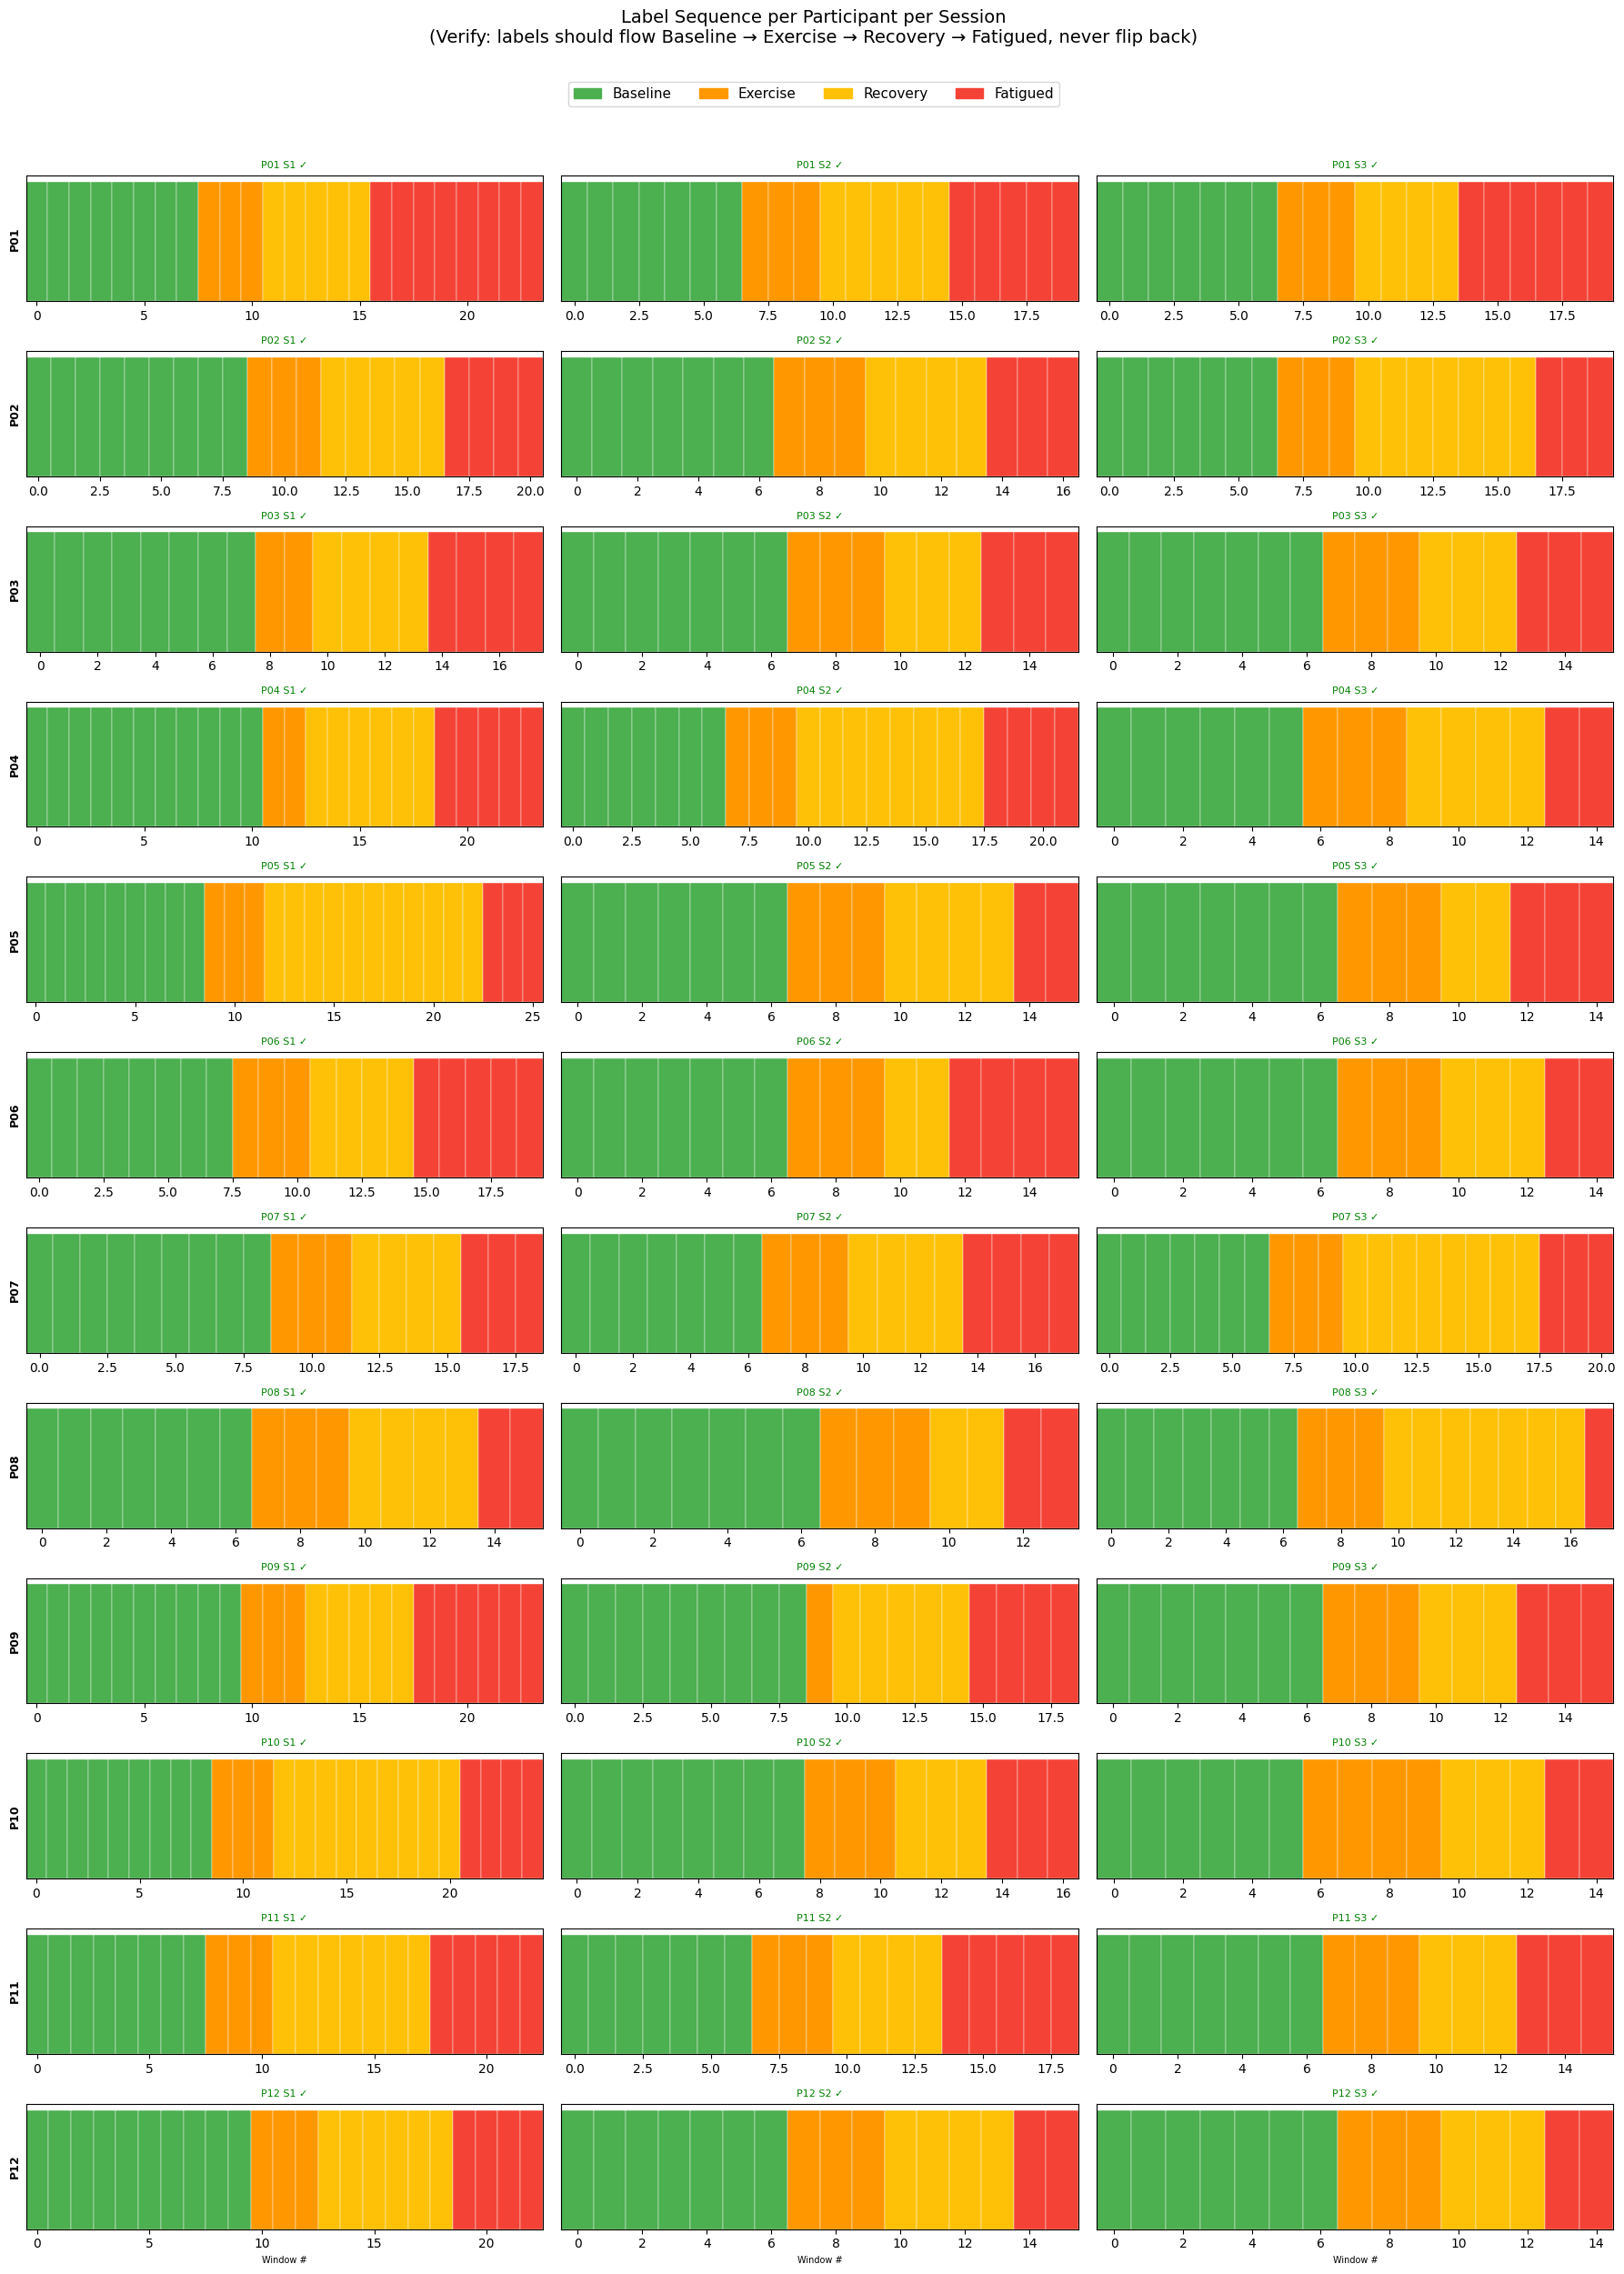


  Total sessions checked: 36
  Sessions with flip-flopping: 0
  ✓ NO FLIP-FLOPPING DETECTED — labels flow in correct chronological order


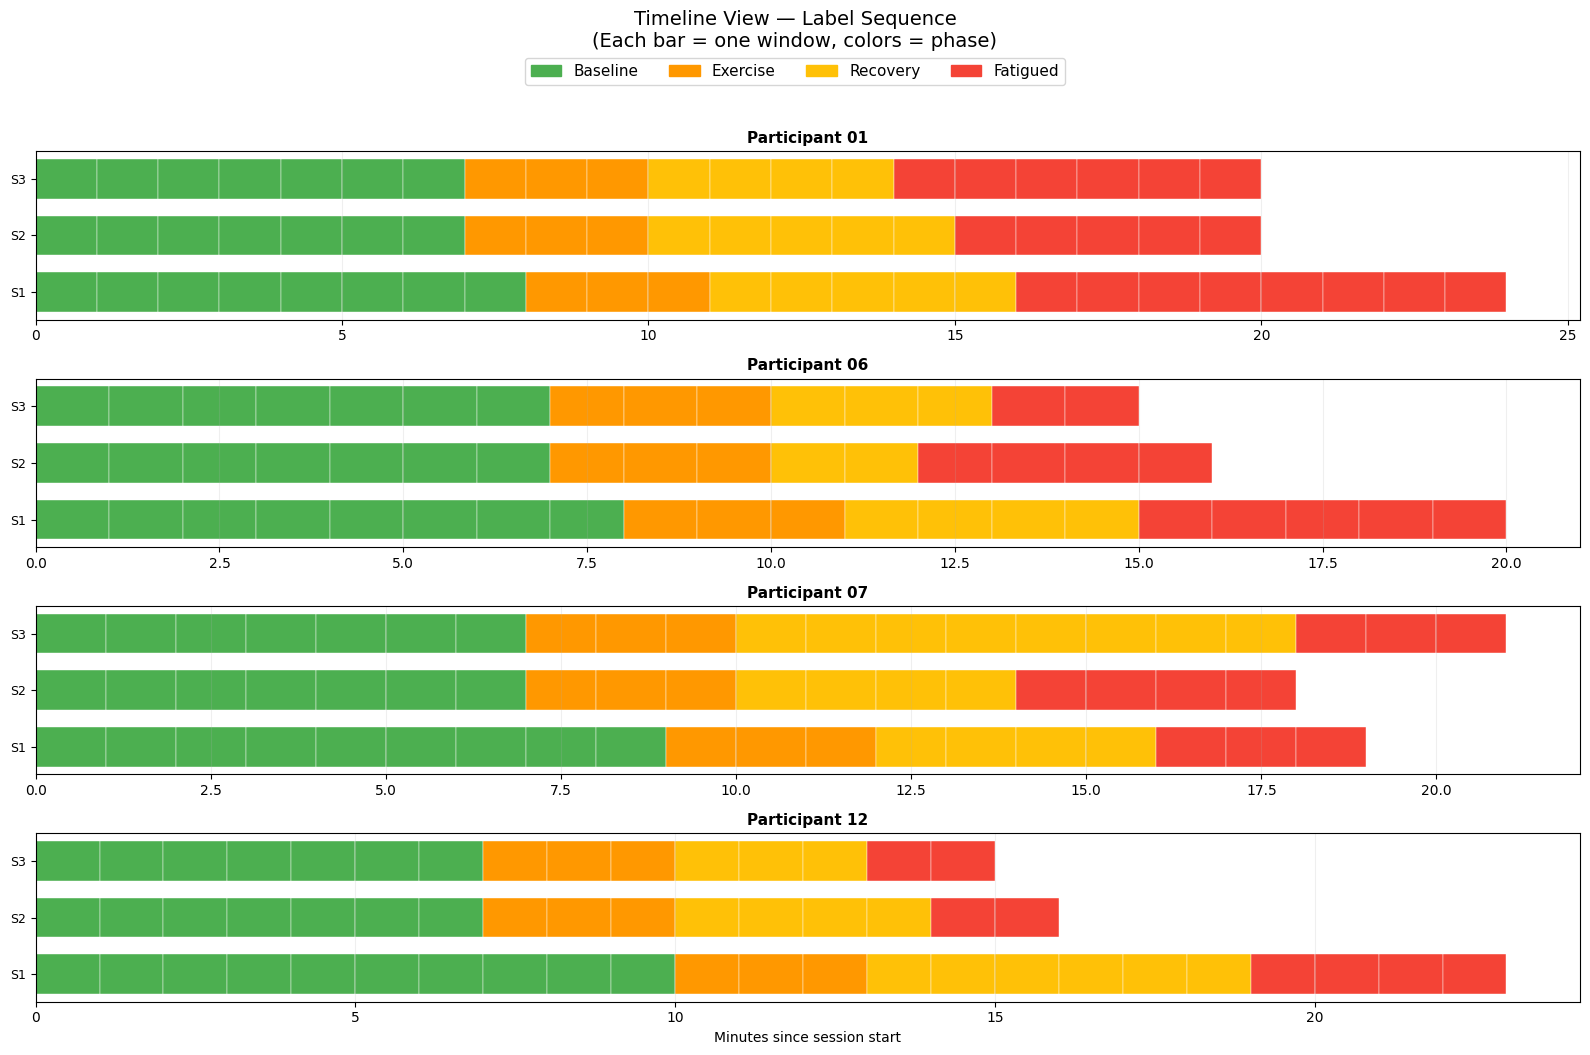


  Phase transitions per participant:
   PID | Session | Label sequence
  ------------------------------------------------------------
  P01  | S1     | baseline → exercise → recovery → fatigued
  P01  | S2     | baseline → exercise → recovery → fatigued
  P01  | S3     | baseline → exercise → recovery → fatigued
  P02  | S1     | baseline → exercise → recovery → fatigued
  P02  | S2     | baseline → exercise → recovery → fatigued
  P02  | S3     | baseline → exercise → recovery → fatigued
  P03  | S1     | baseline → exercise → recovery → fatigued
  P03  | S2     | baseline → exercise → recovery → fatigued
  P03  | S3     | baseline → exercise → recovery → fatigued
  P04  | S1     | baseline → exercise → recovery → fatigued
  P04  | S2     | baseline → exercise → recovery → fatigued
  P04  | S3     | baseline → exercise → recovery → fatigued
  P05  | S1     | baseline → exercise → recovery → fatigued
  P05  | S2     | baseline → exercise → recovery → fatigued
  P05  | S3     | baselin

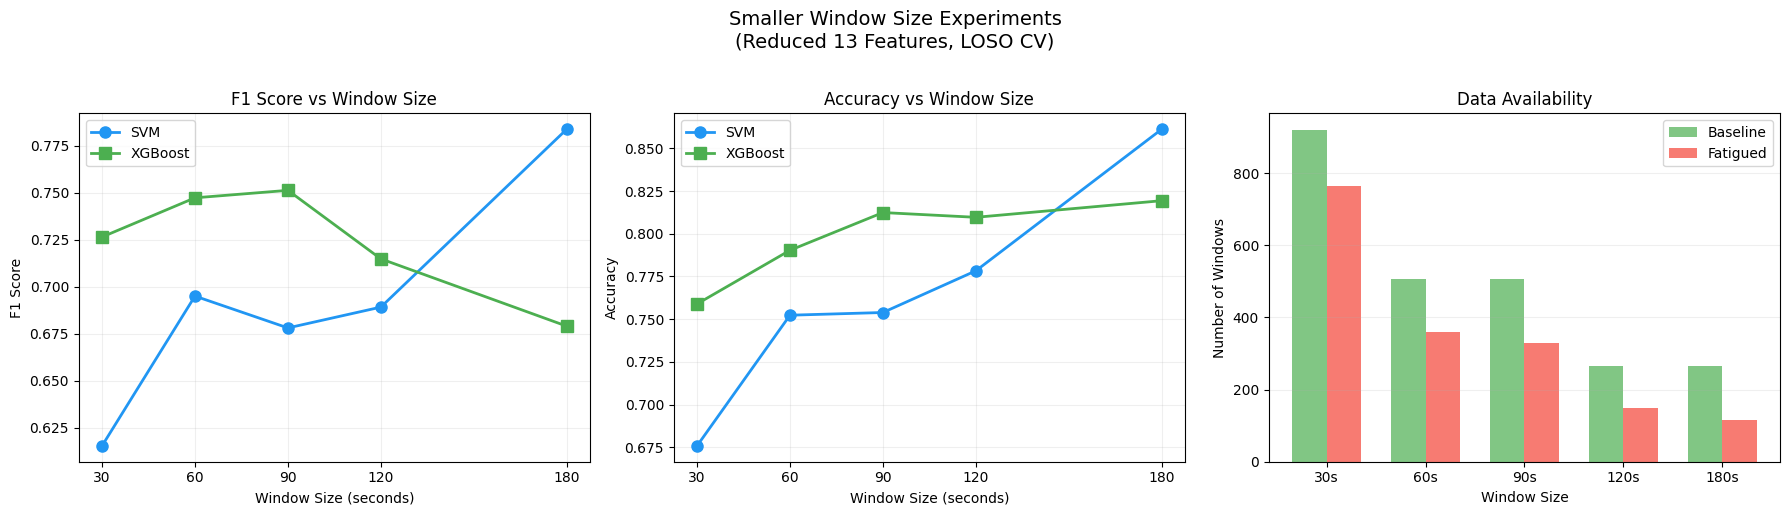

In [3]:
"""
LABEL SEQUENCE VERIFICATION + SMALLER WINDOW EXPERIMENT

1. Plot the label for each window in chronological order
   per participant per session — verify no flip-flopping
2. Test smaller windows (30s, 60s, 90s, 120s) with the best model
"""

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from scipy.signal import welch
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

# ============================================================
# CONFIG
# ============================================================
DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]

ALL_WINDOWS_CSV = Path("combined_all_windows.csv")
TRAINING_CSV = Path("training_dataset.csv")

REDUCED_FEATURES = [
    "temp_change_from_baseline", "temp_range", "temp_std",
    "temp_slope", "temp_min",
    "sdhr", "cv_rr", "triangular_index", "max_hr",
    "vlf_power", "mean_rr", "min_hr", "pnn50",
]

MAX_RR_MS = 2000
MIN_RR_MS = 300
MAX_RR_DIFF_MS = 300
MIN_RR_IN_WINDOW = 30


# LOAD MARKERS
def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events



# PART 1: FLIP-FLOP CHART

"""
For each participant × session, plot the label of each window
in chronological order. Labels should go:
    baseline → excluded → fatigued
Never: baseline → fatigued → baseline (that's flip-flopping)
"""

def plot_flipflop():
    
    print("=" * 70)
    print("PART 1: LABEL SEQUENCE VERIFICATION (FLIP-FLOP CHECK)")
    print("=" * 70)

    # Try loading from combined_all_windows.csv (has all phases)
    if ALL_WINDOWS_CSV.exists():
        df = pd.read_csv(ALL_WINDOWS_CSV)
        df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
        print(f"Loaded: {ALL_WINDOWS_CSV} ({len(df)} windows)")
    else:
        print(f"[ERROR] {ALL_WINDOWS_CSV} not found. Run combine_features.py first.")
        return

    # Assign detailed phase labels using markers
    df["phase_detailed"] = "unknown"

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            markers = load_markers(pid, sid)
            if not markers:
                continue

            baseline_start = markers.get("start_baseline")
            exercise_start = markers.get("start_activity")
            exercise_end = markers.get("end_activity")
            cognitive_start = markers.get("start_fatigue")
            session_end = markers.get("end_session")

            mask = (df["participant"] == pid) & (df["session"] == sid)

            for idx in df[mask].index:
                w_start = df.loc[idx, "window_start"]

                if cognitive_start and w_start >= cognitive_start:
                    df.loc[idx, "phase_detailed"] = "fatigued"
                elif exercise_end and cognitive_start and w_start >= exercise_end and w_start < cognitive_start:
                    df.loc[idx, "phase_detailed"] = "recovery"
                elif exercise_start and w_start >= exercise_start and (exercise_end is None or w_start < exercise_end):
                    df.loc[idx, "phase_detailed"] = "exercise"
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    df.loc[idx, "phase_detailed"] = "baseline"
                else:
                    df.loc[idx, "phase_detailed"] = "pre-baseline"

    # Color mapping
    phase_colors = {
        "baseline": "#4CAF50",      # green
        "exercise": "#FF9800",      # orange
        "recovery": "#FFC107",      # yellow
        "fatigued": "#F44336",      # red
        "pre-baseline": "#9E9E9E",  # grey
        "unknown": "#9E9E9E",       # grey
    }

    phase_values = {
        "pre-baseline": 0,
        "baseline": 1,
        "exercise": 2,
        "recovery": 3,
        "fatigued": 4,
        "unknown": -1,
    }

    fig, axes = plt.subplots(12, 3, figsize=(18, 24), sharex=False)

    flipflop_count = 0
    total_sessions = 0

    for pid_idx, pid in enumerate(range(1, N_PARTICIPANTS + 1)):
        for sid_idx, sid in enumerate(SESSIONS):
            ax = axes[pid_idx][sid_idx]

            sub = df[(df["participant"] == pid) & (df["session"] == sid)].sort_values("window_start")

            if sub.empty:
                ax.set_visible(False)
                continue

            total_sessions += 1

            # Calculate minutes from session start
            t_min = (sub["window_start"] - sub["window_start"].iloc[0]).dt.total_seconds() / 60.0

            # Plot each window as a colored bar
            phases = sub["phase_detailed"].values
            colors = [phase_colors.get(p, "#9E9E9E") for p in phases]
            y_vals = [phase_values.get(p, -1) for p in phases]

            ax.bar(range(len(phases)), [1] * len(phases), color=colors, width=1.0, edgecolor="white", linewidth=0.3)

            # Check for flip-flopping
            has_flipflop = False
            seen_fatigued = False
            for p in phases:
                if p == "fatigued":
                    seen_fatigued = True
                elif seen_fatigued and p == "baseline":
                    has_flipflop = True
                    flipflop_count += 1
                    break

            if has_flipflop:
                ax.set_title(f"P{pid:02d} S{sid} ⚠️ FLIP-FLOP", fontsize=8, color="red", fontweight="bold")
            else:
                ax.set_title(f"P{pid:02d} S{sid} ✓", fontsize=8, color="green")

            ax.set_yticks([])
            ax.set_xlim(-0.5, len(phases) - 0.5)

            if pid_idx == 11:
                ax.set_xlabel("Window #", fontsize=7)
            if sid_idx == 0:
                ax.set_ylabel(f"P{pid:02d}", fontsize=9, fontweight="bold")

    # Add legend
    legend_patches = [
        mpatches.Patch(color="#4CAF50", label="Baseline"),
        mpatches.Patch(color="#FF9800", label="Exercise"),
        mpatches.Patch(color="#FFC107", label="Recovery"),
        mpatches.Patch(color="#F44336", label="Fatigued"),
    ]
    fig.legend(handles=legend_patches, loc="upper center", ncol=4, fontsize=11,
               bbox_to_anchor=(0.5, 1.01))

    fig.suptitle("Label Sequence per Participant per Session\n"
                 "(Verify: labels should flow Baseline → Exercise → Recovery → Fatigued, never flip back)",
                 fontsize=14, y=1.04)
    plt.tight_layout()
    plt.show()

    print(f"\n  Total sessions checked: {total_sessions}")
    print(f"  Sessions with flip-flopping: {flipflop_count}")
    if flipflop_count == 0:
        print(f"  ✓ NO FLIP-FLOPPING DETECTED — labels flow in correct chronological order")
    else:
        print(f"  ⚠️ {flipflop_count} sessions have flip-flopping — investigate these")


    fig, axes = plt.subplots(4, 1, figsize=(16, 10))

    selected = [1, 6, 7, 12]
    for i, pid in enumerate(selected):
        ax = axes[i]

        for sid in SESSIONS:
            sub = df[(df["participant"] == pid) & (df["session"] == sid)].sort_values("window_start")
            if sub.empty:
                continue

            t_min = (sub["window_start"] - sub["window_start"].iloc[0]).dt.total_seconds() / 60.0
            phases = sub["phase_detailed"].values
            y_offset = sid - 1  # Stack sessions vertically

            for j, (t, phase) in enumerate(zip(t_min, phases)):
                color = phase_colors.get(phase, "#9E9E9E")
                ax.barh(y_offset, 1, left=t, height=0.7, color=color, edgecolor="white", linewidth=0.3)

        ax.set_yticks([0, 1, 2])
        ax.set_yticklabels(["S1", "S2", "S3"], fontsize=9)
        ax.set_title(f"Participant {pid:02d}", fontsize=11, fontweight="bold")
        ax.set_xlabel("Minutes since session start" if i == 3 else "")
        ax.grid(True, alpha=0.2, axis="x")

    fig.legend(handles=legend_patches, loc="upper center", ncol=4, fontsize=11,
               bbox_to_anchor=(0.5, 1.01))
    fig.suptitle("Timeline View — Label Sequence\n"
                 "(Each bar = one window, colors = phase)",
                 fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

    # --- Print phase transition table ---
    print(f"\n  Phase transitions per participant:")
    print(f"  {'PID':>4} | {'Session':>7} | Label sequence")
    print(f"  {'-'*60}")

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            sub = df[(df["participant"] == pid) & (df["session"] == sid)].sort_values("window_start")
            if sub.empty:
                continue

            phases = sub["phase_detailed"].values
            # Compress consecutive same labels
            compressed = []
            for p in phases:
                if not compressed or compressed[-1] != p:
                    compressed.append(p)

            sequence = " → ".join(compressed)
            print(f"  P{pid:02d}  | S{sid}     | {sequence}")

    return df



# PART 2: SMALLER WINDOW EXPERIMENTS

def load_rr_intervals(pid, sid):
    rr_file = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "chest_rr_interval.csv"
    if not rr_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(rr_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df = df.rename(columns={"duration": "rr_ms"})
    df = df.dropna(subset=["rr_ms"]).sort_values("timestamp").reset_index(drop=True)
    df["participant"] = pid
    df["session"] = sid
    return df


def load_skin_temp(pid, sid):
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    temp_file = session_dir / "wrist_skin_temperature.csv"
    if pid == 2 and sid == 1:
        temp_file = session_dir / "wrist_skin_temperature2.csv"
    if not temp_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(temp_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    if "temperature" in df.columns:
        df = df.rename(columns={"temperature": "skin_temp"})
    elif "temp" in df.columns:
        df = df.rename(columns={"temp": "skin_temp"})
    df = (df.set_index("timestamp").sort_index().resample("1s")
            .mean(numeric_only=True).dropna(subset=["skin_temp"]).reset_index())
    return df


def clean_rr(rr):
    mask = (rr >= MIN_RR_MS) & (rr <= MAX_RR_MS)
    rr = rr[mask]
    if len(rr) < 3:
        return rr
    diffs = np.abs(np.diff(rr))
    keep = np.ones(len(rr), dtype=bool)
    for i in range(len(diffs)):
        if diffs[i] > MAX_RR_DIFF_MS:
            keep[i + 1] = False
    return rr[keep]


def compute_hrv_features(rr_raw, min_rr=None):
    if min_rr is None:
        min_rr = MIN_RR_IN_WINDOW
    rr = clean_rr(rr_raw)

    nan_result = {f: np.nan for f in [
        "mean_rr", "sdnn", "rmssd", "pnn50", "mean_hr", "min_hr", "max_hr",
        "sdhr", "range_rr", "cv_rr", "triangular_index",
        "vlf_power", "lf_power", "hf_power", "total_power",
        "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]}

    if len(rr) < min_rr:
        return nan_result

    diffs = np.diff(rr)
    mean_rr = np.mean(rr)
    sdnn = np.std(rr, ddof=1)
    rmssd = np.sqrt(np.mean(diffs ** 2))
    pnn50 = (np.sum(np.abs(diffs) > 50) / len(diffs)) * 100.0
    hr = 60000.0 / rr
    mean_hr, min_hr, max_hr = np.mean(hr), np.min(hr), np.max(hr)
    sdhr = np.std(hr, ddof=1)
    range_rr = np.max(rr) - np.min(rr)
    cv_rr = sdnn / mean_rr if mean_rr > 0 else np.nan

    bin_width = 1000.0 / 128.0
    if range_rr > 0:
        n_bins = max(int(range_rr / bin_width), 1)
        hc, _ = np.histogram(rr, bins=n_bins)
        triangular_index = len(rr) / np.max(hc) if np.max(hc) > 0 else np.nan
    else:
        triangular_index = np.nan

    def safe_ln(x):
        return np.log(x) if (x is not None and x > 0) else np.nan

    vlf, lf, hf = np.nan, np.nan, np.nan
    if len(rr) >= 20:
        t_s = np.cumsum(rr) / 1000.0
        t_s = t_s - t_s[0]
        fs = 4.0
        t_u = np.arange(t_s[0], t_s[-1], 1.0 / fs)
        if len(t_u) >= 32:
            try:
                fn = interp1d(t_s, rr, kind="cubic", fill_value="extrapolate")
                rr_u = fn(t_u) - np.mean(fn(t_u))
                nperseg = min(len(rr_u), 256)
                freqs, psd = welch(rr_u, fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
                vlf = float(np.trapz(psd[(freqs >= 0.003) & (freqs < 0.04)],
                                     freqs[(freqs >= 0.003) & (freqs < 0.04)])) if ((freqs >= 0.003) & (freqs < 0.04)).any() else np.nan
                lf = float(np.trapz(psd[(freqs >= 0.04) & (freqs < 0.15)],
                                    freqs[(freqs >= 0.04) & (freqs < 0.15)])) if ((freqs >= 0.04) & (freqs < 0.15)).any() else np.nan
                hf = float(np.trapz(psd[(freqs >= 0.15) & (freqs < 0.40)],
                                    freqs[(freqs >= 0.15) & (freqs < 0.40)])) if ((freqs >= 0.15) & (freqs < 0.40)).any() else np.nan
            except:
                pass

    total = (vlf or 0) + (lf or 0) + (hf or 0) if not (np.isnan(vlf) and np.isnan(lf) and np.isnan(hf)) else np.nan
    lf_hf = lf / hf if (hf and hf > 0) else np.nan
    lf_norm = (lf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan
    hf_norm = (hf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan

    return {
        "mean_rr": mean_rr, "sdnn": sdnn, "rmssd": rmssd, "pnn50": pnn50,
        "mean_hr": mean_hr, "min_hr": min_hr, "max_hr": max_hr, "sdhr": sdhr,
        "range_rr": range_rr, "cv_rr": cv_rr, "triangular_index": triangular_index,
        "vlf_power": vlf, "lf_power": lf, "hf_power": hf, "total_power": total,
        "lf_hf_ratio": lf_hf, "lf_norm": lf_norm, "hf_norm": hf_norm,
        "ln_vlf": safe_ln(vlf), "ln_lf": safe_ln(lf), "ln_hf": safe_ln(hf),
        "ln_total_power": safe_ln(total),
    }


def compute_temp_features(temp_vals):
    temp = temp_vals[np.isfinite(temp_vals)]
    if len(temp) < 5:
        return {"temp_mean": np.nan, "temp_slope": np.nan, "temp_std": np.nan,
                "temp_range": np.nan, "temp_min": np.nan}
    try:
        coeffs = np.polyfit(np.arange(len(temp)), temp, 1)
        slope = coeffs[0]
    except:
        slope = np.nan
    return {
        "temp_mean": np.mean(temp), "temp_slope": slope,
        "temp_std": np.std(temp, ddof=1), "temp_range": np.max(temp) - np.min(temp),
        "temp_min": np.min(temp),
    }


def build_dataset(window_sec, step_sec):
    """Build complete HRV+temp dataset for a given window size."""
    all_rows = []

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            df_rr = load_rr_intervals(pid, sid)
            df_temp = load_skin_temp(pid, sid)
            markers = load_markers(pid, sid)

            if df_rr.empty or not markers:
                continue

            baseline_start = markers.get("start_baseline")
            exercise_start = markers.get("start_activity")
            cognitive_start = markers.get("start_fatigue")

            t_start = df_rr["timestamp"].iloc[0]
            t_end = df_rr["timestamp"].iloc[-1]
            win_id = 0
            w_start = t_start

            # Adjust minimum RR count based on window size
            min_rr = max(int(window_sec * 0.3), 15)  # At least 30% of expected beats

            while w_start + pd.Timedelta(seconds=window_sec) <= t_end:
                w_end = w_start + pd.Timedelta(seconds=window_sec)

                # HRV
                rr_mask = (df_rr["timestamp"] >= w_start) & (df_rr["timestamp"] < w_end)
                rr_vals = df_rr.loc[rr_mask, "rr_ms"].to_numpy(dtype=float)
                hrv_feats = compute_hrv_features(rr_vals, min_rr=min_rr)

                # Temp
                if not df_temp.empty:
                    temp_mask = (df_temp["timestamp"] >= w_start) & (df_temp["timestamp"] < w_end)
                    temp_vals = df_temp.loc[temp_mask, "skin_temp"].to_numpy(dtype=float)
                    temp_feats = compute_temp_features(temp_vals)
                else:
                    temp_feats = {"temp_mean": np.nan, "temp_slope": np.nan,
                                  "temp_std": np.nan, "temp_range": np.nan, "temp_min": np.nan}

                # Label
                if cognitive_start and w_start >= cognitive_start:
                    phase = "fatigued"
                    label = 1
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    phase = "baseline"
                    label = 0
                else:
                    phase = "excluded"
                    label = -1

                row = {**hrv_feats, **temp_feats,
                       "participant": pid, "session": sid, "window_id": win_id,
                       "window_start": w_start, "phase": phase, "label": label}
                all_rows.append(row)
                win_id += 1
                w_start += pd.Timedelta(seconds=step_sec)

    df = pd.DataFrame(all_rows)

    if not df.empty:
        df["temp_change_from_baseline"] = df.groupby(["participant", "session"])["temp_mean"].transform(
            lambda s: s - s.iloc[0]
        )

    return df


def loso_cv(model_class, model_params, X, y, participants, scale=False):
    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []
    per_participant = {}

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        model = model_class(**model_params)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        all_preds.extend(y_pred)
        all_true.extend(y_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1, "n_samples": len(y_test)}

    all_preds = np.array(all_preds)
    all_true = np.array(all_true)

    return {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "confusion_matrix": confusion_matrix(all_true, all_preds),
        "per_participant": per_participant,
    }


def experiment_smaller_windows():
    print("\n" + "=" * 70)
    print("PART 2: SMALLER WINDOW EXPERIMENTS")
    print("=" * 70)

    # Window sizes to test (seconds)
    # step = half the window size for good overlap
    configs = [
        (30, 15),
        (60, 30),
        (90, 30),
        (120, 60),
        (180, 60),   # current best for comparison
    ]

    all_results = {}

    for window_sec, step_sec in configs:
        print(f"\n  --- Window: {window_sec}s, Step: {step_sec}s ---")
        print(f"  Extracting features...")

        df = build_dataset(window_sec, step_sec)
        df_train = df[df["label"] >= 0].copy()
        df_train = df_train.dropna(subset=REDUCED_FEATURES)

        n_base = (df_train["label"] == 0).sum()
        n_fat = (df_train["label"] == 1).sum()
        n_total = len(df_train)
        print(f"  Windows: {n_total} (baseline={n_base}, fatigued={n_fat})")

        if n_fat < 10 or n_base < 10:
            print(f"  [SKIP] Too few windows")
            continue

        X = df_train[REDUCED_FEATURES].values
        y = df_train["label"].values
        participants = df_train["participant"].values

        # SVM
        res_svm = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                                 "class_weight": "balanced", "random_state": 42},
                          X, y, participants, scale=True)

        # XGBoost
        if HAS_XGBOOST:
            res_xgb = loso_cv(XGBClassifier, {"n_estimators": 100, "max_depth": 4,
                               "learning_rate": 0.1, "random_state": 42,
                               "eval_metric": "logloss", "use_label_encoder": False,
                               "scale_pos_weight": 2.0}, X, y, participants)
        else:
            res_xgb = {"f1": 0, "accuracy": 0, "precision": 0, "recall": 0}

        all_results[window_sec] = {
            "SVM": res_svm,
            "XGBoost": res_xgb if HAS_XGBOOST else None,
            "n_total": n_total,
            "n_baseline": n_base,
            "n_fatigued": n_fat,
            "step_sec": step_sec,
        }

        print(f"  SVM:     F1={res_svm['f1']:.4f}, Acc={res_svm['accuracy']:.4f}, "
              f"Prec={res_svm['precision']:.4f}, Rec={res_svm['recall']:.4f}")
        if HAS_XGBOOST:
            print(f"  XGBoost: F1={res_xgb['f1']:.4f}, Acc={res_xgb['accuracy']:.4f}")

    # --- Summary table ---
    print(f"\n  {'Window':>8} | {'Step':>6} | {'Windows':>8} | {'Base':>6} | {'Fat':>6} | "
          f"{'SVM F1':>8} | {'SVM Acc':>8} | {'XGB F1':>8}")
    print(f"  {'-'*80}")

    for ws in sorted(all_results.keys()):
        r = all_results[ws]
        svm_f1 = r["SVM"]["f1"]
        svm_acc = r["SVM"]["accuracy"]
        xgb_f1 = r["XGBoost"]["f1"] if r["XGBoost"] else 0
        print(f"  {ws:>6}s | {r['step_sec']:>4}s | {r['n_total']:>8} | {r['n_baseline']:>6} | "
              f"{r['n_fatigued']:>6} | {svm_f1:>8.4f} | {svm_acc:>8.4f} | {xgb_f1:>8.4f}")

    # --- Plot ---
    valid_ws = sorted(all_results.keys())

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # F1 comparison
    ax = axes[0]
    svm_f1s = [all_results[ws]["SVM"]["f1"] for ws in valid_ws]
    ax.plot(valid_ws, svm_f1s, "o-", linewidth=2, markersize=8, label="SVM", color="#2196F3")
    if HAS_XGBOOST:
        xgb_f1s = [all_results[ws]["XGBoost"]["f1"] for ws in valid_ws]
        ax.plot(valid_ws, xgb_f1s, "s-", linewidth=2, markersize=8, label="XGBoost", color="#4CAF50")
    ax.set_xlabel("Window Size (seconds)")
    ax.set_ylabel("F1 Score")
    ax.set_title("F1 Score vs Window Size")
    ax.legend()
    ax.grid(True, alpha=0.2)
    ax.set_xticks(valid_ws)

    # Accuracy comparison
    ax = axes[1]
    svm_accs = [all_results[ws]["SVM"]["accuracy"] for ws in valid_ws]
    ax.plot(valid_ws, svm_accs, "o-", linewidth=2, markersize=8, label="SVM", color="#2196F3")
    if HAS_XGBOOST:
        xgb_accs = [all_results[ws]["XGBoost"]["accuracy"] for ws in valid_ws]
        ax.plot(valid_ws, xgb_accs, "s-", linewidth=2, markersize=8, label="XGBoost", color="#4CAF50")
    ax.set_xlabel("Window Size (seconds)")
    ax.set_ylabel("Accuracy")
    ax.set_title("Accuracy vs Window Size")
    ax.legend()
    ax.grid(True, alpha=0.2)
    ax.set_xticks(valid_ws)

    # Data availability
    ax = axes[2]
    n_bases = [all_results[ws]["n_baseline"] for ws in valid_ws]
    n_fats = [all_results[ws]["n_fatigued"] for ws in valid_ws]
    x = np.arange(len(valid_ws))
    width = 0.35
    ax.bar(x - width/2, n_bases, width, label="Baseline", color="#4CAF50", alpha=0.7)
    ax.bar(x + width/2, n_fats, width, label="Fatigued", color="#F44336", alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{ws}s" for ws in valid_ws])
    ax.set_xlabel("Window Size")
    ax.set_ylabel("Number of Windows")
    ax.set_title("Data Availability")
    ax.legend()
    ax.grid(True, alpha=0.2, axis="y")

    fig.suptitle("Smaller Window Size Experiments\n(Reduced 13 Features, LOSO CV)",
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    return all_results



# RUN
if __name__ == "__main__":
    print("=" * 70)
    print("FLIP-FLOP CHECK + SMALLER WINDOW EXPERIMENTS")
    print("=" * 70)

    # Part 1: Verify no flip-flopping
    df = plot_flipflop()

    # Part 2: Smaller windows
    print("\n[NOTE] Smaller window experiments will take several minutes...")
    ws_results = experiment_smaller_windows()


PART 1: PREDICTION FLIP-FLOP CHART (SVM 180s)


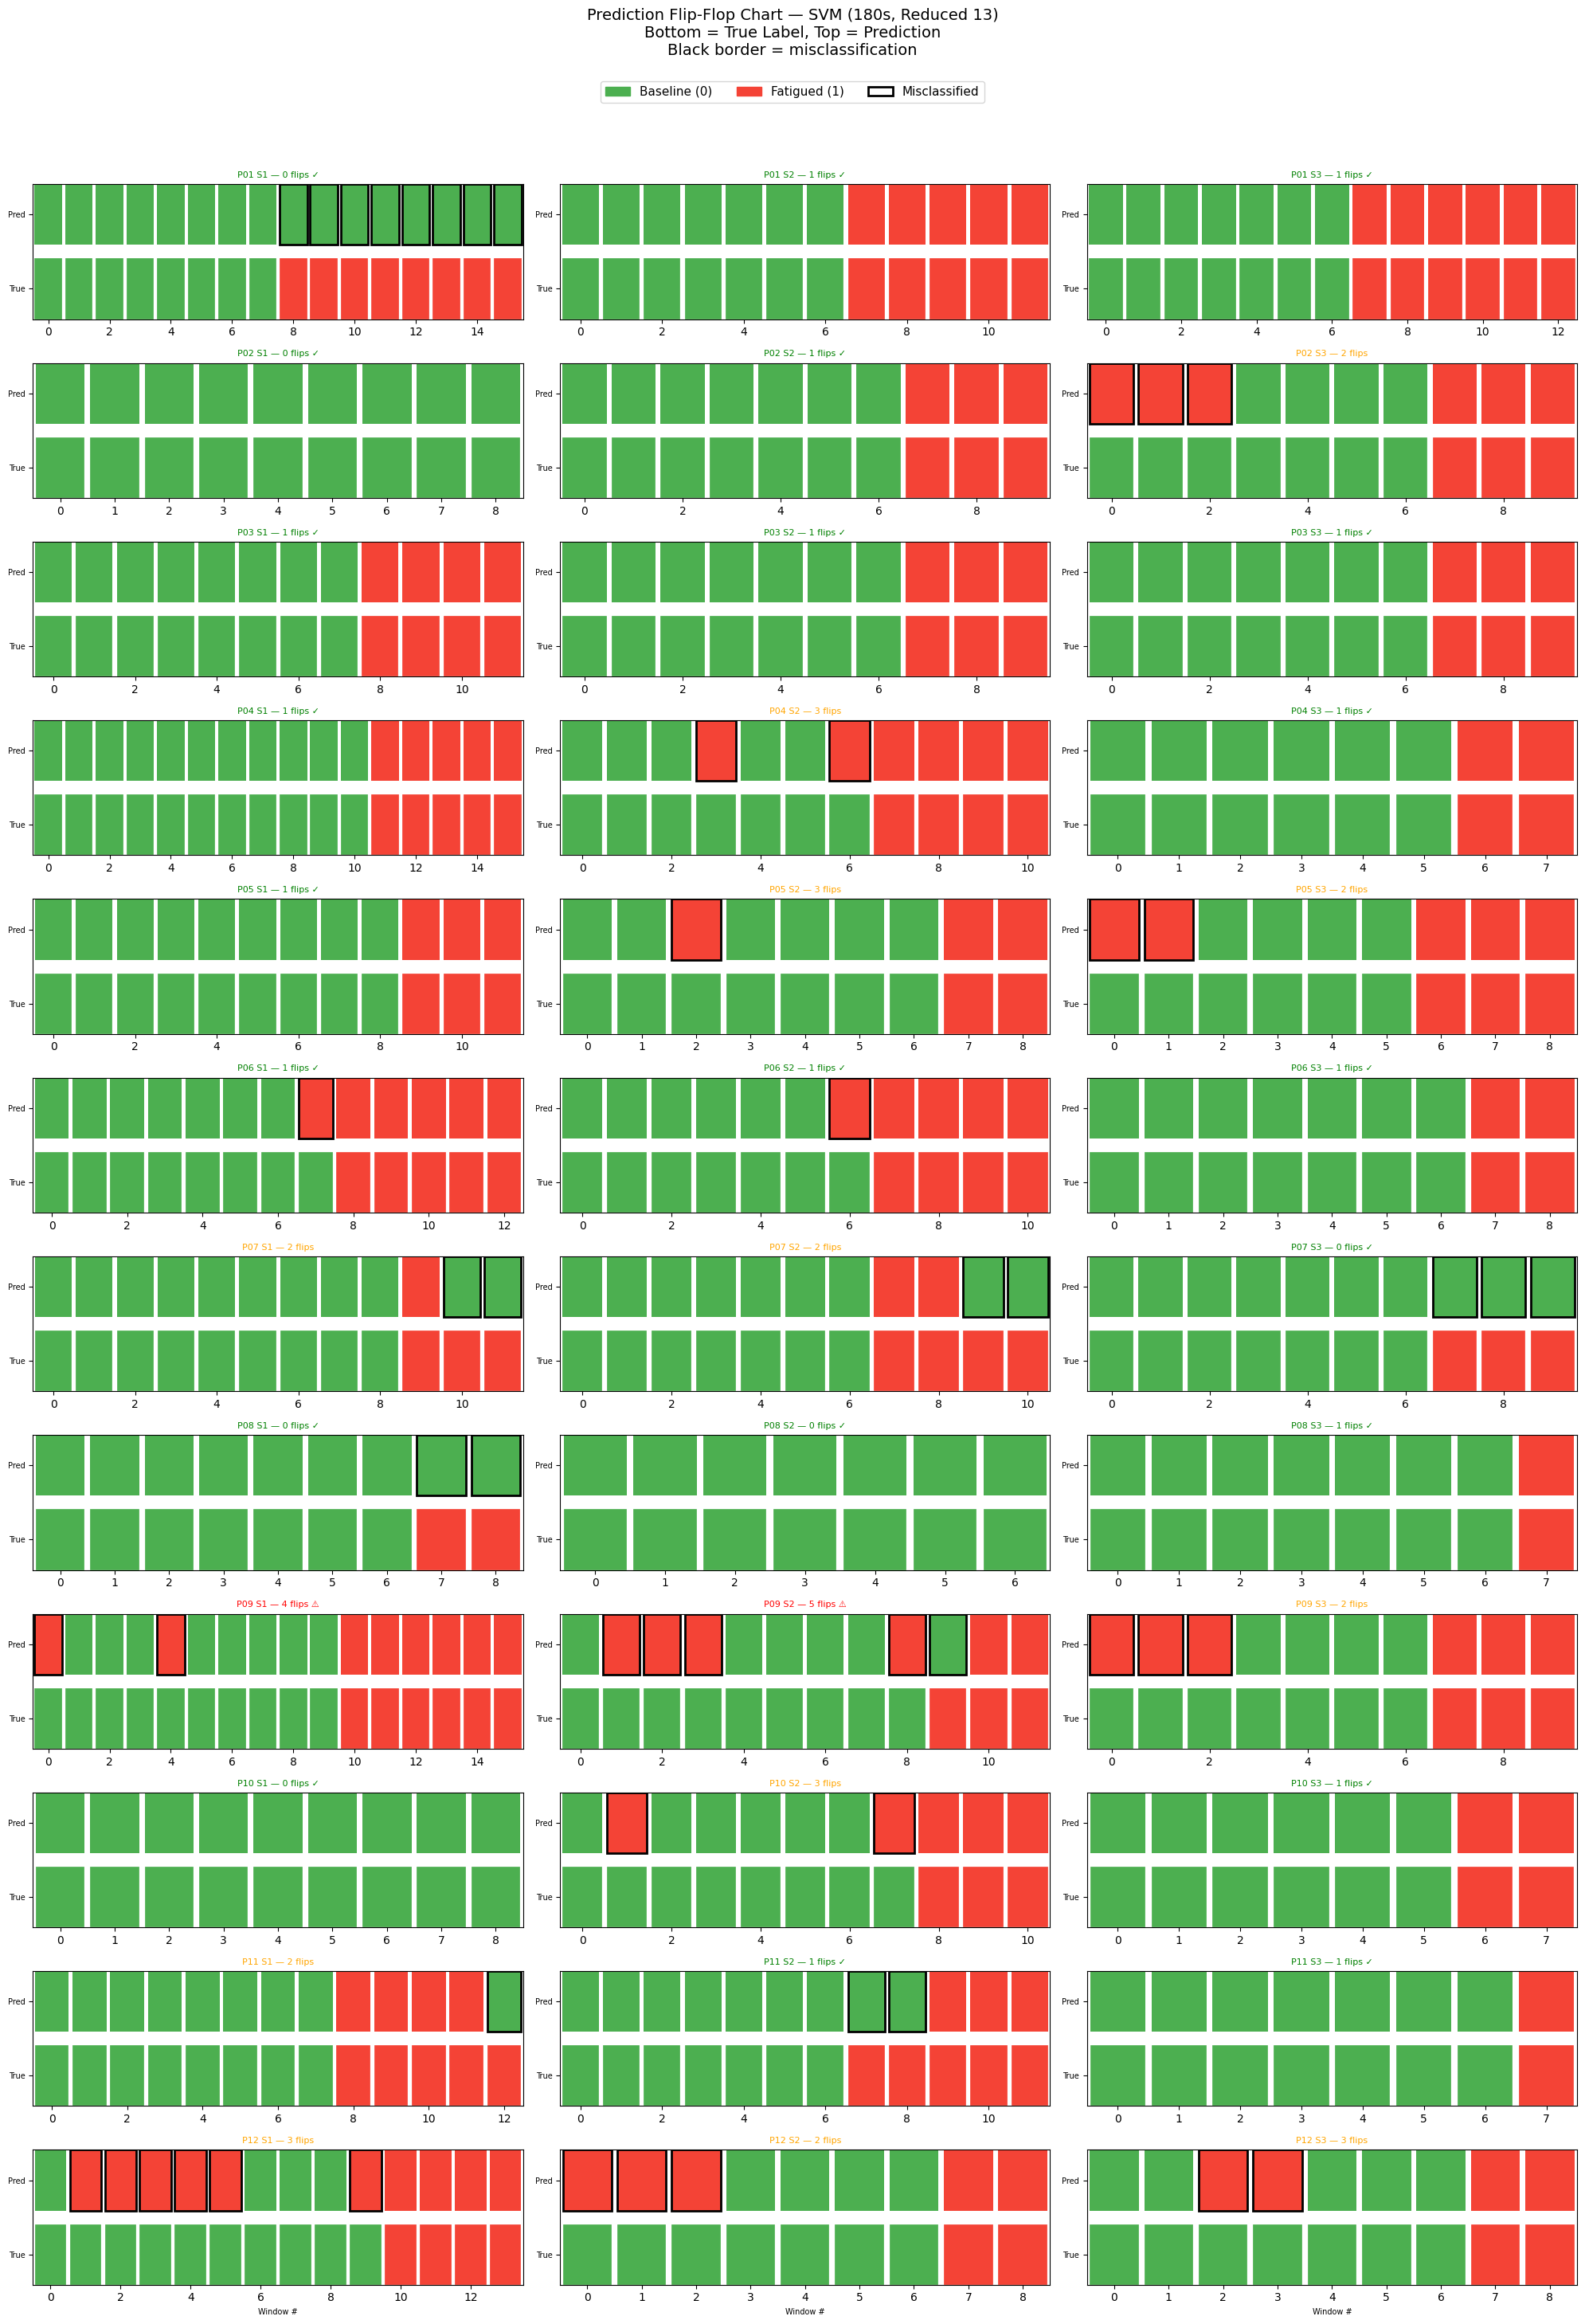

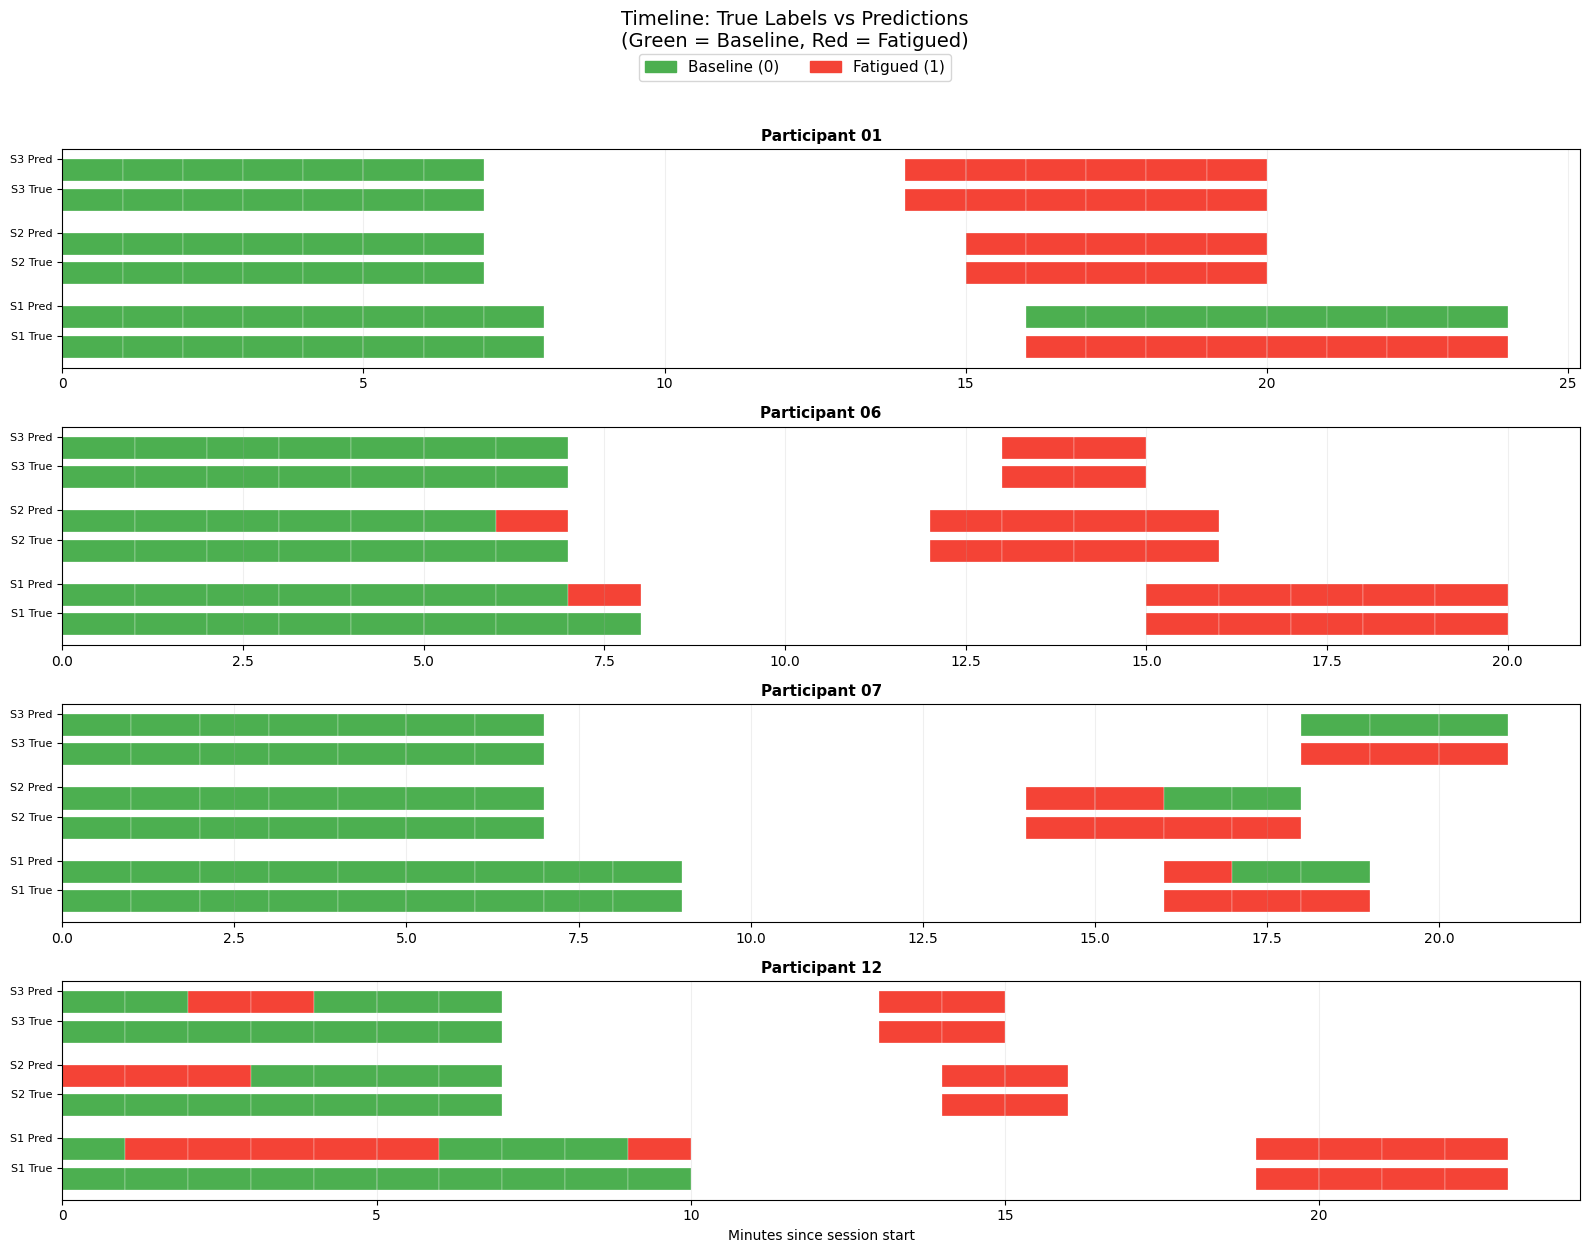


  Total sessions: 36
  Total prediction flips across all sessions: 54
  Average flips per session: 1.5

  Per-participant flip count:
   PID | S1 Flips | S2 Flips | S3 Flips |  Total
  --------------------------------------------------
  P01  |        0 |        1 |        1 |      2
  P02  |        0 |        1 |        2 |      3
  P03  |        1 |        1 |        1 |      3
  P04  |        1 |        3 |        1 |      5
  P05  |        1 |        3 |        2 |      6
  P06  |        1 |        1 |        1 |      3
  P07  |        2 |        2 |        0 |      4
  P08  |        0 |        0 |        1 |      1
  P09  |        4 |        5 |        2 |     11
  P10  |        0 |        3 |        1 |      4
  P11  |        2 |        1 |        1 |      4
  P12  |        3 |        2 |        3 |      8


In [2]:
"""
PREDICTION FLIP-FLOP CHART 
1. Train SVM (180s, reduced 13) with LOSO and plot predictions
   chronologically per participant per session — check if predictions
   flip back and forth
"""

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from scipy.signal import welch
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

try:
    import os
    os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import (Dense, Dropout, Conv1D, MaxPooling1D,
                                          LSTM, BatchNormalization,
                                          GlobalAveragePooling1D)
    from tensorflow.keras.callbacks import EarlyStopping
    HAS_TF = True
    tf.get_logger().setLevel('ERROR')
except ImportError:
    HAS_TF = False

DATA_ROOT = Path("fatigueset")
TRAINING_CSV = Path("training_dataset.csv")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]

REDUCED_FEATURES = [
    "temp_change_from_baseline", "temp_range", "temp_std",
    "temp_slope", "temp_min",
    "sdhr", "cv_rr", "triangular_index", "max_hr",
    "vlf_power", "mean_rr", "min_hr", "pnn50",
]

MAX_RR_MS = 2000
MIN_RR_MS = 300
MAX_RR_DIFF_MS = 300


def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events


def load_rr_intervals(pid, sid):
    rr_file = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "chest_rr_interval.csv"
    if not rr_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(rr_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df = df.rename(columns={"duration": "rr_ms"})
    df = df.dropna(subset=["rr_ms"]).sort_values("timestamp").reset_index(drop=True)
    return df


def load_skin_temp(pid, sid):
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    temp_file = session_dir / "wrist_skin_temperature.csv"
    if pid == 2 and sid == 1:
        temp_file = session_dir / "wrist_skin_temperature2.csv"
    if not temp_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(temp_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    if "temperature" in df.columns:
        df = df.rename(columns={"temperature": "skin_temp"})
    elif "temp" in df.columns:
        df = df.rename(columns={"temp": "skin_temp"})
    df = (df.set_index("timestamp").sort_index().resample("1s")
            .mean(numeric_only=True).dropna(subset=["skin_temp"]).reset_index())
    return df


def clean_rr(rr):
    mask = (rr >= MIN_RR_MS) & (rr <= MAX_RR_MS)
    rr = rr[mask]
    if len(rr) < 3:
        return rr
    diffs = np.abs(np.diff(rr))
    keep = np.ones(len(rr), dtype=bool)
    for i in range(len(diffs)):
        if diffs[i] > MAX_RR_DIFF_MS:
            keep[i + 1] = False
    return rr[keep]


def compute_hrv_features(rr_raw, min_rr=30):
    rr = clean_rr(rr_raw)
    nan_result = {f: np.nan for f in [
        "mean_rr", "sdnn", "rmssd", "pnn50", "mean_hr", "min_hr", "max_hr",
        "sdhr", "range_rr", "cv_rr", "triangular_index",
        "vlf_power", "lf_power", "hf_power", "total_power",
        "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]}
    if len(rr) < min_rr:
        return nan_result

    diffs = np.diff(rr)
    mean_rr = np.mean(rr)
    sdnn = np.std(rr, ddof=1)
    rmssd = np.sqrt(np.mean(diffs ** 2))
    pnn50 = (np.sum(np.abs(diffs) > 50) / len(diffs)) * 100.0
    hr = 60000.0 / rr
    mean_hr, min_hr, max_hr = np.mean(hr), np.min(hr), np.max(hr)
    sdhr = np.std(hr, ddof=1)
    range_rr = np.max(rr) - np.min(rr)
    cv_rr = sdnn / mean_rr if mean_rr > 0 else np.nan
    bin_width = 1000.0 / 128.0
    if range_rr > 0:
        n_bins = max(int(range_rr / bin_width), 1)
        hc, _ = np.histogram(rr, bins=n_bins)
        triangular_index = len(rr) / np.max(hc) if np.max(hc) > 0 else np.nan
    else:
        triangular_index = np.nan

    def safe_ln(x):
        return np.log(x) if (x is not None and x > 0) else np.nan

    vlf, lf, hf = np.nan, np.nan, np.nan
    if len(rr) >= 20:
        t_s = np.cumsum(rr) / 1000.0
        t_s = t_s - t_s[0]
        fs = 4.0
        t_u = np.arange(t_s[0], t_s[-1], 1.0 / fs)
        if len(t_u) >= 32:
            try:
                fn = interp1d(t_s, rr, kind="cubic", fill_value="extrapolate")
                rr_u = fn(t_u) - np.mean(fn(t_u))
                nperseg = min(len(rr_u), 256)
                freqs, psd = welch(rr_u, fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
                vlf = float(np.trapz(psd[(freqs >= 0.003) & (freqs < 0.04)],
                                     freqs[(freqs >= 0.003) & (freqs < 0.04)])) if ((freqs >= 0.003) & (freqs < 0.04)).any() else np.nan
                lf = float(np.trapz(psd[(freqs >= 0.04) & (freqs < 0.15)],
                                    freqs[(freqs >= 0.04) & (freqs < 0.15)])) if ((freqs >= 0.04) & (freqs < 0.15)).any() else np.nan
                hf = float(np.trapz(psd[(freqs >= 0.15) & (freqs < 0.40)],
                                    freqs[(freqs >= 0.15) & (freqs < 0.40)])) if ((freqs >= 0.15) & (freqs < 0.40)).any() else np.nan
            except:
                pass

    total = (vlf or 0) + (lf or 0) + (hf or 0) if not (np.isnan(vlf) and np.isnan(lf) and np.isnan(hf)) else np.nan
    lf_hf = lf / hf if (hf and hf > 0) else np.nan
    lf_norm = (lf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan
    hf_norm = (hf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan

    return {
        "mean_rr": mean_rr, "sdnn": sdnn, "rmssd": rmssd, "pnn50": pnn50,
        "mean_hr": mean_hr, "min_hr": min_hr, "max_hr": max_hr, "sdhr": sdhr,
        "range_rr": range_rr, "cv_rr": cv_rr, "triangular_index": triangular_index,
        "vlf_power": vlf, "lf_power": lf, "hf_power": hf, "total_power": total,
        "lf_hf_ratio": lf_hf, "lf_norm": lf_norm, "hf_norm": hf_norm,
        "ln_vlf": safe_ln(vlf), "ln_lf": safe_ln(lf), "ln_hf": safe_ln(hf),
        "ln_total_power": safe_ln(total),
    }


def compute_temp_features(temp_vals):
    temp = temp_vals[np.isfinite(temp_vals)]
    if len(temp) < 5:
        return {"temp_mean": np.nan, "temp_slope": np.nan, "temp_std": np.nan,
                "temp_range": np.nan, "temp_min": np.nan}
    try:
        coeffs = np.polyfit(np.arange(len(temp)), temp, 1)
        slope = coeffs[0]
    except:
        slope = np.nan
    return {
        "temp_mean": np.mean(temp), "temp_slope": slope,
        "temp_std": np.std(temp, ddof=1), "temp_range": np.max(temp) - np.min(temp),
        "temp_min": np.min(temp),
    }



# PART 1: PREDICTION FLIP-FLOP CHART (180s SVM)

"""
Train SVM with LOSO, collect predictions for each window,
then plot the PREDICTION sequence chronologically.
"""
def prediction_flipflop():
   
    print("=" * 70)
    print("PART 1: PREDICTION FLIP-FLOP CHART (SVM 180s)")
    print("=" * 70)

    # Load training data
    df = pd.read_csv(TRAINING_CSV)
    df["window_start"] = pd.to_datetime(df["window_start"], utc=True)
    df = df.dropna(subset=REDUCED_FEATURES)

    y = df["label"].values
    participants = df["participant"].values
    X = df[REDUCED_FEATURES].values

    # LOSO — collect predictions WITH metadata
    unique_pids = sorted(set(participants))
    prediction_records = []

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_test_s = scaler.transform(X_test)

        svm = SVC(kernel="rbf", C=5.0, gamma="scale",
                  class_weight="balanced", random_state=42)
        svm.fit(X_train_s, y_train)
        y_pred = svm.predict(X_test_s)

        # Store predictions with session info
        test_df = df[test_mask].copy()
        test_df["prediction"] = y_pred

        for _, row in test_df.iterrows():
            prediction_records.append({
                "participant": int(row["participant"]),
                "session": int(row["session"]),
                "window_start": row["window_start"],
                "true_label": int(row["label"]),
                "prediction": int(row["prediction"]),
            })

    pred_df = pd.DataFrame(prediction_records)
    pred_df = pred_df.sort_values(["participant", "session", "window_start"])

    fig, axes = plt.subplots(12, 3, figsize=(20, 28))

    total_flipflops = 0
    total_sessions = 0

    for pid_idx, pid in enumerate(range(1, N_PARTICIPANTS + 1)):
        for sid_idx, sid in enumerate(SESSIONS):
            ax = axes[pid_idx][sid_idx]

            sub = pred_df[(pred_df["participant"] == pid) & (pred_df["session"] == sid)]
            sub = sub.sort_values("window_start")

            if sub.empty:
                ax.set_visible(False)
                continue

            total_sessions += 1
            n_windows = len(sub)

            # Plot each window as two stacked bars:
            # Bottom: true label, Top: prediction
            for j, (_, row) in enumerate(sub.iterrows()):
                # True label (bottom half)
                true_color = "#4CAF50" if row["true_label"] == 0 else "#F44336"
                # Prediction (top half)
                pred_color = "#4CAF50" if row["prediction"] == 0 else "#F44336"
                # Border if wrong
                edge_color = "black" if row["true_label"] != row["prediction"] else "none"
                edge_width = 2 if row["true_label"] != row["prediction"] else 0

                ax.bar(j, 0.45, bottom=0, color=true_color, width=0.9,
                       edgecolor="white", linewidth=0.2)
                ax.bar(j, 0.45, bottom=0.55, color=pred_color, width=0.9,
                       edgecolor=edge_color, linewidth=edge_width)

            # Count flip-flops in predictions
            preds = sub["prediction"].values
            flips = 0
            for j in range(1, len(preds)):
                if preds[j] != preds[j-1]:
                    flips += 1

            total_flipflops += flips

            # Title
            if flips <= 1:
                ax.set_title(f"P{pid:02d} S{sid} — {flips} flips ✓", fontsize=8, color="green")
            elif flips <= 3:
                ax.set_title(f"P{pid:02d} S{sid} — {flips} flips", fontsize=8, color="orange")
            else:
                ax.set_title(f"P{pid:02d} S{sid} — {flips} flips ⚠️", fontsize=8, color="red")

            ax.set_xlim(-0.5, n_windows - 0.5)
            ax.set_ylim(0, 1)
            ax.set_yticks([0.225, 0.775])
            ax.set_yticklabels(["True", "Pred"], fontsize=7)

            if pid_idx == 11:
                ax.set_xlabel("Window #", fontsize=7)

    legend_patches = [
        mpatches.Patch(color="#4CAF50", label="Baseline (0)"),
        mpatches.Patch(color="#F44336", label="Fatigued (1)"),
        mpatches.Patch(facecolor="white", edgecolor="black", linewidth=2, label="Misclassified"),
    ]
    fig.legend(handles=legend_patches, loc="upper center", ncol=3, fontsize=11,
               bbox_to_anchor=(0.5, 1.01))
    fig.suptitle("Prediction Flip-Flop Chart — SVM (180s, Reduced 13)\n"
                 "Bottom = True Label, Top = Prediction\n"
                 "Black border = misclassification",
                 fontsize=14, y=1.04)
    plt.tight_layout()
    plt.show()

    # --- Plot 2: Simplified timeline for selected participants ---
    fig, axes = plt.subplots(4, 1, figsize=(16, 12))
    selected = [1, 6, 7, 12]

    for i, pid in enumerate(selected):
        ax = axes[i]

        for sid in SESSIONS:
            sub = pred_df[(pred_df["participant"] == pid) & (pred_df["session"] == sid)]
            sub = sub.sort_values("window_start")

            if sub.empty:
                continue

            t_min = (sub["window_start"] - sub["window_start"].iloc[0]).dt.total_seconds() / 60.0
            y_offset_true = (sid - 1) * 2
            y_offset_pred = (sid - 1) * 2 + 0.8

            for j, (_, row) in enumerate(sub.iterrows()):
                t = t_min.iloc[j]
                true_color = "#4CAF50" if row["true_label"] == 0 else "#F44336"
                pred_color = "#4CAF50" if row["prediction"] == 0 else "#F44336"

                ax.barh(y_offset_true, 1, left=t, height=0.6, color=true_color,
                        edgecolor="white", linewidth=0.2)
                ax.barh(y_offset_pred, 1, left=t, height=0.6, color=pred_color,
                        edgecolor="white", linewidth=0.2)

        ax.set_yticks([0.3, 1.1, 2.3, 3.1, 4.3, 5.1])
        ax.set_yticklabels(["S1 True", "S1 Pred", "S2 True", "S2 Pred",
                            "S3 True", "S3 Pred"], fontsize=8)
        ax.set_title(f"Participant {pid:02d}", fontsize=11, fontweight="bold")
        ax.grid(True, alpha=0.2, axis="x")
        if i == 3:
            ax.set_xlabel("Minutes since session start")

    fig.legend(handles=legend_patches[:2], loc="upper center", ncol=2, fontsize=11,
               bbox_to_anchor=(0.5, 1.01))
    fig.suptitle("Timeline: True Labels vs Predictions\n"
                 "(Green = Baseline, Red = Fatigued)",
                 fontsize=14, y=1.04)
    plt.tight_layout()
    plt.show()

    print(f"\n  Total sessions: {total_sessions}")
    print(f"  Total prediction flips across all sessions: {total_flipflops}")
    print(f"  Average flips per session: {total_flipflops / total_sessions:.1f}")

    # Per-participant flip count
    print(f"\n  Per-participant flip count:")
    print(f"  {'PID':>4} | {'S1 Flips':>8} | {'S2 Flips':>8} | {'S3 Flips':>8} | {'Total':>6}")
    print(f"  {'-'*50}")

    for pid in range(1, N_PARTICIPANTS + 1):
        flip_counts = []
        for sid in SESSIONS:
            sub = pred_df[(pred_df["participant"] == pid) & (pred_df["session"] == sid)]
            sub = sub.sort_values("window_start")
            if sub.empty:
                flip_counts.append(0)
                continue
            preds = sub["prediction"].values
            flips = sum(1 for j in range(1, len(preds)) if preds[j] != preds[j-1])
            flip_counts.append(flips)

        print(f"  P{pid:02d}  | {flip_counts[0]:>8} | {flip_counts[1]:>8} | {flip_counts[2]:>8} | {sum(flip_counts):>6}")

    return pred_df


# RUN
if __name__ == "__main__":
    # Part 1: Prediction flip-flop
    pred_df = prediction_flipflop()

Loading TensorFlow...
TensorFlow loaded: 2.21.0
AUTOENCODER + MLP + SMALLER WINDOWS (MULTI-SEED)
Seeds: [42, 43, 44, 45, 46]

WINDOW: 30s (step 15s)
    Extracting features (30s windows, 15s step)...
  Windows: 1684 (baseline=920, fatigued=764)

  1. SVM (raw 13 features) — deterministic:
     F1=0.6155

  2. MLP (raw 13 features) — 5 seeds:
        Seed 42: F1=0.6791
        Seed 43: F1=0.6653
        Seed 44: F1=0.6896
        Seed 45: F1=0.6829
        Seed 46: F1=0.6894
     Mean: F1=0.6812 ± 0.0089

  3. AE(5) + SVM — 5 seeds:
        Seed 42: F1=0.6488
        Seed 43: F1=0.6287
        Seed 44: F1=0.6038
        Seed 45: F1=0.6348
        Seed 46: F1=0.6329
     Mean: F1=0.6298 ± 0.0147

  4. AE(5) + MLP — 5 seeds:
        Seed 42: F1=0.6227
        Seed 43: F1=0.6351
        Seed 44: F1=0.6432
        Seed 45: F1=0.6540
        Seed 46: F1=0.6716
     Mean: F1=0.6453 ± 0.0167

  5. AE(7) + SVM — 5 seeds:
        Seed 42: F1=0.6765
        Seed 43: F1=0.6722
        Seed 44: F1=

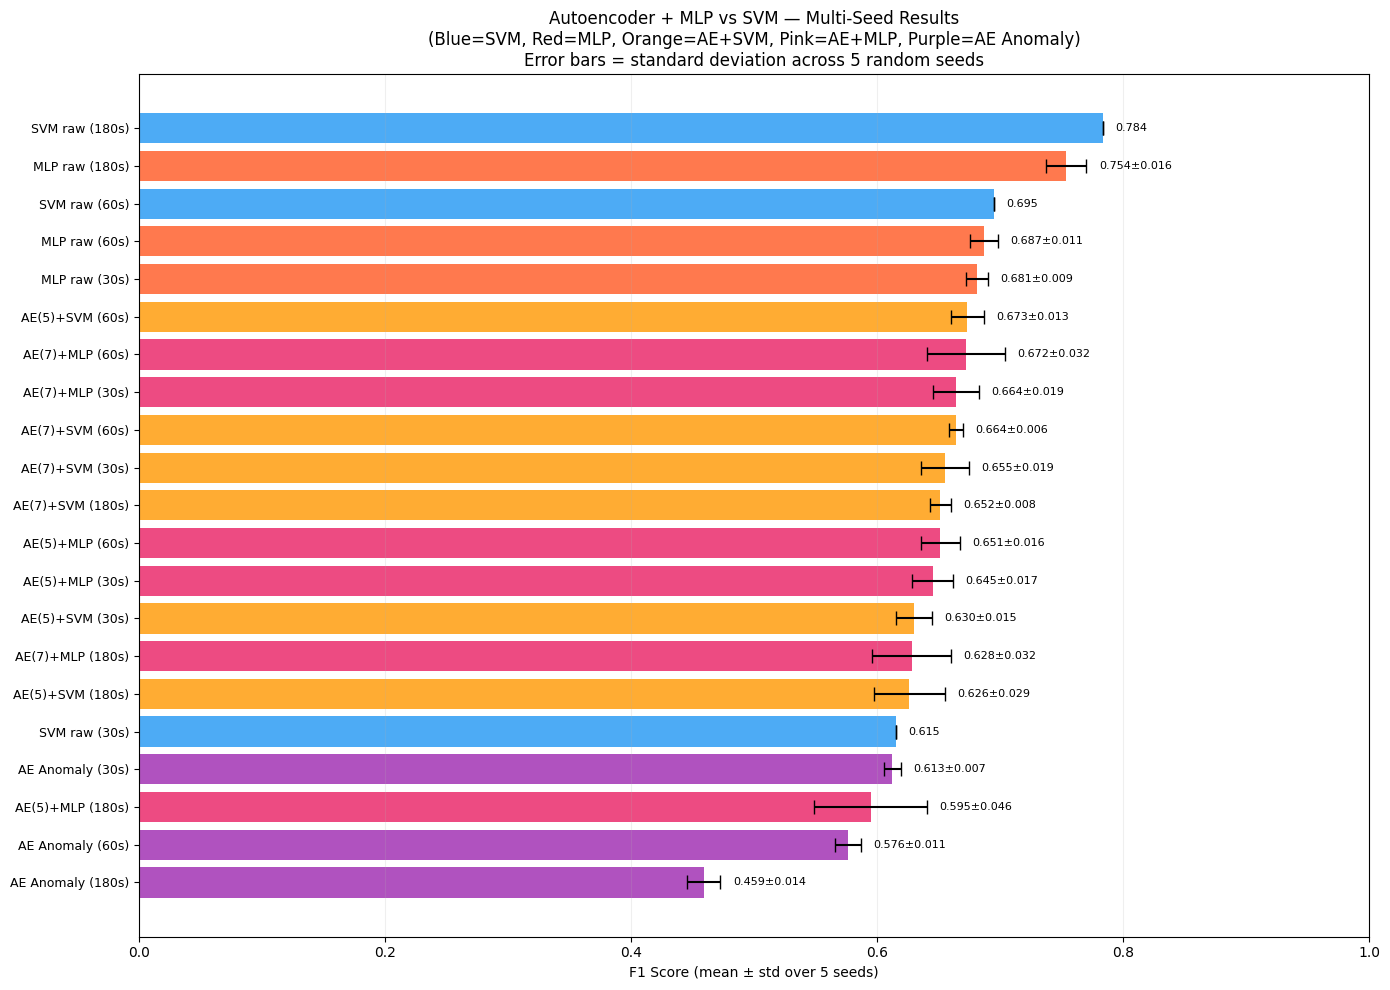


  Summary by window size:
    Window |      SVM raw |      MLP raw |      AE5+SVM |      AE5+MLP |      AE7+SVM |      AE7+MLP |      Anomaly
  --------------------------------------------------------------------------------------------------------------
      30s | 0.6155      | 0.681±0.009 | 0.630±0.015 | 0.645±0.017 | 0.655±0.019 | 0.664±0.019 | 0.613±0.007 |
      60s | 0.6950      | 0.687±0.011 | 0.673±0.013 | 0.651±0.016 | 0.664±0.006 | 0.672±0.032 | 0.576±0.011 |
     180s | 0.7837      | 0.754±0.016 | 0.626±0.029 | 0.595±0.046 | 0.652±0.008 | 0.628±0.032 | 0.459±0.014 |

  Best without AE:  SVM raw (180s), F1=0.7837
  Best with AE:     AE(5)+SVM (60s), F1=0.6735

  → Raw features still BETTER by +0.1102
    Autoencoder compression does not improve upon hand-crafted features

  For your dissertation:
  'Autoencoder-based feature compression was evaluated with bottleneck
   dimensions of 5 and 7, combined with both SVM and MLP classifiers.
   Results were averaged over 5 random 

In [ ]:
"""
AUTOENCODER + MLP + SMALLER WINDOWS (MULTI-SEED)

Combines everything:
  1. Extract features at different window sizes (30s, 60s, 180s)
  2. Autoencoder compresses features → bottleneck
  3. MLP classifies using compressed features (5 seeds for consistency)
  4. Compare: SVM raw vs SVM+AE vs MLP raw vs MLP+AE vs AE Anomaly

All DL models run 5 times with fixed seeds [42,43,44,45,46]
"""

from pathlib import Path
import pandas as pd
import numpy as np
from scipy.signal import welch
from scipy.interpolate import interp1d
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

print("Loading TensorFlow...")
try:
    import tensorflow as tf
    from tensorflow.keras.models import Model, Sequential
    from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization
    from tensorflow.keras.callbacks import EarlyStopping
    HAS_TF = True
    tf.get_logger().setLevel('ERROR')
    print(f"TensorFlow loaded: {tf.__version__}")
except ImportError:
    print("[ERROR] TensorFlow not installed")
    HAS_TF = False

DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]
SEEDS = [42, 43, 44, 45, 46]

REDUCED_FEATURES = [
    "temp_change_from_baseline", "temp_range", "temp_std",
    "temp_slope", "temp_min",
    "sdhr", "cv_rr", "triangular_index", "max_hr",
    "vlf_power", "mean_rr", "min_hr", "pnn50",
]

MAX_RR_MS = 2000
MIN_RR_MS = 300
MAX_RR_DIFF_MS = 300


def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events


def load_rr_intervals(pid, sid):
    rr_file = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "chest_rr_interval.csv"
    if not rr_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(rr_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df = df.rename(columns={"duration": "rr_ms"})
    df = df.dropna(subset=["rr_ms"]).sort_values("timestamp").reset_index(drop=True)
    return df


def load_skin_temp(pid, sid):
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    temp_file = session_dir / "wrist_skin_temperature.csv"
    if pid == 2 and sid == 1:
        temp_file = session_dir / "wrist_skin_temperature2.csv"
    if not temp_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(temp_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    if "temperature" in df.columns:
        df = df.rename(columns={"temperature": "skin_temp"})
    elif "temp" in df.columns:
        df = df.rename(columns={"temp": "skin_temp"})
    df = (df.set_index("timestamp").sort_index().resample("1s")
            .mean(numeric_only=True).dropna(subset=["skin_temp"]).reset_index())
    return df


def clean_rr(rr):
    mask = (rr >= MIN_RR_MS) & (rr <= MAX_RR_MS)
    rr = rr[mask]
    if len(rr) < 3:
        return rr
    diffs = np.abs(np.diff(rr))
    keep = np.ones(len(rr), dtype=bool)
    for i in range(len(diffs)):
        if diffs[i] > MAX_RR_DIFF_MS:
            keep[i + 1] = False
    return rr[keep]


def compute_hrv_features(rr_raw, min_rr=15):
    rr = clean_rr(rr_raw)
    nan_result = {f: np.nan for f in [
        "mean_rr", "sdnn", "rmssd", "pnn50", "mean_hr", "min_hr", "max_hr",
        "sdhr", "range_rr", "cv_rr", "triangular_index",
        "vlf_power", "lf_power", "hf_power", "total_power",
        "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]}
    if len(rr) < min_rr:
        return nan_result

    diffs = np.diff(rr)
    mean_rr = np.mean(rr)
    sdnn = np.std(rr, ddof=1)
    rmssd = np.sqrt(np.mean(diffs ** 2))
    pnn50 = (np.sum(np.abs(diffs) > 50) / len(diffs)) * 100.0
    hr = 60000.0 / rr
    mean_hr, min_hr, max_hr = np.mean(hr), np.min(hr), np.max(hr)
    sdhr = np.std(hr, ddof=1)
    range_rr = np.max(rr) - np.min(rr)
    cv_rr = sdnn / mean_rr if mean_rr > 0 else np.nan
    bin_width = 1000.0 / 128.0
    if range_rr > 0:
        n_bins = max(int(range_rr / bin_width), 1)
        hc, _ = np.histogram(rr, bins=n_bins)
        triangular_index = len(rr) / np.max(hc) if np.max(hc) > 0 else np.nan
    else:
        triangular_index = np.nan

    def safe_ln(x):
        return np.log(x) if (x is not None and x > 0) else np.nan

    vlf, lf, hf = np.nan, np.nan, np.nan
    if len(rr) >= 20:
        t_s = np.cumsum(rr) / 1000.0
        t_s = t_s - t_s[0]
        fs = 4.0
        t_u = np.arange(t_s[0], t_s[-1], 1.0 / fs)
        if len(t_u) >= 32:
            try:
                fn = interp1d(t_s, rr, kind="cubic", fill_value="extrapolate")
                rr_u = fn(t_u) - np.mean(fn(t_u))
                nperseg = min(len(rr_u), 256)
                freqs, psd = welch(rr_u, fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
                vlf = float(np.trapz(psd[(freqs >= 0.003) & (freqs < 0.04)],
                                     freqs[(freqs >= 0.003) & (freqs < 0.04)])) if ((freqs >= 0.003) & (freqs < 0.04)).any() else np.nan
                lf = float(np.trapz(psd[(freqs >= 0.04) & (freqs < 0.15)],
                                    freqs[(freqs >= 0.04) & (freqs < 0.15)])) if ((freqs >= 0.04) & (freqs < 0.15)).any() else np.nan
                hf = float(np.trapz(psd[(freqs >= 0.15) & (freqs < 0.40)],
                                    freqs[(freqs >= 0.15) & (freqs < 0.40)])) if ((freqs >= 0.15) & (freqs < 0.40)).any() else np.nan
            except:
                pass

    total = (vlf or 0) + (lf or 0) + (hf or 0) if not (np.isnan(vlf) and np.isnan(lf) and np.isnan(hf)) else np.nan
    lf_hf = lf / hf if (hf and hf > 0) else np.nan
    lf_norm = (lf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan
    hf_norm = (hf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan

    return {
        "mean_rr": mean_rr, "sdnn": sdnn, "rmssd": rmssd, "pnn50": pnn50,
        "mean_hr": mean_hr, "min_hr": min_hr, "max_hr": max_hr, "sdhr": sdhr,
        "range_rr": range_rr, "cv_rr": cv_rr, "triangular_index": triangular_index,
        "vlf_power": vlf, "lf_power": lf, "hf_power": hf, "total_power": total,
        "lf_hf_ratio": lf_hf, "lf_norm": lf_norm, "hf_norm": hf_norm,
        "ln_vlf": safe_ln(vlf), "ln_lf": safe_ln(lf), "ln_hf": safe_ln(hf),
        "ln_total_power": safe_ln(total),
    }


def compute_temp_features(temp_vals):
    temp = temp_vals[np.isfinite(temp_vals)]
    if len(temp) < 5:
        return {"temp_mean": np.nan, "temp_slope": np.nan, "temp_std": np.nan,
                "temp_range": np.nan, "temp_min": np.nan}
    try:
        coeffs = np.polyfit(np.arange(len(temp)), temp, 1)
        slope = coeffs[0]
    except:
        slope = np.nan
    return {
        "temp_mean": np.mean(temp), "temp_slope": slope,
        "temp_std": np.std(temp, ddof=1), "temp_range": np.max(temp) - np.min(temp),
        "temp_min": np.min(temp),
    }


def build_dataset(window_sec, step_sec):
    print(f"    Extracting features ({window_sec}s windows, {step_sec}s step)...")
    all_rows = []
    min_rr = max(int(window_sec * 0.3), 10)

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            df_rr = load_rr_intervals(pid, sid)
            df_temp = load_skin_temp(pid, sid)
            markers = load_markers(pid, sid)
            if df_rr.empty or not markers:
                continue

            baseline_start = markers.get("start_baseline")
            exercise_start = markers.get("start_activity")
            cognitive_start = markers.get("start_fatigue")

            t_start = df_rr["timestamp"].iloc[0]
            t_end = df_rr["timestamp"].iloc[-1]
            win_id = 0
            w_start = t_start

            while w_start + pd.Timedelta(seconds=window_sec) <= t_end:
                w_end = w_start + pd.Timedelta(seconds=window_sec)

                rr_mask = (df_rr["timestamp"] >= w_start) & (df_rr["timestamp"] < w_end)
                rr_vals = df_rr.loc[rr_mask, "rr_ms"].to_numpy(dtype=float)
                hrv_feats = compute_hrv_features(rr_vals, min_rr=min_rr)

                if not df_temp.empty:
                    temp_mask = (df_temp["timestamp"] >= w_start) & (df_temp["timestamp"] < w_end)
                    temp_vals = df_temp.loc[temp_mask, "skin_temp"].to_numpy(dtype=float)
                    temp_feats = compute_temp_features(temp_vals)
                else:
                    temp_feats = {"temp_mean": np.nan, "temp_slope": np.nan,
                                  "temp_std": np.nan, "temp_range": np.nan, "temp_min": np.nan}

                if cognitive_start and w_start >= cognitive_start:
                    label = 1
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    label = 0
                else:
                    label = -1

                row = {**hrv_feats, **temp_feats,
                       "participant": pid, "session": sid, "window_id": win_id,
                       "window_start": w_start, "label": label}
                all_rows.append(row)
                win_id += 1
                w_start += pd.Timedelta(seconds=step_sec)

    df = pd.DataFrame(all_rows)
    if not df.empty:
        df["temp_change_from_baseline"] = df.groupby(["participant", "session"])["temp_mean"].transform(
            lambda s: s - s.iloc[0]
        )
    return df


def build_autoencoder(input_dim, bottleneck_dim):
    encoder_input = Input(shape=(input_dim,))
    x = Dense(16, activation='relu')(encoder_input)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)
    bottleneck = Dense(bottleneck_dim, activation='relu', name='bottleneck')(x)
    x = Dense(16, activation='relu')(bottleneck)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)
    decoder_output = Dense(input_dim, activation='linear')(x)

    autoencoder = Model(encoder_input, decoder_output)
    autoencoder.compile(optimizer='adam', loss='mse')
    encoder = Model(encoder_input, bottleneck)
    return autoencoder, encoder


def build_mlp(input_shape):
    model = Sequential([
        Dense(64, activation='relu', input_shape=input_shape),
        BatchNormalization(), Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(), Dropout(0.3),
        Dense(16, activation='relu'), Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_anomaly_ae(input_dim):
    model = Sequential([
        Dense(16, activation='relu', input_shape=(input_dim,)),
        BatchNormalization(), Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(5, activation='relu', name='bottleneck'),
        Dense(8, activation='relu'),
        BatchNormalization(),
        Dense(16, activation='relu'),
        Dense(input_dim, activation='linear')
    ])
    model.compile(optimizer='adam', loss='mse')
    return model


def loso_svm(X, y, participants):
    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid
        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]
        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue
        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_test_s = scaler.transform(X_test)
        svm = SVC(kernel="rbf", C=5.0, gamma="scale", class_weight="balanced", random_state=42)
        svm.fit(X_train_s, y_train)
        all_preds.extend(svm.predict(X_test_s))
        all_true.extend(y_test)

    return {
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "accuracy": accuracy_score(all_true, all_preds),
    }


def loso_mlp(X, y, participants, seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid
        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]
        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_test_s = scaler.transform(X_test)

        n_neg = (y_train == 0).sum()
        n_pos = (y_train == 1).sum()
        cw = {0: 1.0, 1: n_neg / n_pos if n_pos > 0 else 1.0}

        model = build_mlp(X_train_s.shape[1:])
        model.fit(X_train_s, y_train, epochs=100, batch_size=16,
                  class_weight=cw,
                  callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                  verbose=0)

        y_prob = model.predict(X_test_s, verbose=0).flatten()
        y_pred = (y_prob >= 0.5).astype(int)
        all_preds.extend(y_pred)
        all_true.extend(y_test)
        tf.keras.backend.clear_session()

    return {
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "accuracy": accuracy_score(all_true, all_preds),
    }


def loso_ae_svm(X, y, participants, bottleneck_dim, seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid
        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]
        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_test_s = scaler.transform(X_test)

        # Train autoencoder
        ae, encoder = build_autoencoder(X_train_s.shape[1], bottleneck_dim)
        ae.fit(X_train_s, X_train_s, epochs=100, batch_size=16,
               validation_split=0.15,
               callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
               verbose=0)

        # Compress
        X_train_comp = encoder.predict(X_train_s, verbose=0)
        X_test_comp = encoder.predict(X_test_s, verbose=0)

        # SVM on compressed features
        svm = SVC(kernel="rbf", C=5.0, gamma="scale", class_weight="balanced", random_state=42)
        svm.fit(X_train_comp, y_train)
        all_preds.extend(svm.predict(X_test_comp))
        all_true.extend(y_test)
        tf.keras.backend.clear_session()

    return {
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "accuracy": accuracy_score(all_true, all_preds),
    }

def loso_ae_mlp(X, y, participants, bottleneck_dim, seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid
        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]
        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_test_s = scaler.transform(X_test)

        # Train autoencoder
        ae, encoder = build_autoencoder(X_train_s.shape[1], bottleneck_dim)
        ae.fit(X_train_s, X_train_s, epochs=100, batch_size=16,
               validation_split=0.15,
               callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
               verbose=0)

        # Compress
        X_train_comp = encoder.predict(X_train_s, verbose=0)
        X_test_comp = encoder.predict(X_test_s, verbose=0)

        # MLP on compressed features
        n_neg = (y_train == 0).sum()
        n_pos = (y_train == 1).sum()
        cw = {0: 1.0, 1: n_neg / n_pos if n_pos > 0 else 1.0}

        mlp = build_mlp(X_train_comp.shape[1:])
        mlp.fit(X_train_comp, y_train, epochs=100, batch_size=16,
                class_weight=cw,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0)

        y_prob = mlp.predict(X_test_comp, verbose=0).flatten()
        y_pred = (y_prob >= 0.5).astype(int)
        all_preds.extend(y_pred)
        all_true.extend(y_test)
        tf.keras.backend.clear_session()

    return {
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "accuracy": accuracy_score(all_true, all_preds),
    }


def loso_anomaly(X, y, participants, seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

    unique_pids = sorted(set(participants))
    all_errors, all_true = [], []

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid
        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]
        if len(X_test) == 0:
            continue

        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_test_s = scaler.transform(X_test)

        # Train ONLY on baseline
        X_baseline = X_train_s[y_train == 0]

        ae = build_anomaly_ae(X_train_s.shape[1])
        ae.fit(X_baseline, X_baseline, epochs=100, batch_size=16,
               validation_split=0.15,
               callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
               verbose=0)

        X_recon = ae.predict(X_test_s, verbose=0)
        errors = np.mean((X_test_s - X_recon) ** 2, axis=1)

        all_errors.extend(errors)
        all_true.extend(y_test)
        tf.keras.backend.clear_session()

    all_errors = np.array(all_errors)
    all_true = np.array(all_true)

    # Find best threshold
    best_f1 = 0
    for thresh in np.percentile(all_errors, np.arange(10, 95, 5)):
        y_pred = (all_errors > thresh).astype(int)
        f1 = f1_score(all_true, y_pred, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1

    return {"f1": best_f1, "accuracy": 0, "errors": all_errors, "true": all_true}


def run_multi_seed(func, X, y, participants, seeds=SEEDS, **kwargs):
    """Run a stochastic model multiple times and return mean ± std."""
    f1_scores = []
    for seed in seeds:
        res = func(X, y, participants, seed=seed, **kwargs)
        f1_scores.append(res["f1"])
        print(f"        Seed {seed}: F1={res['f1']:.4f}")

    return {
        "f1_mean": np.mean(f1_scores),
        "f1_std": np.std(f1_scores),
        "f1_all": f1_scores,
        "f1_min": np.min(f1_scores),
        "f1_max": np.max(f1_scores),
    }


# ============================================================
# RUN ALL
# ============================================================
def run_all():
    print("=" * 70)
    print("AUTOENCODER + MLP + SMALLER WINDOWS (MULTI-SEED)")
    print(f"Seeds: {SEEDS}")
    print("=" * 70)

    if not HAS_TF:
        return

    window_configs = [
        (30, 15),
        (60, 30),
        (180, 60),
    ]

    all_results = {}

    for window_sec, step_sec in window_configs:
        print(f"\n{'='*60}")
        print(f"WINDOW: {window_sec}s (step {step_sec}s)")
        print(f"{'='*60}")

        df = build_dataset(window_sec, step_sec)
        df_train = df[df["label"] >= 0].dropna(subset=REDUCED_FEATURES)

        n_base = (df_train["label"] == 0).sum()
        n_fat = (df_train["label"] == 1).sum()
        print(f"  Windows: {len(df_train)} (baseline={n_base}, fatigued={n_fat})")

        if n_fat < 10:
            continue

        X = df_train[REDUCED_FEATURES].values
        y = df_train["label"].values
        p = df_train["participant"].values

        # === 1. SVM on raw features (deterministic) ===
        print(f"\n  1. SVM (raw 13 features) — deterministic:")
        res_svm = loso_svm(X, y, p)
        all_results[f"SVM raw ({window_sec}s)"] = {
            "f1_mean": res_svm["f1"], "f1_std": 0.0,
            "f1_min": res_svm["f1"], "f1_max": res_svm["f1"],
        }
        print(f"     F1={res_svm['f1']:.4f}")

        # === 2. MLP on raw features (5 seeds) ===
        print(f"\n  2. MLP (raw 13 features) — {len(SEEDS)} seeds:")
        res_mlp = run_multi_seed(loso_mlp, X, y, p)
        all_results[f"MLP raw ({window_sec}s)"] = res_mlp
        print(f"     Mean: F1={res_mlp['f1_mean']:.4f} ± {res_mlp['f1_std']:.4f}")

        # === 3. AE(5) + SVM (5 seeds for AE) ===
        print(f"\n  3. AE(5) + SVM — {len(SEEDS)} seeds:")
        res_ae5_svm = run_multi_seed(loso_ae_svm, X, y, p, bottleneck_dim=5)
        all_results[f"AE(5)+SVM ({window_sec}s)"] = res_ae5_svm
        print(f"     Mean: F1={res_ae5_svm['f1_mean']:.4f} ± {res_ae5_svm['f1_std']:.4f}")

        # === 4. AE(5) + MLP (5 seeds for both) ===
        print(f"\n  4. AE(5) + MLP — {len(SEEDS)} seeds:")
        res_ae5_mlp = run_multi_seed(loso_ae_mlp, X, y, p, bottleneck_dim=5)
        all_results[f"AE(5)+MLP ({window_sec}s)"] = res_ae5_mlp
        print(f"     Mean: F1={res_ae5_mlp['f1_mean']:.4f} ± {res_ae5_mlp['f1_std']:.4f}")

        # === 5. AE(7) + SVM (5 seeds) ===
        print(f"\n  5. AE(7) + SVM — {len(SEEDS)} seeds:")
        res_ae7_svm = run_multi_seed(loso_ae_svm, X, y, p, bottleneck_dim=7)
        all_results[f"AE(7)+SVM ({window_sec}s)"] = res_ae7_svm
        print(f"     Mean: F1={res_ae7_svm['f1_mean']:.4f} ± {res_ae7_svm['f1_std']:.4f}")

        # === 6. AE(7) + MLP (5 seeds) ===
        print(f"\n  6. AE(7) + MLP — {len(SEEDS)} seeds:")
        res_ae7_mlp = run_multi_seed(loso_ae_mlp, X, y, p, bottleneck_dim=7)
        all_results[f"AE(7)+MLP ({window_sec}s)"] = res_ae7_mlp
        print(f"     Mean: F1={res_ae7_mlp['f1_mean']:.4f} ± {res_ae7_mlp['f1_std']:.4f}")

        # === 7. AE Anomaly Detection (5 seeds) ===
        print(f"\n  7. AE Anomaly Detection — {len(SEEDS)} seeds:")
        res_anomaly = run_multi_seed(loso_anomaly, X, y, p)
        all_results[f"AE Anomaly ({window_sec}s)"] = res_anomaly
        print(f"     Mean: F1={res_anomaly['f1_mean']:.4f} ± {res_anomaly['f1_std']:.4f}")

    print(f"\n{'='*70}")
    print("FINAL COMPARISON — ALL CONFIGURATIONS (MULTI-SEED AVERAGED)")
    print(f"{'='*70}")

    sorted_results = sorted(all_results.items(),
                            key=lambda x: x[1]["f1_mean"], reverse=True)

    print(f"\n  {'Rank':>4} {'Config':<28} {'F1 (mean±std)':>18} {'Range':>16}")
    print(f"  {'-'*72}")

    for rank, (name, res) in enumerate(sorted_results, 1):
        if res["f1_std"] == 0:
            f1_str = f"{res['f1_mean']:.4f} (fixed)"
        else:
            f1_str = f"{res['f1_mean']:.4f} ± {res['f1_std']:.3f}"

        range_str = f"[{res['f1_min']:.3f}–{res['f1_max']:.3f}]"
        marker = " ← BEST" if rank == 1 else ""

        print(f"  {rank:>4} {name:<28} {f1_str:>18} {range_str:>16}{marker}")

    # ============================================================
    # PLOT
    # ============================================================
    fig, ax = plt.subplots(figsize=(14, 10))

    names = [n for n, _ in sorted_results]
    means = [r["f1_mean"] for _, r in sorted_results]
    stds = [r["f1_std"] for _, r in sorted_results]

    colors = []
    for n in names:
        if "Anomaly" in n:
            colors.append("#9C27B0")
        elif "AE" in n and "MLP" in n:
            colors.append("#E91E63")
        elif "AE" in n and "SVM" in n:
            colors.append("#FF9800")
        elif "MLP" in n:
            colors.append("#FF5722")
        elif "SVM" in n:
            colors.append("#2196F3")
        else:
            colors.append("#9E9E9E")

    bars = ax.barh(range(len(names)), means, xerr=stds, color=colors, alpha=0.8,
                    capsize=5, ecolor="black")
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=9)
    ax.set_xlabel("F1 Score (mean ± std over 5 seeds)")
    ax.set_title("Autoencoder + MLP vs SVM — Multi-Seed Results\n"
                 "(Blue=SVM, Red=MLP, Orange=AE+SVM, Pink=AE+MLP, Purple=AE Anomaly)\n"
                 "Error bars = standard deviation across 5 random seeds",
                 fontsize=12)
    ax.set_xlim(0, 1.0)
    ax.grid(True, alpha=0.2, axis="x")
    ax.invert_yaxis()

    for i, (bar, mean, std) in enumerate(zip(bars, means, stds)):
        if std > 0:
            ax.text(mean + std + 0.01, bar.get_y() + bar.get_height()/2,
                    f"{mean:.3f}±{std:.3f}", va="center", fontsize=8)
        else:
            ax.text(mean + 0.01, bar.get_y() + bar.get_height()/2,
                    f"{mean:.3f}", va="center", fontsize=8)

    plt.tight_layout()
    plt.show()


    print(f"\n  Summary by window size:")
    print(f"  {'Window':>8} | {'SVM raw':>12} | {'MLP raw':>12} | {'AE5+SVM':>12} | {'AE5+MLP':>12} | {'AE7+SVM':>12} | {'AE7+MLP':>12} | {'Anomaly':>12}")
    print(f"  {'-'*110}")

    for ws, _ in window_configs:
        row = f"  {ws:>6}s |"
        for key_pattern in ["SVM raw", "MLP raw", "AE(5)+SVM", "AE(5)+MLP",
                             "AE(7)+SVM", "AE(7)+MLP", "AE Anomaly"]:
            full_key = f"{key_pattern} ({ws}s)"
            if full_key in all_results:
                r = all_results[full_key]
                if r["f1_std"] == 0:
                    row += f" {r['f1_mean']:.4f}      |"
                else:
                    row += f" {r['f1_mean']:.3f}±{r['f1_std']:.3f} |"
            else:
                row += f"     -       |"
        print(row)


    best_name, best_res = sorted_results[0]
    ae_results = {k: v for k, v in all_results.items() if "AE" in k}
    non_ae = {k: v for k, v in all_results.items() if "AE" not in k}

    best_ae = max(ae_results.items(), key=lambda x: x[1]["f1_mean"]) if ae_results else None
    best_non_ae = max(non_ae.items(), key=lambda x: x[1]["f1_mean"]) if non_ae else None

    print(f"\n  Best without AE:  {best_non_ae[0]}, F1={best_non_ae[1]['f1_mean']:.4f}")
    print(f"  Best with AE:     {best_ae[0]}, F1={best_ae[1]['f1_mean']:.4f}")

    if best_ae[1]["f1_mean"] > best_non_ae[1]["f1_mean"]:
        print(f"\n  → AUTOENCODER IMPROVED results by {best_ae[1]['f1_mean'] - best_non_ae[1]['f1_mean']:+.4f}")
    else:
        print(f"\n  → Raw features still BETTER by {best_non_ae[1]['f1_mean'] - best_ae[1]['f1_mean']:+.4f}")
        print(f"    Autoencoder compression does not improve upon hand-crafted features")

    return all_results


# ============================================================
# RUN
# ============================================================
if __name__ == "__main__":
    results = run_all()
    print("\n" + "=" * 70)
    print("COMPLETE")
    print("=" * 70)

STEP SIZE COMPARISON (Fixed 180s window)

  --- Step: 15s (overlap: 165s = 92%) ---
  Extracting features...
  Windows: 1461 (baseline=991, fatigued=470)
  SVM:     F1=0.7503, Acc=0.8405, Prec=0.7559, Rec=0.7447
  XGBoost: F1=0.6739, Acc=0.8152

  --- Step: 30s (overlap: 150s = 83%) ---
  Extracting features...
  Windows: 739 (baseline=507, fatigued=232)
  SVM:     F1=0.7824, Acc=0.8593, Prec=0.7602, Rec=0.8060
  XGBoost: F1=0.6832, Acc=0.8268

  --- Step: 60s (overlap: 120s = 67%) ---
  Extracting features...
  Windows: 382 (baseline=265, fatigued=117)
  SVM:     F1=0.7837, Acc=0.8613, Prec=0.7500, Rec=0.8205
  XGBoost: F1=0.6791, Acc=0.8194

  --- Step: 90s (overlap: 90s = 50%) ---
  Extracting features...
  Windows: 260 (baseline=183, fatigued=77)
  SVM:     F1=0.7574, Acc=0.8423, Prec=0.6957, Rec=0.8312
  XGBoost: F1=0.6575, Acc=0.8077

  --- Step: 120s (overlap: 60s = 33%) ---
  Extracting features...
  Windows: 202 (baseline=145, fatigued=57)
  SVM:     F1=0.7642, Acc=0.8564, Pre

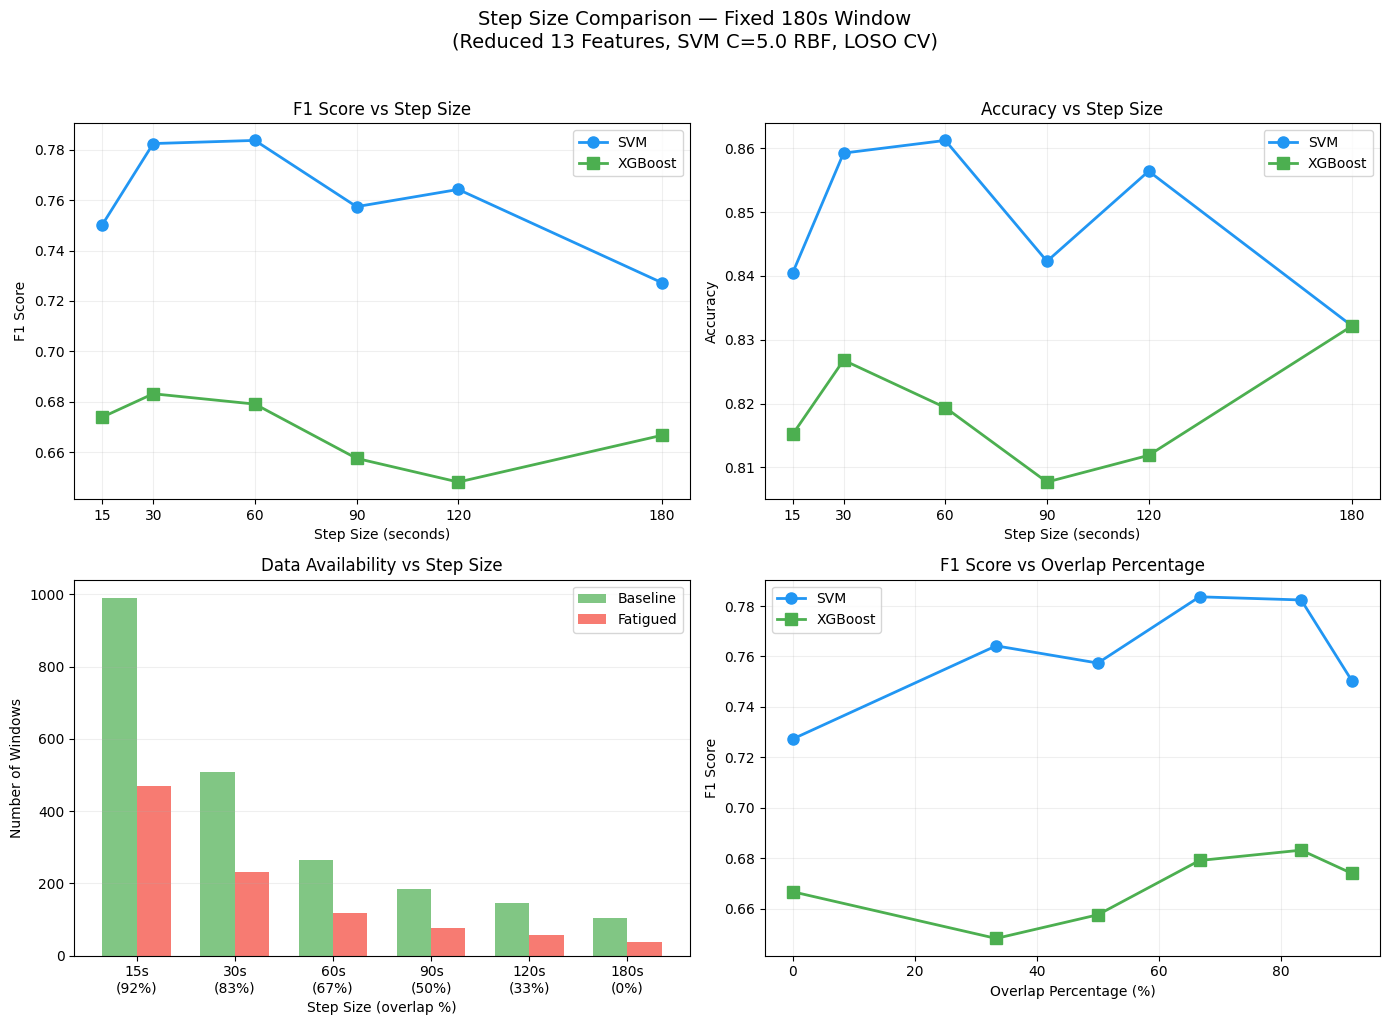


  Best step size: 60s (overlap: 67%)
  SVM F1=0.7837, Acc=0.8613

  Per-participant (best step = 60s):
   PID |       F1 |      Acc |  Samples
  ----------------------------------------
  P01  |    0.733 |    0.805 |       41
  P02  |    0.800 |    0.850 |       20
  P03  |    1.000 |    1.000 |       32
  P04  |    0.917 |    0.943 |       35
  P05  |    0.842 |    0.900 |       30
  P06  |    0.917 |    0.939 |       33
  P07  |    0.462 |    0.788 |       33
  P08  |    0.500 |    0.917 |       24
  P09  |    0.706 |    0.744 |       39
  P10  |    0.833 |    0.929 |       28
  P11  |    0.870 |    0.914 |       35
  P12  |    0.593 |    0.656 |       32

Done!


In [1]:
"""
STEP SIZE COMPARISON

Test different step sizes with fixed 180s window:
  15s step  → 90% overlap, many windows (most redundant)
  30s step  → 83% overlap
  60s step  → 66% overlap (our current choice)
  90s step  → 50% overlap
  120s step → 33% overlap
  180s step → 0% overlap (no overlap, independent windows)

All tested with SVM (reduced 13 features, LOSO CV)
"""

from pathlib import Path
import pandas as pd
import numpy as np
from scipy.signal import welch
from scipy.interpolate import interp1d
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

# ============================================================
# CONFIG
# ============================================================
DATA_ROOT = Path("fatigueset")
N_PARTICIPANTS = 12
SESSIONS = [1, 2, 3]
WINDOW_SEC = 180  # Fixed window size

STEP_SIZES = [15, 30, 60, 90, 120, 180]  # Different step sizes to test

REDUCED_FEATURES = [
    "temp_change_from_baseline", "temp_range", "temp_std",
    "temp_slope", "temp_min",
    "sdhr", "cv_rr", "triangular_index", "max_hr",
    "vlf_power", "mean_rr", "min_hr", "pnn50",
]

MAX_RR_MS = 2000
MIN_RR_MS = 300
MAX_RR_DIFF_MS = 300
MIN_RR_IN_WINDOW = 100

def load_markers(pid, sid):
    f = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "exp_markers.csv"
    if not f.exists():
        return {}
    df = pd.read_csv(f)
    events = {}
    for _, row in df.iterrows():
        if pd.notna(row["utcTime"]):
            events[row["eventMarker"]] = pd.to_datetime(row["utcTime"], unit="ms", utc=True)
    return events


def load_rr_intervals(pid, sid):
    rr_file = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}" / "chest_rr_interval.csv"
    if not rr_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(rr_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df = df.rename(columns={"duration": "rr_ms"})
    df = df.dropna(subset=["rr_ms"]).sort_values("timestamp").reset_index(drop=True)
    return df


def load_skin_temp(pid, sid):
    session_dir = DATA_ROOT / f"{pid:02d}" / f"{sid:02d}"
    temp_file = session_dir / "wrist_skin_temperature.csv"
    if pid == 2 and sid == 1:
        temp_file = session_dir / "wrist_skin_temperature2.csv"
    if not temp_file.exists():
        return pd.DataFrame()
    df = pd.read_csv(temp_file)
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    if "temperature" in df.columns:
        df = df.rename(columns={"temperature": "skin_temp"})
    elif "temp" in df.columns:
        df = df.rename(columns={"temp": "skin_temp"})
    df = (df.set_index("timestamp").sort_index().resample("1s")
            .mean(numeric_only=True).dropna(subset=["skin_temp"]).reset_index())
    return df


def clean_rr(rr):
    mask = (rr >= MIN_RR_MS) & (rr <= MAX_RR_MS)
    rr = rr[mask]
    if len(rr) < 3:
        return rr
    diffs = np.abs(np.diff(rr))
    keep = np.ones(len(rr), dtype=bool)
    for i in range(len(diffs)):
        if diffs[i] > MAX_RR_DIFF_MS:
            keep[i + 1] = False
    return rr[keep]

def compute_hrv_features(rr_raw):
    rr = clean_rr(rr_raw)
    nan_result = {f: np.nan for f in [
        "mean_rr", "sdnn", "rmssd", "pnn50", "mean_hr", "min_hr", "max_hr",
        "sdhr", "range_rr", "cv_rr", "triangular_index",
        "vlf_power", "lf_power", "hf_power", "total_power",
        "lf_hf_ratio", "lf_norm", "hf_norm",
        "ln_vlf", "ln_lf", "ln_hf", "ln_total_power"
    ]}
    if len(rr) < MIN_RR_IN_WINDOW:
        return nan_result

    diffs = np.diff(rr)
    mean_rr = np.mean(rr)
    sdnn = np.std(rr, ddof=1)
    rmssd = np.sqrt(np.mean(diffs ** 2))
    pnn50 = (np.sum(np.abs(diffs) > 50) / len(diffs)) * 100.0
    hr = 60000.0 / rr
    mean_hr, min_hr, max_hr = np.mean(hr), np.min(hr), np.max(hr)
    sdhr = np.std(hr, ddof=1)
    range_rr = np.max(rr) - np.min(rr)
    cv_rr = sdnn / mean_rr if mean_rr > 0 else np.nan
    bin_width = 1000.0 / 128.0
    if range_rr > 0:
        n_bins = max(int(range_rr / bin_width), 1)
        hc, _ = np.histogram(rr, bins=n_bins)
        triangular_index = len(rr) / np.max(hc) if np.max(hc) > 0 else np.nan
    else:
        triangular_index = np.nan

    def safe_ln(x):
        return np.log(x) if (x is not None and x > 0) else np.nan

    vlf, lf, hf = np.nan, np.nan, np.nan
    if len(rr) >= 30:
        t_s = np.cumsum(rr) / 1000.0
        t_s = t_s - t_s[0]
        fs = 4.0
        t_u = np.arange(t_s[0], t_s[-1], 1.0 / fs)
        if len(t_u) >= 64:
            try:
                fn = interp1d(t_s, rr, kind="cubic", fill_value="extrapolate")
                rr_u = fn(t_u) - np.mean(fn(t_u))
                nperseg = min(len(rr_u), 256)
                freqs, psd = welch(rr_u, fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
                vlf = float(np.trapz(psd[(freqs >= 0.003) & (freqs < 0.04)],
                                     freqs[(freqs >= 0.003) & (freqs < 0.04)])) if ((freqs >= 0.003) & (freqs < 0.04)).any() else np.nan
                lf = float(np.trapz(psd[(freqs >= 0.04) & (freqs < 0.15)],
                                    freqs[(freqs >= 0.04) & (freqs < 0.15)])) if ((freqs >= 0.04) & (freqs < 0.15)).any() else np.nan
                hf = float(np.trapz(psd[(freqs >= 0.15) & (freqs < 0.40)],
                                    freqs[(freqs >= 0.15) & (freqs < 0.40)])) if ((freqs >= 0.15) & (freqs < 0.40)).any() else np.nan
            except:
                pass

    total = (vlf or 0) + (lf or 0) + (hf or 0) if not (np.isnan(vlf) and np.isnan(lf) and np.isnan(hf)) else np.nan
    lf_hf = lf / hf if (hf and hf > 0) else np.nan
    lf_norm = (lf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan
    hf_norm = (hf / (lf + hf)) * 100 if (lf and hf and (lf + hf) > 0) else np.nan

    return {
        "mean_rr": mean_rr, "sdnn": sdnn, "rmssd": rmssd, "pnn50": pnn50,
        "mean_hr": mean_hr, "min_hr": min_hr, "max_hr": max_hr, "sdhr": sdhr,
        "range_rr": range_rr, "cv_rr": cv_rr, "triangular_index": triangular_index,
        "vlf_power": vlf, "lf_power": lf, "hf_power": hf, "total_power": total,
        "lf_hf_ratio": lf_hf, "lf_norm": lf_norm, "hf_norm": hf_norm,
        "ln_vlf": safe_ln(vlf), "ln_lf": safe_ln(lf), "ln_hf": safe_ln(hf),
        "ln_total_power": safe_ln(total),
    }


def compute_temp_features(temp_vals):
    temp = temp_vals[np.isfinite(temp_vals)]
    if len(temp) < 10:
        return {"temp_mean": np.nan, "temp_slope": np.nan, "temp_std": np.nan,
                "temp_range": np.nan, "temp_min": np.nan}
    try:
        coeffs = np.polyfit(np.arange(len(temp)), temp, 1)
        slope = coeffs[0]
    except:
        slope = np.nan
    return {
        "temp_mean": np.mean(temp), "temp_slope": slope,
        "temp_std": np.std(temp, ddof=1), "temp_range": np.max(temp) - np.min(temp),
        "temp_min": np.min(temp),
    }


def build_dataset(step_sec):
    all_rows = []

    for pid in range(1, N_PARTICIPANTS + 1):
        for sid in SESSIONS:
            df_rr = load_rr_intervals(pid, sid)
            df_temp = load_skin_temp(pid, sid)
            markers = load_markers(pid, sid)

            if df_rr.empty or not markers:
                continue

            baseline_start = markers.get("start_baseline")
            exercise_start = markers.get("start_activity")
            cognitive_start = markers.get("start_fatigue")

            t_start = df_rr["timestamp"].iloc[0]
            t_end = df_rr["timestamp"].iloc[-1]
            win_id = 0
            w_start = t_start

            while w_start + pd.Timedelta(seconds=WINDOW_SEC) <= t_end:
                w_end = w_start + pd.Timedelta(seconds=WINDOW_SEC)

                # HRV
                rr_mask = (df_rr["timestamp"] >= w_start) & (df_rr["timestamp"] < w_end)
                rr_vals = df_rr.loc[rr_mask, "rr_ms"].to_numpy(dtype=float)
                hrv_feats = compute_hrv_features(rr_vals)

                # Temp
                if not df_temp.empty:
                    temp_mask = (df_temp["timestamp"] >= w_start) & (df_temp["timestamp"] < w_end)
                    temp_vals = df_temp.loc[temp_mask, "skin_temp"].to_numpy(dtype=float)
                    temp_feats = compute_temp_features(temp_vals)
                else:
                    temp_feats = {"temp_mean": np.nan, "temp_slope": np.nan,
                                  "temp_std": np.nan, "temp_range": np.nan, "temp_min": np.nan}

                # Label
                if cognitive_start and w_start >= cognitive_start:
                    label = 1
                elif baseline_start and exercise_start and w_start >= baseline_start and w_start < exercise_start:
                    label = 0
                else:
                    label = -1

                row = {**hrv_feats, **temp_feats,
                       "participant": pid, "session": sid, "window_id": win_id,
                       "window_start": w_start, "label": label}
                all_rows.append(row)
                win_id += 1
                w_start += pd.Timedelta(seconds=step_sec)

    df = pd.DataFrame(all_rows)
    if not df.empty:
        df["temp_change_from_baseline"] = df.groupby(["participant", "session"])["temp_mean"].transform(
            lambda s: s - s.iloc[0]
        )
    return df

def loso_cv(model_class, model_params, X, y, participants, scale=False):
    unique_pids = sorted(set(participants))
    all_preds, all_true = [], []
    per_participant = {}

    for test_pid in unique_pids:
        train_mask = participants != test_pid
        test_mask = participants == test_pid
        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]
        if len(X_test) == 0 or len(np.unique(y_train)) < 2:
            continue

        if scale:
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        model = model_class(**model_params)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        all_preds.extend(y_pred)
        all_true.extend(y_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        per_participant[test_pid] = {"accuracy": acc, "f1": f1, "n_samples": len(y_test)}

    all_preds = np.array(all_preds)
    all_true = np.array(all_true)

    return {
        "accuracy": accuracy_score(all_true, all_preds),
        "f1": f1_score(all_true, all_preds, zero_division=0),
        "precision": precision_score(all_true, all_preds, zero_division=0),
        "recall": recall_score(all_true, all_preds, zero_division=0),
        "per_participant": per_participant,
    }


def run_step_size_experiment():
    print("=" * 70)
    print(f"STEP SIZE COMPARISON (Fixed {WINDOW_SEC}s window)")
    print("=" * 70)

    all_results = {}

    for step_sec in STEP_SIZES:
        overlap_sec = WINDOW_SEC - step_sec
        overlap_pct = (overlap_sec / WINDOW_SEC) * 100

        print(f"\n  --- Step: {step_sec}s (overlap: {overlap_sec}s = {overlap_pct:.0f}%) ---")
        print(f"  Extracting features...")

        df = build_dataset(step_sec)
        df_train = df[df["label"] >= 0].dropna(subset=REDUCED_FEATURES)

        n_base = (df_train["label"] == 0).sum()
        n_fat = (df_train["label"] == 1).sum()
        n_total = len(df_train)

        print(f"  Windows: {n_total} (baseline={n_base}, fatigued={n_fat})")

        if n_fat < 10 or n_base < 10:
            print(f"  [SKIP] Too few windows")
            continue

        X = df_train[REDUCED_FEATURES].values
        y = df_train["label"].values
        participants = df_train["participant"].values

        # SVM
        res_svm = loso_cv(SVC, {"kernel": "rbf", "C": 5.0, "gamma": "scale",
                                 "class_weight": "balanced", "random_state": 42},
                          X, y, participants, scale=True)

        # XGBoost
        if HAS_XGBOOST:
            res_xgb = loso_cv(XGBClassifier, {"n_estimators": 100, "max_depth": 4,
                               "learning_rate": 0.1, "random_state": 42,
                               "eval_metric": "logloss", "use_label_encoder": False,
                               "scale_pos_weight": 2.0}, X, y, participants)
        else:
            res_xgb = {"f1": 0, "accuracy": 0, "precision": 0, "recall": 0}

        all_results[step_sec] = {
            "SVM": res_svm,
            "XGBoost": res_xgb if HAS_XGBOOST else None,
            "n_total": n_total,
            "n_baseline": n_base,
            "n_fatigued": n_fat,
            "overlap_pct": overlap_pct,
        }

        print(f"  SVM:     F1={res_svm['f1']:.4f}, Acc={res_svm['accuracy']:.4f}, "
              f"Prec={res_svm['precision']:.4f}, Rec={res_svm['recall']:.4f}")
        if HAS_XGBOOST:
            print(f"  XGBoost: F1={res_xgb['f1']:.4f}, Acc={res_xgb['accuracy']:.4f}")


    print(f"\n{'='*70}")
    print("STEP SIZE COMPARISON — SUMMARY")
    print(f"{'='*70}")

    print(f"\n  {'Step':>6} | {'Overlap':>8} | {'Windows':>8} | {'Base':>6} | {'Fat':>6} | "
          f"{'SVM F1':>8} | {'SVM Acc':>8} | {'XGB F1':>8}")
    print(f"  {'-'*80}")

    for step in sorted(all_results.keys()):
        r = all_results[step]
        svm_f1 = r["SVM"]["f1"]
        svm_acc = r["SVM"]["accuracy"]
        xgb_f1 = r["XGBoost"]["f1"] if r["XGBoost"] else 0
        print(f"  {step:>4}s | {r['overlap_pct']:>6.0f}% | {r['n_total']:>8} | "
              f"{r['n_baseline']:>6} | {r['n_fatigued']:>6} | "
              f"{svm_f1:>8.4f} | {svm_acc:>8.4f} | {xgb_f1:>8.4f}")


    valid_steps = sorted(all_results.keys())

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Plot 1: F1 vs Step Size
    ax = axes[0][0]
    svm_f1s = [all_results[s]["SVM"]["f1"] for s in valid_steps]
    ax.plot(valid_steps, svm_f1s, "o-", linewidth=2, markersize=8, label="SVM", color="#2196F3")
    if HAS_XGBOOST:
        xgb_f1s = [all_results[s]["XGBoost"]["f1"] for s in valid_steps]
        ax.plot(valid_steps, xgb_f1s, "s-", linewidth=2, markersize=8, label="XGBoost", color="#4CAF50")
    ax.set_xlabel("Step Size (seconds)")
    ax.set_ylabel("F1 Score")
    ax.set_title("F1 Score vs Step Size")
    ax.legend()
    ax.grid(True, alpha=0.2)
    ax.set_xticks(valid_steps)

    # Plot 2: Accuracy vs Step Size
    ax = axes[0][1]
    svm_accs = [all_results[s]["SVM"]["accuracy"] for s in valid_steps]
    ax.plot(valid_steps, svm_accs, "o-", linewidth=2, markersize=8, label="SVM", color="#2196F3")
    if HAS_XGBOOST:
        xgb_accs = [all_results[s]["XGBoost"]["accuracy"] for s in valid_steps]
        ax.plot(valid_steps, xgb_accs, "s-", linewidth=2, markersize=8, label="XGBoost", color="#4CAF50")
    ax.set_xlabel("Step Size (seconds)")
    ax.set_ylabel("Accuracy")
    ax.set_title("Accuracy vs Step Size")
    ax.legend()
    ax.grid(True, alpha=0.2)
    ax.set_xticks(valid_steps)

    # Plot 3: Number of windows vs Step Size
    ax = axes[1][0]
    n_bases = [all_results[s]["n_baseline"] for s in valid_steps]
    n_fats = [all_results[s]["n_fatigued"] for s in valid_steps]
    x = np.arange(len(valid_steps))
    width = 0.35
    ax.bar(x - width/2, n_bases, width, label="Baseline", color="#4CAF50", alpha=0.7)
    ax.bar(x + width/2, n_fats, width, label="Fatigued", color="#F44336", alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{s}s\n({all_results[s]['overlap_pct']:.0f}%)" for s in valid_steps])
    ax.set_xlabel("Step Size (overlap %)")
    ax.set_ylabel("Number of Windows")
    ax.set_title("Data Availability vs Step Size")
    ax.legend()
    ax.grid(True, alpha=0.2, axis="y")

    # Plot 4: F1 vs Overlap Percentage
    ax = axes[1][1]
    overlaps = [all_results[s]["overlap_pct"] for s in valid_steps]
    ax.plot(overlaps, svm_f1s, "o-", linewidth=2, markersize=8, label="SVM", color="#2196F3")
    if HAS_XGBOOST:
        ax.plot(overlaps, xgb_f1s, "s-", linewidth=2, markersize=8, label="XGBoost", color="#4CAF50")
    ax.set_xlabel("Overlap Percentage (%)")
    ax.set_ylabel("F1 Score")
    ax.set_title("F1 Score vs Overlap Percentage")
    ax.legend()
    ax.grid(True, alpha=0.2)

    fig.suptitle(f"Step Size Comparison — Fixed {WINDOW_SEC}s Window\n"
                 f"(Reduced 13 Features, SVM C=5.0 RBF, LOSO CV)",
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    best_step = max(all_results.keys(), key=lambda s: all_results[s]["SVM"]["f1"])
    best_res = all_results[best_step]["SVM"]

    print(f"\n  Best step size: {best_step}s (overlap: {all_results[best_step]['overlap_pct']:.0f}%)")
    print(f"  SVM F1={best_res['f1']:.4f}, Acc={best_res['accuracy']:.4f}")

    print(f"\n  Per-participant (best step = {best_step}s):")
    print(f"  {'PID':>4} | {'F1':>8} | {'Acc':>8} | {'Samples':>8}")
    print(f"  {'-'*40}")
    for pid in sorted(best_res["per_participant"].keys()):
        p = best_res["per_participant"][pid]
        print(f"  P{pid:02d}  | {p['f1']:>8.3f} | {p['accuracy']:>8.3f} | {p['n_samples']:>8}")

    return all_results


if __name__ == "__main__":
    results = run_step_size_experiment()
    print("\nDone!")